<center><h1>1-cd: Convolutional Neural Networks (ConvNets)</h1></center>

<center><h2><a href="https://rdfia.github.io/">Course link</a></h2></center>

# Warning :
# Do "File -> Save a copy in Drive" before you start modifying the notebook, otherwise your modifications will not be saved.


In [21]:
#!git clone https://github.com/cdancette/deep-learning-polytech-tp6-7.git
! wget https://github.com/rdfia/rdfia.github.io/raw/master/code/2-cd/utils.py

--2025-10-27 14:31:56--  https://github.com/rdfia/rdfia.github.io/raw/master/code/2-cd/utils.py
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/code/2-cd/utils.py [following]
--2025-10-27 14:31:57--  https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/code/2-cd/utils.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2627 (2.6K) [text/plain]
Saving to: ‘utils.py.1’

utils.py.1          100%[===================>]   2.57K  --.-KB/s    in 0s      

2025-10-27 14:31:57 (37.6 MB/s) - ‘utils.py.1’ saved [2627/2627]



In [22]:
%run 'utils.py'

<Figure size 640x480 with 0 Axes>

In [29]:
import argparse
import os
import time

import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim
import torch.utils.data
import torchvision.transforms as transforms
import torchvision.datasets as datasets

from utils import *

PRINT_INTERVAL = 200
PATH="datasets"

In [17]:
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        # We first define the convolution and pooling layers as a features extractor
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),  #output:64*4*4
        )
        # We then define fully connected layers as a classifier
        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000),
            nn.ReLU(),
            nn.Linear(1000, 10)
            # Reminder: The softmax is included in the loss, do not put it here
        )

    # Method called when we apply the network to an input batch
    def forward(self, input):
        bsize = input.size(0) # batch size
        output = self.features(input) # output of the conv layers
        output = output.view(bsize, -1) # we flatten the 2D feature maps into one 1D vector for each input
        output = self.classifier(output) # we compute the output of the fc layers
        return output



def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """
    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,
        transform=transforms.Compose([
            transforms.ToTensor()
        ]))
    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,
        transform=transforms.Compose([
            transforms.ToTensor()
        ]))

    train_loader = torch.utils.data.DataLoader(train_dataset,
                        batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,
                        batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader



def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=15, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)


=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.122s (0.122s)	Loss 2.3028 (2.3028)	Prec@1  11.7 ( 11.7)	Prec@5  48.4 ( 48.4)


<Figure size 640x480 with 0 Axes>

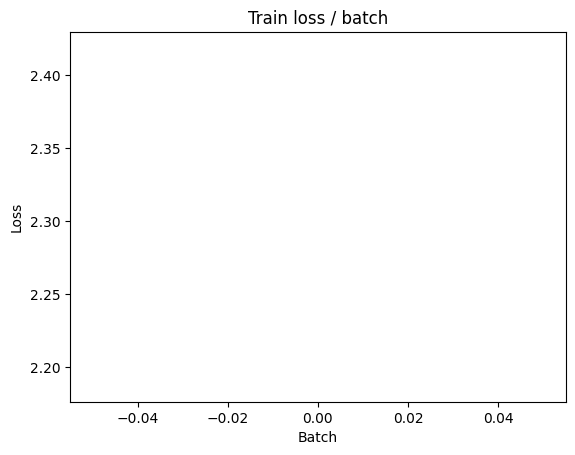

[TRAIN Batch 200/391]	Time 0.010s (0.020s)	Loss 2.1620 (2.2099)	Prec@1  30.5 ( 18.2)	Prec@5  73.4 ( 64.8)


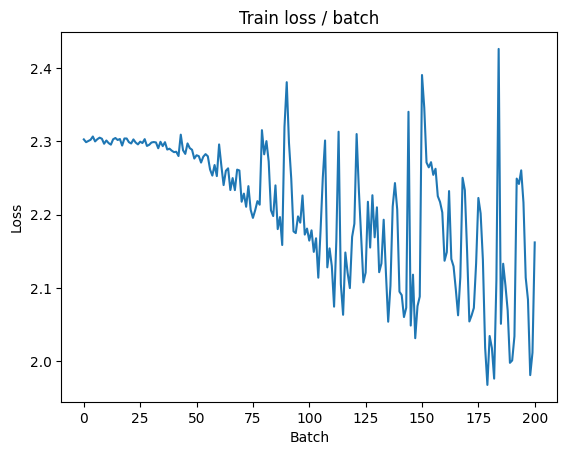


===============> Total time 8s	Avg loss 2.0736	Avg Prec@1 24.16 %	Avg Prec@5 72.62 %

[EVAL Batch 000/079]	Time 0.103s (0.103s)	Loss 1.9161 (1.9161)	Prec@1  36.7 ( 36.7)	Prec@5  78.9 ( 78.9)

===============> Total time 1s	Avg loss 1.8908	Avg Prec@1 32.56 %	Avg Prec@5 78.92 %



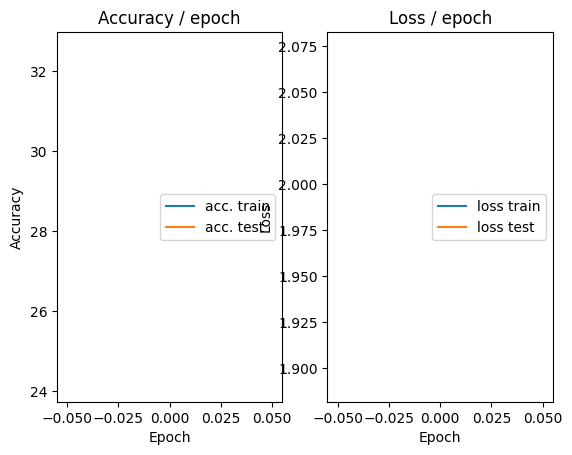

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.117s (0.117s)	Loss 1.9024 (1.9024)	Prec@1  36.7 ( 36.7)	Prec@5  80.5 ( 80.5)


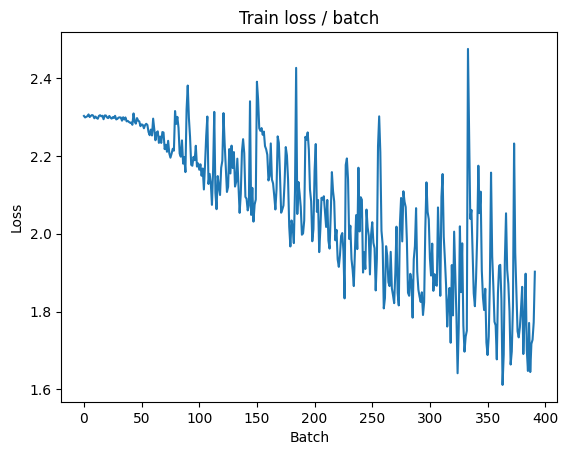

[TRAIN Batch 200/391]	Time 0.007s (0.019s)	Loss 1.5983 (1.7041)	Prec@1  39.1 ( 38.1)	Prec@5  89.1 ( 87.6)


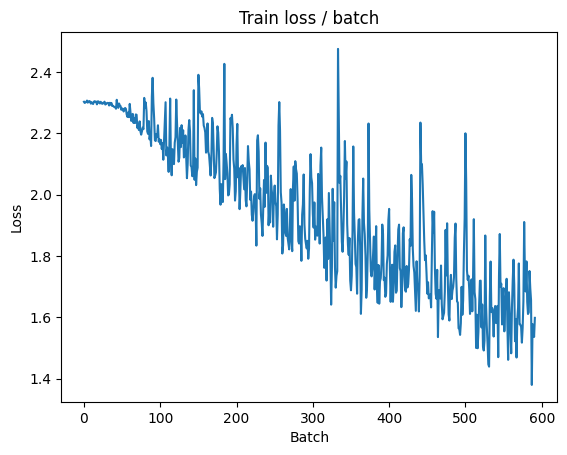


===============> Total time 7s	Avg loss 1.6320	Avg Prec@1 40.81 %	Avg Prec@5 89.13 %

[EVAL Batch 000/079]	Time 0.118s (0.118s)	Loss 1.3533 (1.3533)	Prec@1  56.2 ( 56.2)	Prec@5  93.8 ( 93.8)

===============> Total time 2s	Avg loss 1.4244	Avg Prec@1 49.03 %	Avg Prec@5 92.47 %



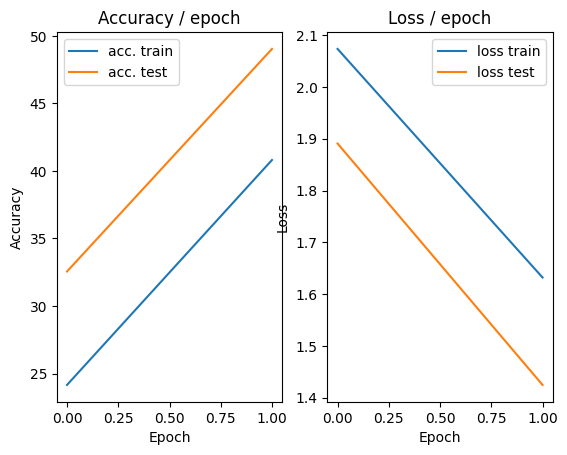

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.125s (0.125s)	Loss 1.3789 (1.3789)	Prec@1  50.8 ( 50.8)	Prec@5  95.3 ( 95.3)


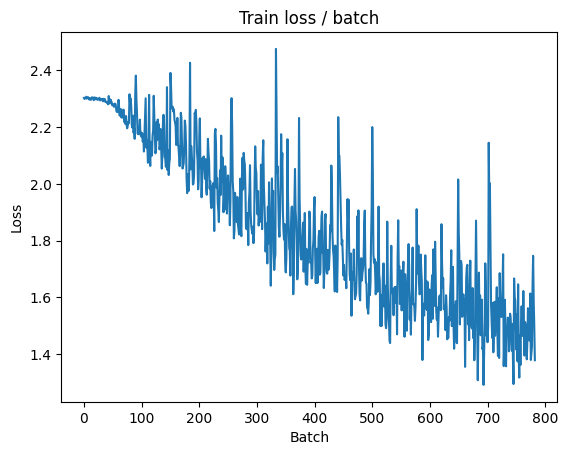

[TRAIN Batch 200/391]	Time 0.017s (0.019s)	Loss 1.4466 (1.4286)	Prec@1  50.0 ( 48.8)	Prec@5  93.8 ( 92.6)


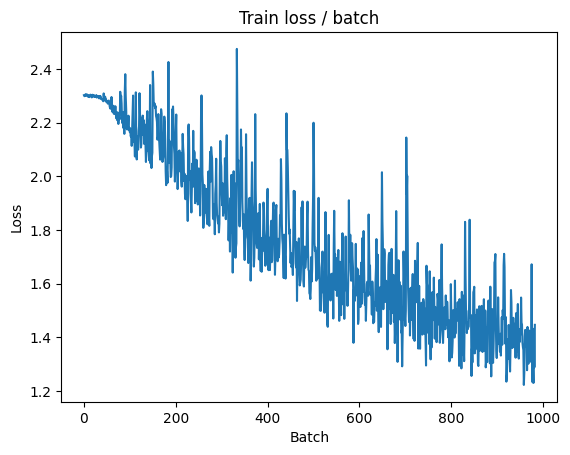


===============> Total time 7s	Avg loss 1.3879	Avg Prec@1 50.38 %	Avg Prec@5 93.06 %

[EVAL Batch 000/079]	Time 0.101s (0.101s)	Loss 1.2541 (1.2541)	Prec@1  60.9 ( 60.9)	Prec@5  95.3 ( 95.3)

===============> Total time 1s	Avg loss 1.3892	Avg Prec@1 50.19 %	Avg Prec@5 92.74 %



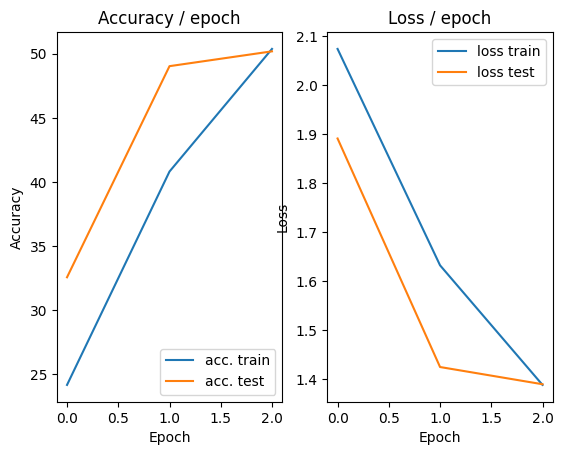

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.121s (0.121s)	Loss 1.2611 (1.2611)	Prec@1  54.7 ( 54.7)	Prec@5  96.1 ( 96.1)


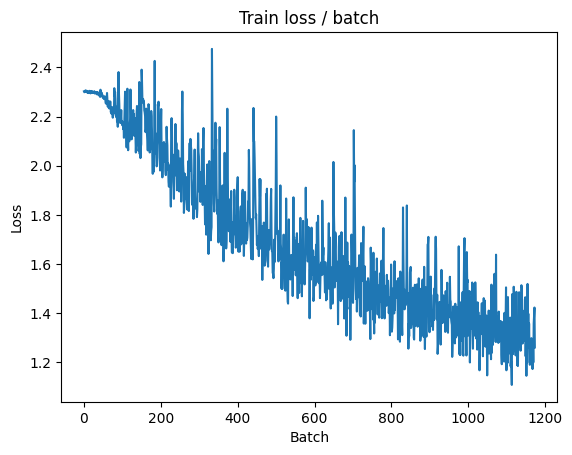

[TRAIN Batch 200/391]	Time 0.020s (0.024s)	Loss 1.2955 (1.2547)	Prec@1  53.1 ( 55.4)	Prec@5  95.3 ( 94.5)


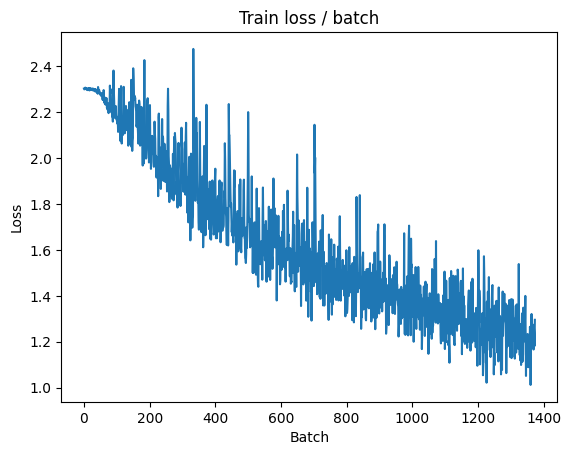


===============> Total time 8s	Avg loss 1.2293	Avg Prec@1 56.19 %	Avg Prec@5 94.84 %

[EVAL Batch 000/079]	Time 0.096s (0.096s)	Loss 1.0263 (1.0263)	Prec@1  64.1 ( 64.1)	Prec@5  96.9 ( 96.9)

===============> Total time 1s	Avg loss 1.2281	Avg Prec@1 55.27 %	Avg Prec@5 95.09 %



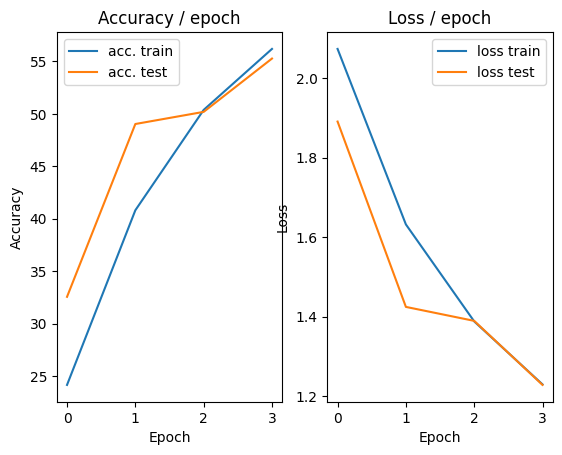

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.128s (0.128s)	Loss 1.1705 (1.1705)	Prec@1  60.2 ( 60.2)	Prec@5  92.2 ( 92.2)


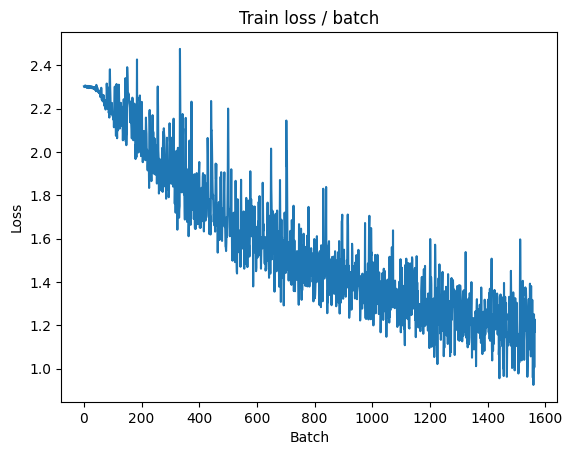

[TRAIN Batch 200/391]	Time 0.013s (0.020s)	Loss 1.0282 (1.1172)	Prec@1  60.9 ( 60.4)	Prec@5  97.7 ( 95.7)


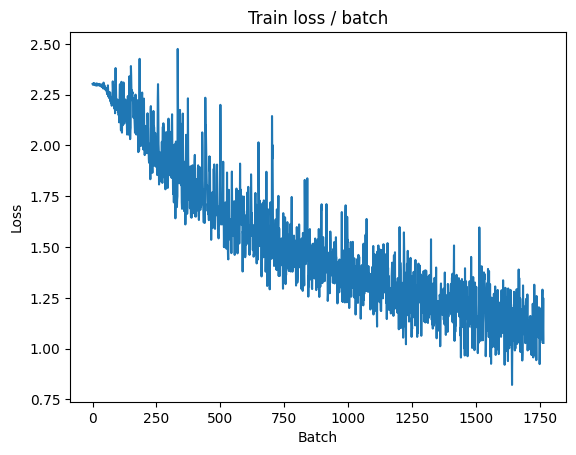


===============> Total time 8s	Avg loss 1.0932	Avg Prec@1 61.19 %	Avg Prec@5 96.10 %

[EVAL Batch 000/079]	Time 0.095s (0.095s)	Loss 1.0449 (1.0449)	Prec@1  66.4 ( 66.4)	Prec@5  97.7 ( 97.7)

===============> Total time 1s	Avg loss 1.1043	Avg Prec@1 60.58 %	Avg Prec@5 96.21 %



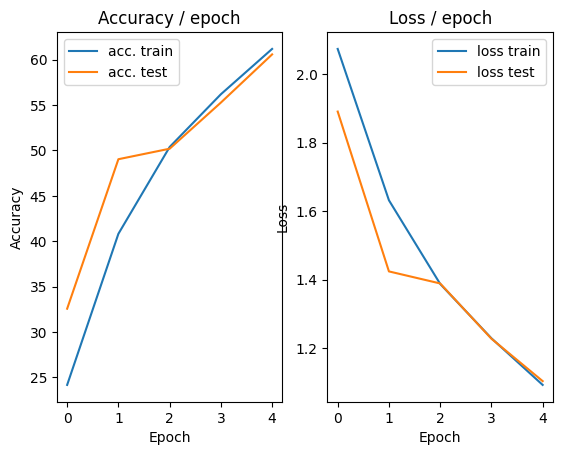

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.133s (0.133s)	Loss 0.9882 (0.9882)	Prec@1  70.3 ( 70.3)	Prec@5  97.7 ( 97.7)


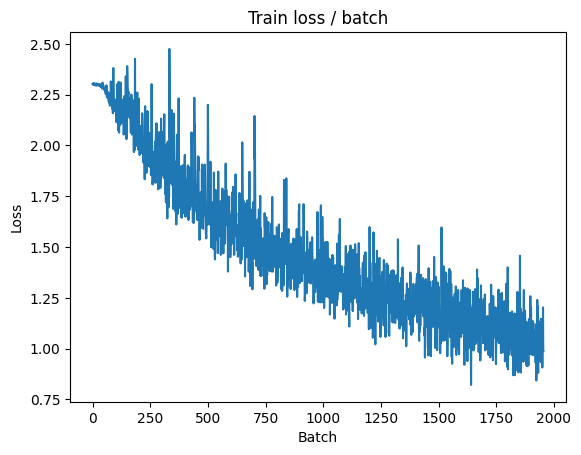

[TRAIN Batch 200/391]	Time 0.009s (0.023s)	Loss 1.0007 (0.9928)	Prec@1  64.1 ( 64.8)	Prec@5  94.5 ( 96.9)


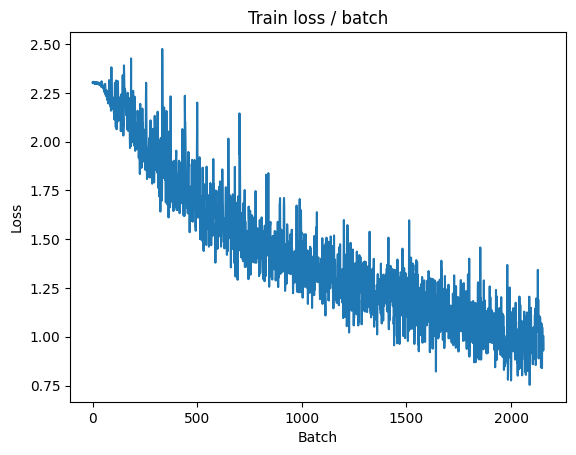


===============> Total time 9s	Avg loss 0.9790	Avg Prec@1 65.48 %	Avg Prec@5 96.88 %

[EVAL Batch 000/079]	Time 0.102s (0.102s)	Loss 1.0710 (1.0710)	Prec@1  61.7 ( 61.7)	Prec@5  98.4 ( 98.4)

===============> Total time 1s	Avg loss 1.0626	Avg Prec@1 62.23 %	Avg Prec@5 96.05 %



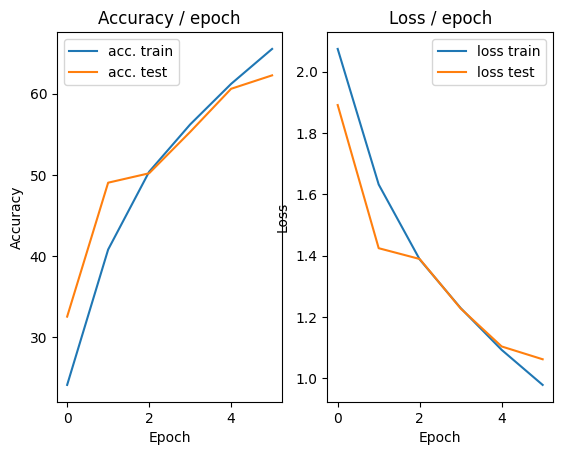

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.138s (0.138s)	Loss 0.8742 (0.8742)	Prec@1  71.1 ( 71.1)	Prec@5  97.7 ( 97.7)


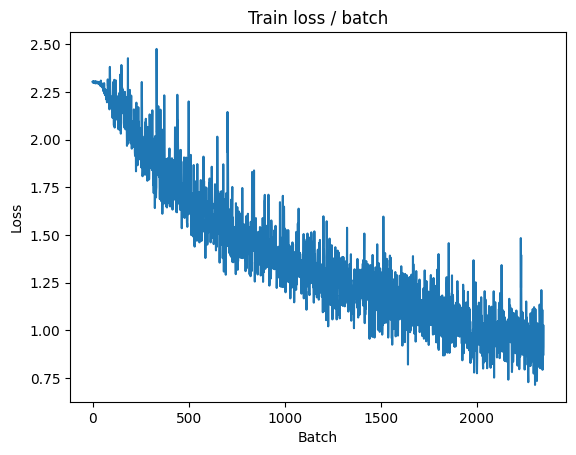

[TRAIN Batch 200/391]	Time 0.031s (0.019s)	Loss 0.7815 (0.8811)	Prec@1  70.3 ( 69.1)	Prec@5  98.4 ( 97.5)


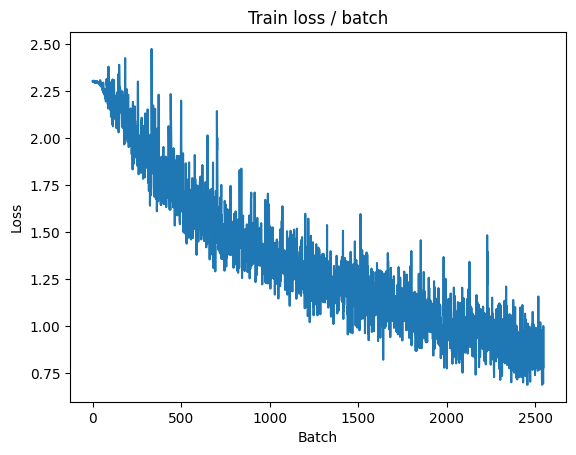


===============> Total time 7s	Avg loss 0.8706	Avg Prec@1 69.47 %	Avg Prec@5 97.61 %

[EVAL Batch 000/079]	Time 0.102s (0.102s)	Loss 0.9393 (0.9393)	Prec@1  69.5 ( 69.5)	Prec@5  96.9 ( 96.9)

===============> Total time 1s	Avg loss 1.0186	Avg Prec@1 64.39 %	Avg Prec@5 96.32 %



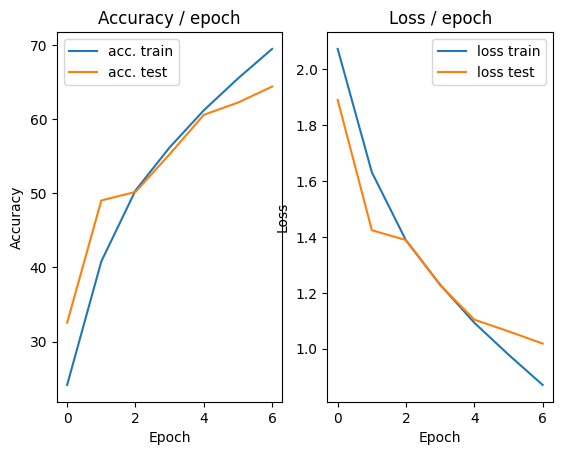

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.198s (0.198s)	Loss 0.7560 (0.7560)	Prec@1  74.2 ( 74.2)	Prec@5  98.4 ( 98.4)


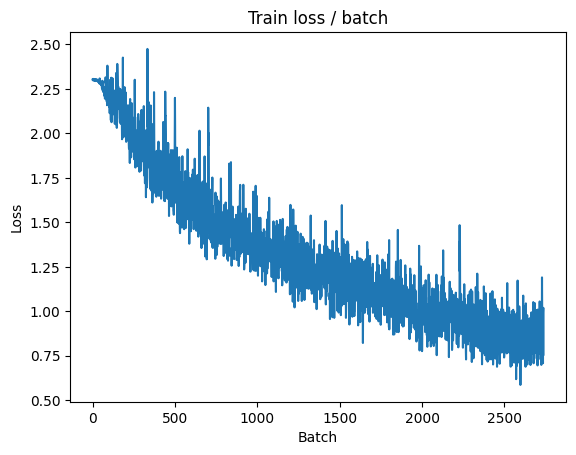

[TRAIN Batch 200/391]	Time 0.023s (0.021s)	Loss 0.7298 (0.7768)	Prec@1  74.2 ( 72.6)	Prec@5  97.7 ( 98.3)


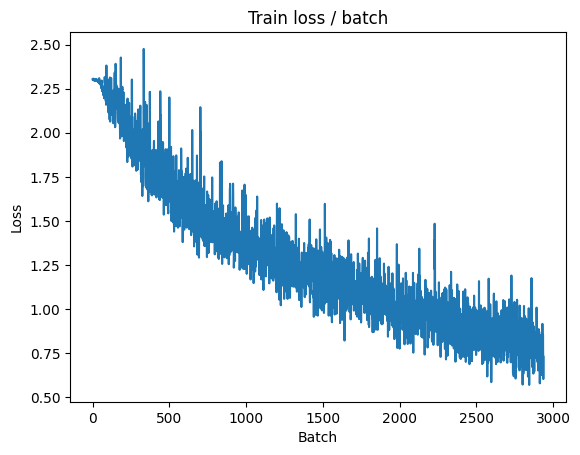


===============> Total time 7s	Avg loss 0.7700	Avg Prec@1 72.88 %	Avg Prec@5 98.23 %

[EVAL Batch 000/079]	Time 0.101s (0.101s)	Loss 0.9546 (0.9546)	Prec@1  66.4 ( 66.4)	Prec@5 100.0 (100.0)

===============> Total time 1s	Avg loss 0.9872	Avg Prec@1 65.44 %	Avg Prec@5 96.95 %



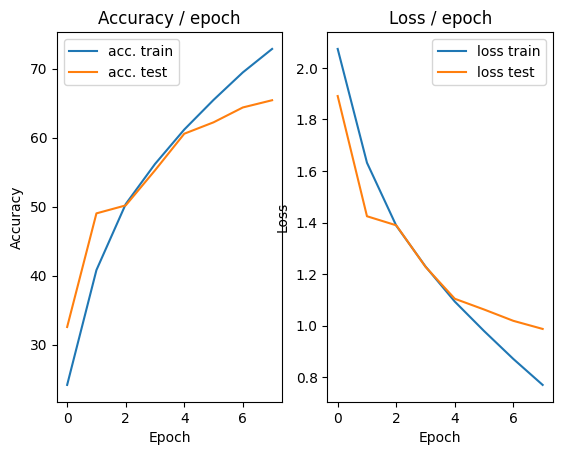

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.139s (0.139s)	Loss 0.6783 (0.6783)	Prec@1  78.1 ( 78.1)	Prec@5  99.2 ( 99.2)


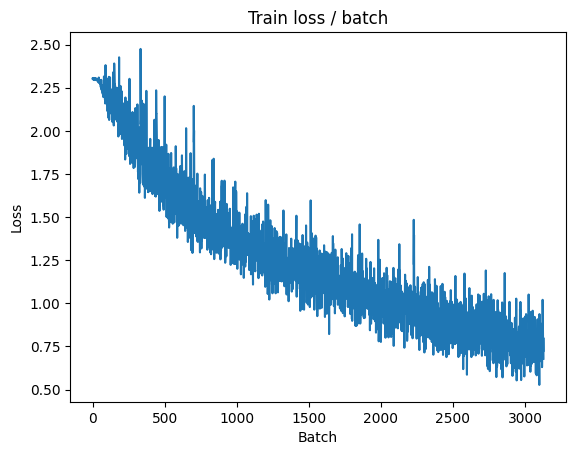

[TRAIN Batch 200/391]	Time 0.009s (0.024s)	Loss 0.6440 (0.6612)	Prec@1  78.9 ( 77.1)	Prec@5  98.4 ( 98.8)


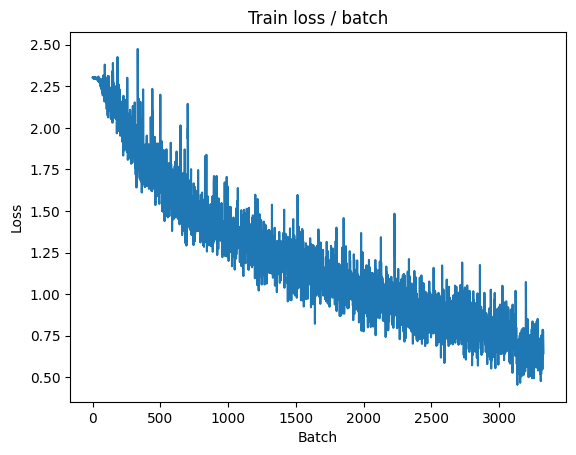


===============> Total time 8s	Avg loss 0.6719	Avg Prec@1 76.54 %	Avg Prec@5 98.70 %

[EVAL Batch 000/079]	Time 0.107s (0.107s)	Loss 1.0001 (1.0001)	Prec@1  67.2 ( 67.2)	Prec@5  98.4 ( 98.4)

===============> Total time 1s	Avg loss 1.0024	Avg Prec@1 66.43 %	Avg Prec@5 97.06 %



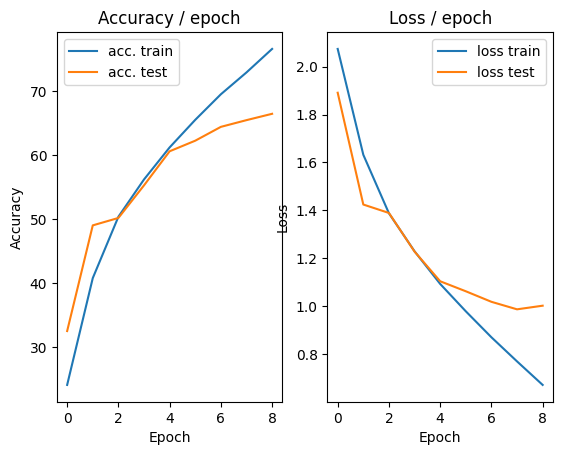

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.161s (0.161s)	Loss 0.5010 (0.5010)	Prec@1  79.7 ( 79.7)	Prec@5 100.0 (100.0)


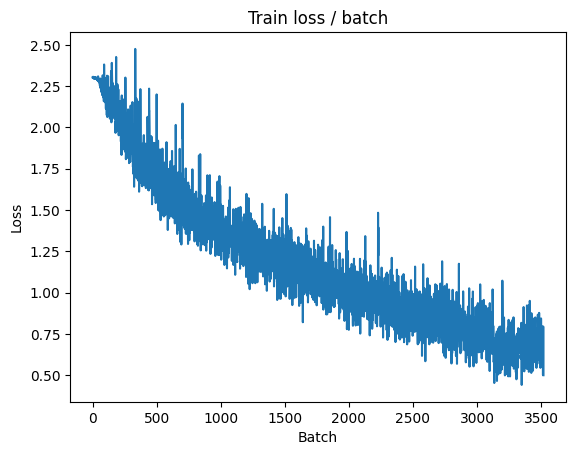

[TRAIN Batch 200/391]	Time 0.010s (0.020s)	Loss 0.5366 (0.5660)	Prec@1  76.6 ( 80.3)	Prec@5 100.0 ( 99.2)


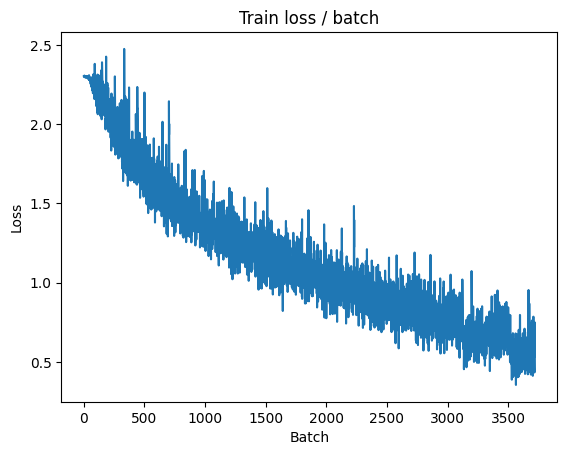


===============> Total time 8s	Avg loss 0.5778	Avg Prec@1 79.74 %	Avg Prec@5 99.14 %

[EVAL Batch 000/079]	Time 0.120s (0.120s)	Loss 1.3155 (1.3155)	Prec@1  60.2 ( 60.2)	Prec@5  94.5 ( 94.5)

===============> Total time 1s	Avg loss 1.1752	Avg Prec@1 62.51 %	Avg Prec@5 95.58 %



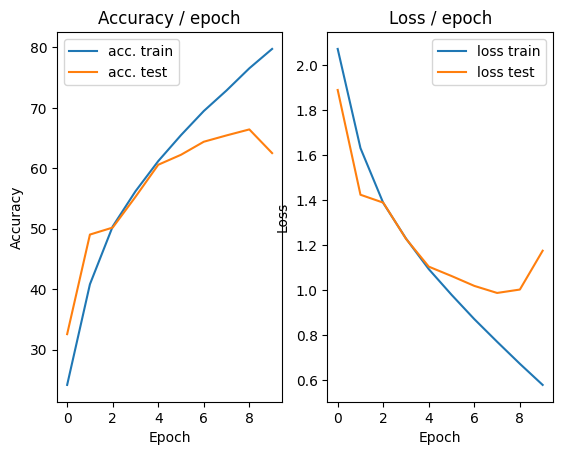

=== EPOCH 11 =====

[TRAIN Batch 000/391]	Time 0.133s (0.133s)	Loss 0.4887 (0.4887)	Prec@1  84.4 ( 84.4)	Prec@5  99.2 ( 99.2)


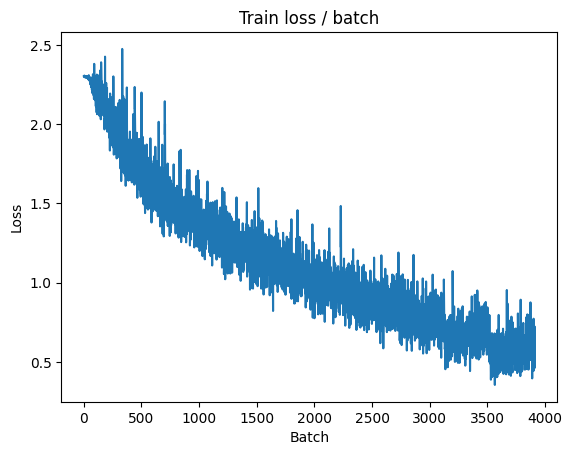

[TRAIN Batch 200/391]	Time 0.023s (0.019s)	Loss 0.5826 (0.4639)	Prec@1  78.9 ( 83.8)	Prec@5 100.0 ( 99.5)


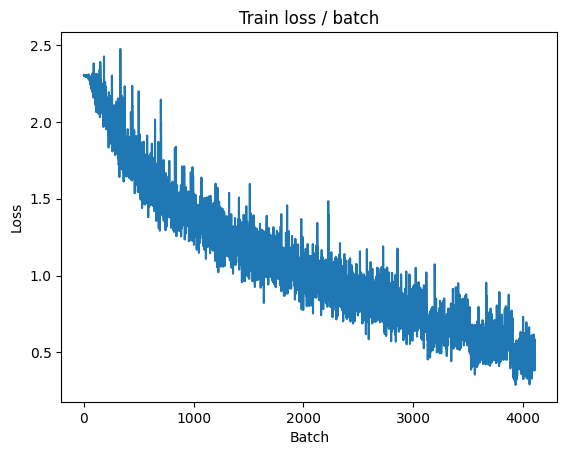


===============> Total time 8s	Avg loss 0.4793	Avg Prec@1 83.21 %	Avg Prec@5 99.51 %

[EVAL Batch 000/079]	Time 0.147s (0.147s)	Loss 0.9904 (0.9904)	Prec@1  66.4 ( 66.4)	Prec@5  98.4 ( 98.4)

===============> Total time 1s	Avg loss 1.1072	Avg Prec@1 66.38 %	Avg Prec@5 96.68 %



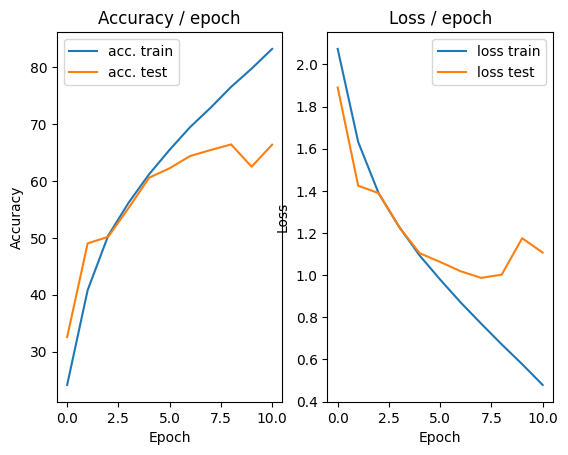

=== EPOCH 12 =====

[TRAIN Batch 000/391]	Time 0.135s (0.135s)	Loss 0.5011 (0.5011)	Prec@1  82.8 ( 82.8)	Prec@5 100.0 (100.0)


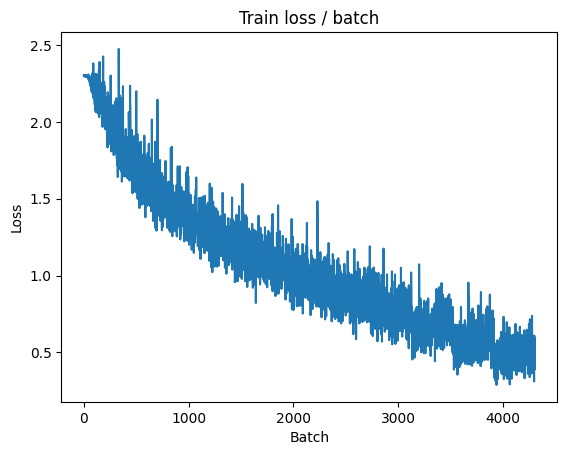

[TRAIN Batch 200/391]	Time 0.011s (0.020s)	Loss 0.3860 (0.3600)	Prec@1  87.5 ( 87.4)	Prec@5 100.0 ( 99.8)


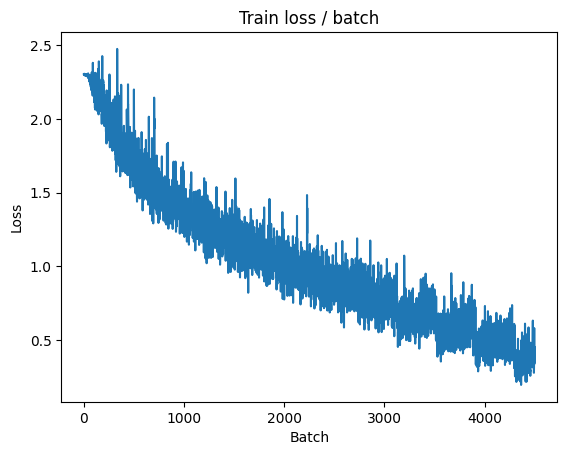


===============> Total time 7s	Avg loss 0.3861	Avg Prec@1 86.41 %	Avg Prec@5 99.72 %

[EVAL Batch 000/079]	Time 0.108s (0.108s)	Loss 1.0334 (1.0334)	Prec@1  71.9 ( 71.9)	Prec@5  96.1 ( 96.1)

===============> Total time 1s	Avg loss 1.1326	Avg Prec@1 66.92 %	Avg Prec@5 96.87 %



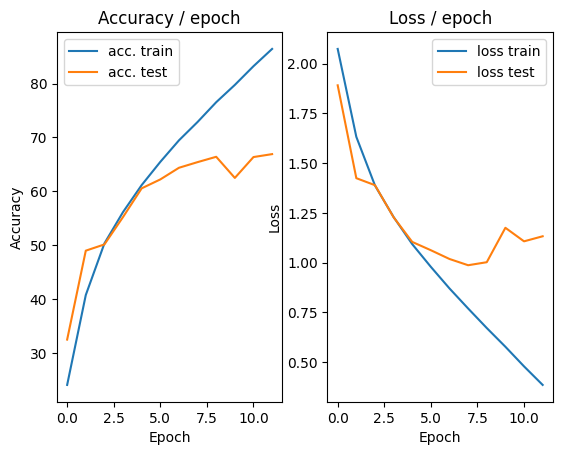

=== EPOCH 13 =====

[TRAIN Batch 000/391]	Time 0.208s (0.208s)	Loss 0.4098 (0.4098)	Prec@1  85.9 ( 85.9)	Prec@5 100.0 (100.0)


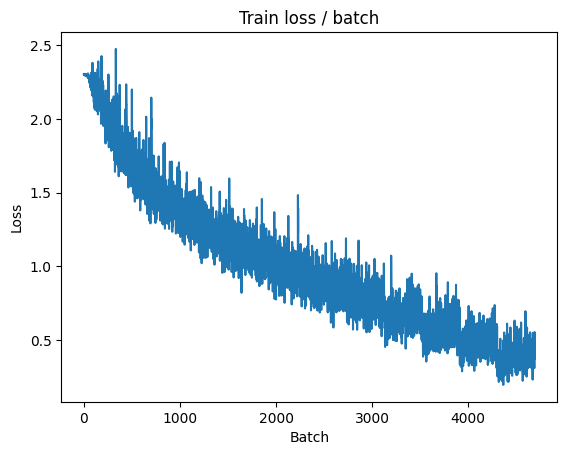

[TRAIN Batch 200/391]	Time 0.032s (0.023s)	Loss 0.3436 (0.2698)	Prec@1  88.3 ( 90.8)	Prec@5 100.0 ( 99.9)


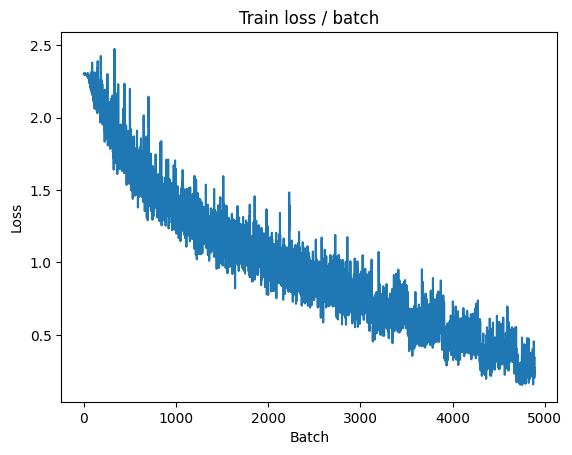


===============> Total time 8s	Avg loss 0.2903	Avg Prec@1 90.02 %	Avg Prec@5 99.87 %

[EVAL Batch 000/079]	Time 0.108s (0.108s)	Loss 1.3387 (1.3387)	Prec@1  64.8 ( 64.8)	Prec@5  94.5 ( 94.5)

===============> Total time 1s	Avg loss 1.2090	Avg Prec@1 66.93 %	Avg Prec@5 96.50 %



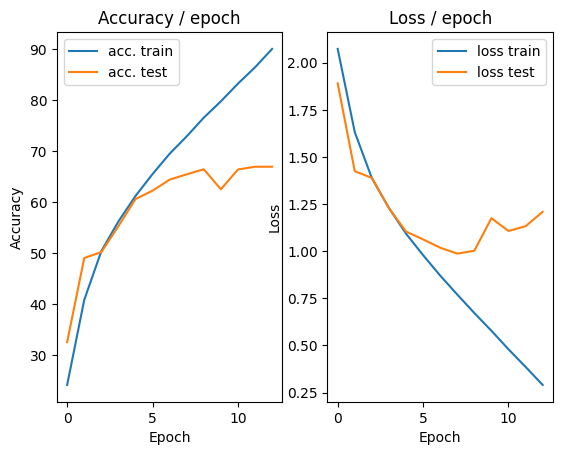

=== EPOCH 14 =====

[TRAIN Batch 000/391]	Time 0.151s (0.151s)	Loss 0.2919 (0.2919)	Prec@1  92.2 ( 92.2)	Prec@5 100.0 (100.0)


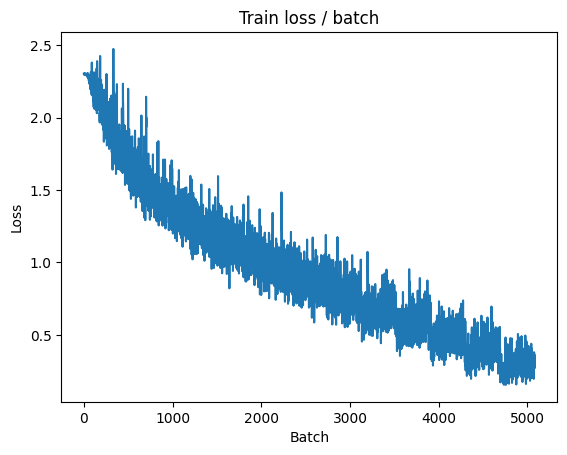

[TRAIN Batch 200/391]	Time 0.029s (0.025s)	Loss 0.0893 (0.1987)	Prec@1  98.4 ( 93.3)	Prec@5 100.0 (100.0)


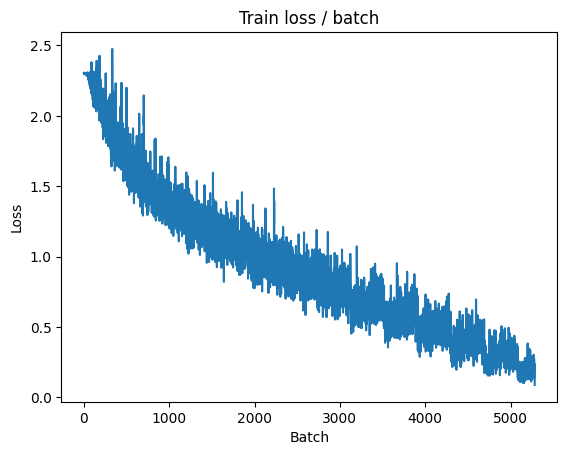


===============> Total time 8s	Avg loss 0.2186	Avg Prec@1 92.47 %	Avg Prec@5 99.93 %

[EVAL Batch 000/079]	Time 0.129s (0.129s)	Loss 1.1620 (1.1620)	Prec@1  71.1 ( 71.1)	Prec@5  96.1 ( 96.1)

===============> Total time 1s	Avg loss 1.1978	Avg Prec@1 69.32 %	Avg Prec@5 97.02 %



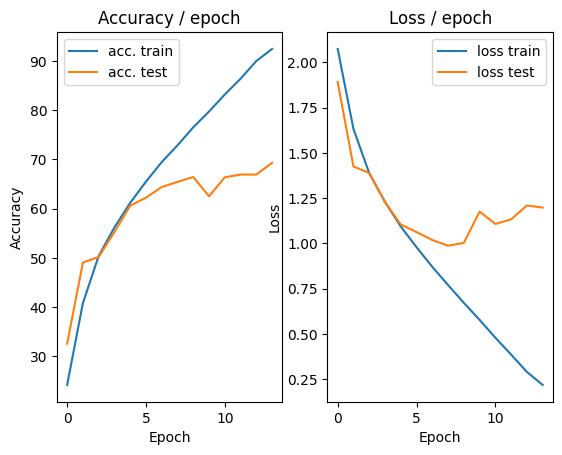

=== EPOCH 15 =====

[TRAIN Batch 000/391]	Time 0.143s (0.143s)	Loss 0.1190 (0.1190)	Prec@1  93.8 ( 93.8)	Prec@5 100.0 (100.0)


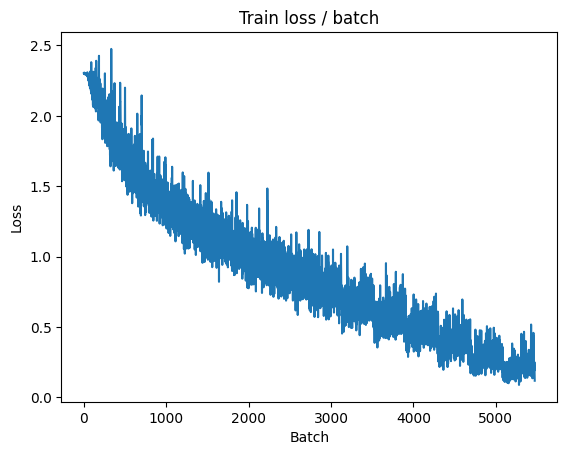

[TRAIN Batch 200/391]	Time 0.010s (0.020s)	Loss 0.1042 (0.1367)	Prec@1  96.9 ( 95.5)	Prec@5 100.0 (100.0)


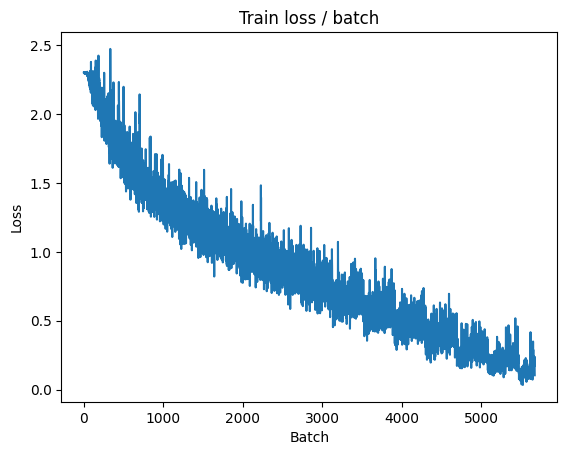


===============> Total time 8s	Avg loss 0.1602	Avg Prec@1 94.57 %	Avg Prec@5 99.97 %

[EVAL Batch 000/079]	Time 0.105s (0.105s)	Loss 1.3367 (1.3367)	Prec@1  71.9 ( 71.9)	Prec@5  97.7 ( 97.7)

===============> Total time 1s	Avg loss 1.4201	Avg Prec@1 67.59 %	Avg Prec@5 97.24 %



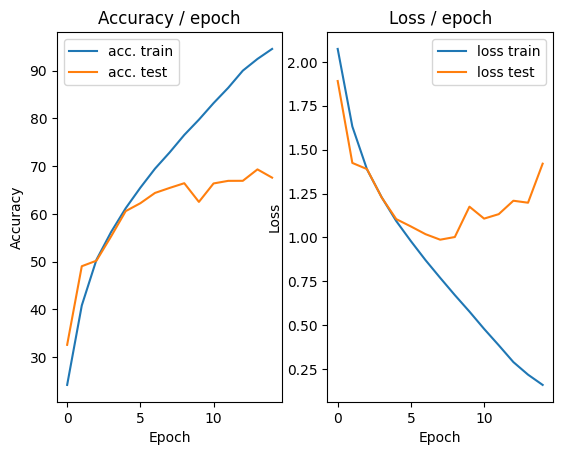

In [18]:
main(128, 0.1, cuda=True)

In [32]:
# Standardization
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        # We first define the convolution and pooling layers as a features extractor
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),  #output:64*4*4
        )
        # We then define fully connected layers as a classifier
        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000),
            nn.ReLU(),
            nn.Linear(1000, 10)
            # Reminder: The softmax is included in the loss, do not put it here
        )

    # Method called when we apply the network to an input batch
    def forward(self, input):
        bsize = input.size(0) # batch size
        output = self.features(input) # output of the conv layers
        output = output.view(bsize, -1) # we flatten the 2D feature maps into one 1D vector for each input
        output = self.classifier(output) # we compute the output of the fc layers
        return output

def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]

    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,
        transform=transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean, std)  # Normalization
        ]))
    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,
        transform=transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean, std)
        ]))

    train_loader = torch.utils.data.DataLoader(train_dataset,
                        batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,
                        batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader


def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=15, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)


=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.135s (0.135s)	Loss 2.3040 (2.3040)	Prec@1   8.6 (  8.6)	Prec@5  44.5 ( 44.5)


<Figure size 640x480 with 0 Axes>

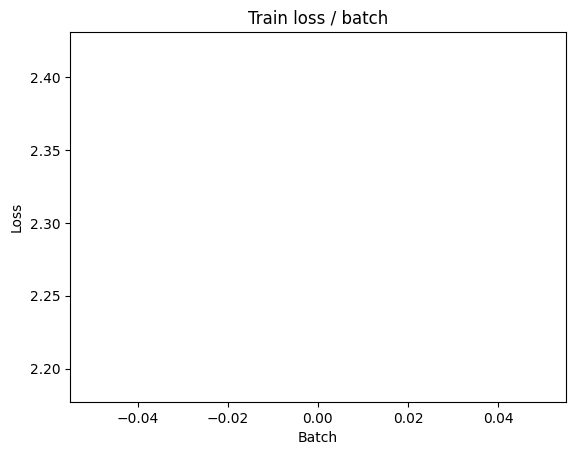

[TRAIN Batch 200/391]	Time 0.025s (0.030s)	Loss 1.5502 (1.9196)	Prec@1  44.5 ( 29.7)	Prec@5  89.8 ( 80.1)


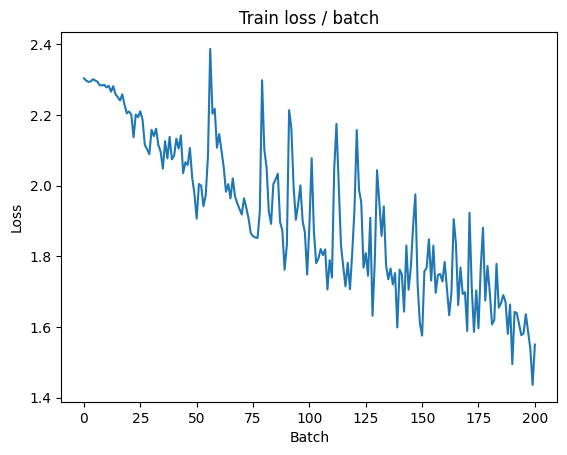


===============> Total time 12s	Avg loss 1.7279	Avg Prec@1 37.35 %	Avg Prec@5 85.56 %

[EVAL Batch 000/079]	Time 0.126s (0.126s)	Loss 1.3774 (1.3774)	Prec@1  54.7 ( 54.7)	Prec@5  91.4 ( 91.4)

===============> Total time 2s	Avg loss 1.3998	Avg Prec@1 49.27 %	Avg Prec@5 93.12 %



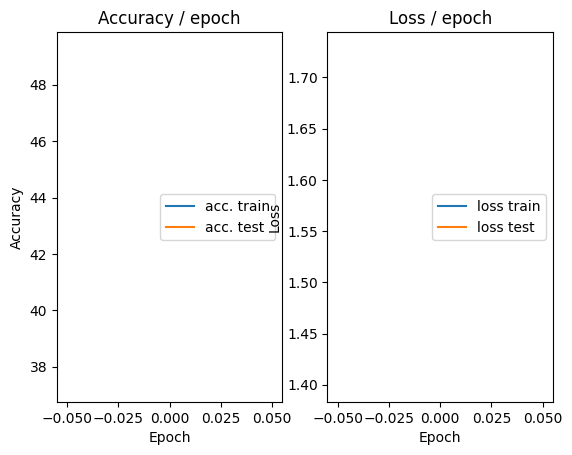

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.155s (0.155s)	Loss 1.5341 (1.5341)	Prec@1  46.9 ( 46.9)	Prec@5  89.8 ( 89.8)


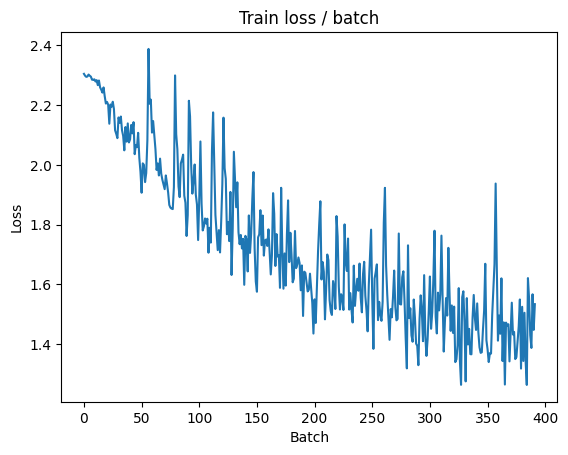

[TRAIN Batch 200/391]	Time 0.018s (0.035s)	Loss 1.3990 (1.3337)	Prec@1  53.9 ( 52.8)	Prec@5  93.0 ( 93.9)


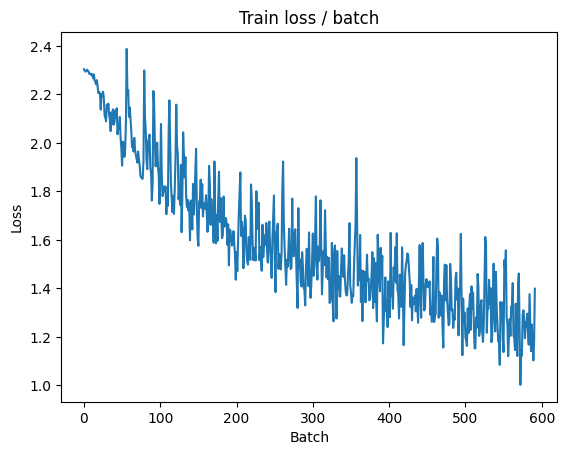


===============> Total time 12s	Avg loss 1.2709	Avg Prec@1 54.92 %	Avg Prec@5 94.52 %

[EVAL Batch 000/079]	Time 0.128s (0.128s)	Loss 1.0070 (1.0070)	Prec@1  68.8 ( 68.8)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 1.0893	Avg Prec@1 61.98 %	Avg Prec@5 96.31 %



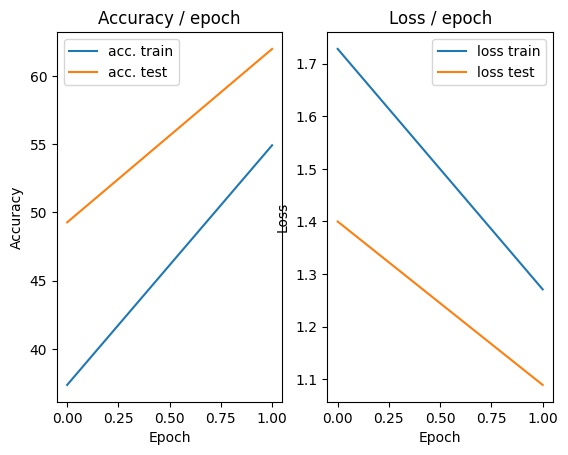

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.145s (0.145s)	Loss 1.1584 (1.1584)	Prec@1  58.6 ( 58.6)	Prec@5  96.1 ( 96.1)


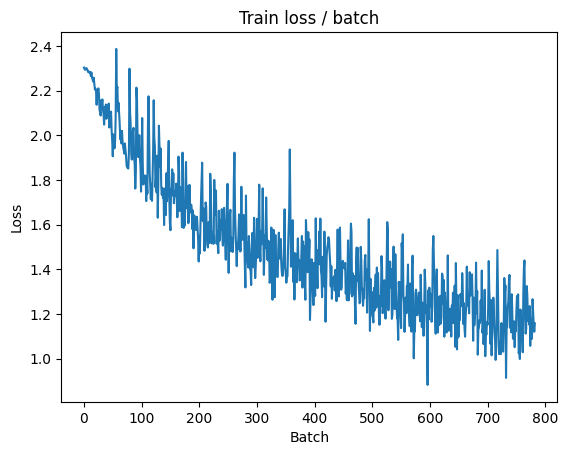

[TRAIN Batch 200/391]	Time 0.049s (0.035s)	Loss 0.9954 (1.0846)	Prec@1  62.5 ( 61.9)	Prec@5  97.7 ( 96.0)


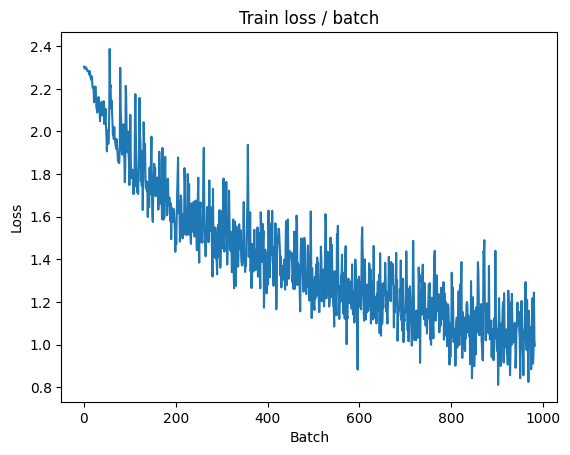


===============> Total time 12s	Avg loss 1.0402	Avg Prec@1 63.50 %	Avg Prec@5 96.42 %

[EVAL Batch 000/079]	Time 0.122s (0.122s)	Loss 1.3180 (1.3180)	Prec@1  53.9 ( 53.9)	Prec@5  95.3 ( 95.3)

===============> Total time 2s	Avg loss 1.3192	Avg Prec@1 54.60 %	Avg Prec@5 94.28 %



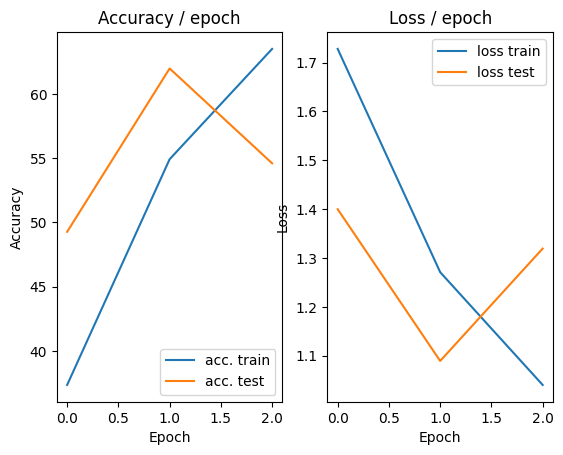

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.250s (0.250s)	Loss 1.1781 (1.1781)	Prec@1  61.7 ( 61.7)	Prec@5  93.8 ( 93.8)


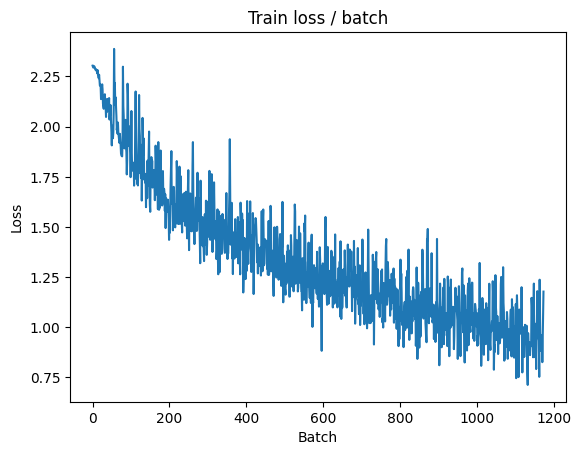

[TRAIN Batch 200/391]	Time 0.050s (0.035s)	Loss 0.8266 (0.8802)	Prec@1  71.9 ( 69.4)	Prec@5  96.9 ( 97.4)


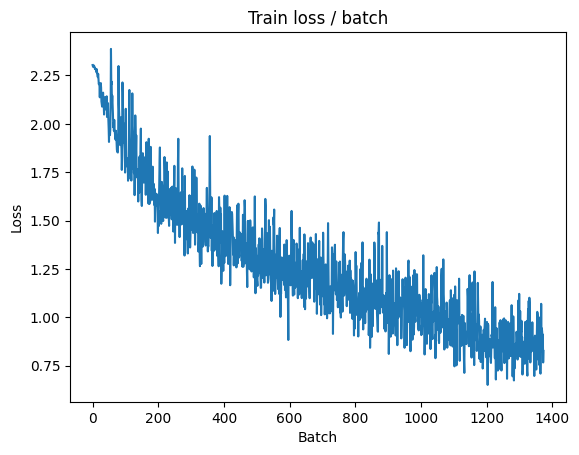


===============> Total time 12s	Avg loss 0.8639	Avg Prec@1 70.01 %	Avg Prec@5 97.60 %

[EVAL Batch 000/079]	Time 0.188s (0.188s)	Loss 0.8670 (0.8670)	Prec@1  69.5 ( 69.5)	Prec@5  98.4 ( 98.4)

===============> Total time 3s	Avg loss 0.9832	Avg Prec@1 65.33 %	Avg Prec@5 97.00 %



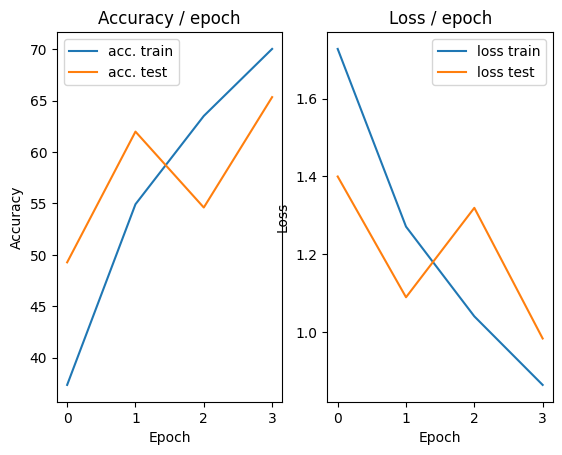

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.148s (0.148s)	Loss 0.7325 (0.7325)	Prec@1  71.1 ( 71.1)	Prec@5  99.2 ( 99.2)


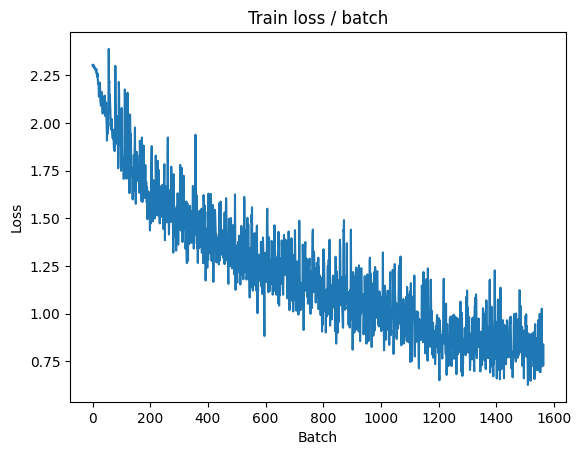

[TRAIN Batch 200/391]	Time 0.009s (0.031s)	Loss 0.7020 (0.7308)	Prec@1  73.4 ( 74.4)	Prec@5  98.4 ( 98.4)


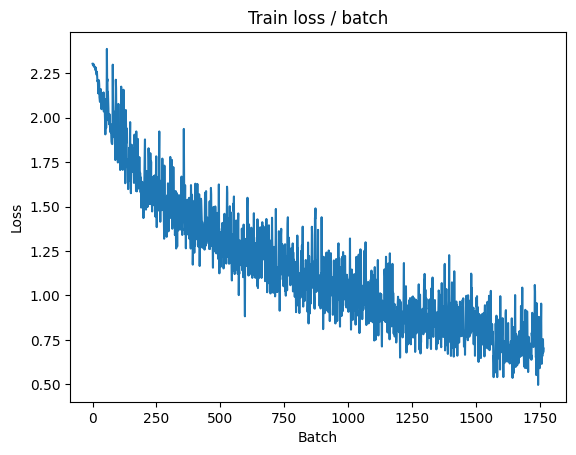


===============> Total time 12s	Avg loss 0.7261	Avg Prec@1 74.62 %	Avg Prec@5 98.45 %

[EVAL Batch 000/079]	Time 0.117s (0.117s)	Loss 0.8595 (0.8595)	Prec@1  71.1 ( 71.1)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.9080	Avg Prec@1 69.63 %	Avg Prec@5 96.95 %



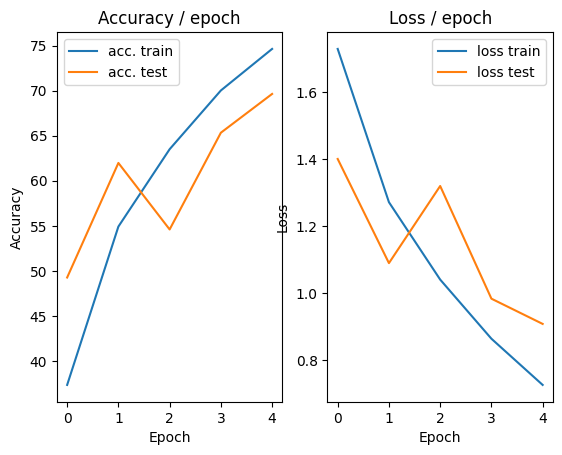

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.154s (0.154s)	Loss 0.6109 (0.6109)	Prec@1  78.1 ( 78.1)	Prec@5  97.7 ( 97.7)


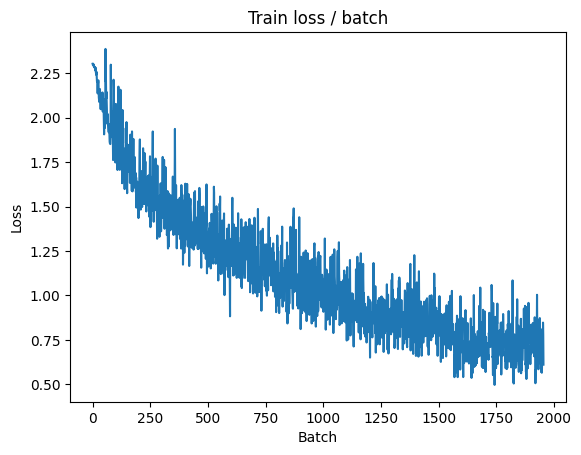

[TRAIN Batch 200/391]	Time 0.038s (0.030s)	Loss 0.6846 (0.5992)	Prec@1  70.3 ( 79.2)	Prec@5  99.2 ( 99.0)


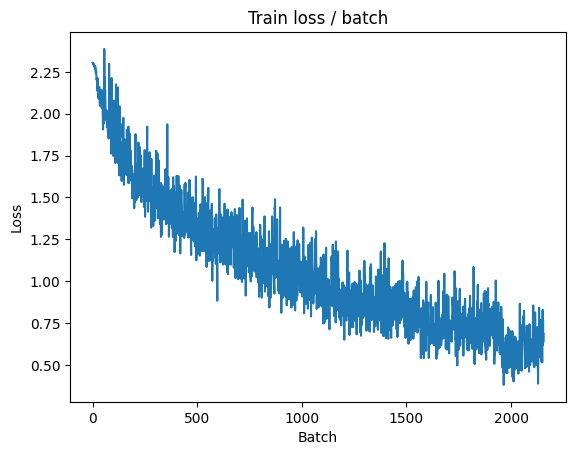


===============> Total time 12s	Avg loss 0.5976	Avg Prec@1 79.24 %	Avg Prec@5 98.97 %

[EVAL Batch 000/079]	Time 0.117s (0.117s)	Loss 0.7468 (0.7468)	Prec@1  70.3 ( 70.3)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.8662	Avg Prec@1 71.02 %	Avg Prec@5 97.53 %



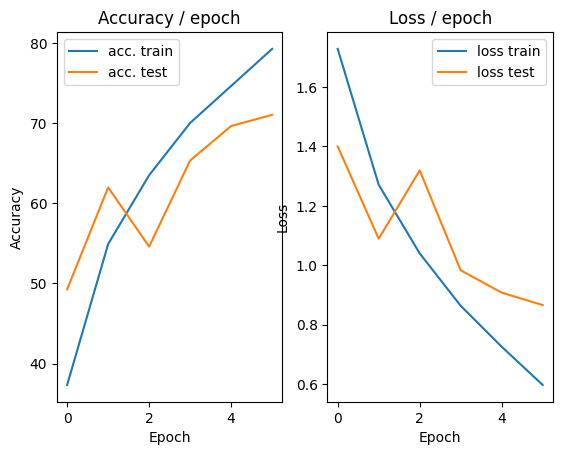

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.149s (0.149s)	Loss 0.4907 (0.4907)	Prec@1  83.6 ( 83.6)	Prec@5  98.4 ( 98.4)


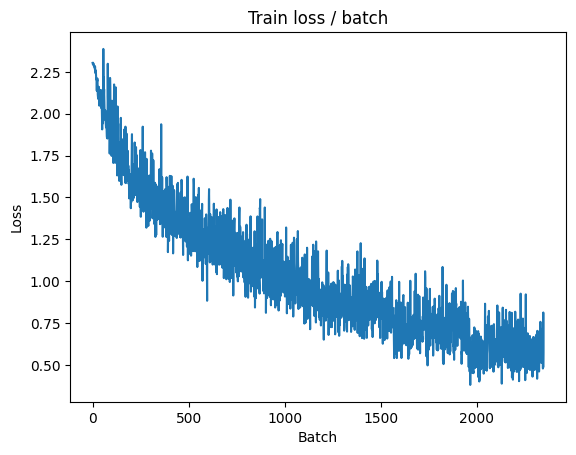

[TRAIN Batch 200/391]	Time 0.081s (0.034s)	Loss 0.5673 (0.4790)	Prec@1  82.8 ( 83.3)	Prec@5  98.4 ( 99.4)


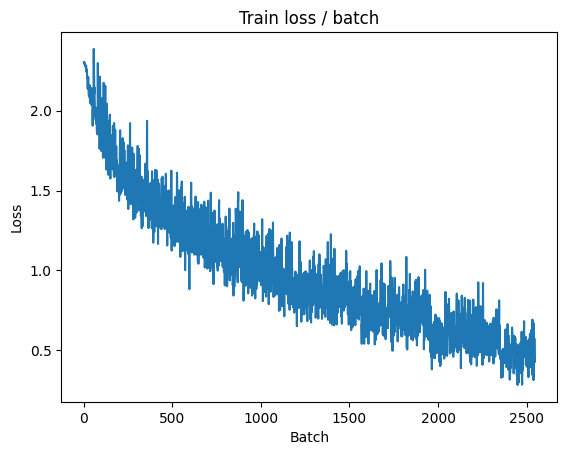


===============> Total time 12s	Avg loss 0.4865	Avg Prec@1 83.07 %	Avg Prec@5 99.38 %

[EVAL Batch 000/079]	Time 0.117s (0.117s)	Loss 0.8268 (0.8268)	Prec@1  69.5 ( 69.5)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.8869	Avg Prec@1 71.18 %	Avg Prec@5 97.89 %



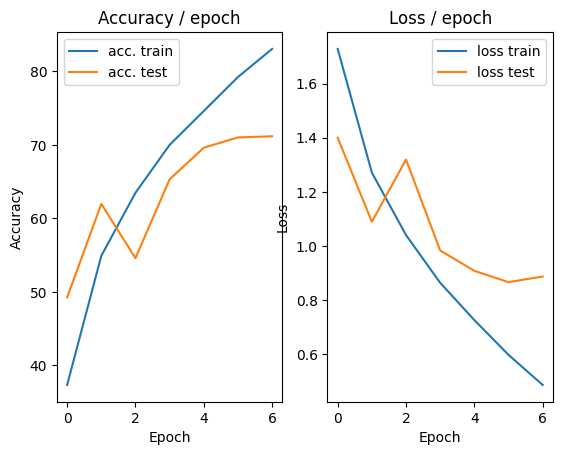

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.150s (0.150s)	Loss 0.3945 (0.3945)	Prec@1  89.1 ( 89.1)	Prec@5  99.2 ( 99.2)


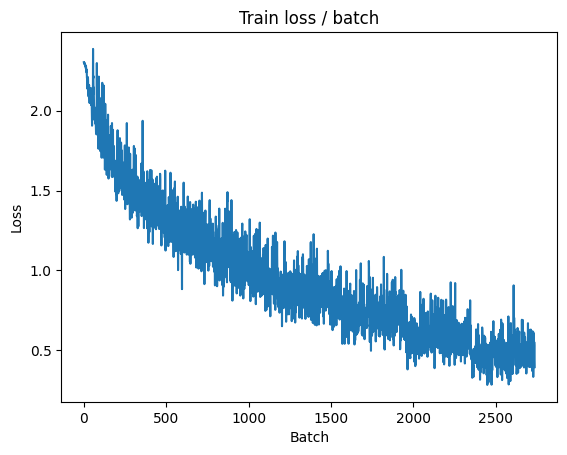

[TRAIN Batch 200/391]	Time 0.047s (0.034s)	Loss 0.5356 (0.3726)	Prec@1  82.8 ( 87.3)	Prec@5 100.0 ( 99.7)


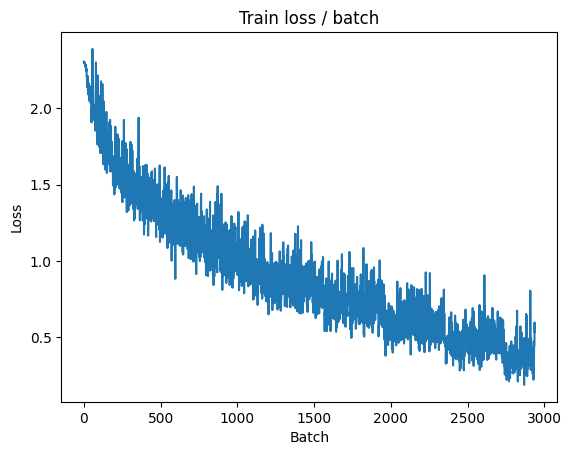


===============> Total time 12s	Avg loss 0.3847	Avg Prec@1 86.68 %	Avg Prec@5 99.64 %

[EVAL Batch 000/079]	Time 0.119s (0.119s)	Loss 0.7958 (0.7958)	Prec@1  77.3 ( 77.3)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.9338	Avg Prec@1 72.77 %	Avg Prec@5 97.62 %



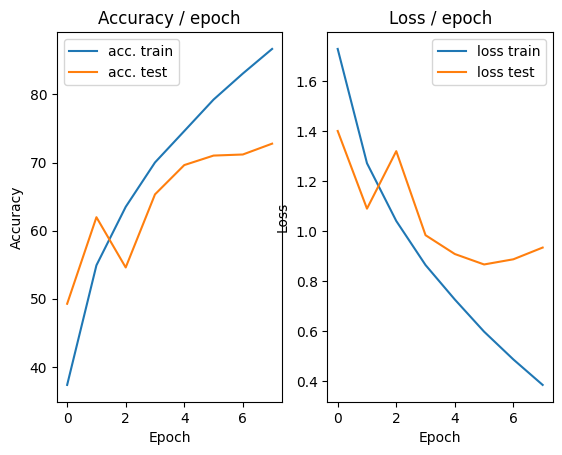

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.154s (0.154s)	Loss 0.3755 (0.3755)	Prec@1  86.7 ( 86.7)	Prec@5 100.0 (100.0)


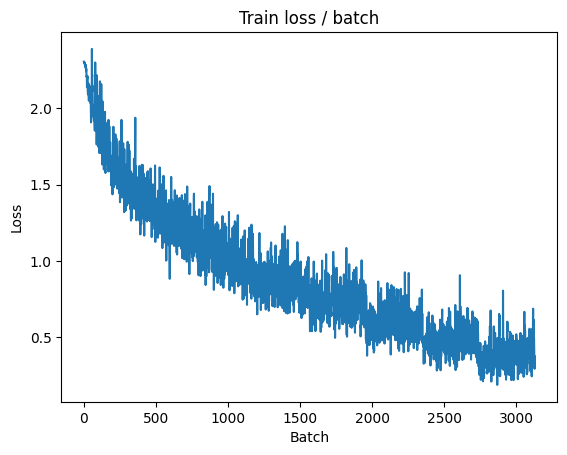

[TRAIN Batch 200/391]	Time 0.014s (0.035s)	Loss 0.2845 (0.2633)	Prec@1  90.6 ( 91.0)	Prec@5 100.0 ( 99.8)


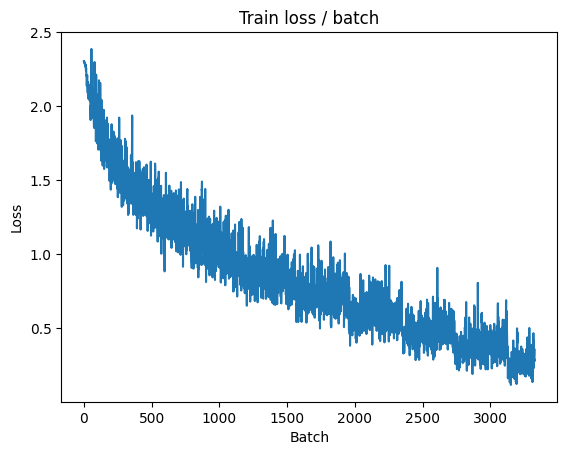


===============> Total time 12s	Avg loss 0.2822	Avg Prec@1 90.20 %	Avg Prec@5 99.83 %

[EVAL Batch 000/079]	Time 0.131s (0.131s)	Loss 0.8183 (0.8183)	Prec@1  77.3 ( 77.3)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.9057	Avg Prec@1 73.78 %	Avg Prec@5 97.86 %



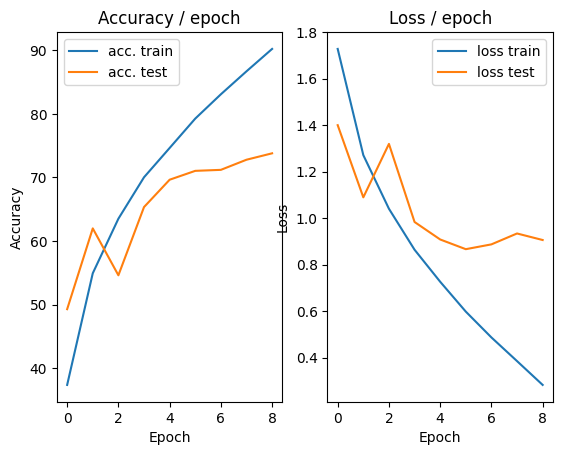

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.155s (0.155s)	Loss 0.2280 (0.2280)	Prec@1  91.4 ( 91.4)	Prec@5 100.0 (100.0)


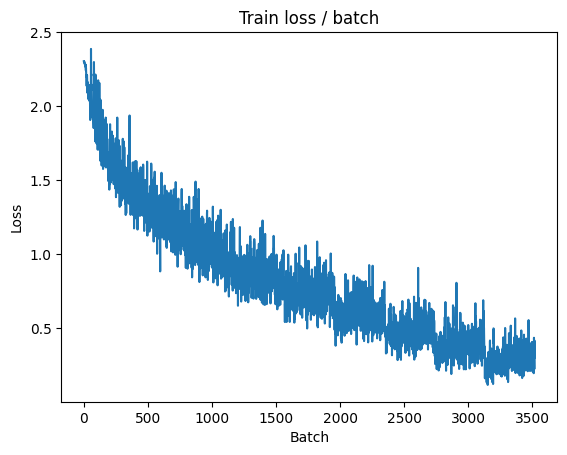

[TRAIN Batch 200/391]	Time 0.015s (0.031s)	Loss 0.2072 (0.1833)	Prec@1  89.8 ( 93.7)	Prec@5 100.0 (100.0)


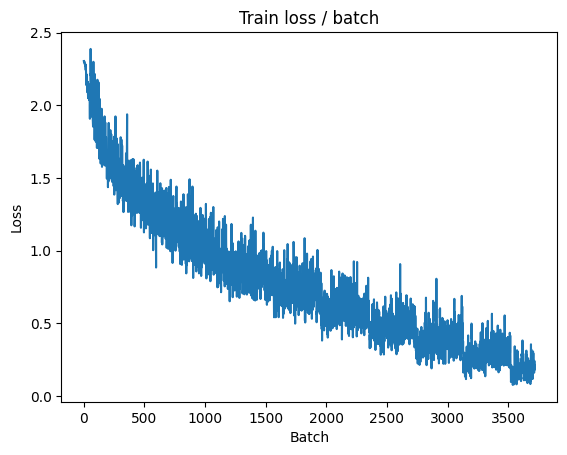


===============> Total time 14s	Avg loss 0.2084	Avg Prec@1 92.77 %	Avg Prec@5 99.94 %

[EVAL Batch 000/079]	Time 0.237s (0.237s)	Loss 1.1946 (1.1946)	Prec@1  72.7 ( 72.7)	Prec@5  96.9 ( 96.9)

===============> Total time 3s	Avg loss 1.1571	Avg Prec@1 72.45 %	Avg Prec@5 97.39 %



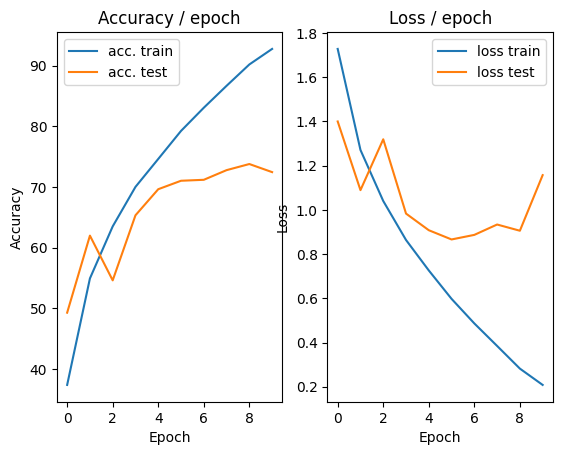

=== EPOCH 11 =====

[TRAIN Batch 000/391]	Time 0.150s (0.150s)	Loss 0.2415 (0.2415)	Prec@1  90.6 ( 90.6)	Prec@5 100.0 (100.0)


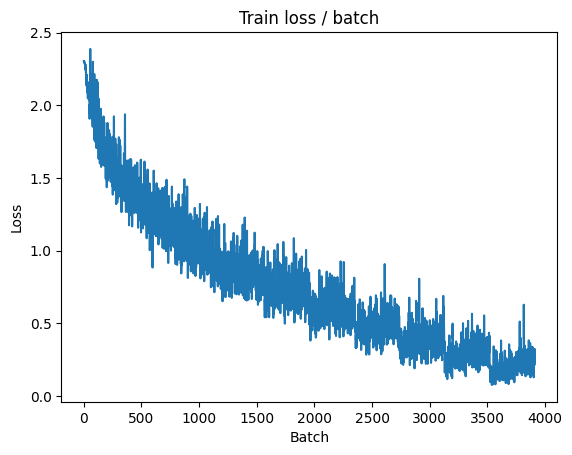

[TRAIN Batch 200/391]	Time 0.025s (0.035s)	Loss 0.1530 (0.1163)	Prec@1  95.3 ( 96.3)	Prec@5 100.0 (100.0)


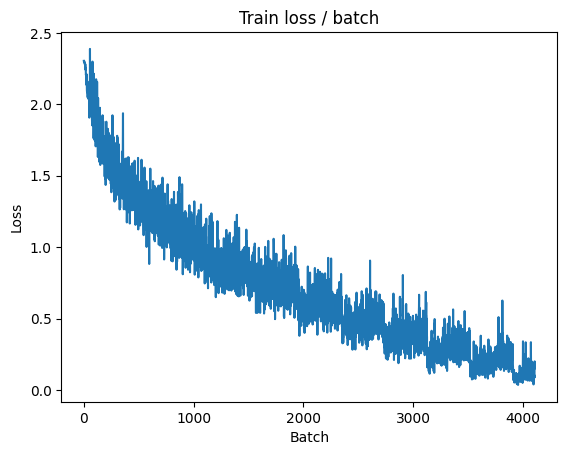


===============> Total time 12s	Avg loss 0.1531	Avg Prec@1 94.96 %	Avg Prec@5 99.95 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 1.0133 (1.0133)	Prec@1  74.2 ( 74.2)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 1.2144	Avg Prec@1 72.21 %	Avg Prec@5 97.56 %



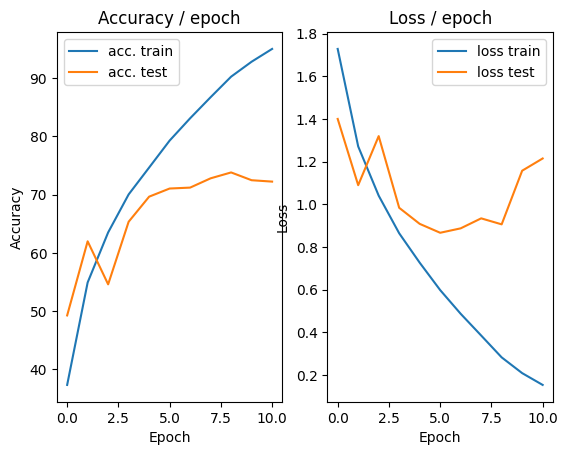

=== EPOCH 12 =====

[TRAIN Batch 000/391]	Time 0.164s (0.164s)	Loss 0.1057 (0.1057)	Prec@1  97.7 ( 97.7)	Prec@5 100.0 (100.0)


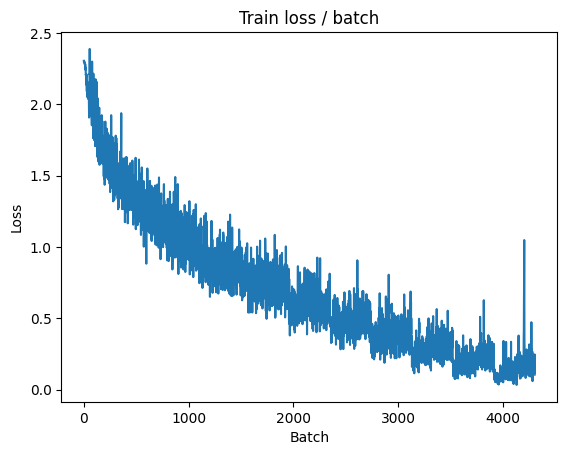

[TRAIN Batch 200/391]	Time 0.009s (0.036s)	Loss 0.1575 (0.0839)	Prec@1  94.5 ( 97.3)	Prec@5 100.0 (100.0)


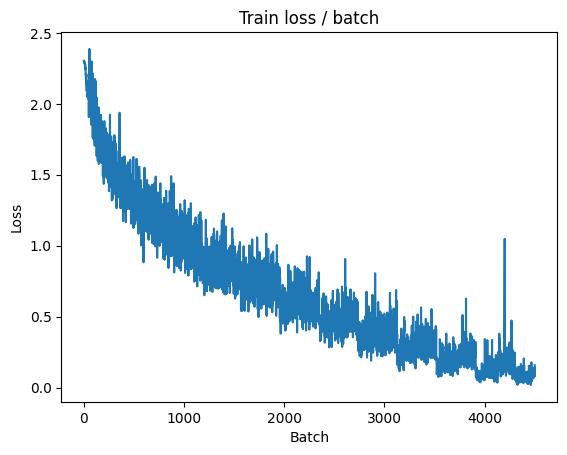


===============> Total time 13s	Avg loss 0.1055	Avg Prec@1 96.47 %	Avg Prec@5 99.99 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 0.9662 (0.9662)	Prec@1  77.3 ( 77.3)	Prec@5  98.4 ( 98.4)

===============> Total time 3s	Avg loss 1.3762	Avg Prec@1 71.07 %	Avg Prec@5 97.30 %



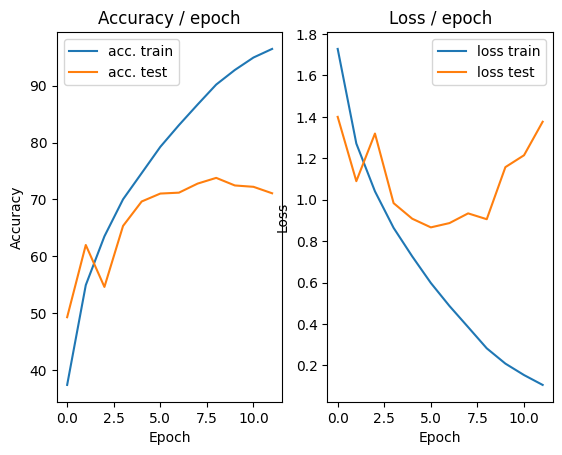

=== EPOCH 13 =====

[TRAIN Batch 000/391]	Time 0.229s (0.229s)	Loss 0.1676 (0.1676)	Prec@1  93.8 ( 93.8)	Prec@5 100.0 (100.0)


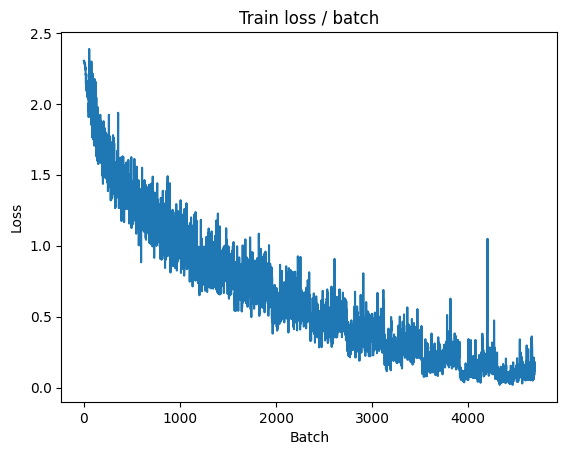

[TRAIN Batch 200/391]	Time 0.012s (0.030s)	Loss 0.0851 (0.0681)	Prec@1  95.3 ( 97.8)	Prec@5 100.0 (100.0)


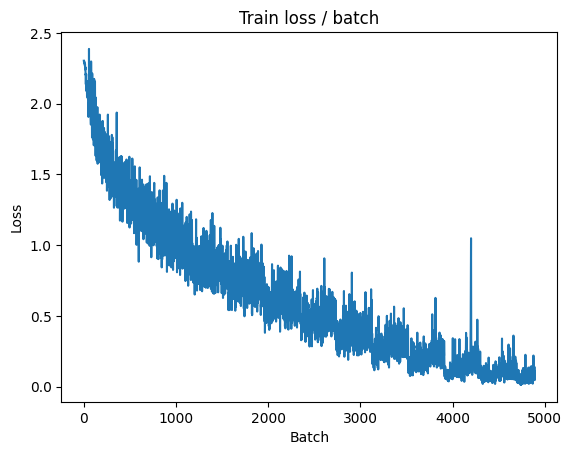


===============> Total time 12s	Avg loss 0.0828	Avg Prec@1 97.23 %	Avg Prec@5 99.99 %

[EVAL Batch 000/079]	Time 0.225s (0.225s)	Loss 1.5583 (1.5583)	Prec@1  73.4 ( 73.4)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 1.5064	Avg Prec@1 71.08 %	Avg Prec@5 97.24 %



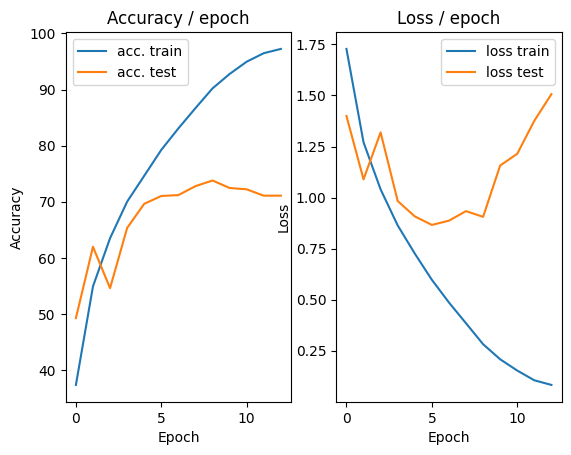

=== EPOCH 14 =====

[TRAIN Batch 000/391]	Time 0.183s (0.183s)	Loss 0.2102 (0.2102)	Prec@1  94.5 ( 94.5)	Prec@5 100.0 (100.0)


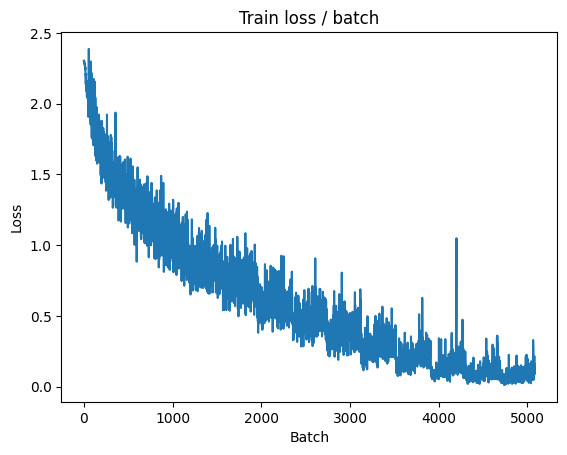

[TRAIN Batch 200/391]	Time 0.034s (0.030s)	Loss 0.0655 (0.0526)	Prec@1  97.7 ( 98.4)	Prec@5 100.0 (100.0)


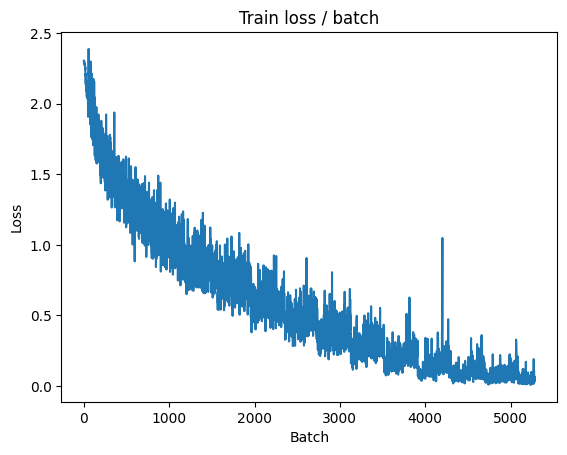


===============> Total time 12s	Avg loss 0.0655	Avg Prec@1 97.86 %	Avg Prec@5 100.00 %

[EVAL Batch 000/079]	Time 0.133s (0.133s)	Loss 1.3476 (1.3476)	Prec@1  76.6 ( 76.6)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 1.3416	Avg Prec@1 73.93 %	Avg Prec@5 97.32 %



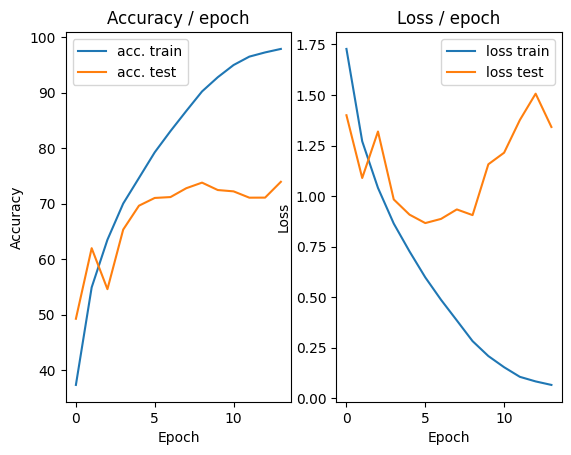

=== EPOCH 15 =====

[TRAIN Batch 000/391]	Time 0.158s (0.158s)	Loss 0.0715 (0.0715)	Prec@1  98.4 ( 98.4)	Prec@5 100.0 (100.0)


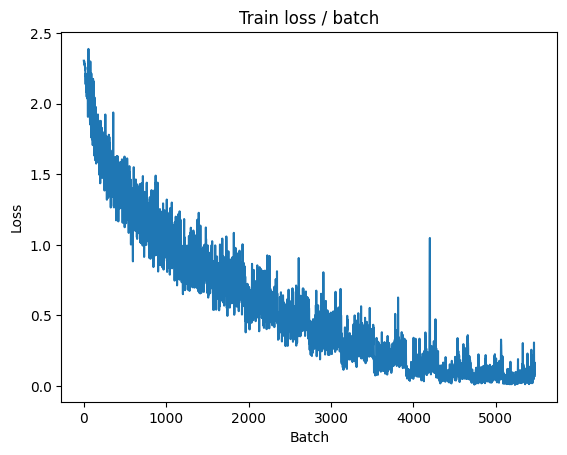

[TRAIN Batch 200/391]	Time 0.013s (0.032s)	Loss 0.0467 (0.0495)	Prec@1  97.7 ( 98.4)	Prec@5 100.0 (100.0)


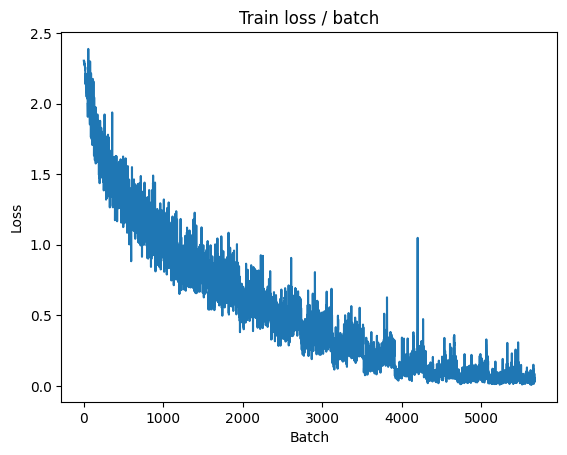


===============> Total time 13s	Avg loss 0.0650	Avg Prec@1 97.86 %	Avg Prec@5 100.00 %

[EVAL Batch 000/079]	Time 0.152s (0.152s)	Loss 1.2512 (1.2512)	Prec@1  73.4 ( 73.4)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 1.4178	Avg Prec@1 73.94 %	Avg Prec@5 97.81 %



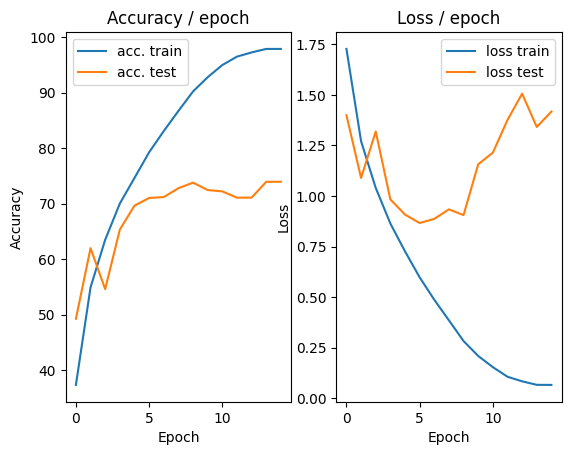

In [33]:
main(128, 0.1, cuda=True)

In [35]:
#  Increase in the number of training examples by data increase
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000), # 64 * 4 * 4 = 1024
            nn.ReLU(),
            nn.Linear(1000, 10)
        )

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.RandomCrop(28),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.CenterCrop(28),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader

def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=10, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)


=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.153s (0.153s)	Loss 2.3034 (2.3034)	Prec@1   9.4 (  9.4)	Prec@5  46.9 ( 46.9)


<Figure size 640x480 with 0 Axes>

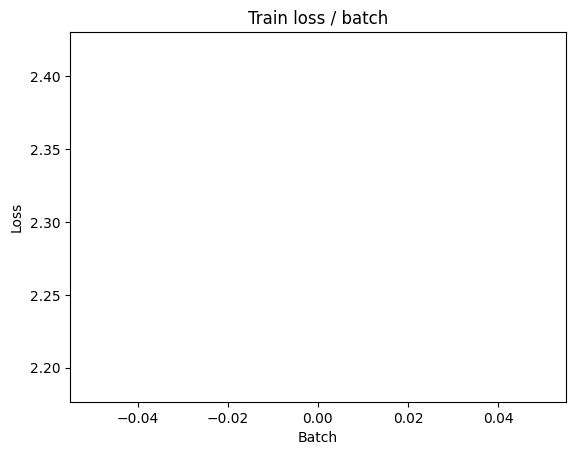

[TRAIN Batch 200/391]	Time 0.025s (0.038s)	Loss 1.6831 (1.9626)	Prec@1  39.8 ( 27.7)	Prec@5  83.6 ( 79.0)


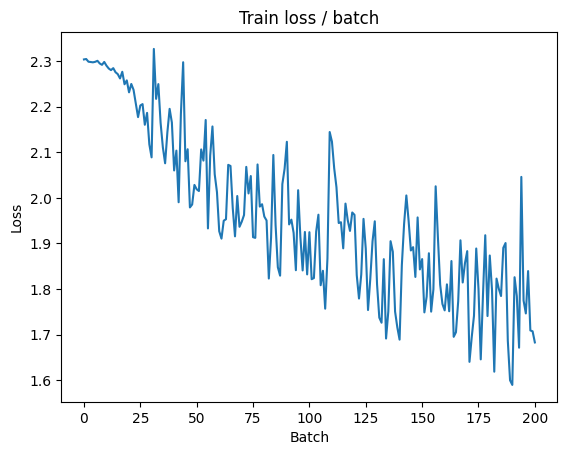


===============> Total time 16s	Avg loss 1.8118	Avg Prec@1 33.69 %	Avg Prec@5 83.96 %

[EVAL Batch 000/079]	Time 0.150s (0.150s)	Loss 1.7746 (1.7746)	Prec@1  41.4 ( 41.4)	Prec@5  89.1 ( 89.1)

===============> Total time 2s	Avg loss 1.7333	Avg Prec@1 40.44 %	Avg Prec@5 87.01 %



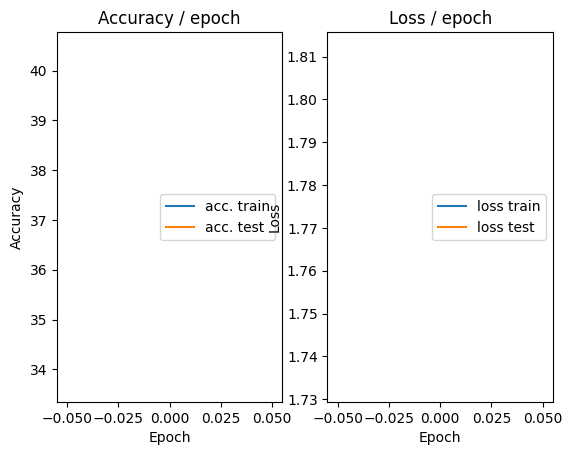

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.152s (0.152s)	Loss 1.8508 (1.8508)	Prec@1  31.2 ( 31.2)	Prec@5  84.4 ( 84.4)


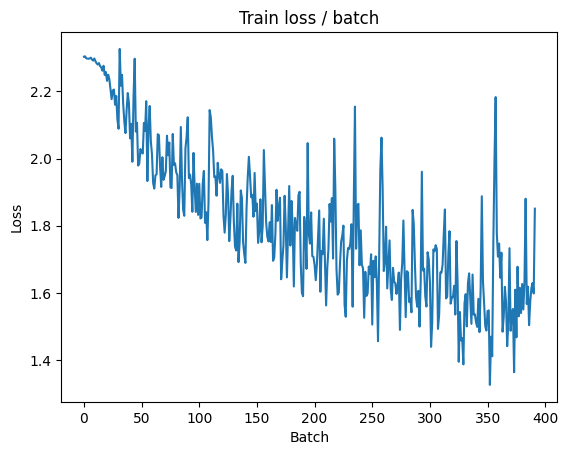

[TRAIN Batch 200/391]	Time 0.070s (0.043s)	Loss 1.3559 (1.4563)	Prec@1  57.0 ( 48.0)	Prec@5  93.8 ( 92.5)


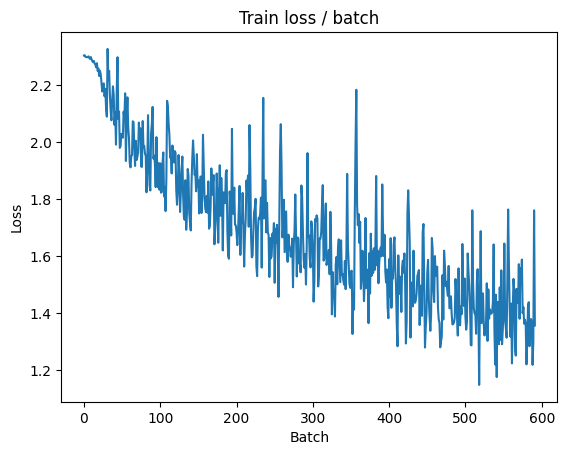


===============> Total time 16s	Avg loss 1.3998	Avg Prec@1 50.14 %	Avg Prec@5 93.16 %

[EVAL Batch 000/079]	Time 0.166s (0.166s)	Loss 1.4433 (1.4433)	Prec@1  50.8 ( 50.8)	Prec@5  90.6 ( 90.6)

===============> Total time 3s	Avg loss 1.4413	Avg Prec@1 50.07 %	Avg Prec@5 91.90 %



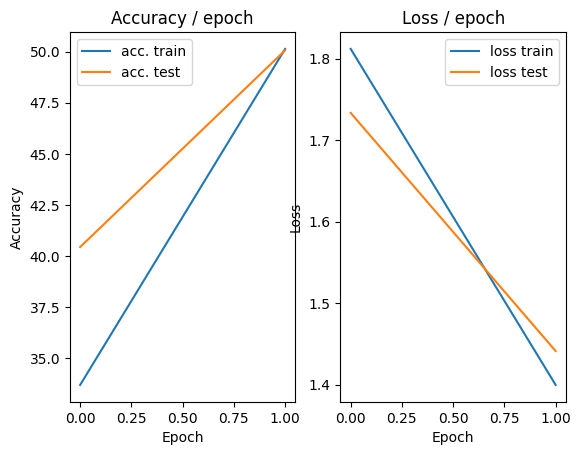

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.154s (0.154s)	Loss 1.4521 (1.4521)	Prec@1  49.2 ( 49.2)	Prec@5  90.6 ( 90.6)


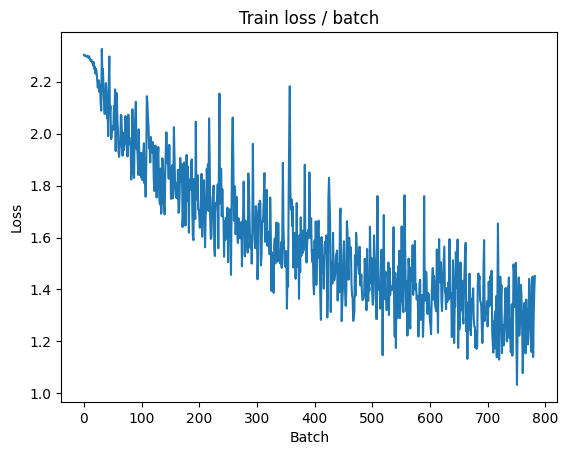

[TRAIN Batch 200/391]	Time 0.060s (0.041s)	Loss 1.1898 (1.2229)	Prec@1  60.9 ( 56.8)	Prec@5  93.0 ( 94.9)


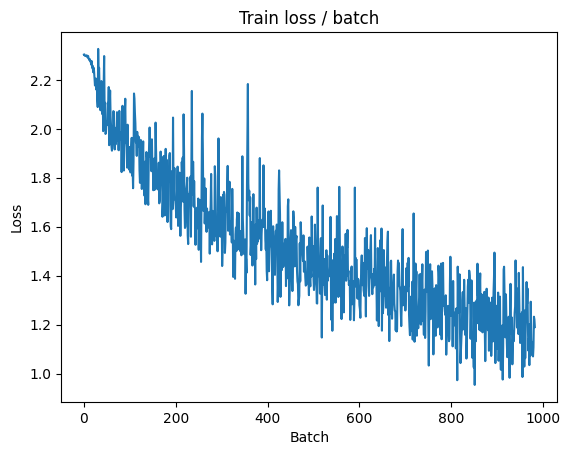


===============> Total time 16s	Avg loss 1.1783	Avg Prec@1 58.41 %	Avg Prec@5 95.32 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 1.0635 (1.0635)	Prec@1  63.3 ( 63.3)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 1.0494	Avg Prec@1 62.98 %	Avg Prec@5 96.27 %



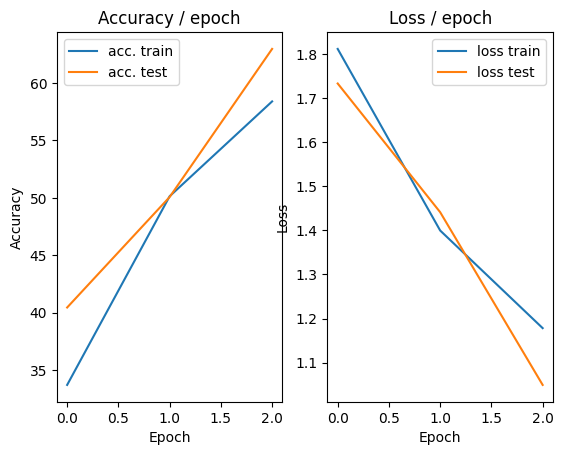

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.156s (0.156s)	Loss 0.9728 (0.9728)	Prec@1  60.9 ( 60.9)	Prec@5  97.7 ( 97.7)


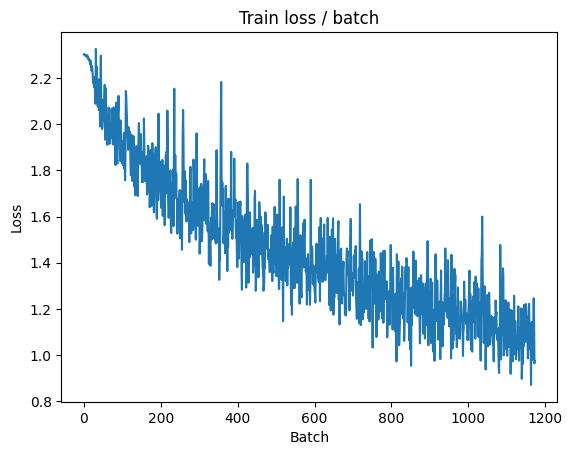

[TRAIN Batch 200/391]	Time 0.011s (0.044s)	Loss 1.0825 (1.0524)	Prec@1  61.7 ( 63.1)	Prec@5  93.8 ( 96.4)


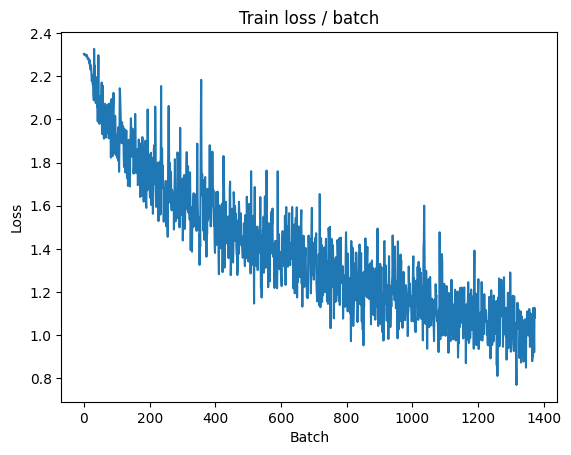


===============> Total time 16s	Avg loss 1.0270	Avg Prec@1 64.04 %	Avg Prec@5 96.53 %

[EVAL Batch 000/079]	Time 0.174s (0.174s)	Loss 0.9942 (0.9942)	Prec@1  65.6 ( 65.6)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.9905	Avg Prec@1 65.90 %	Avg Prec@5 96.93 %



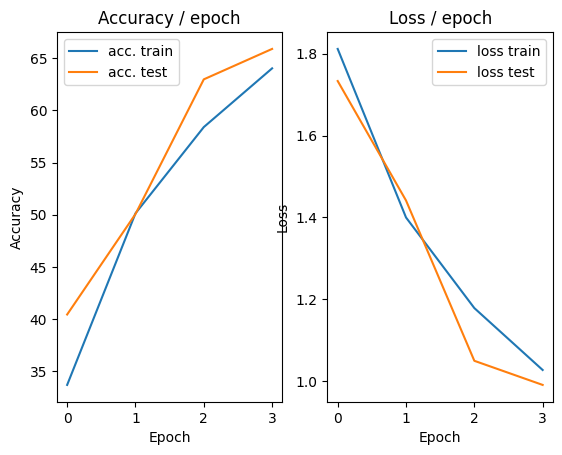

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.162s (0.162s)	Loss 0.9406 (0.9406)	Prec@1  68.8 ( 68.8)	Prec@5  96.9 ( 96.9)


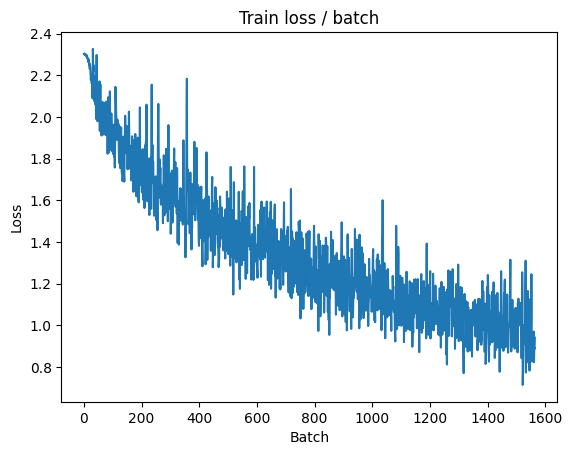

[TRAIN Batch 200/391]	Time 0.041s (0.039s)	Loss 1.0368 (0.9385)	Prec@1  60.2 ( 67.2)	Prec@5  95.3 ( 97.2)


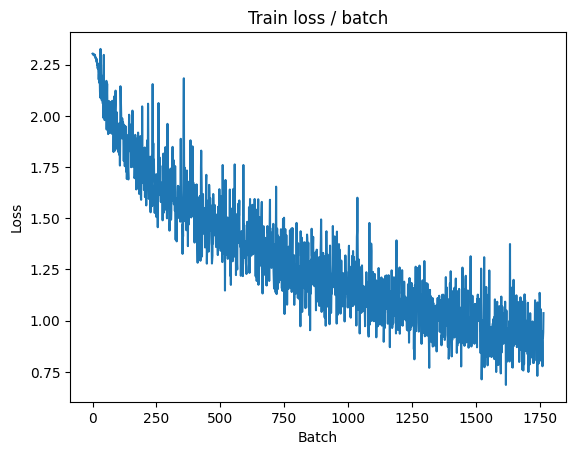


===============> Total time 16s	Avg loss 0.9228	Avg Prec@1 67.65 %	Avg Prec@5 97.25 %

[EVAL Batch 000/079]	Time 0.127s (0.127s)	Loss 0.9310 (0.9310)	Prec@1  69.5 ( 69.5)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.9408	Avg Prec@1 67.70 %	Avg Prec@5 97.03 %



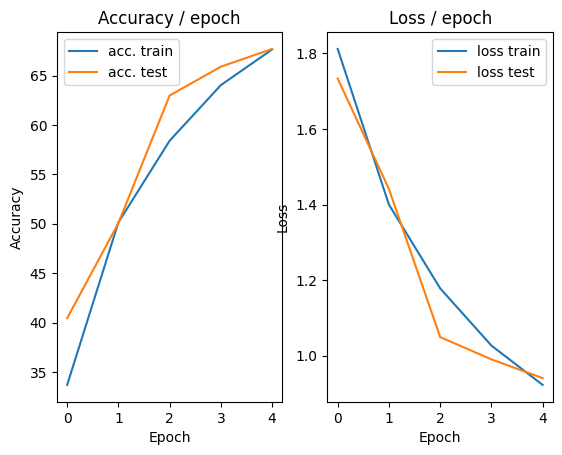

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.173s (0.173s)	Loss 1.0245 (1.0245)	Prec@1  63.3 ( 63.3)	Prec@5  97.7 ( 97.7)


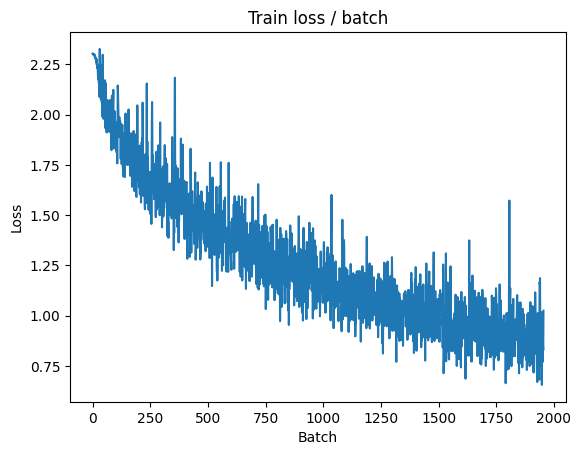

[TRAIN Batch 200/391]	Time 0.032s (0.043s)	Loss 1.0498 (0.8491)	Prec@1  64.1 ( 70.5)	Prec@5  96.1 ( 97.7)


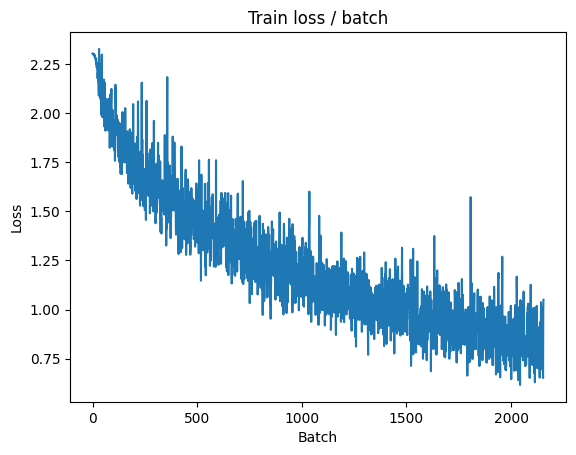


===============> Total time 16s	Avg loss 0.8410	Avg Prec@1 70.77 %	Avg Prec@5 97.80 %

[EVAL Batch 000/079]	Time 0.157s (0.157s)	Loss 0.7410 (0.7410)	Prec@1  78.9 ( 78.9)	Prec@5 100.0 (100.0)

===============> Total time 2s	Avg loss 0.7902	Avg Prec@1 72.55 %	Avg Prec@5 98.11 %



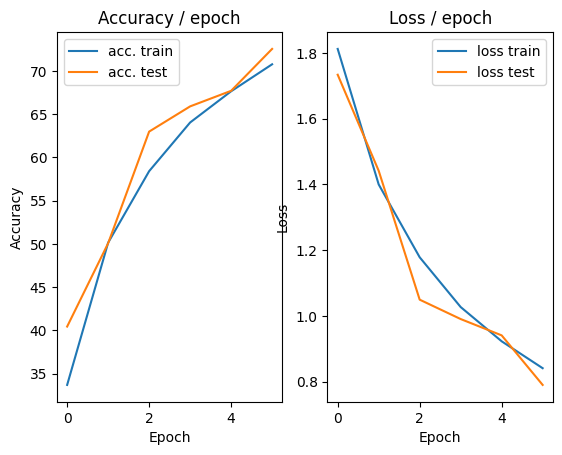

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.165s (0.165s)	Loss 0.7423 (0.7423)	Prec@1  77.3 ( 77.3)	Prec@5  96.9 ( 96.9)


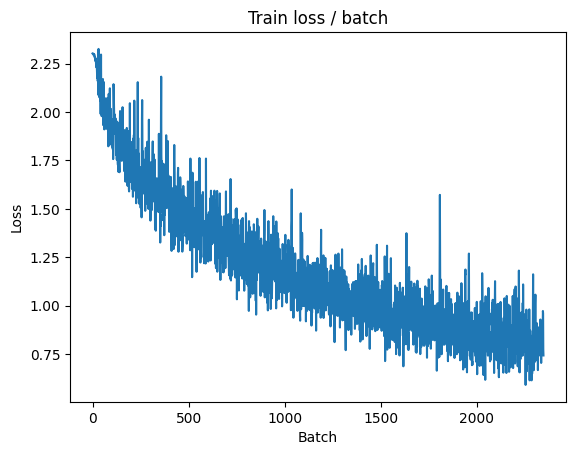

[TRAIN Batch 200/391]	Time 0.010s (0.038s)	Loss 0.8909 (0.7800)	Prec@1  66.4 ( 72.7)	Prec@5  99.2 ( 98.1)


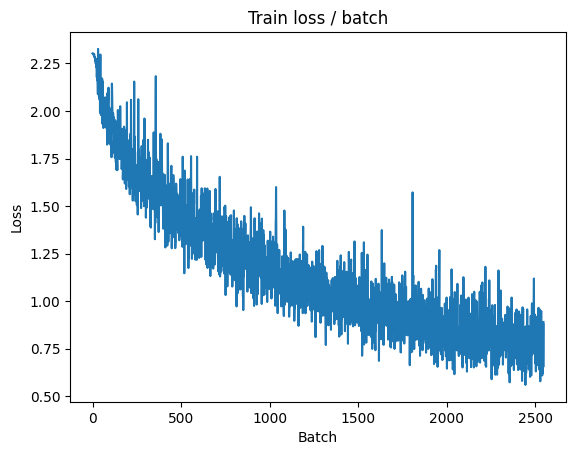


===============> Total time 15s	Avg loss 0.7723	Avg Prec@1 73.01 %	Avg Prec@5 98.10 %

[EVAL Batch 000/079]	Time 0.146s (0.146s)	Loss 0.8073 (0.8073)	Prec@1  68.8 ( 68.8)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.8355	Avg Prec@1 71.46 %	Avg Prec@5 97.71 %



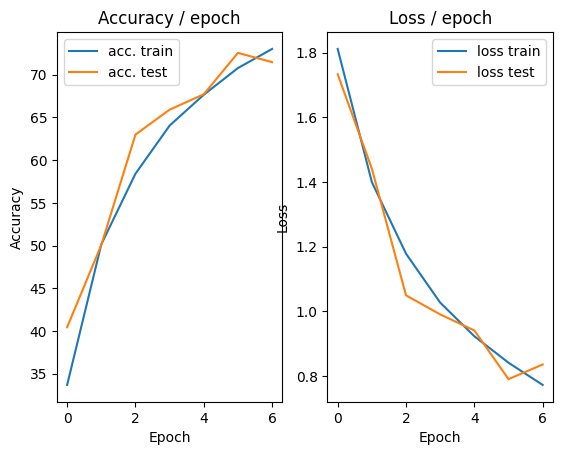

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.167s (0.167s)	Loss 0.8088 (0.8088)	Prec@1  76.6 ( 76.6)	Prec@5  96.1 ( 96.1)


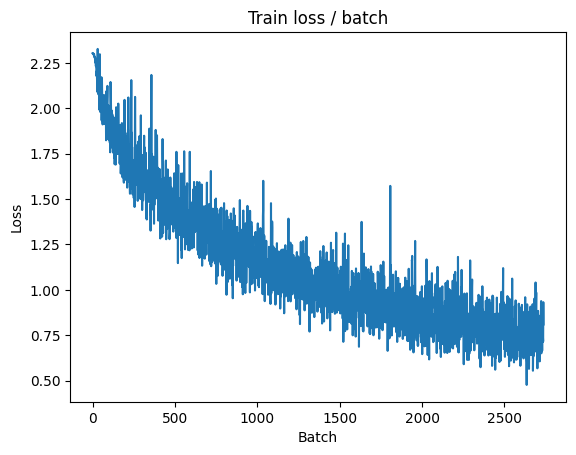

[TRAIN Batch 200/391]	Time 0.054s (0.044s)	Loss 0.7565 (0.7359)	Prec@1  74.2 ( 74.6)	Prec@5  96.9 ( 98.2)


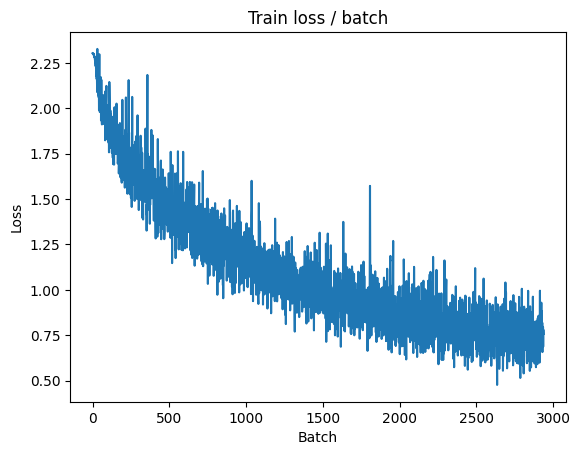


===============> Total time 16s	Avg loss 0.7238	Avg Prec@1 74.94 %	Avg Prec@5 98.33 %

[EVAL Batch 000/079]	Time 0.184s (0.184s)	Loss 0.7734 (0.7734)	Prec@1  75.8 ( 75.8)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.7683	Avg Prec@1 73.98 %	Avg Prec@5 97.91 %



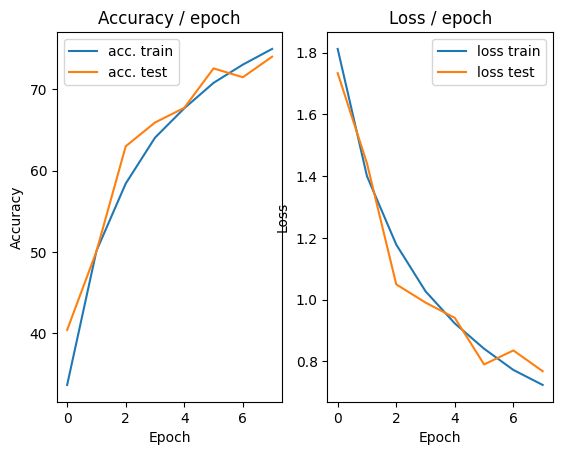

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.195s (0.195s)	Loss 0.7547 (0.7547)	Prec@1  73.4 ( 73.4)	Prec@5  99.2 ( 99.2)


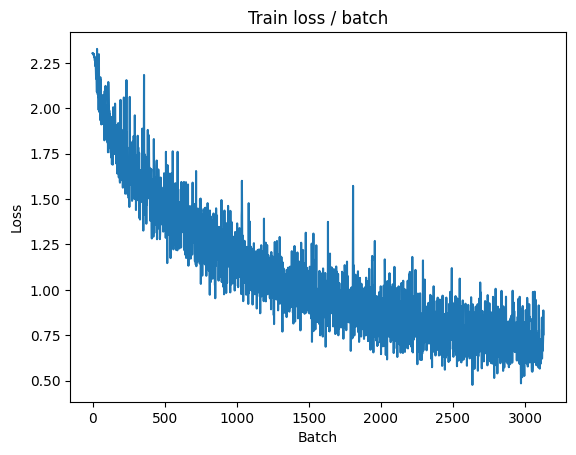

[TRAIN Batch 200/391]	Time 0.088s (0.039s)	Loss 0.6539 (0.6704)	Prec@1  78.9 ( 76.5)	Prec@5  97.7 ( 98.6)


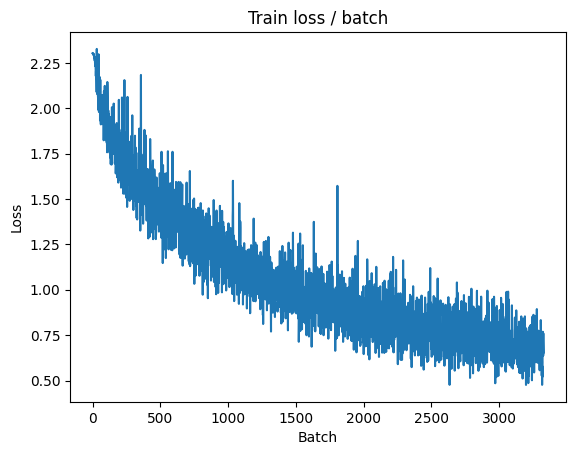


===============> Total time 16s	Avg loss 0.6711	Avg Prec@1 76.59 %	Avg Prec@5 98.60 %

[EVAL Batch 000/079]	Time 0.130s (0.130s)	Loss 0.7531 (0.7531)	Prec@1  73.4 ( 73.4)	Prec@5 100.0 (100.0)

===============> Total time 2s	Avg loss 0.7579	Avg Prec@1 74.13 %	Avg Prec@5 98.29 %



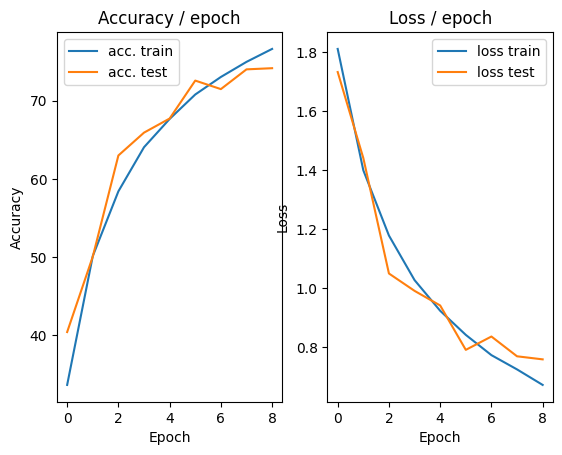

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.176s (0.176s)	Loss 0.6194 (0.6194)	Prec@1  80.5 ( 80.5)	Prec@5  97.7 ( 97.7)


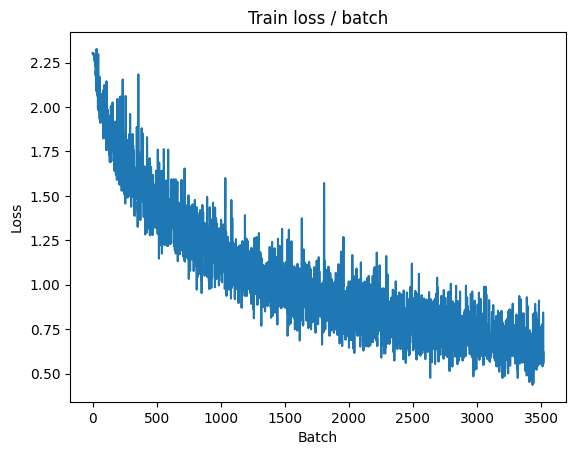

[TRAIN Batch 200/391]	Time 0.011s (0.044s)	Loss 0.5424 (0.6294)	Prec@1  80.5 ( 78.0)	Prec@5  96.9 ( 98.8)


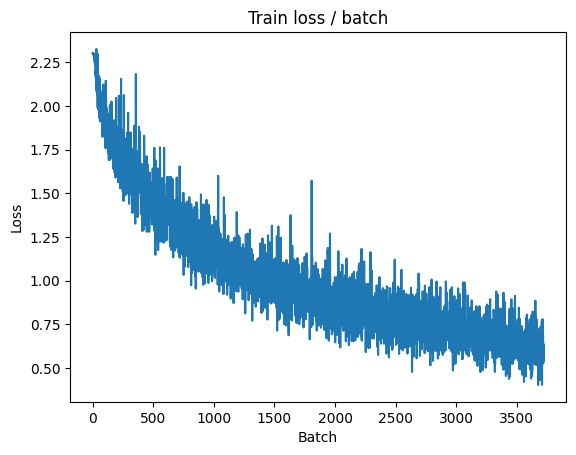


===============> Total time 16s	Avg loss 0.6307	Avg Prec@1 77.97 %	Avg Prec@5 98.77 %

[EVAL Batch 000/079]	Time 0.216s (0.216s)	Loss 0.6468 (0.6468)	Prec@1  78.1 ( 78.1)	Prec@5 100.0 (100.0)

===============> Total time 2s	Avg loss 0.7496	Avg Prec@1 74.09 %	Avg Prec@5 98.29 %



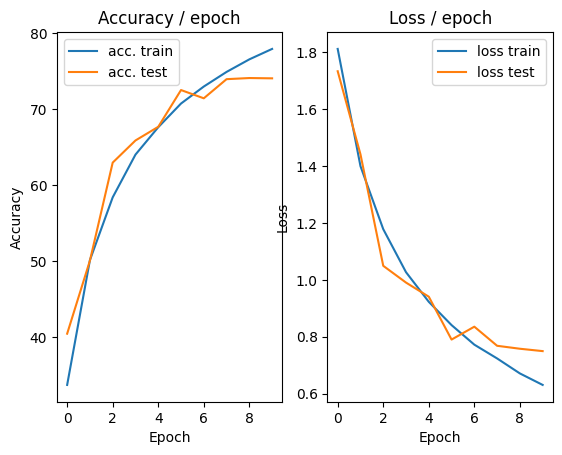

In [38]:
main(128, 0.1, cuda=True)

In [42]:
# Other data augmentation methods ：ColorJitter
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000), # 64 * 4 * 4 = 1024
            nn.ReLU(),
            nn.Linear(1000, 10)
        )

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.CenterCrop(28),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader

def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.05, epochs=10, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)


=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.243s (0.243s)	Loss 2.3043 (2.3043)	Prec@1  13.3 ( 13.3)	Prec@5  50.0 ( 50.0)


<Figure size 640x480 with 0 Axes>

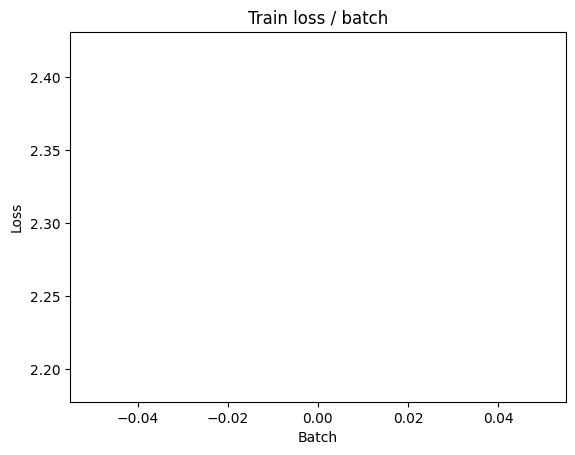

[TRAIN Batch 200/391]	Time 0.015s (0.081s)	Loss 1.7658 (2.0460)	Prec@1  35.2 ( 24.5)	Prec@5  89.8 ( 75.3)


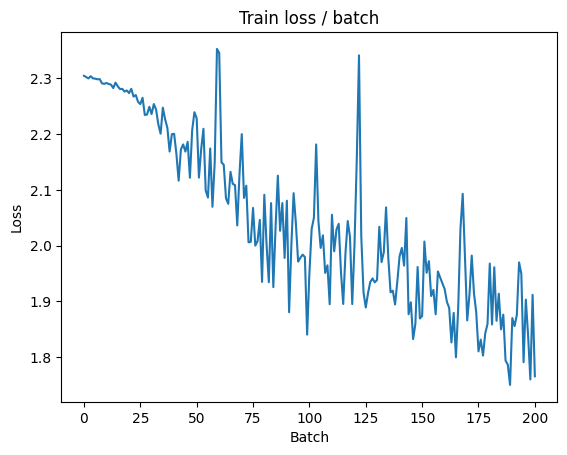


===============> Total time 31s	Avg loss 1.8957	Avg Prec@1 30.81 %	Avg Prec@5 80.98 %

[EVAL Batch 000/079]	Time 0.129s (0.129s)	Loss 1.6865 (1.6865)	Prec@1  35.9 ( 35.9)	Prec@5  89.8 ( 89.8)

===============> Total time 2s	Avg loss 1.7097	Avg Prec@1 36.63 %	Avg Prec@5 88.27 %



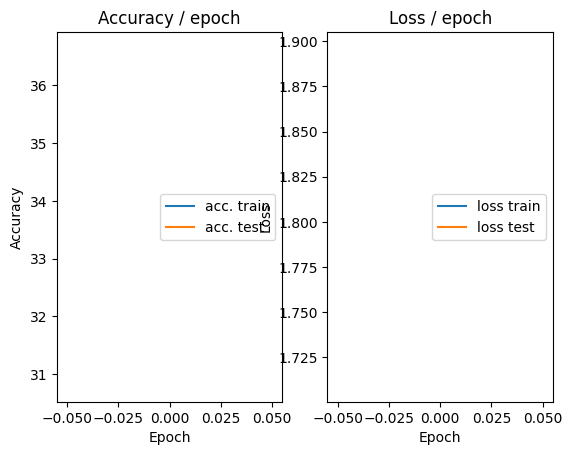

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.407s (0.407s)	Loss 1.7198 (1.7198)	Prec@1  43.0 ( 43.0)	Prec@5  87.5 ( 87.5)


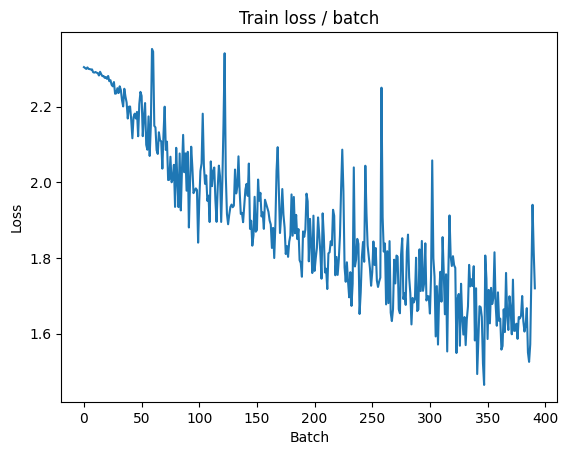

[TRAIN Batch 200/391]	Time 0.075s (0.085s)	Loss 1.4717 (1.5564)	Prec@1  49.2 ( 44.4)	Prec@5  89.1 ( 90.9)


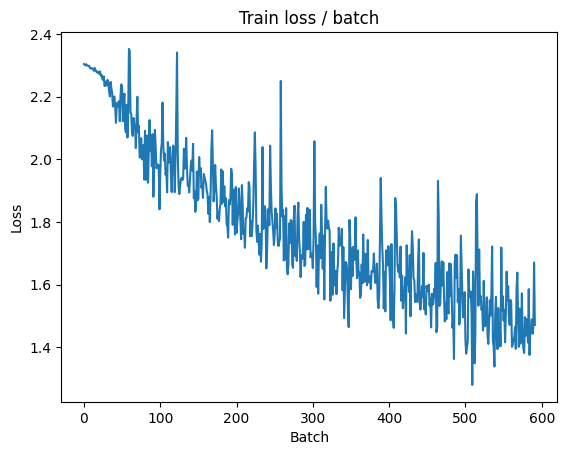


===============> Total time 33s	Avg loss 1.4996	Avg Prec@1 46.83 %	Avg Prec@5 91.71 %

[EVAL Batch 000/079]	Time 0.128s (0.128s)	Loss 1.4396 (1.4396)	Prec@1  47.7 ( 47.7)	Prec@5  93.0 ( 93.0)

===============> Total time 2s	Avg loss 1.4357	Avg Prec@1 48.00 %	Avg Prec@5 92.24 %



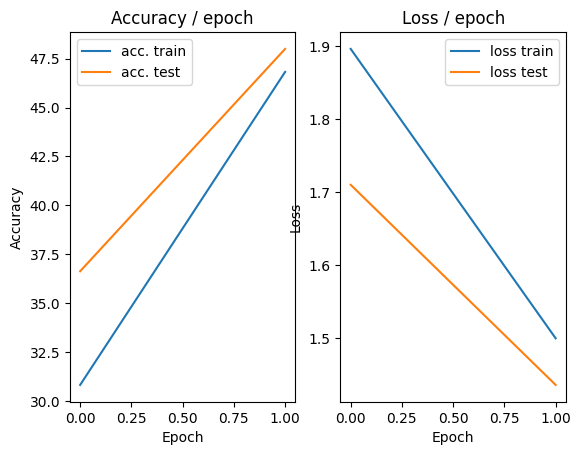

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.254s (0.254s)	Loss 1.3464 (1.3464)	Prec@1  53.1 ( 53.1)	Prec@5  95.3 ( 95.3)


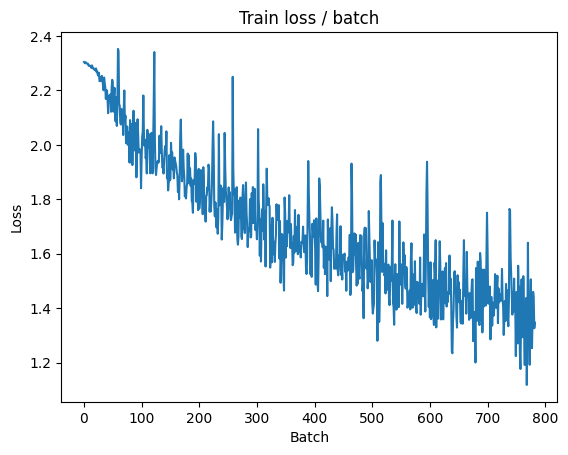

[TRAIN Batch 200/391]	Time 0.013s (0.088s)	Loss 1.2878 (1.3336)	Prec@1  53.9 ( 53.1)	Prec@5  95.3 ( 94.0)


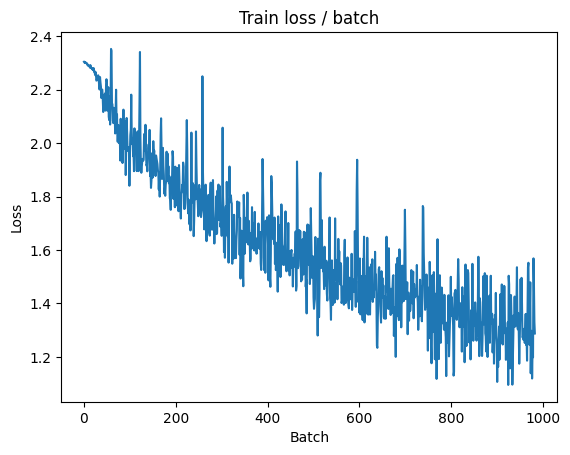


===============> Total time 33s	Avg loss 1.2875	Avg Prec@1 54.96 %	Avg Prec@5 94.41 %

[EVAL Batch 000/079]	Time 0.130s (0.130s)	Loss 1.5122 (1.5122)	Prec@1  50.0 ( 50.0)	Prec@5  93.0 ( 93.0)

===============> Total time 2s	Avg loss 1.4944	Avg Prec@1 46.73 %	Avg Prec@5 92.90 %



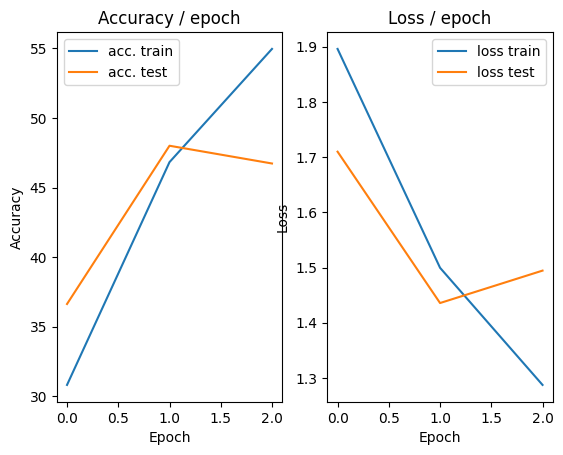

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.237s (0.237s)	Loss 1.2865 (1.2865)	Prec@1  51.6 ( 51.6)	Prec@5  97.7 ( 97.7)


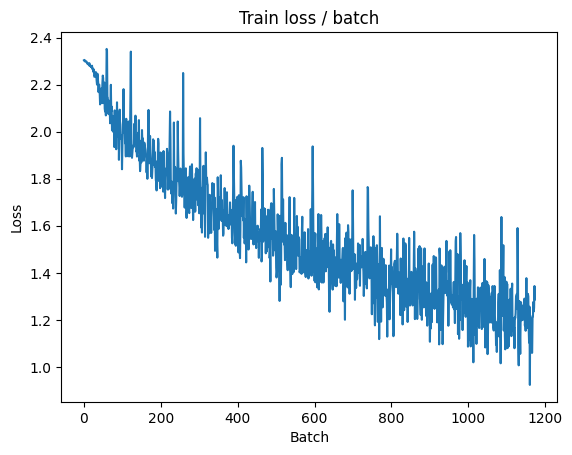

[TRAIN Batch 200/391]	Time 0.067s (0.082s)	Loss 0.9739 (1.1615)	Prec@1  67.2 ( 59.7)	Prec@5  98.4 ( 95.5)


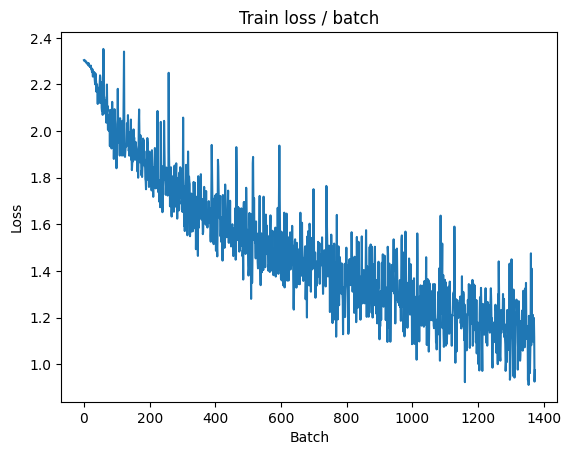


===============> Total time 32s	Avg loss 1.1321	Avg Prec@1 60.86 %	Avg Prec@5 95.77 %

[EVAL Batch 000/079]	Time 0.135s (0.135s)	Loss 1.2020 (1.2020)	Prec@1  60.2 ( 60.2)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 1.2165	Avg Prec@1 57.25 %	Avg Prec@5 95.38 %



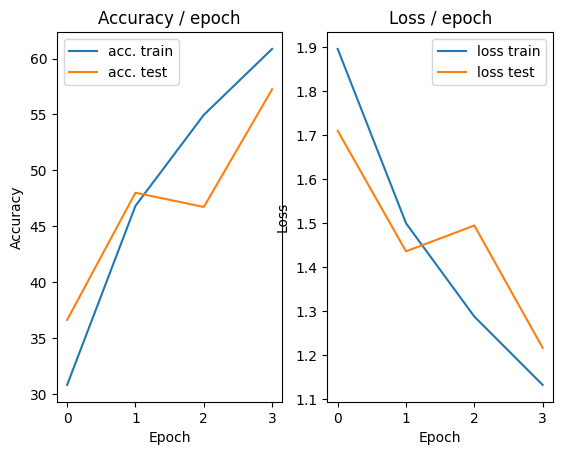

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.234s (0.234s)	Loss 1.0019 (1.0019)	Prec@1  62.5 ( 62.5)	Prec@5  99.2 ( 99.2)


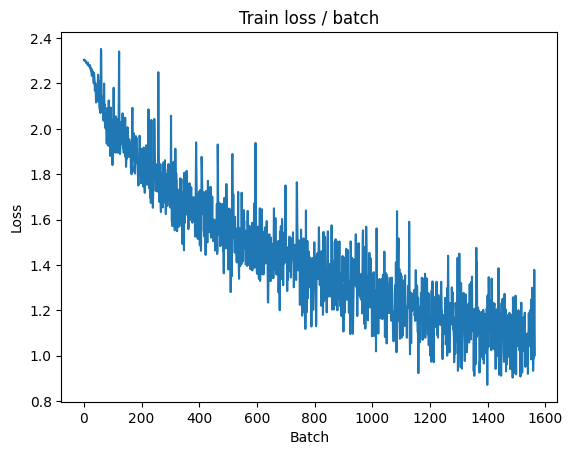

[TRAIN Batch 200/391]	Time 0.014s (0.082s)	Loss 0.9680 (1.0204)	Prec@1  67.2 ( 64.7)	Prec@5  99.2 ( 96.6)


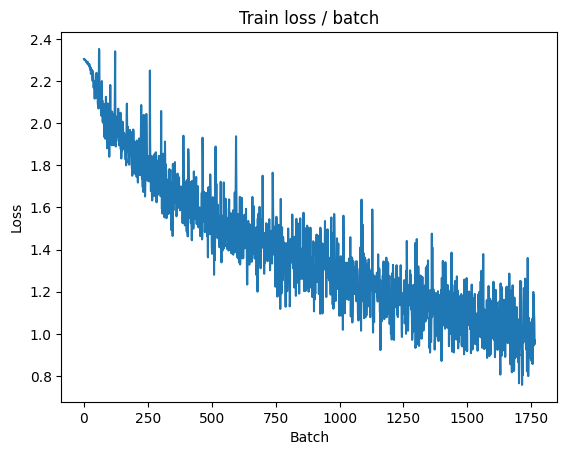


===============> Total time 31s	Avg loss 1.0053	Avg Prec@1 65.12 %	Avg Prec@5 96.81 %

[EVAL Batch 000/079]	Time 0.131s (0.131s)	Loss 1.2521 (1.2521)	Prec@1  54.7 ( 54.7)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 1.2365	Avg Prec@1 56.79 %	Avg Prec@5 95.21 %



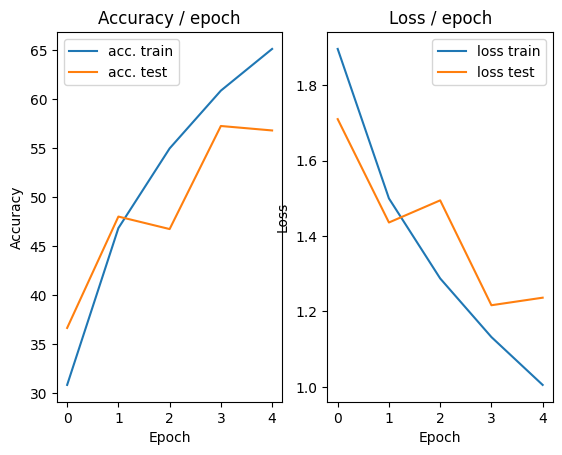

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.371s (0.371s)	Loss 1.1207 (1.1207)	Prec@1  57.0 ( 57.0)	Prec@5  96.9 ( 96.9)


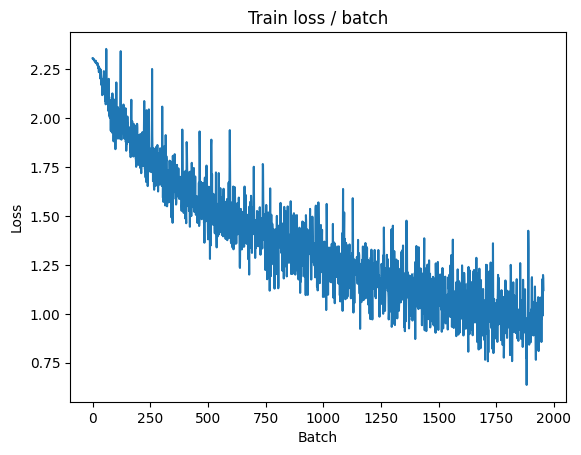

[TRAIN Batch 200/391]	Time 0.142s (0.085s)	Loss 0.9450 (0.9174)	Prec@1  65.6 ( 68.4)	Prec@5  97.7 ( 97.4)


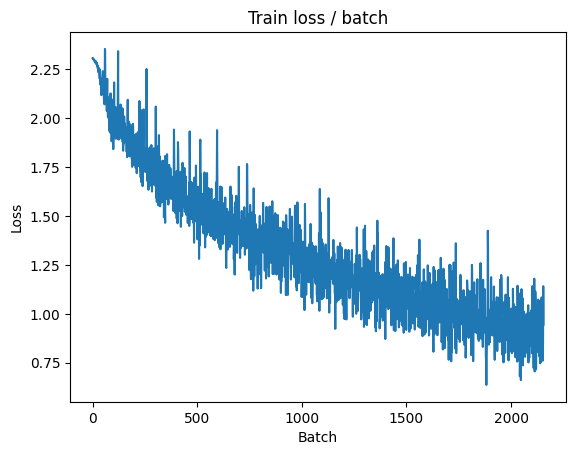


===============> Total time 32s	Avg loss 0.9030	Avg Prec@1 68.87 %	Avg Prec@5 97.44 %

[EVAL Batch 000/079]	Time 0.135s (0.135s)	Loss 1.0132 (1.0132)	Prec@1  63.3 ( 63.3)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 1.0912	Avg Prec@1 61.17 %	Avg Prec@5 96.21 %



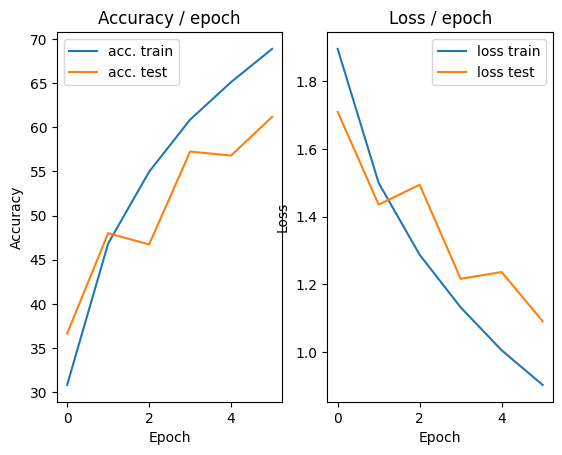

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.284s (0.284s)	Loss 0.7878 (0.7878)	Prec@1  77.3 ( 77.3)	Prec@5  97.7 ( 97.7)


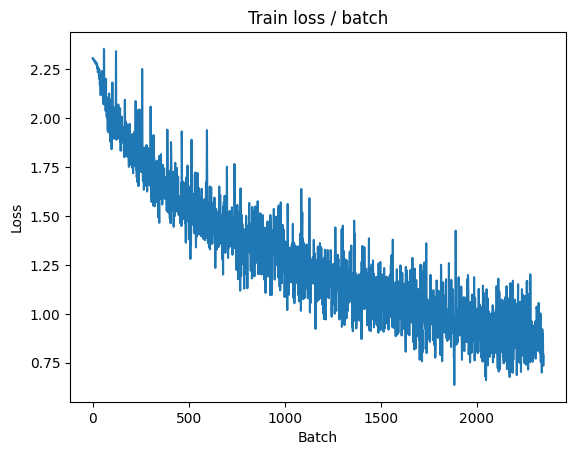

[TRAIN Batch 200/391]	Time 0.128s (0.087s)	Loss 0.9787 (0.8128)	Prec@1  65.6 ( 72.1)	Prec@5  99.2 ( 98.0)


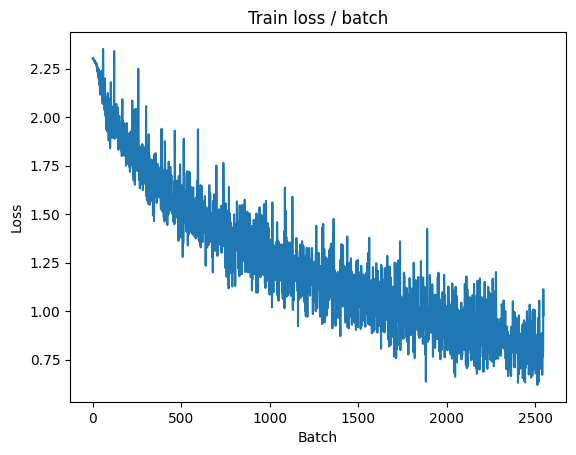


===============> Total time 33s	Avg loss 0.8057	Avg Prec@1 72.24 %	Avg Prec@5 97.96 %

[EVAL Batch 000/079]	Time 0.129s (0.129s)	Loss 1.0031 (1.0031)	Prec@1  65.6 ( 65.6)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 1.0597	Avg Prec@1 63.03 %	Avg Prec@5 95.98 %



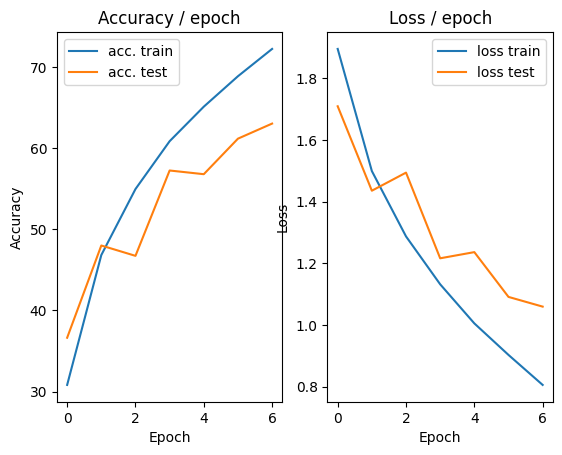

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.265s (0.265s)	Loss 0.8149 (0.8149)	Prec@1  70.3 ( 70.3)	Prec@5  96.9 ( 96.9)


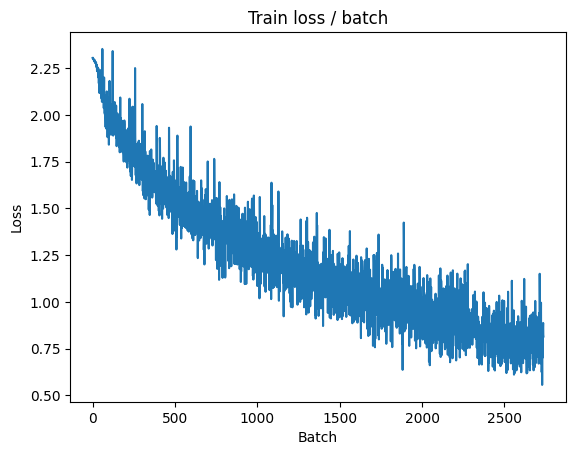

[TRAIN Batch 200/391]	Time 0.133s (0.083s)	Loss 0.6545 (0.7261)	Prec@1  75.0 ( 75.1)	Prec@5 100.0 ( 98.4)


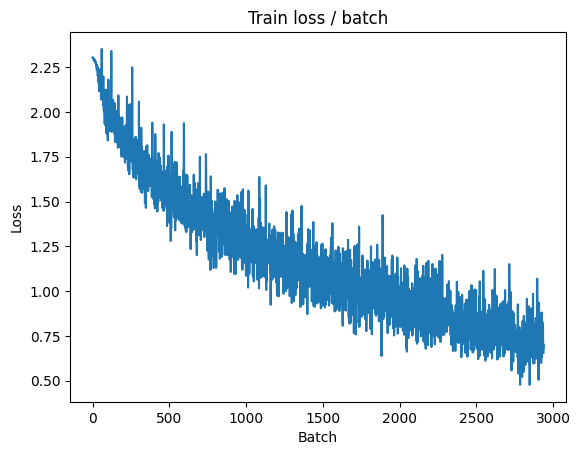


===============> Total time 33s	Avg loss 0.7232	Avg Prec@1 75.11 %	Avg Prec@5 98.48 %

[EVAL Batch 000/079]	Time 0.140s (0.140s)	Loss 1.0653 (1.0653)	Prec@1  64.8 ( 64.8)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 1.0896	Avg Prec@1 62.80 %	Avg Prec@5 96.00 %



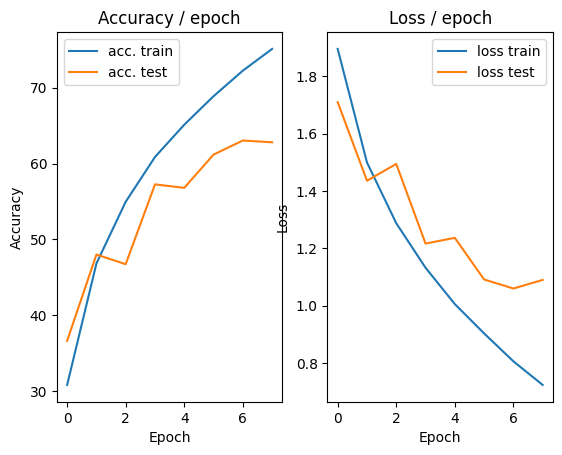

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.260s (0.260s)	Loss 0.6427 (0.6427)	Prec@1  79.7 ( 79.7)	Prec@5  98.4 ( 98.4)


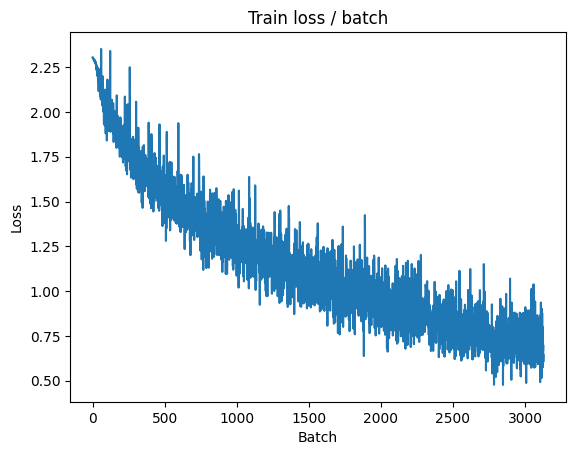

[TRAIN Batch 200/391]	Time 0.142s (0.083s)	Loss 0.7292 (0.6404)	Prec@1  73.4 ( 77.9)	Prec@5  99.2 ( 98.8)


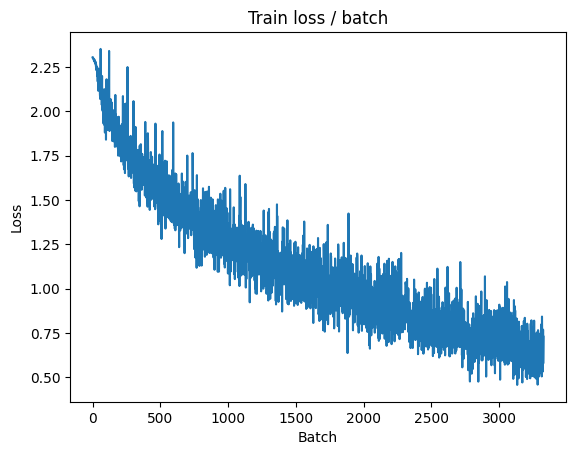


===============> Total time 32s	Avg loss 0.6434	Avg Prec@1 77.87 %	Avg Prec@5 98.78 %

[EVAL Batch 000/079]	Time 0.146s (0.146s)	Loss 0.8732 (0.8732)	Prec@1  71.9 ( 71.9)	Prec@5  96.1 ( 96.1)

===============> Total time 3s	Avg loss 1.0220	Avg Prec@1 64.62 %	Avg Prec@5 96.54 %



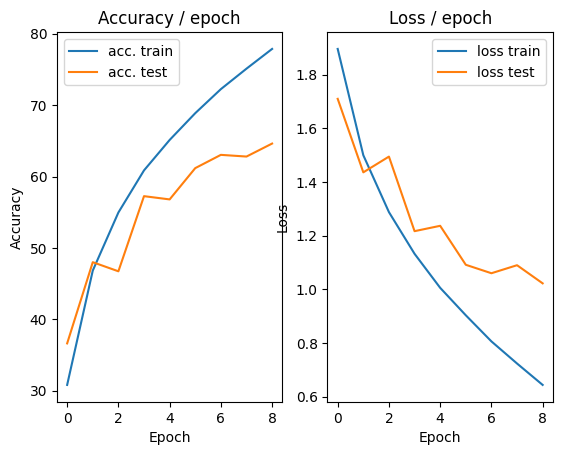

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.253s (0.253s)	Loss 0.7127 (0.7127)	Prec@1  73.4 ( 73.4)	Prec@5  97.7 ( 97.7)


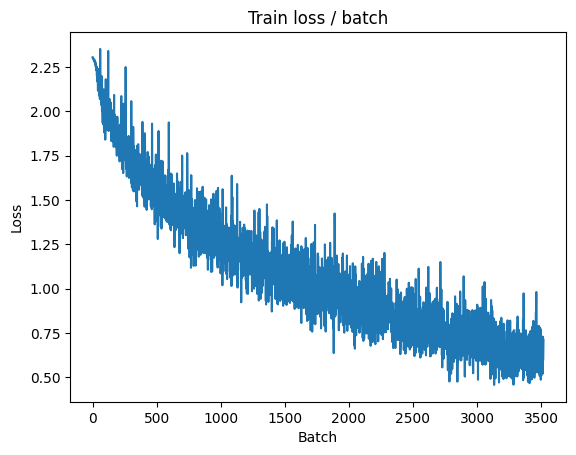

[TRAIN Batch 200/391]	Time 0.138s (0.087s)	Loss 0.4934 (0.5655)	Prec@1  85.9 ( 80.6)	Prec@5 100.0 ( 99.1)


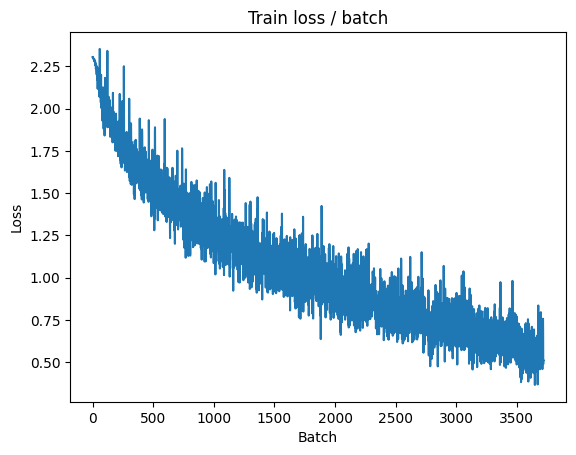


===============> Total time 32s	Avg loss 0.5750	Avg Prec@1 80.19 %	Avg Prec@5 99.05 %

[EVAL Batch 000/079]	Time 0.142s (0.142s)	Loss 0.9303 (0.9303)	Prec@1  71.9 ( 71.9)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 1.0568	Avg Prec@1 64.70 %	Avg Prec@5 96.52 %



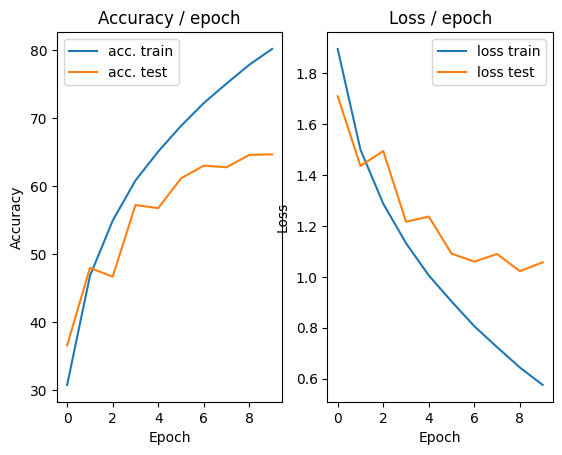

In [43]:
main(128, 0.05, cuda=True)

In [44]:
# Other data augmentation methods ：RandomRotation
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000), # 64 * 4 * 4 = 1024
            nn.ReLU(),
            nn.Linear(1000, 10)
        )

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.RandomCrop(28),
        transforms.RandomRotation(degrees=15),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.CenterCrop(28),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader

def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=15, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot¥
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)


=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.307s (0.307s)	Loss 2.3075 (2.3075)	Prec@1   7.0 (  7.0)	Prec@5  53.9 ( 53.9)


<Figure size 640x480 with 0 Axes>

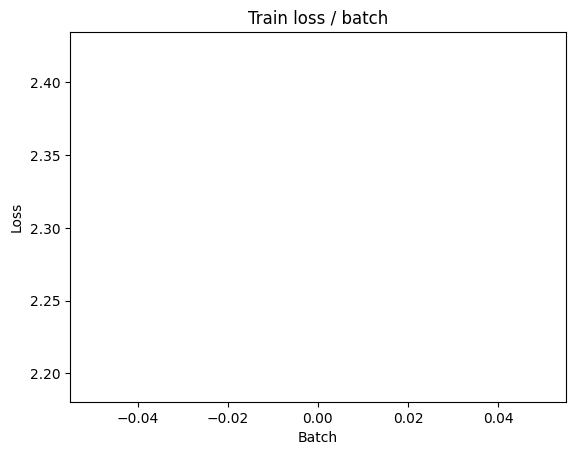

[TRAIN Batch 200/391]	Time 0.010s (0.048s)	Loss 1.8494 (1.9975)	Prec@1  30.5 ( 26.4)	Prec@5  82.0 ( 77.2)


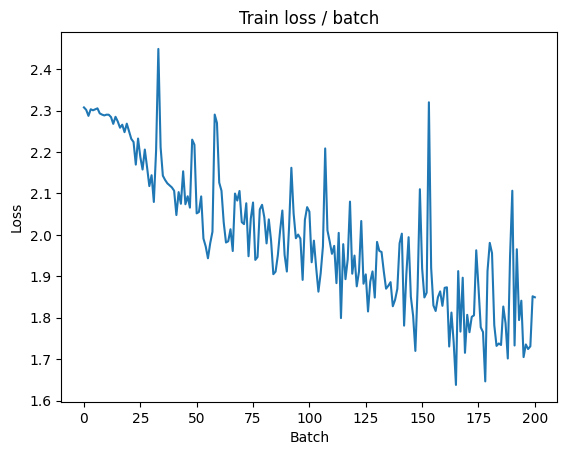


===============> Total time 17s	Avg loss 1.8467	Avg Prec@1 32.67 %	Avg Prec@5 82.59 %

[EVAL Batch 000/079]	Time 0.126s (0.126s)	Loss 1.4668 (1.4668)	Prec@1  49.2 ( 49.2)	Prec@5  90.6 ( 90.6)

===============> Total time 3s	Avg loss 1.5089	Avg Prec@1 44.67 %	Avg Prec@5 92.37 %



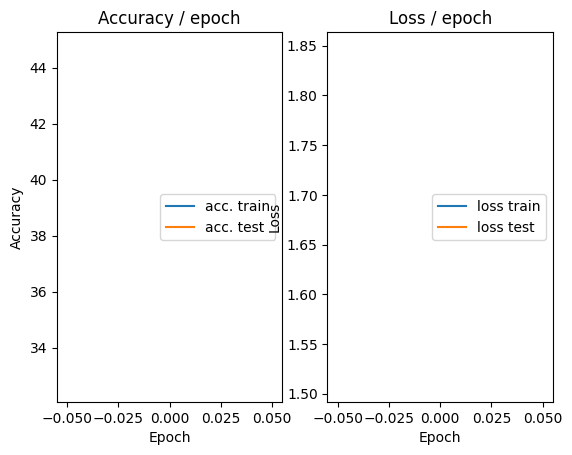

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.163s (0.163s)	Loss 1.5710 (1.5710)	Prec@1  39.1 ( 39.1)	Prec@5  94.5 ( 94.5)


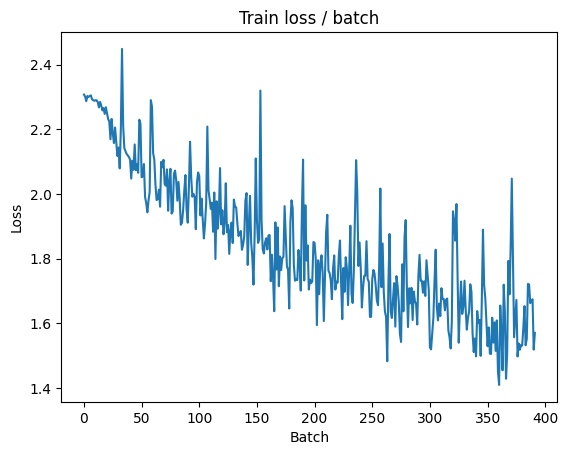

[TRAIN Batch 200/391]	Time 0.041s (0.043s)	Loss 1.4170 (1.5178)	Prec@1  46.1 ( 45.3)	Prec@5  93.0 ( 91.4)


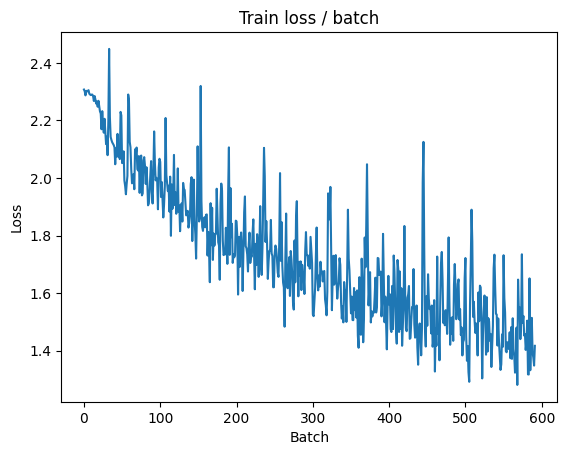


===============> Total time 17s	Avg loss 1.4771	Avg Prec@1 46.97 %	Avg Prec@5 92.01 %

[EVAL Batch 000/079]	Time 0.128s (0.128s)	Loss 1.4684 (1.4684)	Prec@1  49.2 ( 49.2)	Prec@5  90.6 ( 90.6)

===============> Total time 2s	Avg loss 1.4802	Avg Prec@1 48.35 %	Avg Prec@5 91.22 %



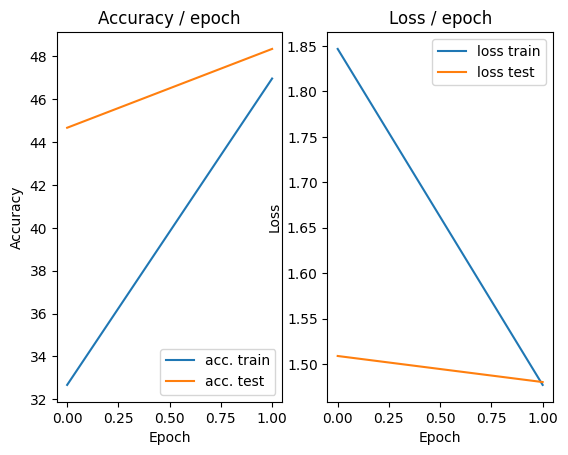

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.187s (0.187s)	Loss 1.5773 (1.5773)	Prec@1  43.8 ( 43.8)	Prec@5  92.2 ( 92.2)


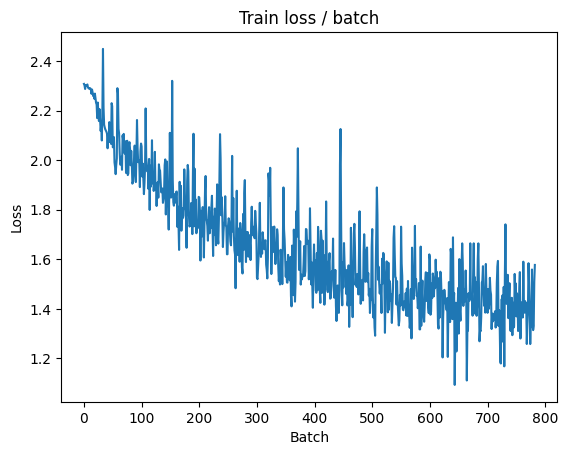

[TRAIN Batch 200/391]	Time 0.011s (0.048s)	Loss 1.2761 (1.3203)	Prec@1  55.5 ( 53.0)	Prec@5  96.9 ( 94.0)


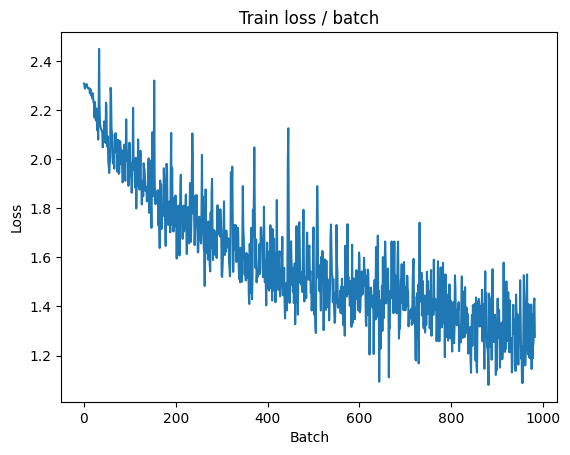


===============> Total time 19s	Avg loss 1.2982	Avg Prec@1 53.64 %	Avg Prec@5 94.26 %

[EVAL Batch 000/079]	Time 0.132s (0.132s)	Loss 1.1887 (1.1887)	Prec@1  59.4 ( 59.4)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 1.2695	Avg Prec@1 55.61 %	Avg Prec@5 94.10 %



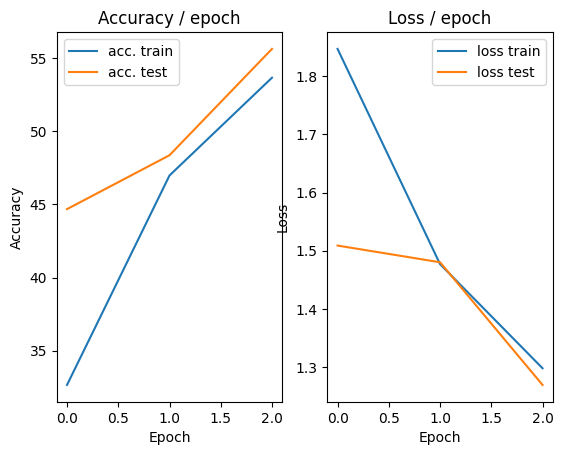

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.241s (0.241s)	Loss 1.4049 (1.4049)	Prec@1  49.2 ( 49.2)	Prec@5  91.4 ( 91.4)


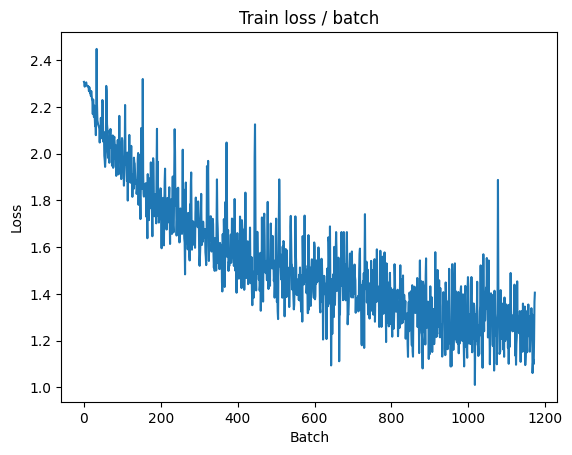

[TRAIN Batch 200/391]	Time 0.015s (0.050s)	Loss 1.1456 (1.1979)	Prec@1  58.6 ( 57.5)	Prec@5  96.1 ( 95.1)


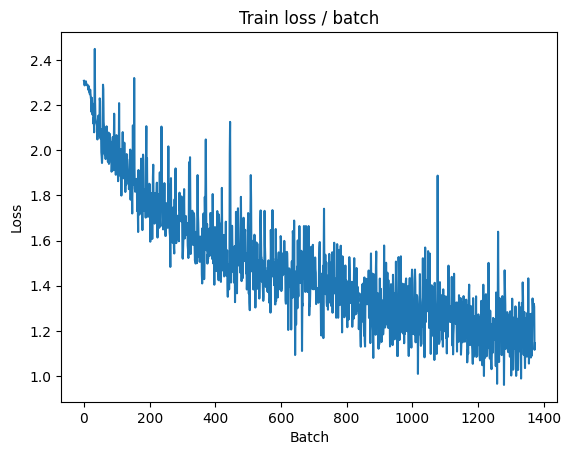


===============> Total time 18s	Avg loss 1.1725	Avg Prec@1 58.55 %	Avg Prec@5 95.31 %

[EVAL Batch 000/079]	Time 0.131s (0.131s)	Loss 1.0461 (1.0461)	Prec@1  60.9 ( 60.9)	Prec@5  96.9 ( 96.9)

===============> Total time 3s	Avg loss 1.1246	Avg Prec@1 60.32 %	Avg Prec@5 95.98 %



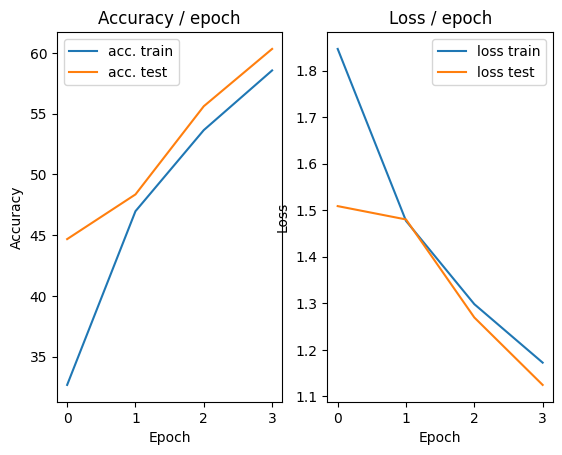

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.178s (0.178s)	Loss 1.0868 (1.0868)	Prec@1  60.9 ( 60.9)	Prec@5  96.1 ( 96.1)


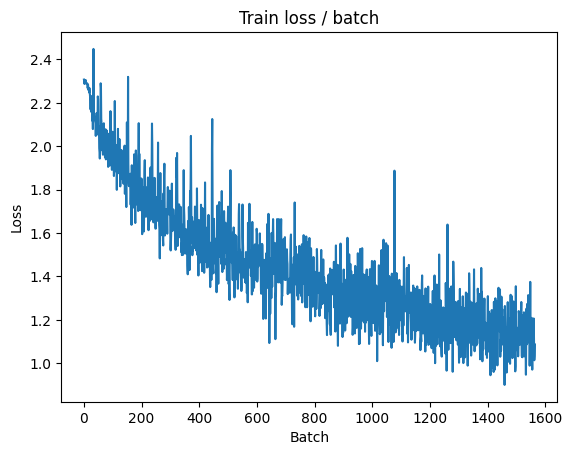

[TRAIN Batch 200/391]	Time 0.073s (0.044s)	Loss 0.9448 (1.0755)	Prec@1  64.1 ( 62.0)	Prec@5  98.4 ( 96.2)


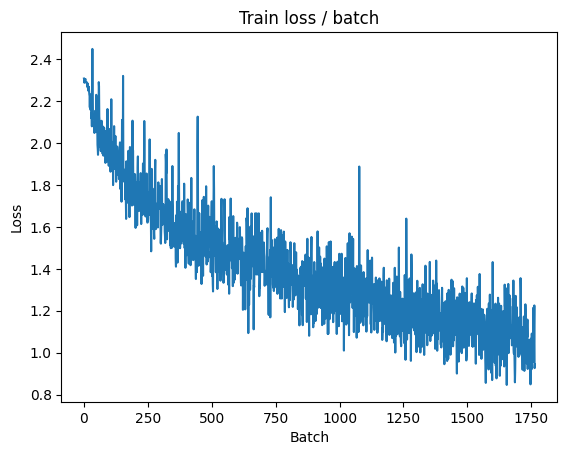


===============> Total time 17s	Avg loss 1.0693	Avg Prec@1 62.38 %	Avg Prec@5 96.27 %

[EVAL Batch 000/079]	Time 0.123s (0.123s)	Loss 0.9960 (0.9960)	Prec@1  63.3 ( 63.3)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 1.0198	Avg Prec@1 64.40 %	Avg Prec@5 96.27 %



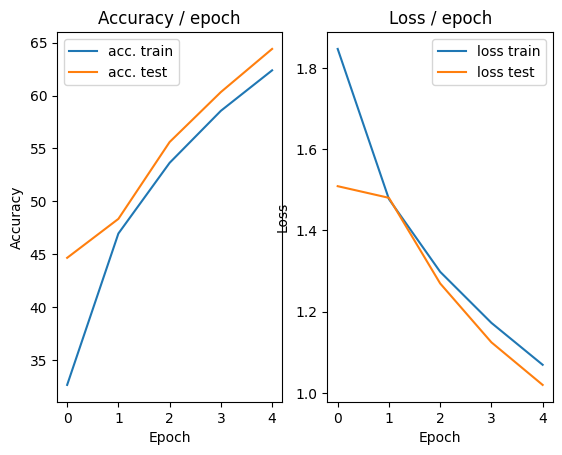

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.176s (0.176s)	Loss 0.8383 (0.8383)	Prec@1  73.4 ( 73.4)	Prec@5  98.4 ( 98.4)


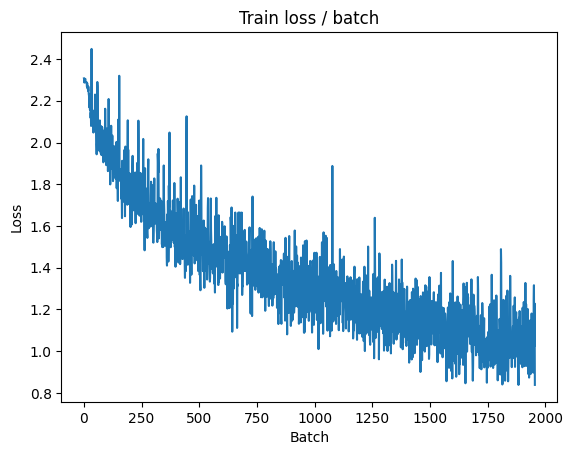

[TRAIN Batch 200/391]	Time 0.012s (0.049s)	Loss 0.8841 (0.9905)	Prec@1  66.4 ( 65.1)	Prec@5  96.9 ( 96.8)


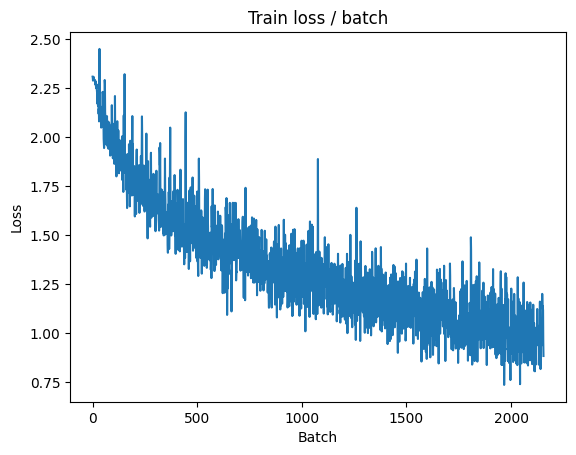


===============> Total time 18s	Avg loss 0.9799	Avg Prec@1 65.71 %	Avg Prec@5 96.83 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 0.8888 (0.8888)	Prec@1  71.1 ( 71.1)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.9078	Avg Prec@1 67.99 %	Avg Prec@5 97.31 %



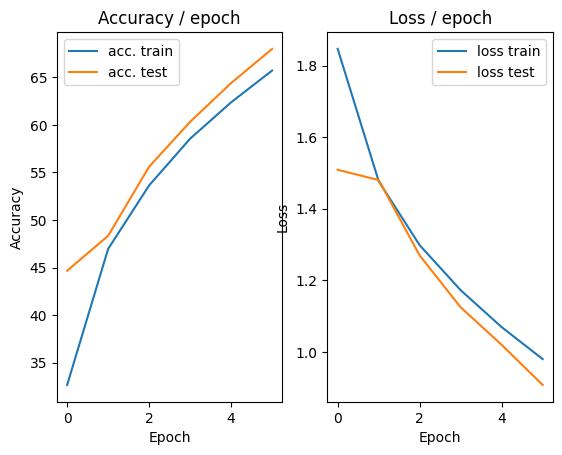

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.174s (0.174s)	Loss 0.8955 (0.8955)	Prec@1  71.1 ( 71.1)	Prec@5  97.7 ( 97.7)


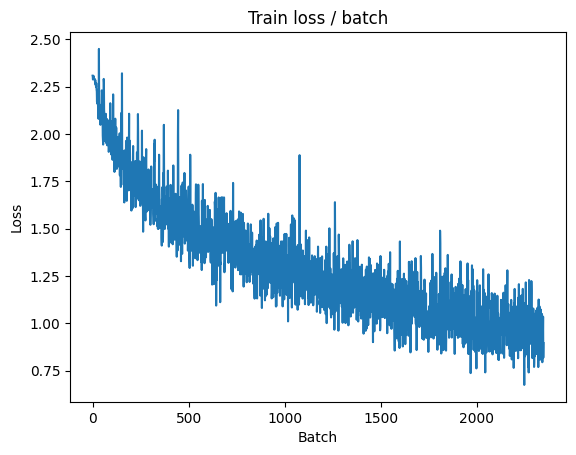

[TRAIN Batch 200/391]	Time 0.048s (0.049s)	Loss 0.9315 (0.9071)	Prec@1  64.1 ( 68.5)	Prec@5  96.9 ( 97.3)


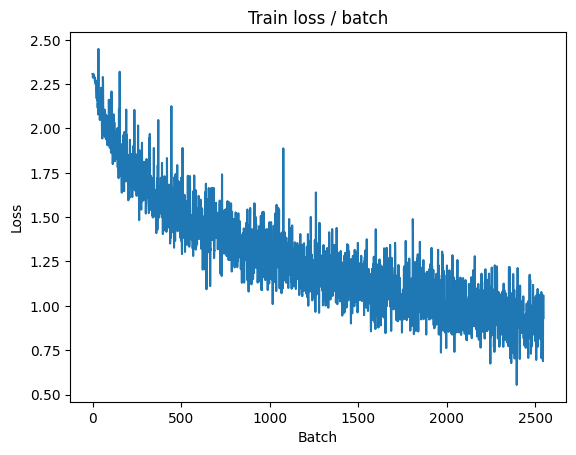


===============> Total time 18s	Avg loss 0.9038	Avg Prec@1 68.45 %	Avg Prec@5 97.45 %

[EVAL Batch 000/079]	Time 0.147s (0.147s)	Loss 0.9543 (0.9543)	Prec@1  70.3 ( 70.3)	Prec@5  97.7 ( 97.7)

===============> Total time 3s	Avg loss 0.9358	Avg Prec@1 68.15 %	Avg Prec@5 97.16 %



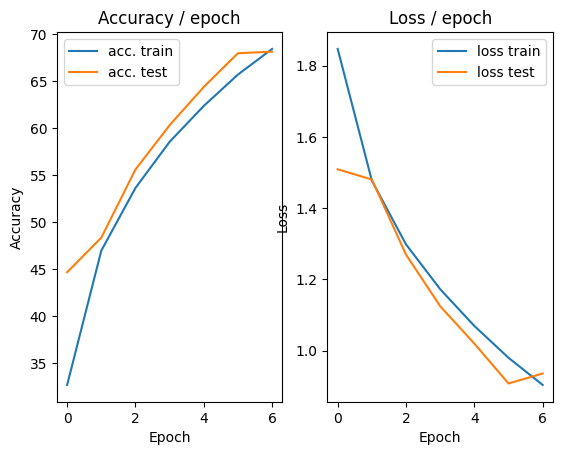

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.176s (0.176s)	Loss 0.7333 (0.7333)	Prec@1  72.7 ( 72.7)	Prec@5  98.4 ( 98.4)


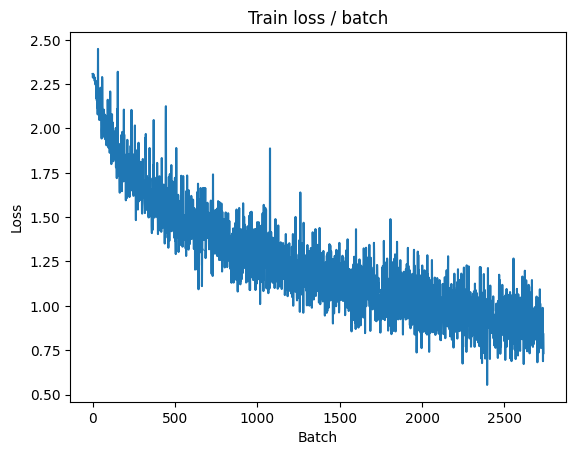

[TRAIN Batch 200/391]	Time 0.063s (0.045s)	Loss 0.8402 (0.8499)	Prec@1  68.0 ( 70.4)	Prec@5  98.4 ( 97.8)


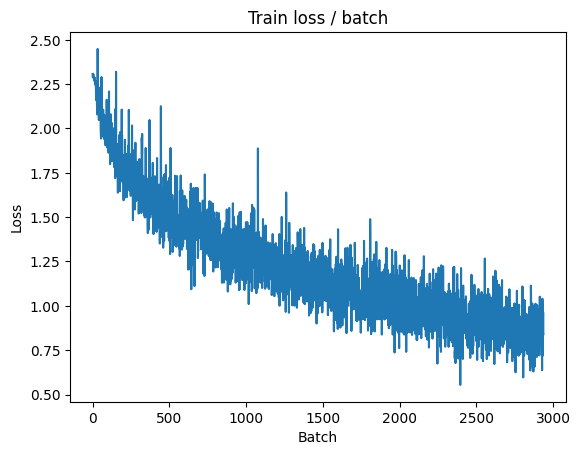


===============> Total time 17s	Avg loss 0.8473	Avg Prec@1 70.47 %	Avg Prec@5 97.79 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 0.9028 (0.9028)	Prec@1  71.9 ( 71.9)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.8971	Avg Prec@1 68.72 %	Avg Prec@5 97.68 %



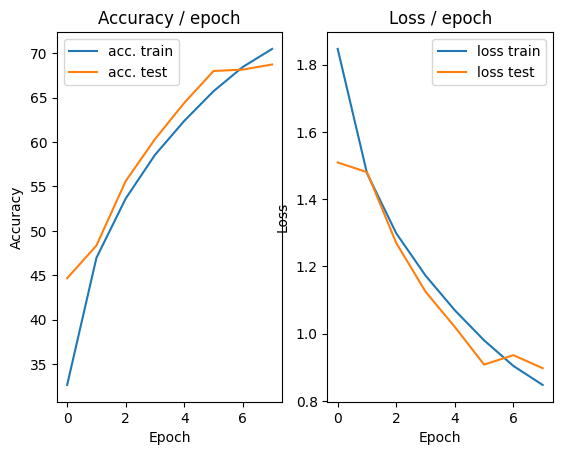

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.173s (0.173s)	Loss 1.0131 (1.0131)	Prec@1  64.1 ( 64.1)	Prec@5  96.9 ( 96.9)


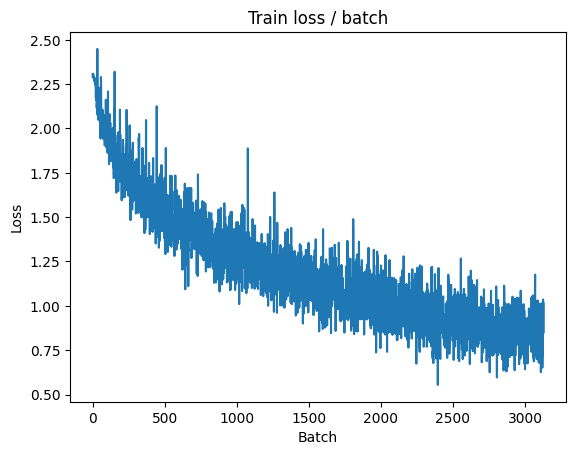

[TRAIN Batch 200/391]	Time 0.071s (0.049s)	Loss 0.9794 (0.8035)	Prec@1  64.1 ( 71.8)	Prec@5  96.9 ( 98.1)


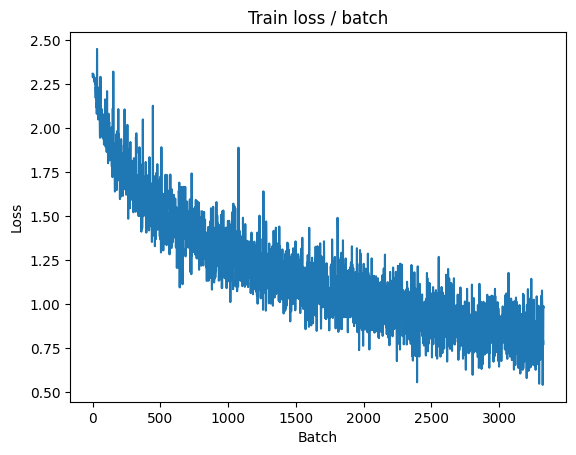


===============> Total time 18s	Avg loss 0.8002	Avg Prec@1 71.91 %	Avg Prec@5 98.13 %

[EVAL Batch 000/079]	Time 0.135s (0.135s)	Loss 0.8881 (0.8881)	Prec@1  70.3 ( 70.3)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.8631	Avg Prec@1 70.46 %	Avg Prec@5 97.63 %



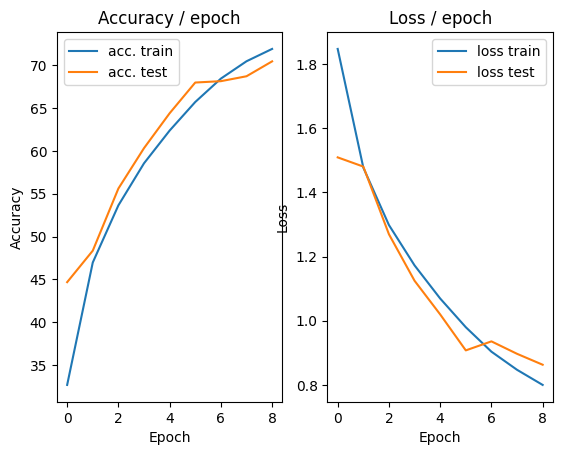

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.186s (0.186s)	Loss 0.9863 (0.9863)	Prec@1  59.4 ( 59.4)	Prec@5  94.5 ( 94.5)


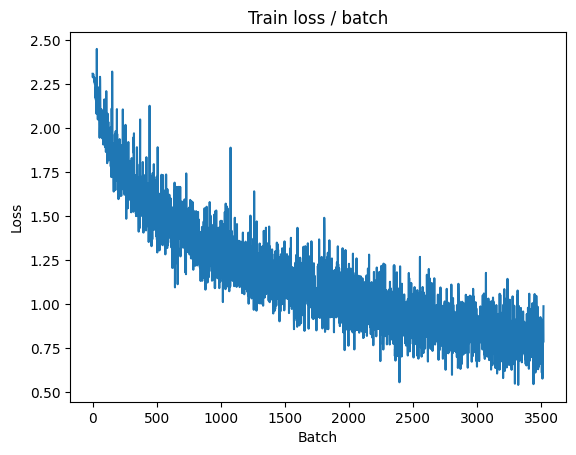

[TRAIN Batch 200/391]	Time 0.091s (0.050s)	Loss 0.8156 (0.7624)	Prec@1  74.2 ( 73.1)	Prec@5  98.4 ( 98.2)


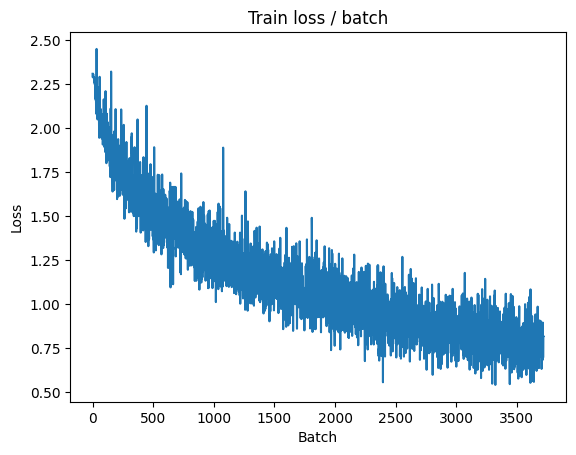


===============> Total time 18s	Avg loss 0.7566	Avg Prec@1 73.59 %	Avg Prec@5 98.24 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 0.8736 (0.8736)	Prec@1  75.0 ( 75.0)	Prec@5  96.9 ( 96.9)

===============> Total time 3s	Avg loss 0.8044	Avg Prec@1 73.13 %	Avg Prec@5 97.81 %



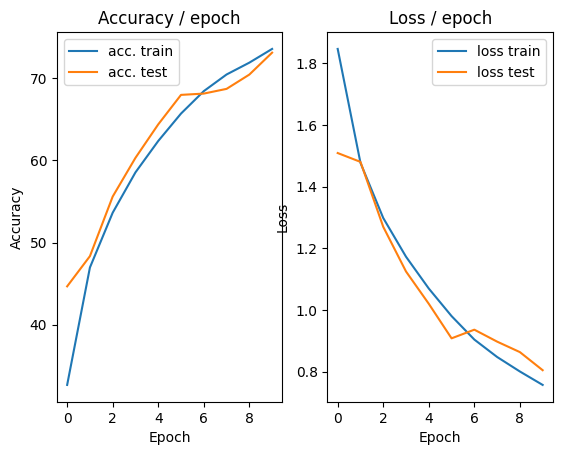

=== EPOCH 11 =====

[TRAIN Batch 000/391]	Time 0.200s (0.200s)	Loss 0.5802 (0.5802)	Prec@1  76.6 ( 76.6)	Prec@5  99.2 ( 99.2)


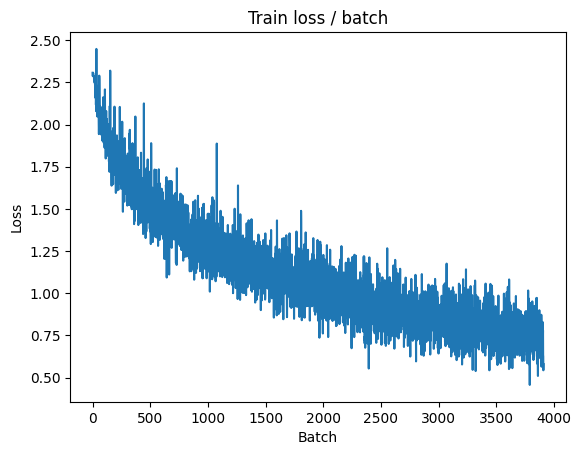

[TRAIN Batch 200/391]	Time 0.010s (0.044s)	Loss 0.7071 (0.7088)	Prec@1  78.9 ( 75.1)	Prec@5  97.7 ( 98.6)


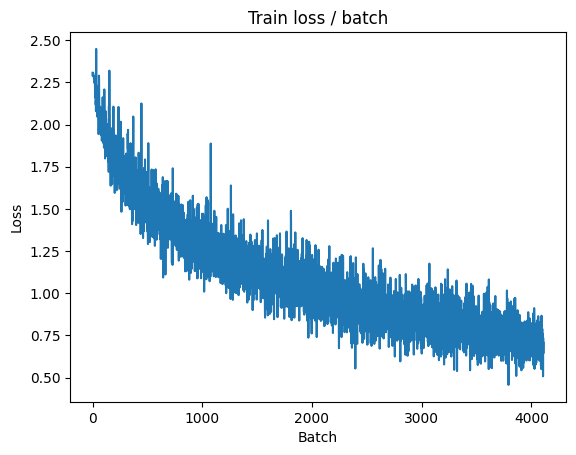


===============> Total time 18s	Avg loss 0.7188	Avg Prec@1 74.73 %	Avg Prec@5 98.48 %

[EVAL Batch 000/079]	Time 0.141s (0.141s)	Loss 0.7964 (0.7964)	Prec@1  68.8 ( 68.8)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.8075	Avg Prec@1 72.67 %	Avg Prec@5 98.01 %



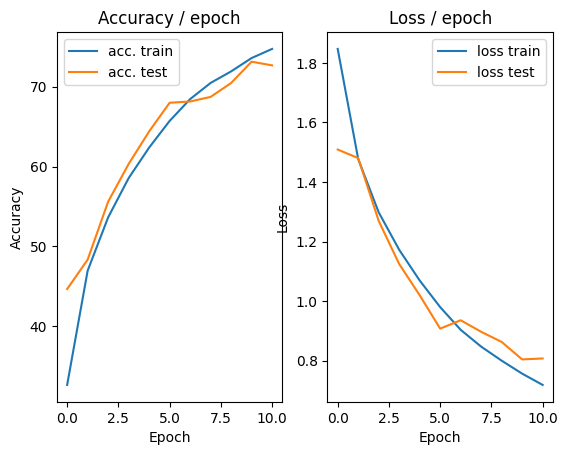

=== EPOCH 12 =====

[TRAIN Batch 000/391]	Time 0.220s (0.220s)	Loss 0.8129 (0.8129)	Prec@1  76.6 ( 76.6)	Prec@5  97.7 ( 97.7)


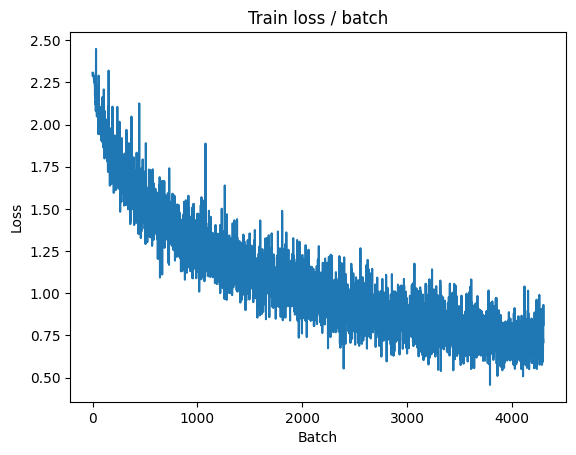

[TRAIN Batch 200/391]	Time 0.078s (0.050s)	Loss 0.7201 (0.6691)	Prec@1  76.6 ( 76.6)	Prec@5  97.7 ( 98.8)


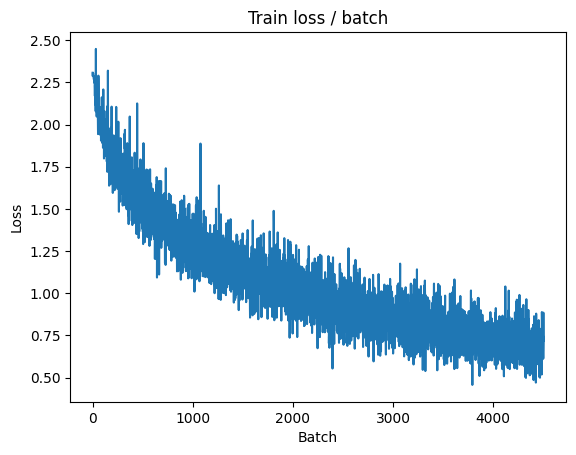


===============> Total time 19s	Avg loss 0.6805	Avg Prec@1 76.19 %	Avg Prec@5 98.74 %

[EVAL Batch 000/079]	Time 0.155s (0.155s)	Loss 0.8733 (0.8733)	Prec@1  78.1 ( 78.1)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.8292	Avg Prec@1 72.17 %	Avg Prec@5 97.77 %



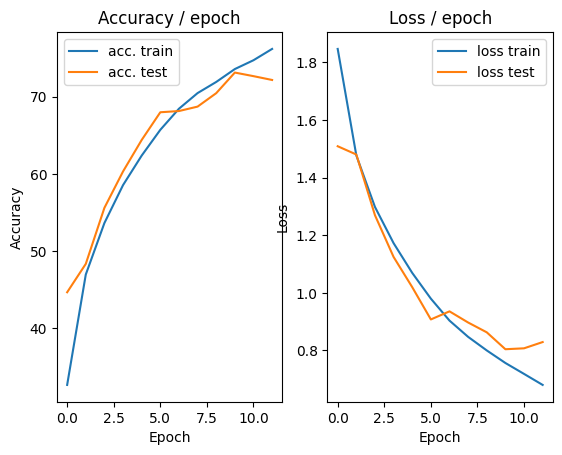

=== EPOCH 13 =====

[TRAIN Batch 000/391]	Time 0.194s (0.194s)	Loss 0.6656 (0.6656)	Prec@1  78.9 ( 78.9)	Prec@5  96.9 ( 96.9)


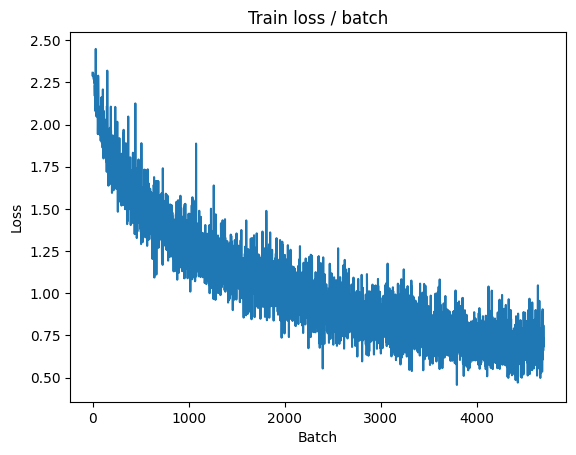

[TRAIN Batch 200/391]	Time 0.015s (0.049s)	Loss 0.9215 (0.6427)	Prec@1  71.1 ( 77.6)	Prec@5  96.9 ( 98.9)


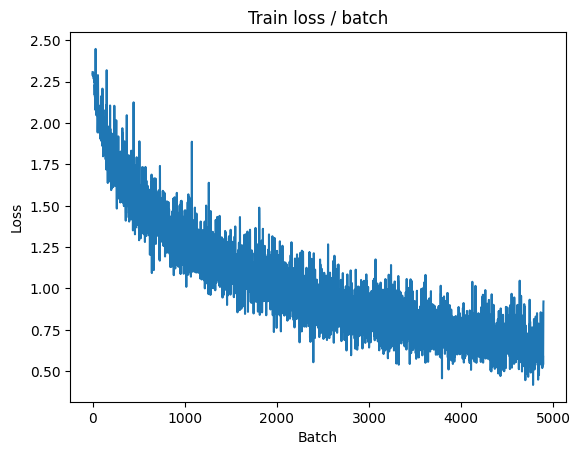


===============> Total time 17s	Avg loss 0.6445	Avg Prec@1 77.45 %	Avg Prec@5 98.89 %

[EVAL Batch 000/079]	Time 0.148s (0.148s)	Loss 0.8920 (0.8920)	Prec@1  69.5 ( 69.5)	Prec@5  97.7 ( 97.7)

===============> Total time 3s	Avg loss 0.7963	Avg Prec@1 73.42 %	Avg Prec@5 97.85 %



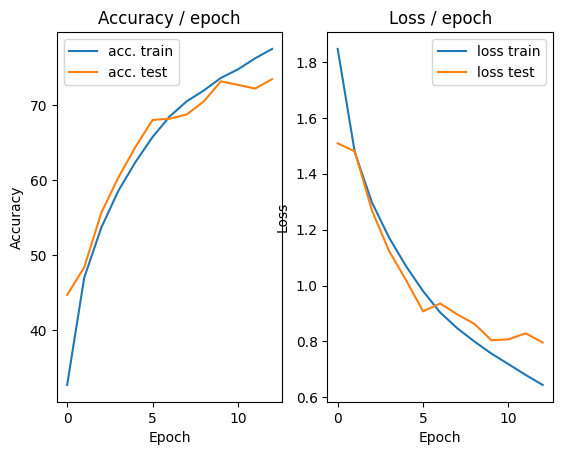

=== EPOCH 14 =====

[TRAIN Batch 000/391]	Time 0.206s (0.206s)	Loss 0.6970 (0.6970)	Prec@1  75.8 ( 75.8)	Prec@5  99.2 ( 99.2)


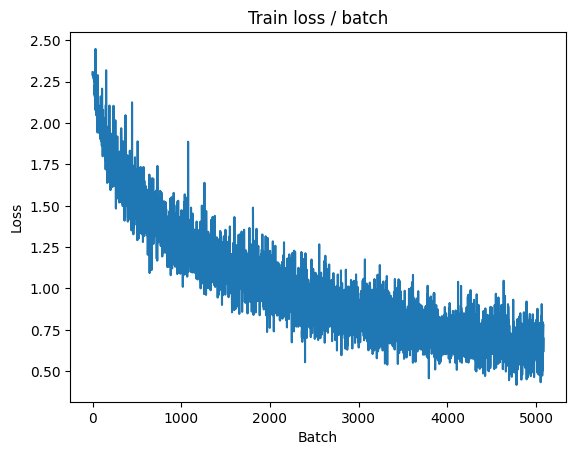

[TRAIN Batch 200/391]	Time 0.075s (0.044s)	Loss 0.6743 (0.6039)	Prec@1  72.7 ( 78.7)	Prec@5 100.0 ( 99.0)


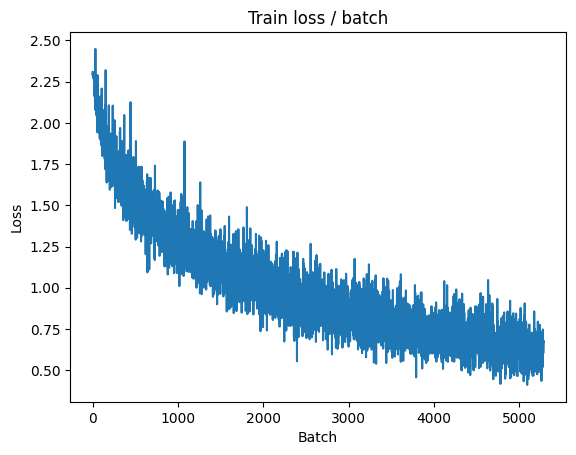


===============> Total time 18s	Avg loss 0.6075	Avg Prec@1 78.63 %	Avg Prec@5 98.96 %

[EVAL Batch 000/079]	Time 0.145s (0.145s)	Loss 0.9571 (0.9571)	Prec@1  71.1 ( 71.1)	Prec@5 100.0 (100.0)

===============> Total time 2s	Avg loss 0.8033	Avg Prec@1 74.21 %	Avg Prec@5 97.79 %



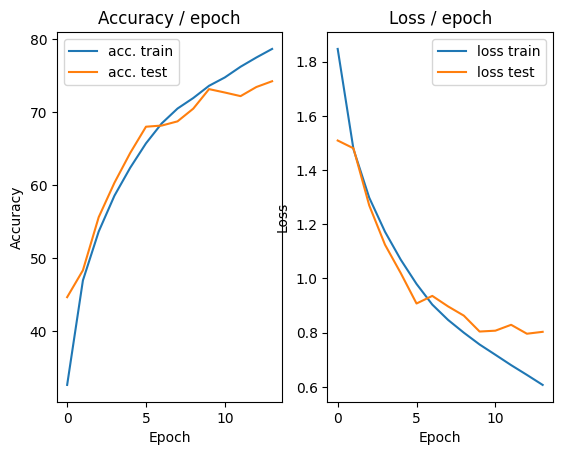

=== EPOCH 15 =====

[TRAIN Batch 000/391]	Time 0.193s (0.193s)	Loss 0.6171 (0.6171)	Prec@1  79.7 ( 79.7)	Prec@5  99.2 ( 99.2)


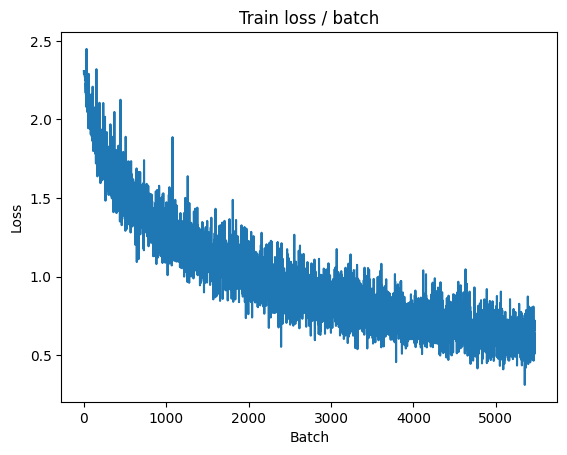

[TRAIN Batch 200/391]	Time 0.008s (0.050s)	Loss 0.6108 (0.5771)	Prec@1  82.0 ( 79.9)	Prec@5  99.2 ( 99.1)


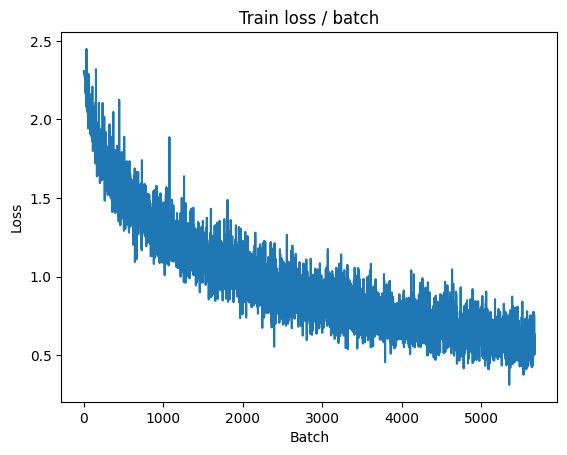


===============> Total time 19s	Avg loss 0.5817	Avg Prec@1 79.74 %	Avg Prec@5 99.12 %

[EVAL Batch 000/079]	Time 0.139s (0.139s)	Loss 0.8407 (0.8407)	Prec@1  75.0 ( 75.0)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.7489	Avg Prec@1 75.59 %	Avg Prec@5 97.98 %



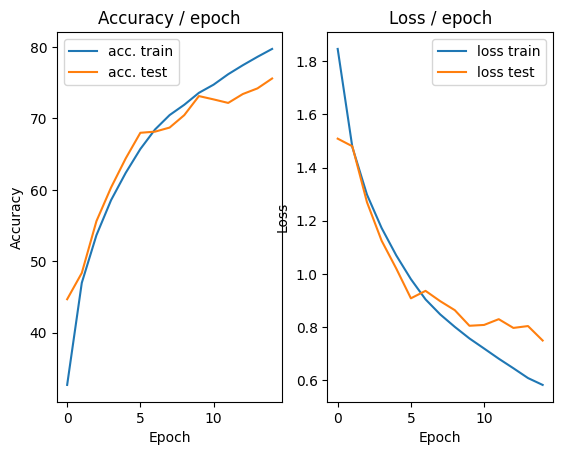

In [45]:
main(128, 0.1, cuda=True)

In [46]:
# Other data augmentation methods ：Random Erasing
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000), # 64 * 4 * 4 = 1024
            nn.ReLU(),
            nn.Linear(1000, 10)
        )

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.RandomErasing(p=0.5, scale=(0.02, 0.2), ratio=(0.3, 3.3), value=0),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.CenterCrop(28),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader

def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=10, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)

=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.203s (0.203s)	Loss 2.3027 (2.3027)	Prec@1  13.3 ( 13.3)	Prec@5  50.0 ( 50.0)


<Figure size 640x480 with 0 Axes>

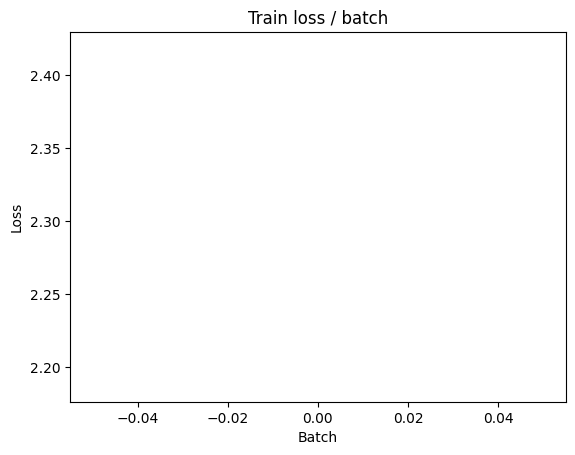

[TRAIN Batch 200/391]	Time 0.071s (0.047s)	Loss 1.8157 (1.9925)	Prec@1  39.1 ( 27.2)	Prec@5  83.6 ( 78.2)


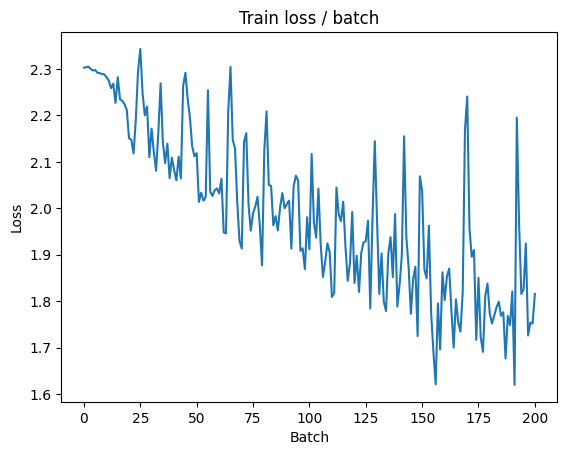


===============> Total time 16s	Avg loss 1.8358	Avg Prec@1 33.18 %	Avg Prec@5 83.20 %

[EVAL Batch 000/079]	Time 0.124s (0.124s)	Loss 1.5535 (1.5535)	Prec@1  46.1 ( 46.1)	Prec@5  89.8 ( 89.8)

===============> Total time 3s	Avg loss 1.5670	Avg Prec@1 43.88 %	Avg Prec@5 91.45 %



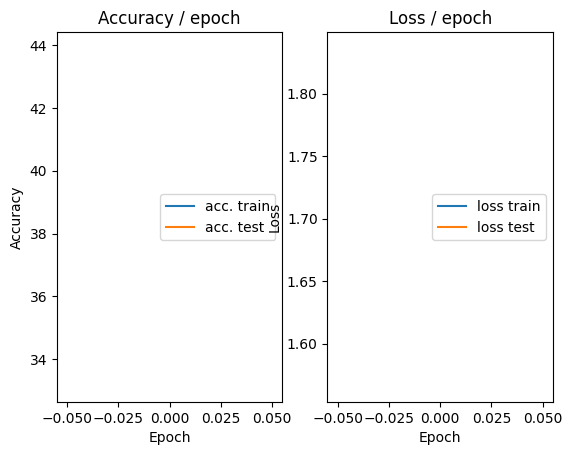

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.161s (0.161s)	Loss 1.5373 (1.5373)	Prec@1  46.9 ( 46.9)	Prec@5  91.4 ( 91.4)


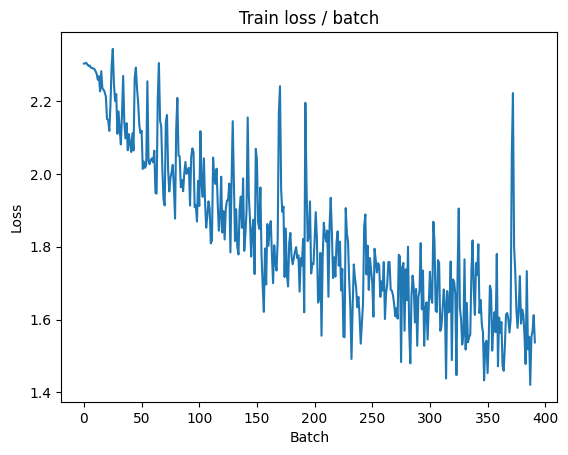

[TRAIN Batch 200/391]	Time 0.020s (0.041s)	Loss 1.4411 (1.4897)	Prec@1  46.1 ( 46.8)	Prec@5  90.6 ( 91.8)


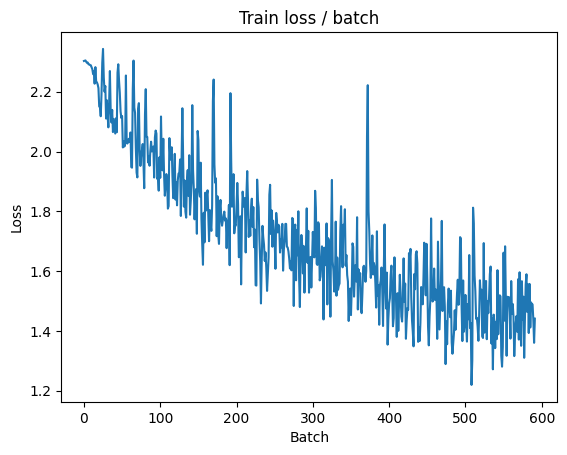


===============> Total time 16s	Avg loss 1.4244	Avg Prec@1 49.05 %	Avg Prec@5 92.64 %

[EVAL Batch 000/079]	Time 0.126s (0.126s)	Loss 1.4927 (1.4927)	Prec@1  45.3 ( 45.3)	Prec@5  95.3 ( 95.3)

===============> Total time 2s	Avg loss 1.4612	Avg Prec@1 47.83 %	Avg Prec@5 92.05 %



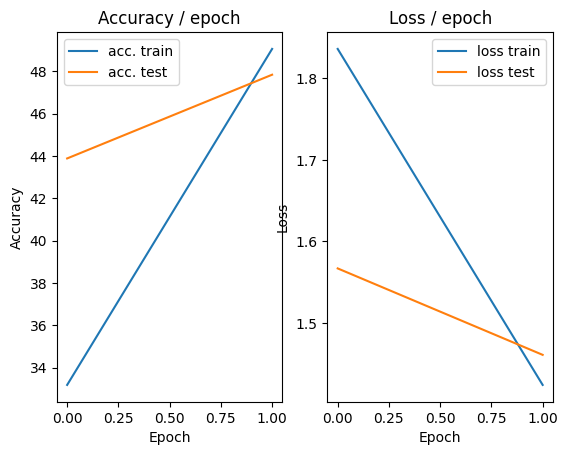

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.172s (0.172s)	Loss 1.3123 (1.3123)	Prec@1  52.3 ( 52.3)	Prec@5  92.2 ( 92.2)


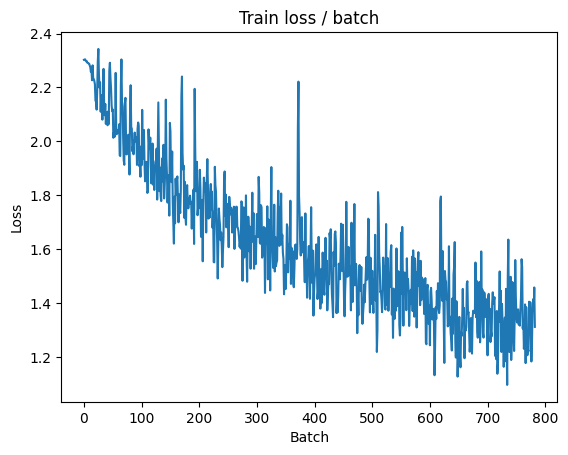

[TRAIN Batch 200/391]	Time 0.072s (0.047s)	Loss 1.1460 (1.2369)	Prec@1  54.7 ( 56.3)	Prec@5  97.7 ( 95.0)


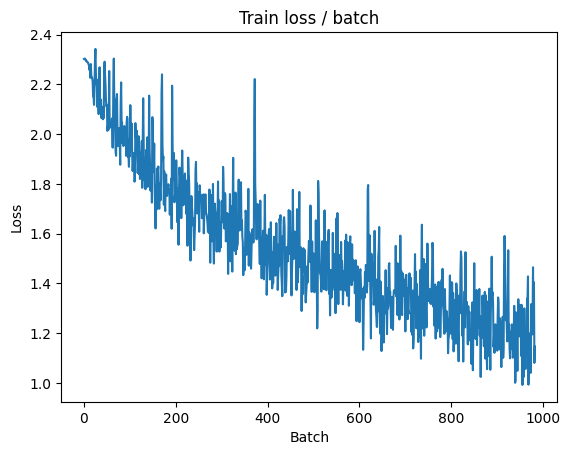


===============> Total time 17s	Avg loss 1.1970	Avg Prec@1 57.69 %	Avg Prec@5 95.20 %

[EVAL Batch 000/079]	Time 0.263s (0.263s)	Loss 1.3086 (1.3086)	Prec@1  55.5 ( 55.5)	Prec@5  94.5 ( 94.5)

===============> Total time 2s	Avg loss 1.2550	Avg Prec@1 56.04 %	Avg Prec@5 95.09 %



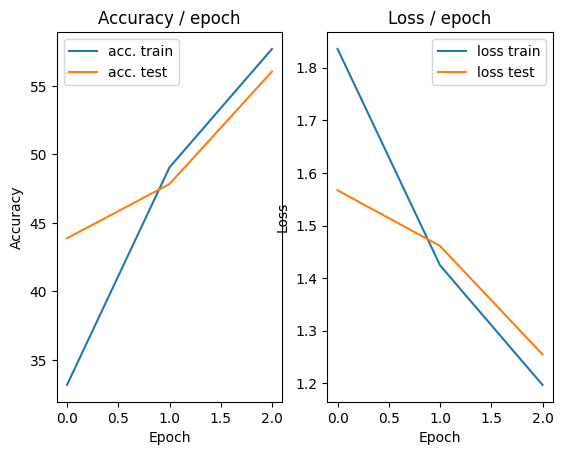

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.167s (0.167s)	Loss 1.2203 (1.2203)	Prec@1  55.5 ( 55.5)	Prec@5  95.3 ( 95.3)


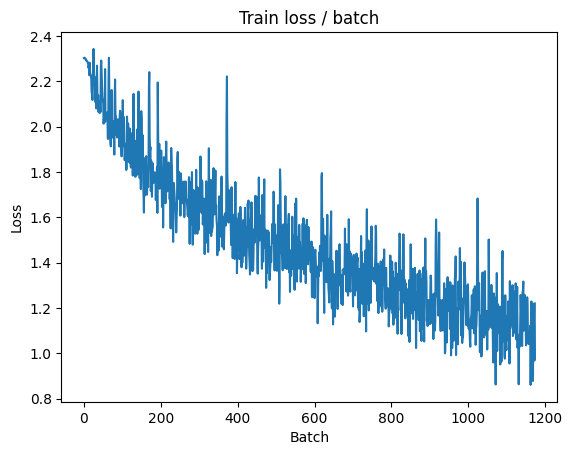

[TRAIN Batch 200/391]	Time 0.073s (0.042s)	Loss 0.9946 (1.0517)	Prec@1  62.5 ( 63.1)	Prec@5  98.4 ( 96.5)


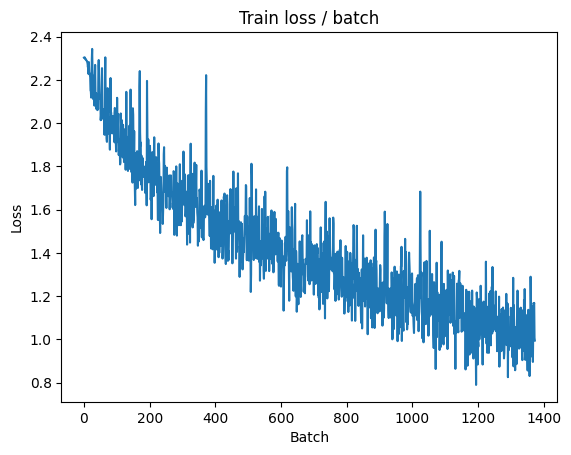


===============> Total time 16s	Avg loss 1.0338	Avg Prec@1 63.72 %	Avg Prec@5 96.62 %

[EVAL Batch 000/079]	Time 0.140s (0.140s)	Loss 1.4023 (1.4023)	Prec@1  45.3 ( 45.3)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 1.3725	Avg Prec@1 49.20 %	Avg Prec@5 94.90 %



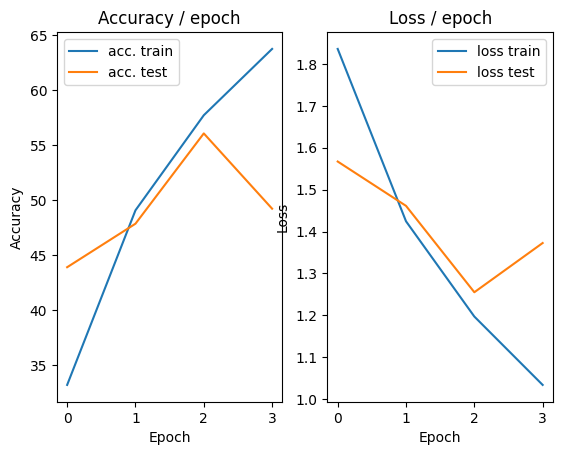

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.180s (0.180s)	Loss 1.3462 (1.3462)	Prec@1  51.6 ( 51.6)	Prec@5  93.8 ( 93.8)


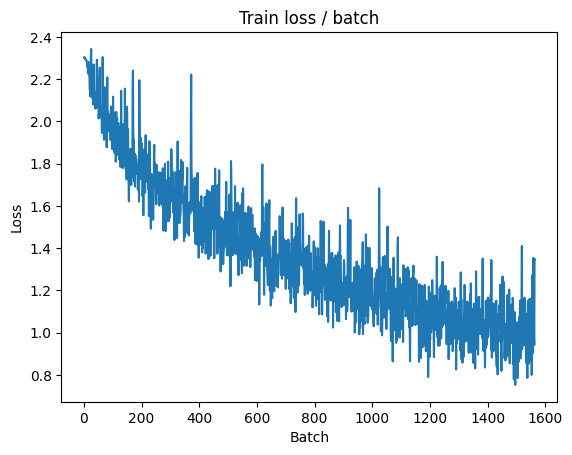

[TRAIN Batch 200/391]	Time 0.043s (0.046s)	Loss 0.9566 (0.9160)	Prec@1  66.4 ( 68.1)	Prec@5  98.4 ( 97.2)


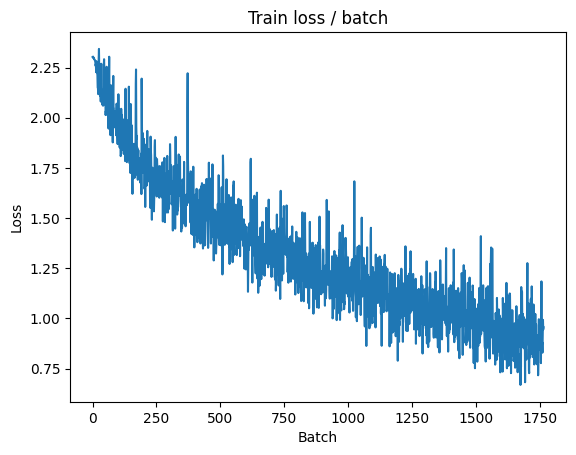


===============> Total time 17s	Avg loss 0.9077	Avg Prec@1 68.24 %	Avg Prec@5 97.35 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 1.1283 (1.1283)	Prec@1  59.4 ( 59.4)	Prec@5  94.5 ( 94.5)

===============> Total time 2s	Avg loss 1.1501	Avg Prec@1 60.17 %	Avg Prec@5 95.18 %



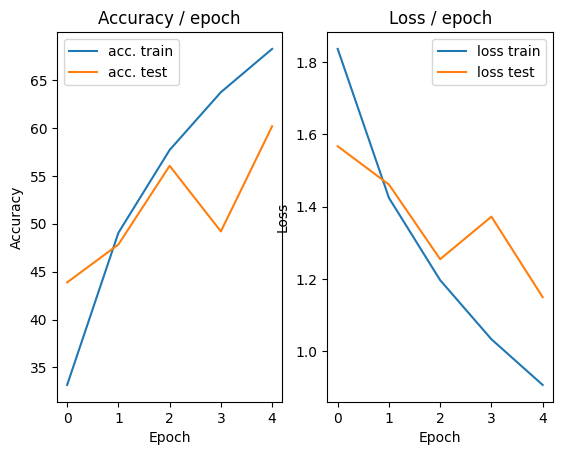

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.174s (0.174s)	Loss 0.9004 (0.9004)	Prec@1  68.0 ( 68.0)	Prec@5  97.7 ( 97.7)


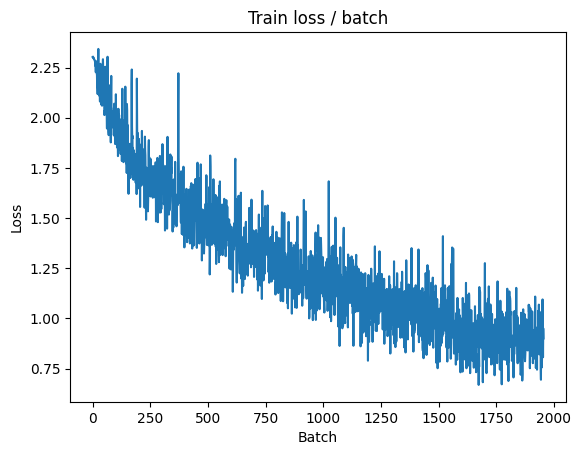

[TRAIN Batch 200/391]	Time 0.047s (0.046s)	Loss 0.9539 (0.8159)	Prec@1  65.6 ( 71.6)	Prec@5  95.3 ( 98.0)


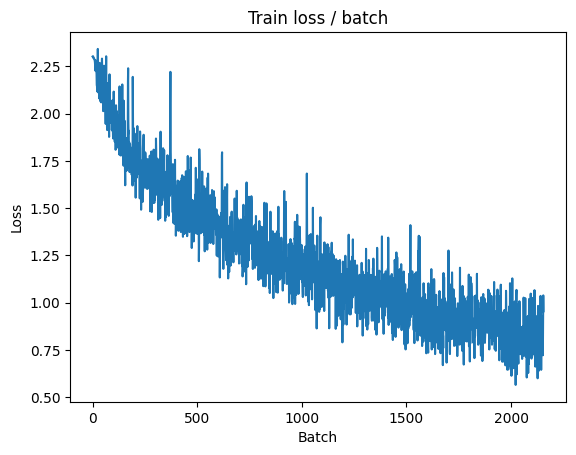


===============> Total time 16s	Avg loss 0.8108	Avg Prec@1 71.68 %	Avg Prec@5 98.08 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 1.0334 (1.0334)	Prec@1  67.2 ( 67.2)	Prec@5  94.5 ( 94.5)

===============> Total time 2s	Avg loss 1.0370	Avg Prec@1 63.95 %	Avg Prec@5 96.45 %



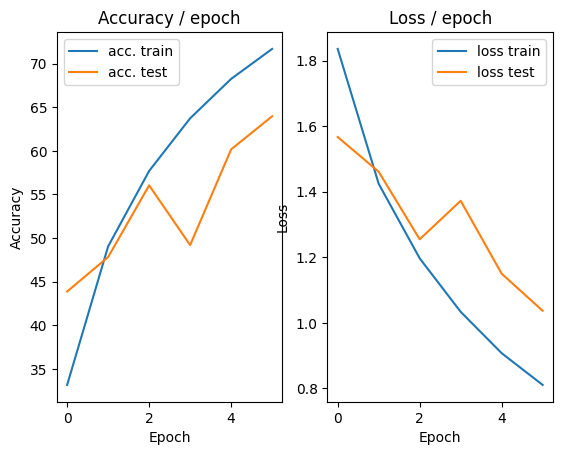

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.274s (0.274s)	Loss 0.7666 (0.7666)	Prec@1  71.9 ( 71.9)	Prec@5  99.2 ( 99.2)


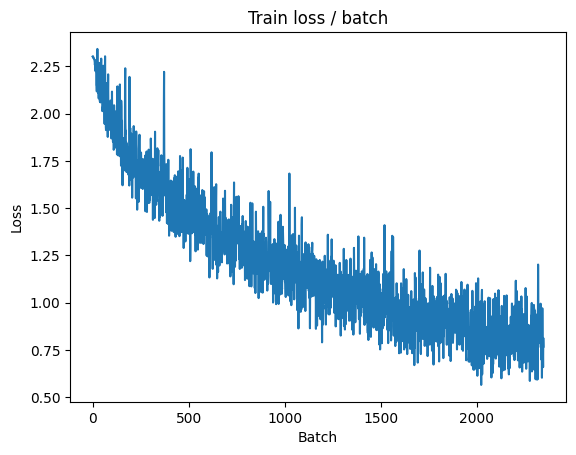

[TRAIN Batch 200/391]	Time 0.057s (0.044s)	Loss 0.6142 (0.7218)	Prec@1  81.2 ( 74.7)	Prec@5  98.4 ( 98.5)


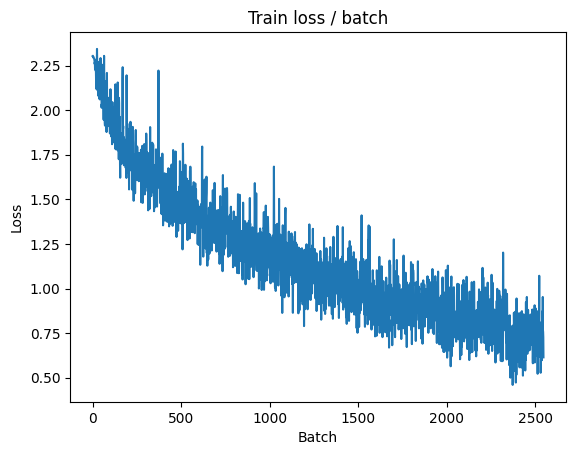


===============> Total time 17s	Avg loss 0.7162	Avg Prec@1 74.90 %	Avg Prec@5 98.51 %

[EVAL Batch 000/079]	Time 0.133s (0.133s)	Loss 0.9404 (0.9404)	Prec@1  69.5 ( 69.5)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 0.9789	Avg Prec@1 66.45 %	Avg Prec@5 96.59 %



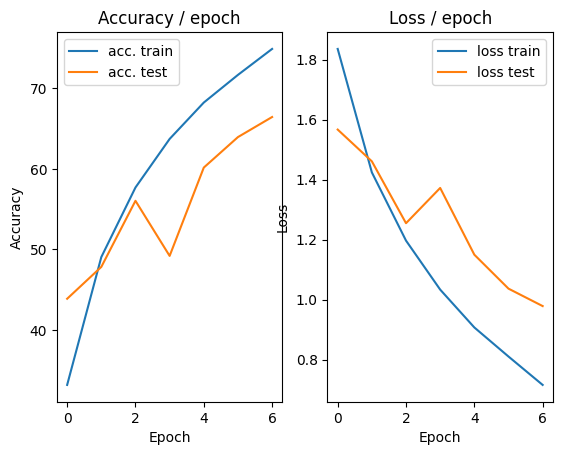

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.195s (0.195s)	Loss 0.6527 (0.6527)	Prec@1  75.8 ( 75.8)	Prec@5  99.2 ( 99.2)


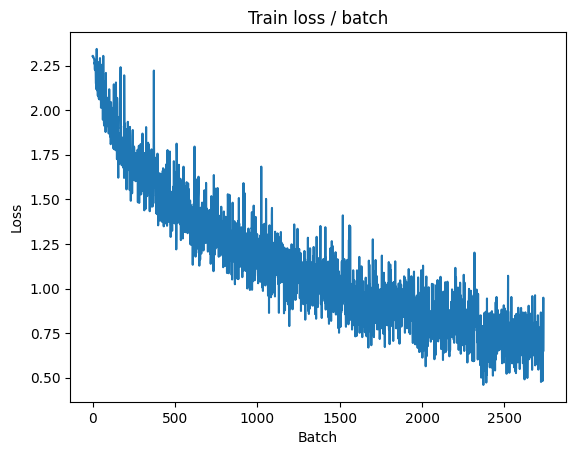

[TRAIN Batch 200/391]	Time 0.012s (0.046s)	Loss 0.6713 (0.6383)	Prec@1  76.6 ( 77.6)	Prec@5  98.4 ( 98.8)


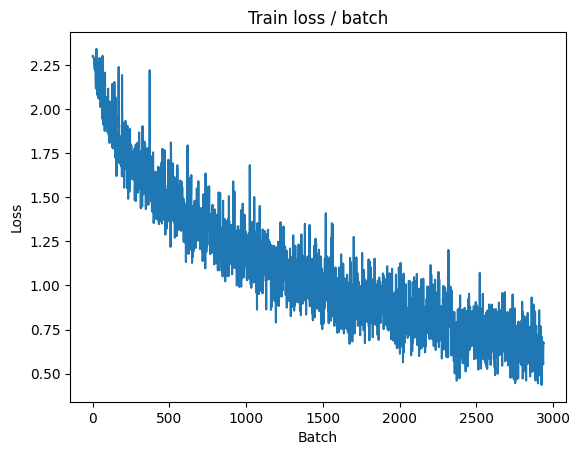


===============> Total time 17s	Avg loss 0.6405	Avg Prec@1 77.54 %	Avg Prec@5 98.77 %

[EVAL Batch 000/079]	Time 0.256s (0.256s)	Loss 1.0514 (1.0514)	Prec@1  66.4 ( 66.4)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 1.0617	Avg Prec@1 63.41 %	Avg Prec@5 96.81 %



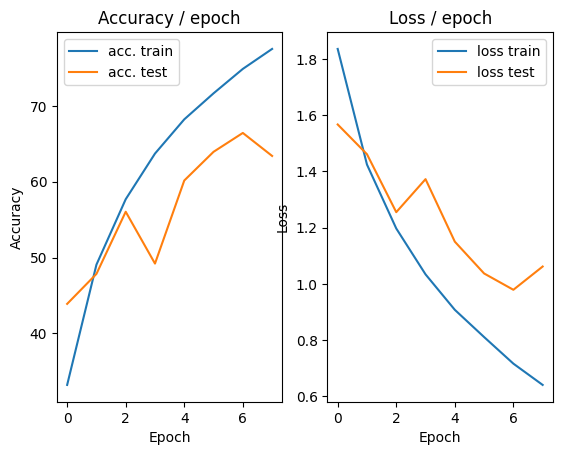

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.173s (0.173s)	Loss 0.6338 (0.6338)	Prec@1  75.8 ( 75.8)	Prec@5  98.4 ( 98.4)


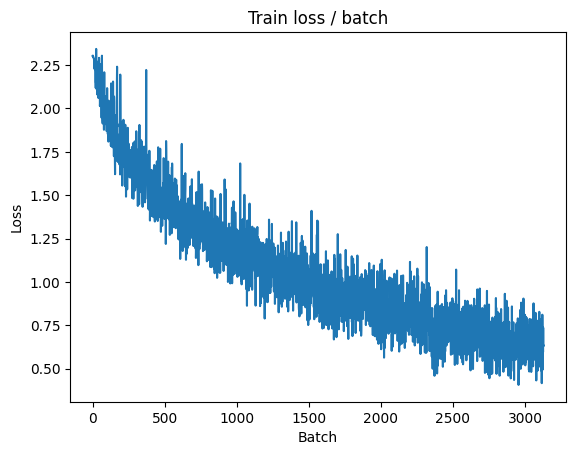

[TRAIN Batch 200/391]	Time 0.097s (0.042s)	Loss 0.6156 (0.5626)	Prec@1  83.6 ( 80.1)	Prec@5  98.4 ( 99.1)


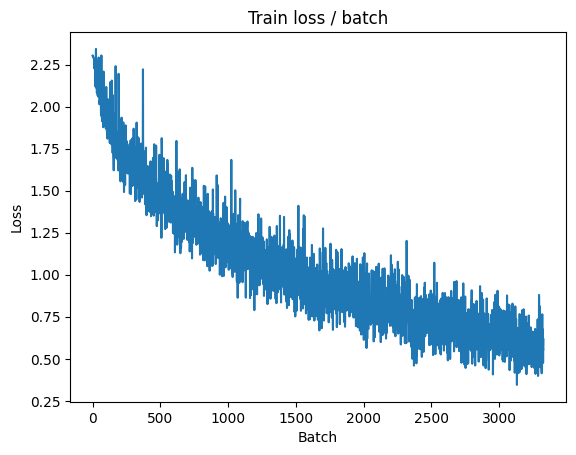


===============> Total time 20s	Avg loss 0.5722	Avg Prec@1 79.76 %	Avg Prec@5 99.10 %

[EVAL Batch 000/079]	Time 0.147s (0.147s)	Loss 1.1639 (1.1639)	Prec@1  64.8 ( 64.8)	Prec@5  94.5 ( 94.5)

===============> Total time 3s	Avg loss 1.1687	Avg Prec@1 62.39 %	Avg Prec@5 96.36 %



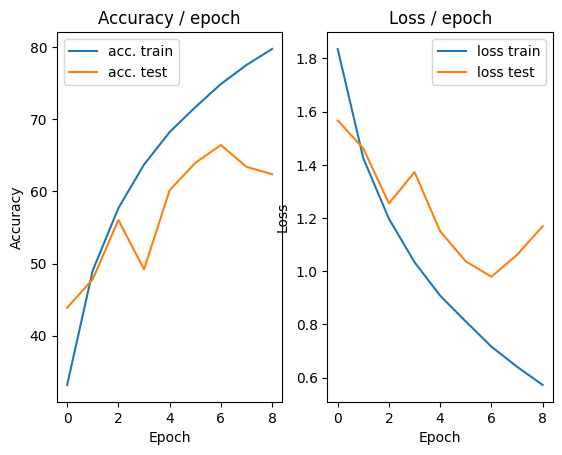

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.177s (0.177s)	Loss 0.7008 (0.7008)	Prec@1  75.8 ( 75.8)	Prec@5  96.9 ( 96.9)


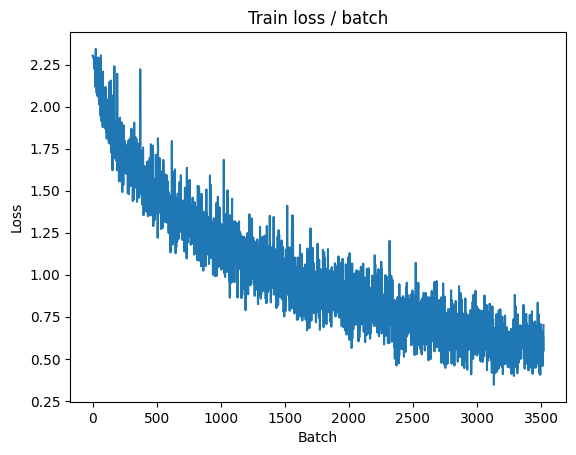

[TRAIN Batch 200/391]	Time 0.012s (0.042s)	Loss 0.5981 (0.4916)	Prec@1  78.9 ( 82.6)	Prec@5 100.0 ( 99.4)


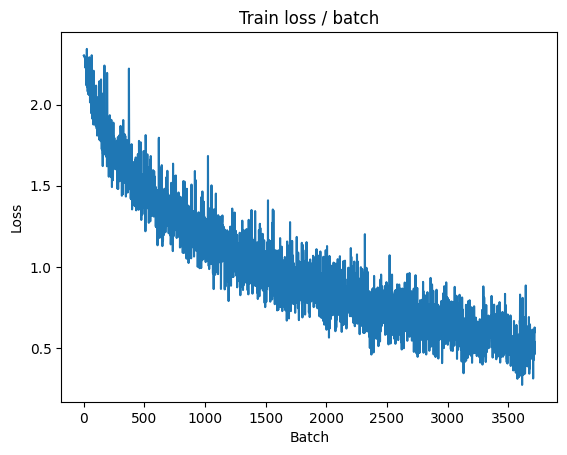


===============> Total time 16s	Avg loss 0.5075	Avg Prec@1 82.13 %	Avg Prec@5 99.30 %

[EVAL Batch 000/079]	Time 0.139s (0.139s)	Loss 1.0390 (1.0390)	Prec@1  64.8 ( 64.8)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 1.0806	Avg Prec@1 65.85 %	Avg Prec@5 96.19 %



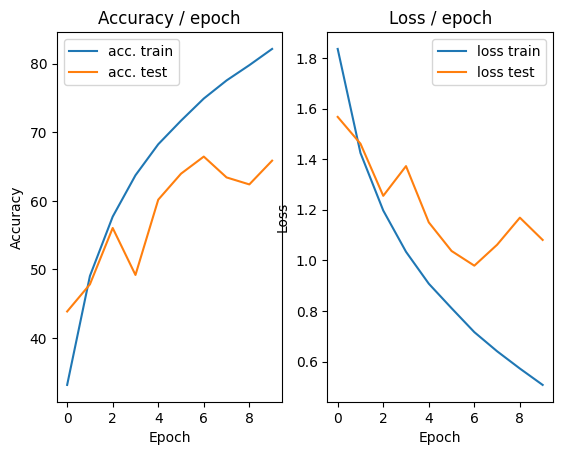

In [47]:
main(128, 0.1, cuda=True)

In [48]:
# Variants on the optimization algorithm
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000), # 64 * 4 * 4 = 1024
            nn.ReLU(),
            nn.Linear(1000, 10)
        )

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.RandomCrop(28),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.CenterCrop(28),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader


def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=15, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)

        # Update the learning rate at the end of the epoch
        scheduler.step()

=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.162s (0.162s)	Loss 2.3029 (2.3029)	Prec@1   6.2 (  6.2)	Prec@5  51.6 ( 51.6)


<Figure size 640x480 with 0 Axes>

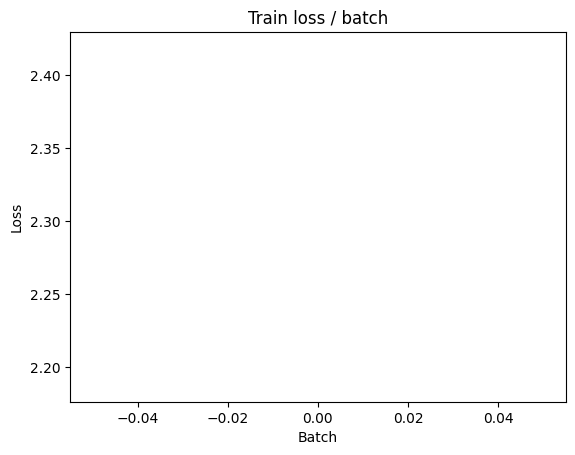

[TRAIN Batch 200/391]	Time 0.009s (0.044s)	Loss 1.7128 (1.9652)	Prec@1  34.4 ( 27.7)	Prec@5  85.9 ( 78.6)


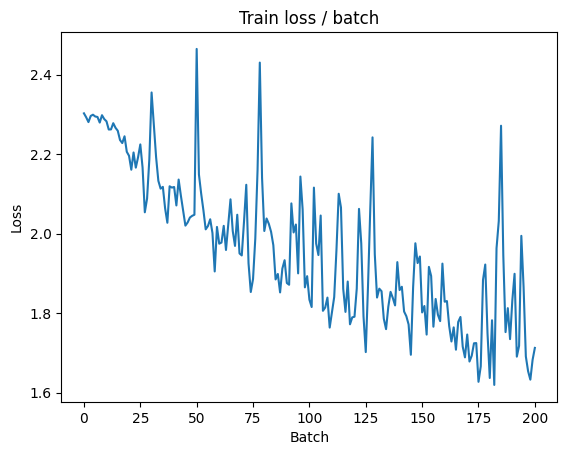


===============> Total time 16s	Avg loss 1.8056	Avg Prec@1 33.90 %	Avg Prec@5 84.02 %

[EVAL Batch 000/079]	Time 0.147s (0.147s)	Loss 1.5969 (1.5969)	Prec@1  43.8 ( 43.8)	Prec@5  89.1 ( 89.1)

===============> Total time 3s	Avg loss 1.5585	Avg Prec@1 42.70 %	Avg Prec@5 91.10 %



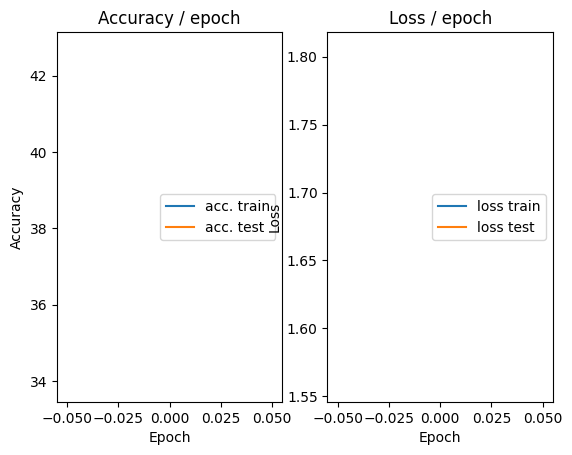

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.166s (0.166s)	Loss 1.6845 (1.6845)	Prec@1  44.5 ( 44.5)	Prec@5  89.8 ( 89.8)


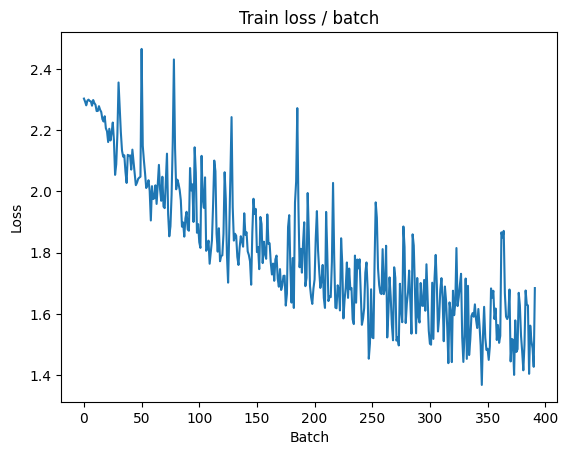

[TRAIN Batch 200/391]	Time 0.064s (0.041s)	Loss 1.3918 (1.4475)	Prec@1  49.2 ( 47.6)	Prec@5  89.8 ( 92.5)


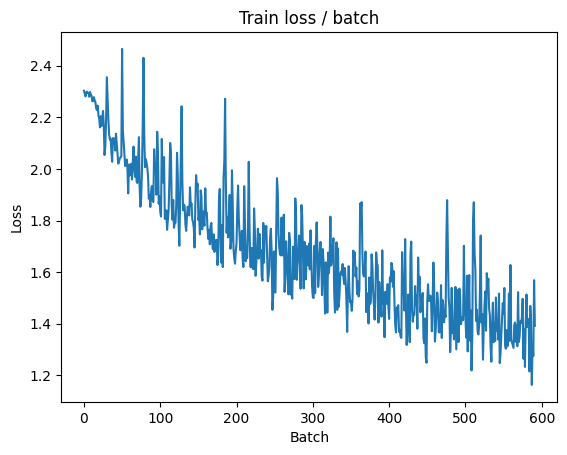


===============> Total time 16s	Avg loss 1.3868	Avg Prec@1 49.96 %	Avg Prec@5 93.24 %

[EVAL Batch 000/079]	Time 0.134s (0.134s)	Loss 1.3863 (1.3863)	Prec@1  50.8 ( 50.8)	Prec@5  90.6 ( 90.6)

===============> Total time 2s	Avg loss 1.3206	Avg Prec@1 54.10 %	Avg Prec@5 94.18 %



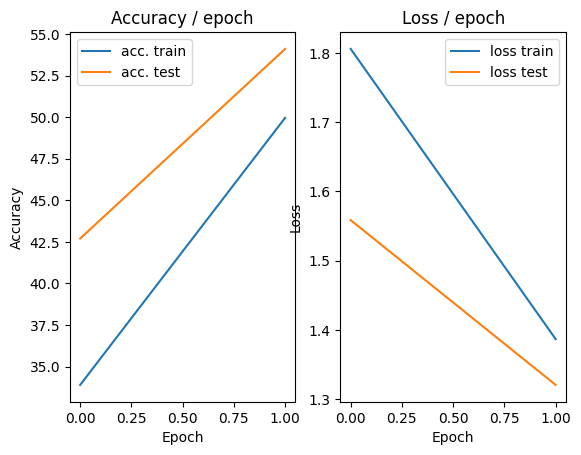

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.178s (0.178s)	Loss 1.3224 (1.3224)	Prec@1  54.7 ( 54.7)	Prec@5  93.8 ( 93.8)


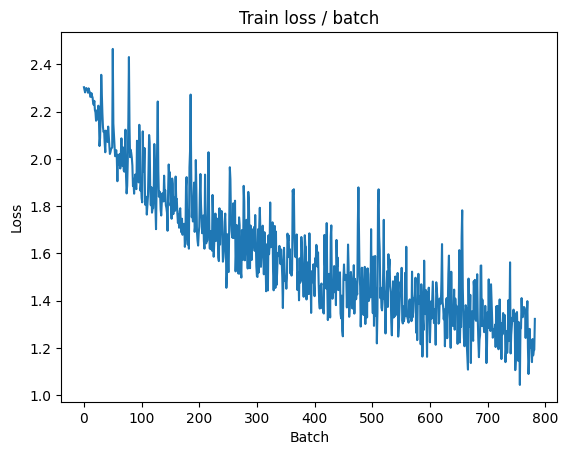

[TRAIN Batch 200/391]	Time 0.008s (0.044s)	Loss 1.1887 (1.1946)	Prec@1  59.4 ( 57.4)	Prec@5  96.9 ( 95.3)


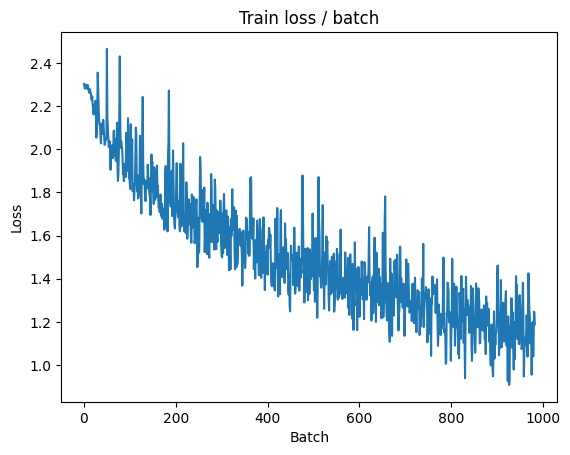


===============> Total time 17s	Avg loss 1.1663	Avg Prec@1 58.81 %	Avg Prec@5 95.48 %

[EVAL Batch 000/079]	Time 0.176s (0.176s)	Loss 1.0602 (1.0602)	Prec@1  64.8 ( 64.8)	Prec@5  95.3 ( 95.3)

===============> Total time 2s	Avg loss 1.1158	Avg Prec@1 61.63 %	Avg Prec@5 95.59 %



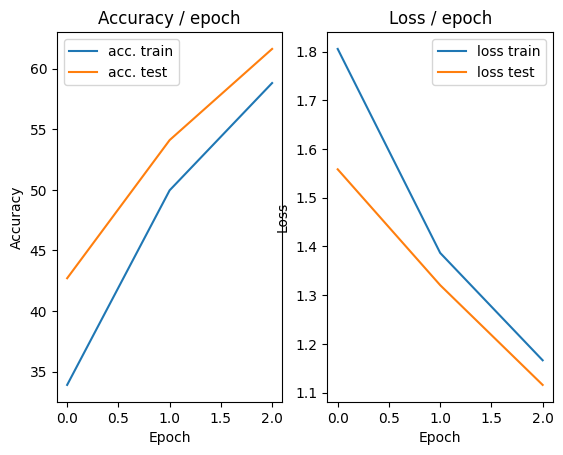

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.157s (0.157s)	Loss 1.2327 (1.2327)	Prec@1  56.2 ( 56.2)	Prec@5  96.1 ( 96.1)


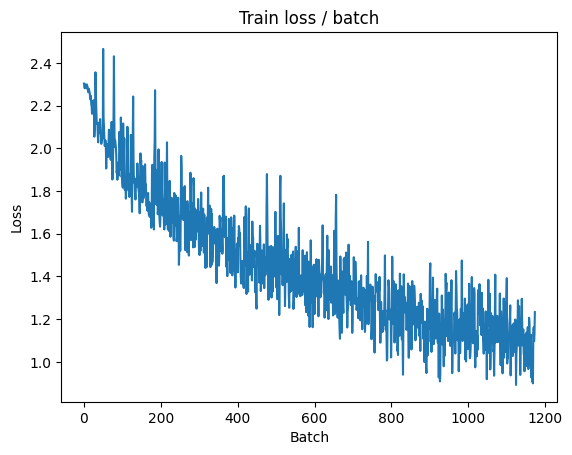

[TRAIN Batch 200/391]	Time 0.010s (0.039s)	Loss 1.0268 (1.0387)	Prec@1  67.2 ( 63.9)	Prec@5  97.7 ( 96.6)


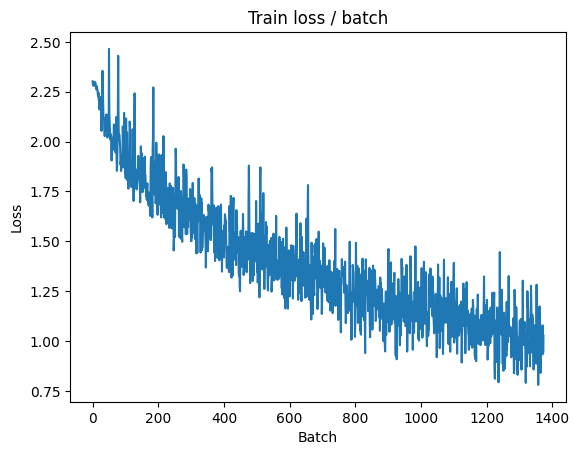


===============> Total time 16s	Avg loss 1.0137	Avg Prec@1 64.58 %	Avg Prec@5 96.76 %

[EVAL Batch 000/079]	Time 0.133s (0.133s)	Loss 0.9695 (0.9695)	Prec@1  66.4 ( 66.4)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 1.0015	Avg Prec@1 65.41 %	Avg Prec@5 96.58 %



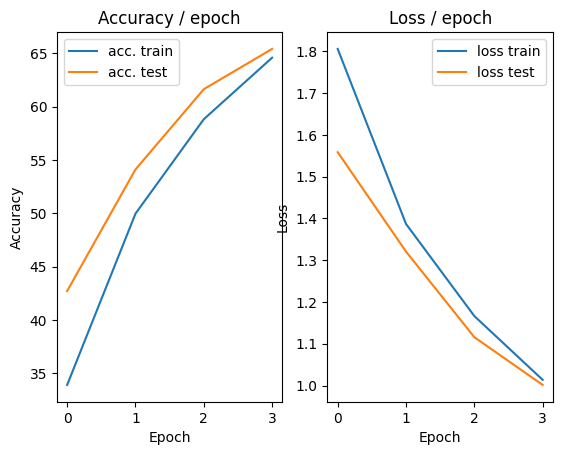

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.170s (0.170s)	Loss 0.9041 (0.9041)	Prec@1  69.5 ( 69.5)	Prec@5  99.2 ( 99.2)


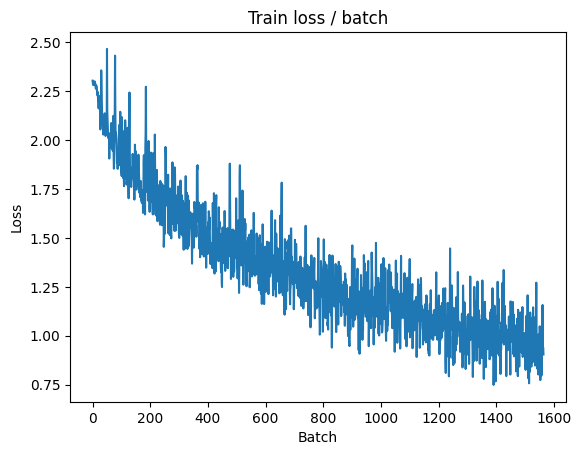

[TRAIN Batch 200/391]	Time 0.012s (0.044s)	Loss 0.9590 (0.9166)	Prec@1  66.4 ( 68.1)	Prec@5  97.7 ( 97.3)


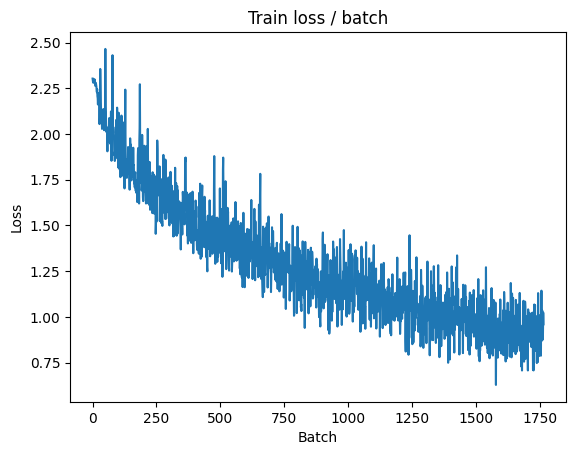


===============> Total time 16s	Avg loss 0.8998	Avg Prec@1 68.63 %	Avg Prec@5 97.36 %

[EVAL Batch 000/079]	Time 0.220s (0.220s)	Loss 0.9139 (0.9139)	Prec@1  67.2 ( 67.2)	Prec@5  95.3 ( 95.3)

===============> Total time 2s	Avg loss 0.9400	Avg Prec@1 67.82 %	Avg Prec@5 97.26 %



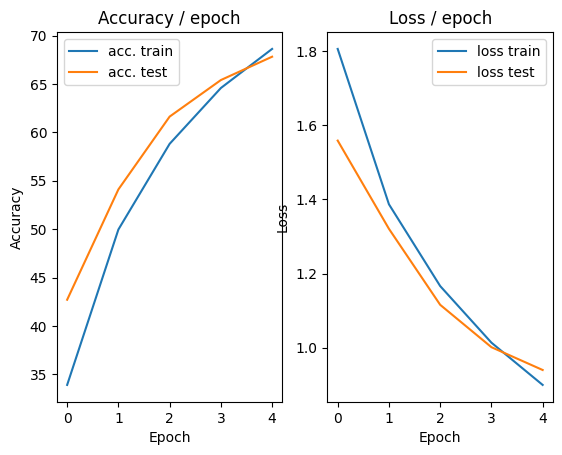

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.182s (0.182s)	Loss 0.7089 (0.7089)	Prec@1  73.4 ( 73.4)	Prec@5  98.4 ( 98.4)


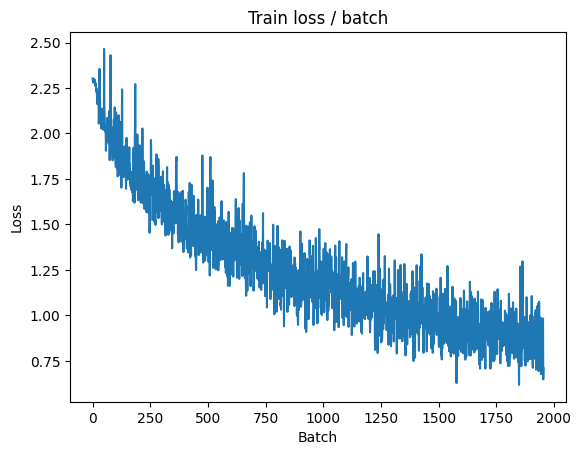

[TRAIN Batch 200/391]	Time 0.011s (0.040s)	Loss 0.7852 (0.8279)	Prec@1  74.2 ( 71.4)	Prec@5  98.4 ( 97.6)


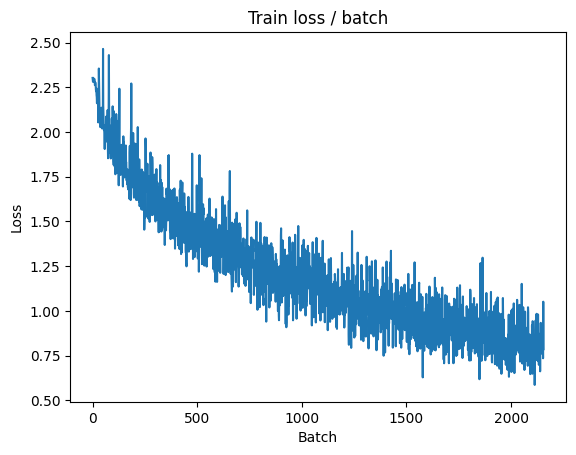


===============> Total time 16s	Avg loss 0.8199	Avg Prec@1 71.63 %	Avg Prec@5 97.70 %

[EVAL Batch 000/079]	Time 0.127s (0.127s)	Loss 0.8341 (0.8341)	Prec@1  71.9 ( 71.9)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.8607	Avg Prec@1 70.69 %	Avg Prec@5 97.27 %



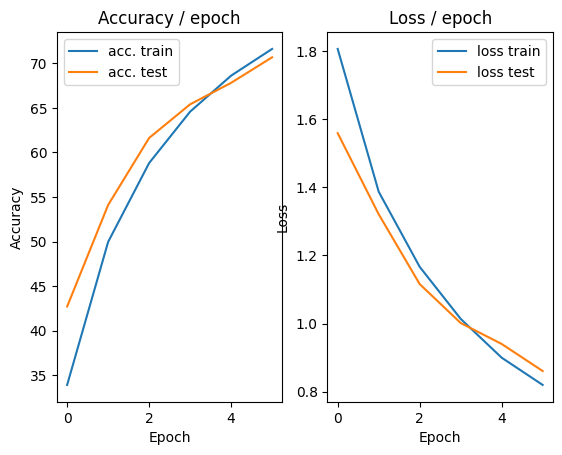

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.171s (0.171s)	Loss 0.9062 (0.9062)	Prec@1  72.7 ( 72.7)	Prec@5  96.1 ( 96.1)


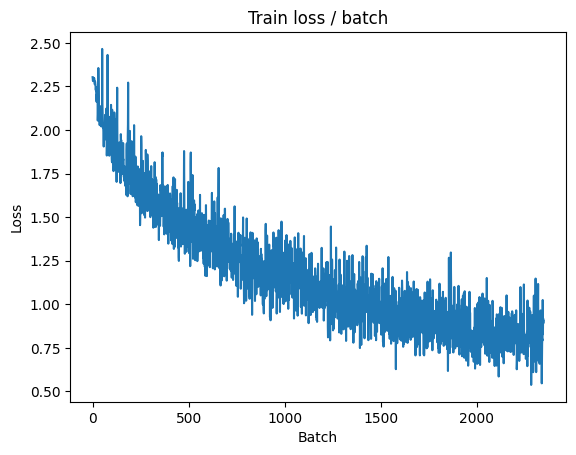

[TRAIN Batch 200/391]	Time 0.065s (0.045s)	Loss 0.6070 (0.7661)	Prec@1  78.9 ( 73.4)	Prec@5  97.7 ( 98.1)


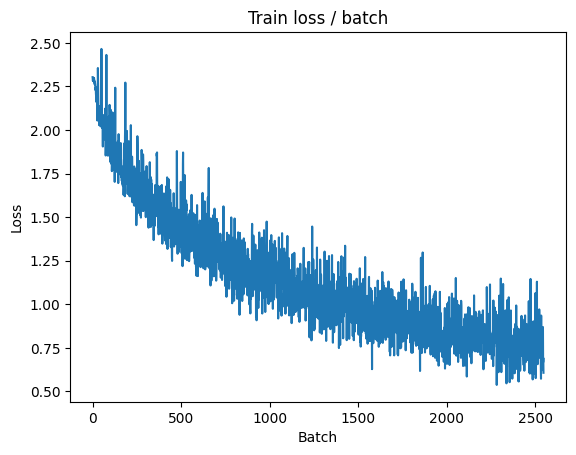


===============> Total time 17s	Avg loss 0.7585	Avg Prec@1 73.91 %	Avg Prec@5 98.10 %

[EVAL Batch 000/079]	Time 0.154s (0.154s)	Loss 0.7118 (0.7118)	Prec@1  72.7 ( 72.7)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.7217	Avg Prec@1 75.11 %	Avg Prec@5 98.21 %



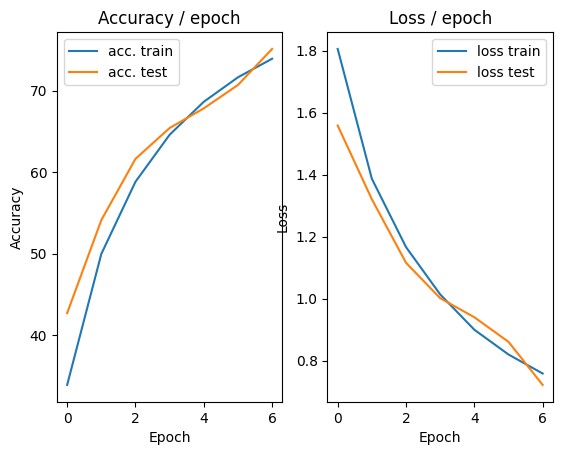

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.178s (0.178s)	Loss 0.5479 (0.5479)	Prec@1  81.2 ( 81.2)	Prec@5 100.0 (100.0)


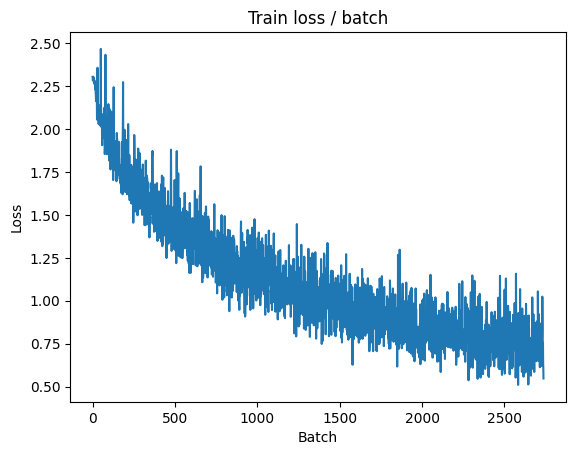

[TRAIN Batch 200/391]	Time 0.010s (0.040s)	Loss 0.5899 (0.7010)	Prec@1  81.2 ( 75.4)	Prec@5  99.2 ( 98.5)


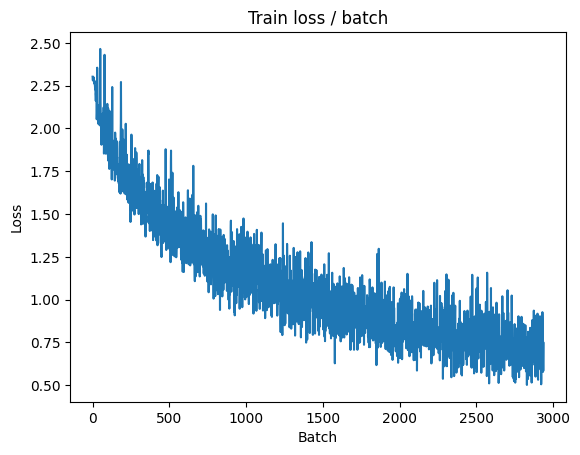


===============> Total time 15s	Avg loss 0.6931	Avg Prec@1 75.77 %	Avg Prec@5 98.52 %

[EVAL Batch 000/079]	Time 0.138s (0.138s)	Loss 0.7266 (0.7266)	Prec@1  78.1 ( 78.1)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 0.7305	Avg Prec@1 74.75 %	Avg Prec@5 98.24 %



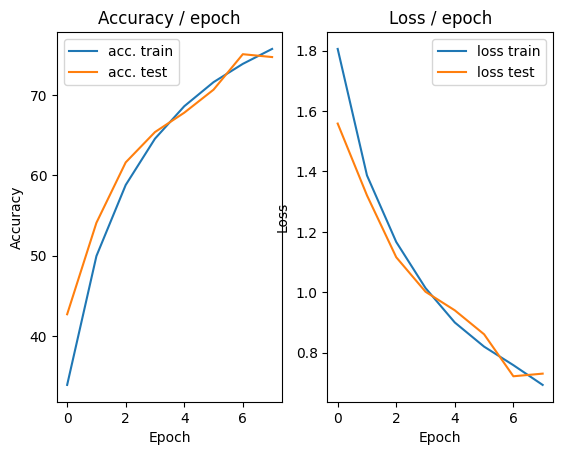

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.180s (0.180s)	Loss 0.8524 (0.8524)	Prec@1  72.7 ( 72.7)	Prec@5  99.2 ( 99.2)


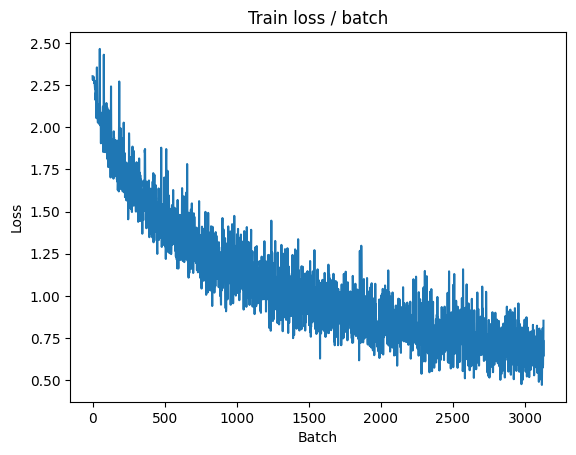

[TRAIN Batch 200/391]	Time 0.083s (0.044s)	Loss 0.5630 (0.6551)	Prec@1  81.2 ( 77.3)	Prec@5  97.7 ( 98.7)


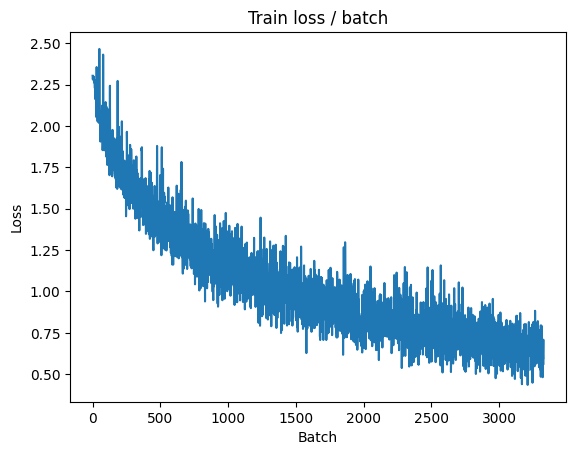


===============> Total time 16s	Avg loss 0.6491	Avg Prec@1 77.32 %	Avg Prec@5 98.73 %

[EVAL Batch 000/079]	Time 0.149s (0.149s)	Loss 0.6654 (0.6654)	Prec@1  80.5 ( 80.5)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.7004	Avg Prec@1 75.96 %	Avg Prec@5 98.56 %



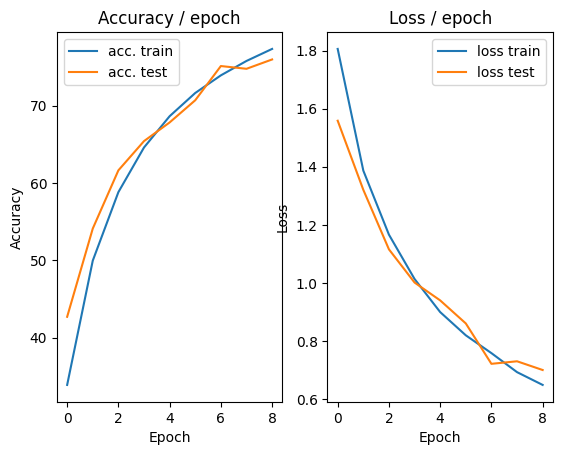

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.175s (0.175s)	Loss 0.8056 (0.8056)	Prec@1  69.5 ( 69.5)	Prec@5  99.2 ( 99.2)


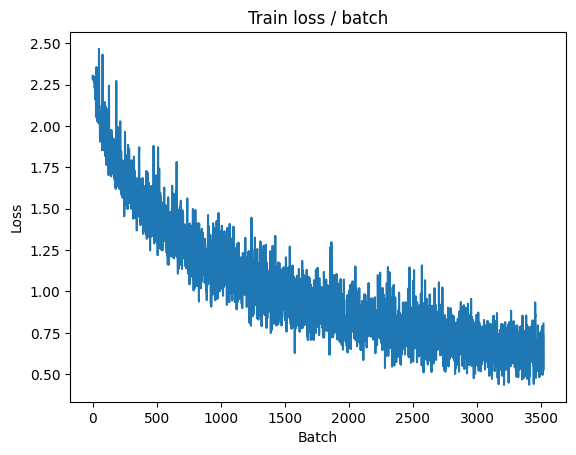

[TRAIN Batch 200/391]	Time 0.062s (0.038s)	Loss 0.6420 (0.6126)	Prec@1  76.6 ( 78.7)	Prec@5  99.2 ( 98.8)


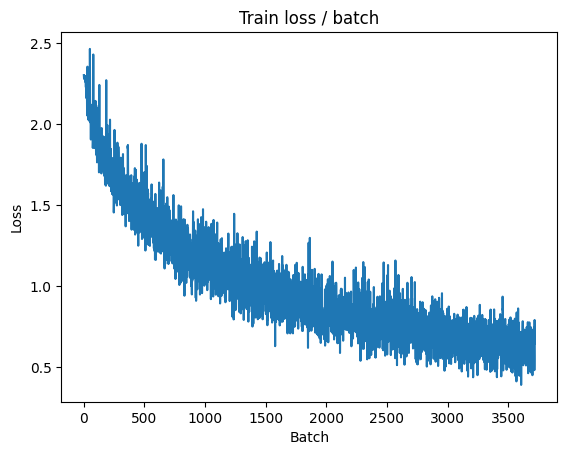


===============> Total time 16s	Avg loss 0.6130	Avg Prec@1 78.83 %	Avg Prec@5 98.78 %

[EVAL Batch 000/079]	Time 0.130s (0.130s)	Loss 0.6636 (0.6636)	Prec@1  77.3 ( 77.3)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.6657	Avg Prec@1 76.94 %	Avg Prec@5 98.53 %



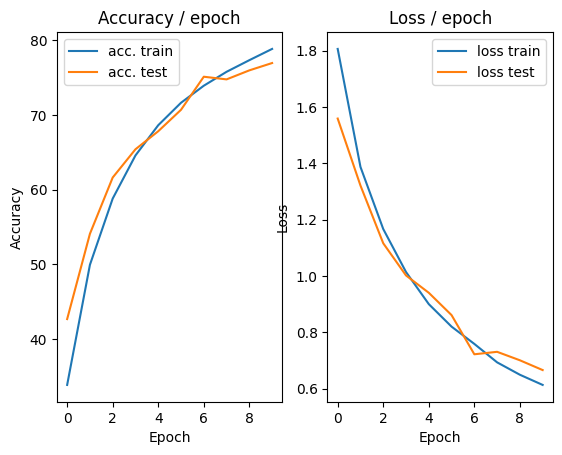

=== EPOCH 11 =====

[TRAIN Batch 000/391]	Time 0.166s (0.166s)	Loss 0.6757 (0.6757)	Prec@1  77.3 ( 77.3)	Prec@5 100.0 (100.0)


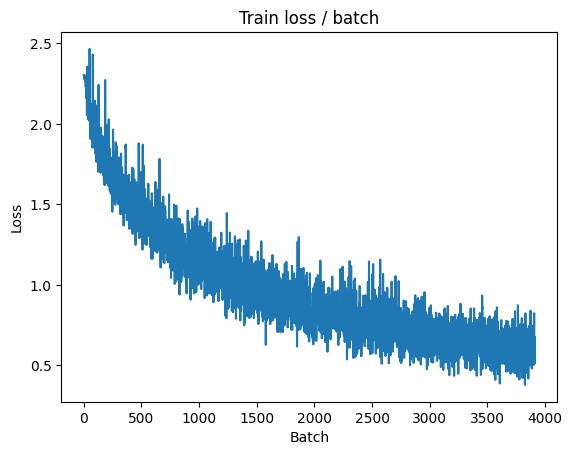

[TRAIN Batch 200/391]	Time 0.014s (0.044s)	Loss 0.5485 (0.5826)	Prec@1  80.5 ( 80.0)	Prec@5 100.0 ( 98.9)


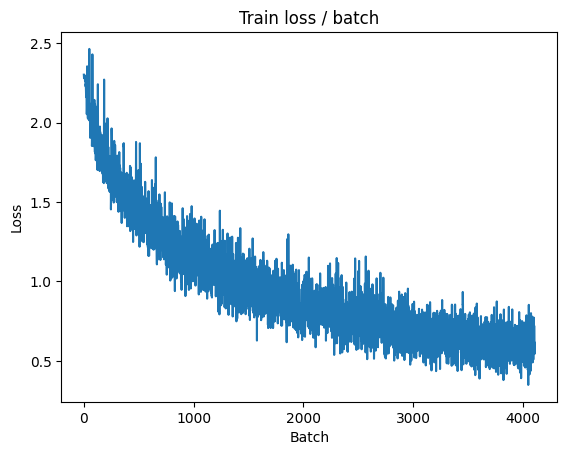


===============> Total time 16s	Avg loss 0.5762	Avg Prec@1 80.01 %	Avg Prec@5 98.96 %

[EVAL Batch 000/079]	Time 0.193s (0.193s)	Loss 0.6502 (0.6502)	Prec@1  80.5 ( 80.5)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.6667	Avg Prec@1 77.65 %	Avg Prec@5 98.37 %



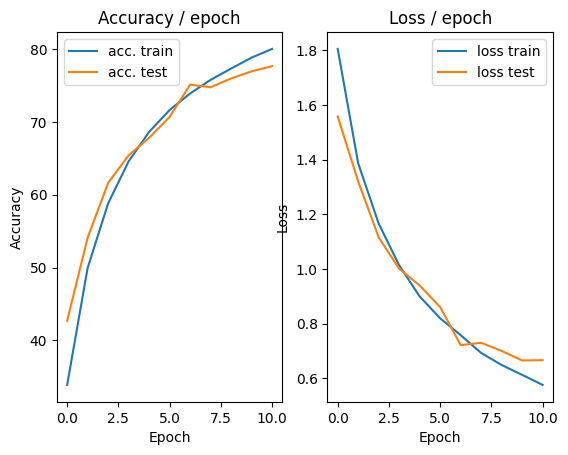

=== EPOCH 12 =====

[TRAIN Batch 000/391]	Time 0.186s (0.186s)	Loss 0.3985 (0.3985)	Prec@1  87.5 ( 87.5)	Prec@5 100.0 (100.0)


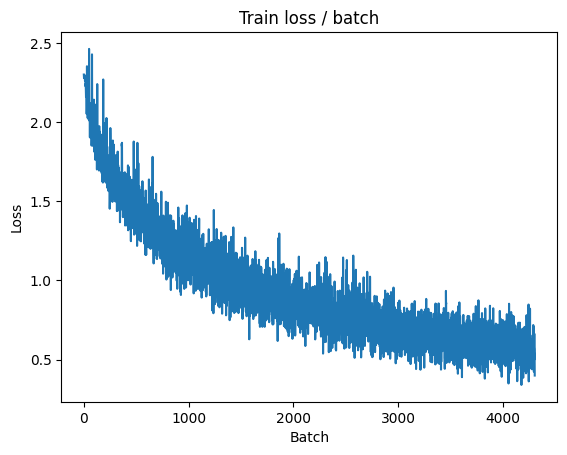

[TRAIN Batch 200/391]	Time 0.011s (0.039s)	Loss 0.7509 (0.5436)	Prec@1  76.6 ( 81.3)	Prec@5  96.9 ( 99.0)


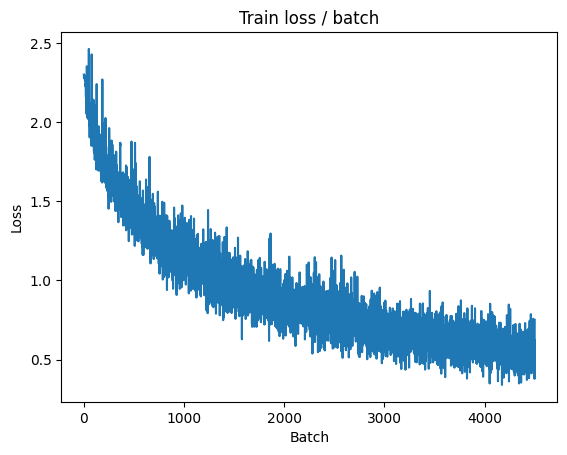


===============> Total time 15s	Avg loss 0.5466	Avg Prec@1 81.14 %	Avg Prec@5 99.04 %

[EVAL Batch 000/079]	Time 0.142s (0.142s)	Loss 0.6207 (0.6207)	Prec@1  78.1 ( 78.1)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.6236	Avg Prec@1 78.79 %	Avg Prec@5 98.73 %



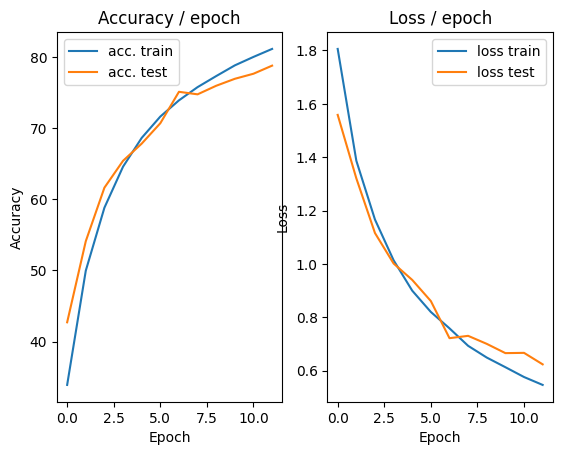

=== EPOCH 13 =====

[TRAIN Batch 000/391]	Time 0.195s (0.195s)	Loss 0.4641 (0.4641)	Prec@1  80.5 ( 80.5)	Prec@5  99.2 ( 99.2)


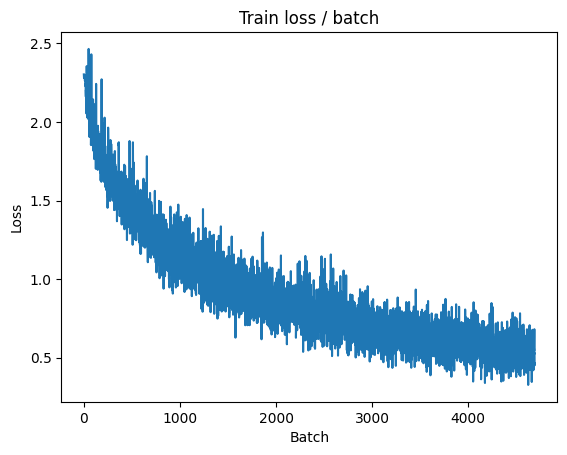

[TRAIN Batch 200/391]	Time 0.052s (0.043s)	Loss 0.6162 (0.5069)	Prec@1  81.2 ( 82.4)	Prec@5  96.9 ( 99.2)


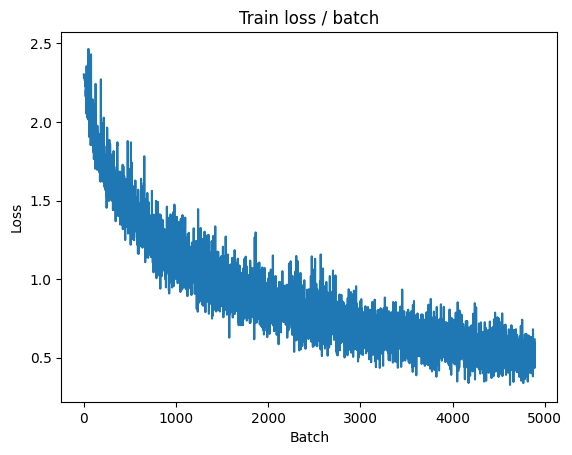


===============> Total time 16s	Avg loss 0.5142	Avg Prec@1 82.06 %	Avg Prec@5 99.19 %

[EVAL Batch 000/079]	Time 0.260s (0.260s)	Loss 0.6780 (0.6780)	Prec@1  78.1 ( 78.1)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.6656	Avg Prec@1 77.63 %	Avg Prec@5 98.52 %



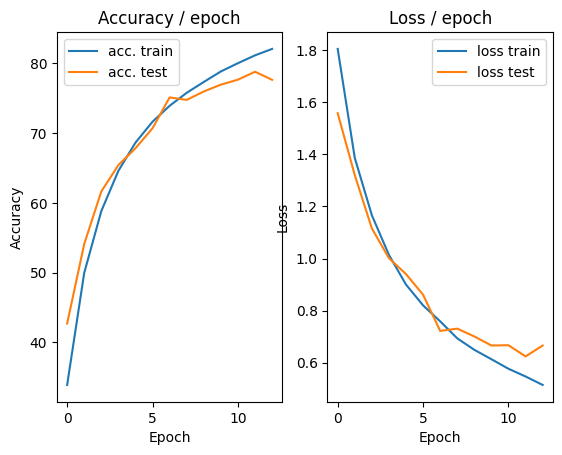

=== EPOCH 14 =====

[TRAIN Batch 000/391]	Time 0.202s (0.202s)	Loss 0.5490 (0.5490)	Prec@1  82.0 ( 82.0)	Prec@5  99.2 ( 99.2)


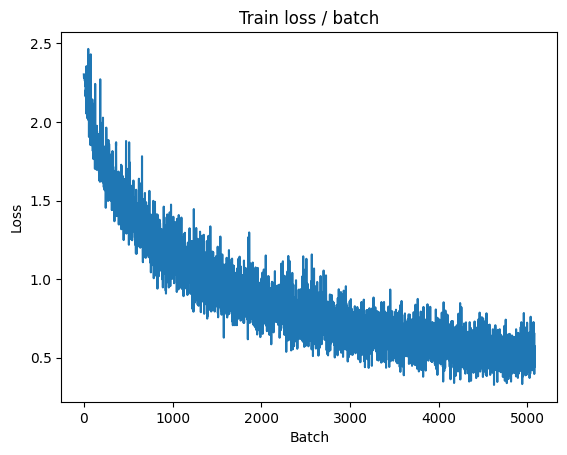

[TRAIN Batch 200/391]	Time 0.010s (0.039s)	Loss 0.4549 (0.4873)	Prec@1  83.6 ( 82.9)	Prec@5  99.2 ( 99.4)


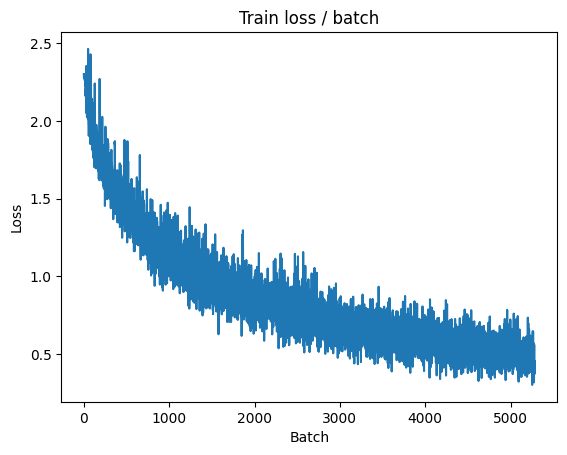


===============> Total time 16s	Avg loss 0.4908	Avg Prec@1 82.86 %	Avg Prec@5 99.32 %

[EVAL Batch 000/079]	Time 0.143s (0.143s)	Loss 0.6385 (0.6385)	Prec@1  81.2 ( 81.2)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.6479	Avg Prec@1 78.15 %	Avg Prec@5 98.59 %



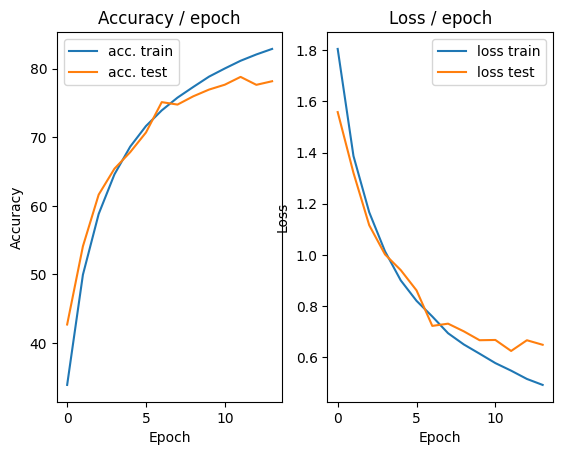

=== EPOCH 15 =====

[TRAIN Batch 000/391]	Time 0.187s (0.187s)	Loss 0.4790 (0.4790)	Prec@1  83.6 ( 83.6)	Prec@5  99.2 ( 99.2)


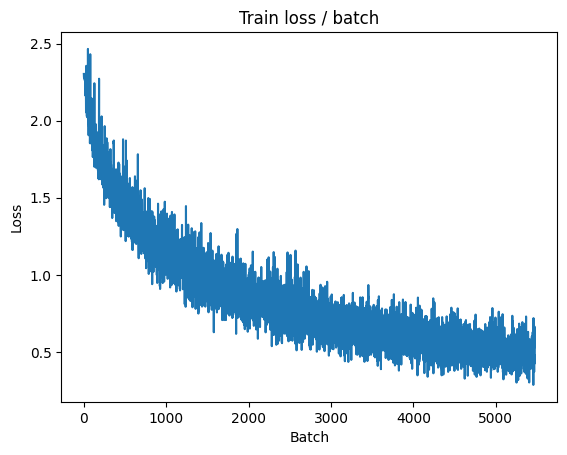

[TRAIN Batch 200/391]	Time 0.054s (0.043s)	Loss 0.4594 (0.4656)	Prec@1  84.4 ( 83.8)	Prec@5 100.0 ( 99.4)


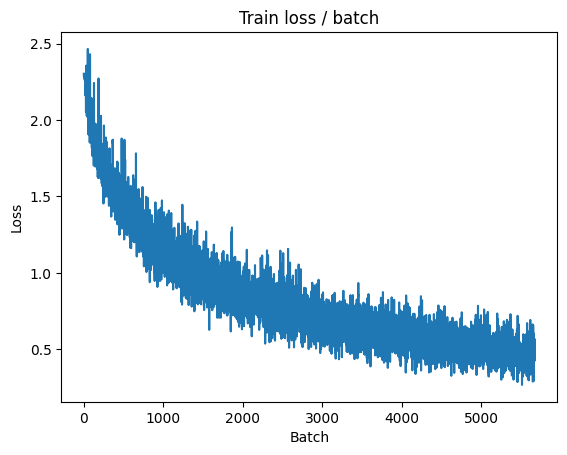


===============> Total time 17s	Avg loss 0.4637	Avg Prec@1 83.92 %	Avg Prec@5 99.38 %

[EVAL Batch 000/079]	Time 0.137s (0.137s)	Loss 0.5948 (0.5948)	Prec@1  80.5 ( 80.5)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.6080	Avg Prec@1 79.79 %	Avg Prec@5 98.76 %



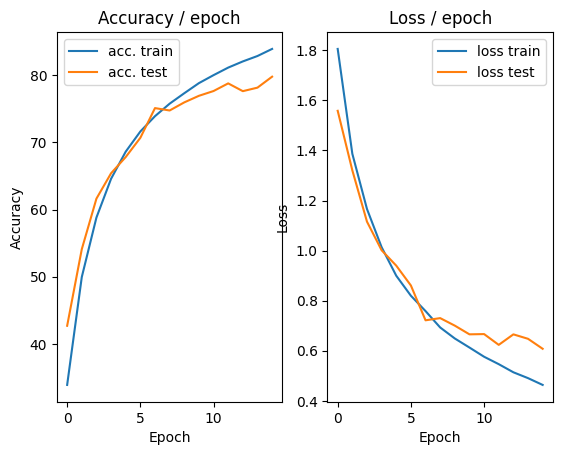

In [49]:
main(128, 0.1, cuda=True)

In [ ]:
# Other Optimizers : Adam
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000), # 64 * 4 * 4 = 1024
            nn.ReLU(),
            nn.Linear(1000, 10)
        )

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.RandomCrop(28),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.CenterCrop(28),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader


def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.001, epochs=10, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr)

    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)

        # Update the learning rate at the end of the epoch
        scheduler.step()

=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.156s (0.156s)	Loss 2.3013 (2.3013)	Prec@1  10.9 ( 10.9)	Prec@5  51.6 ( 51.6)


<Figure size 640x480 with 0 Axes>

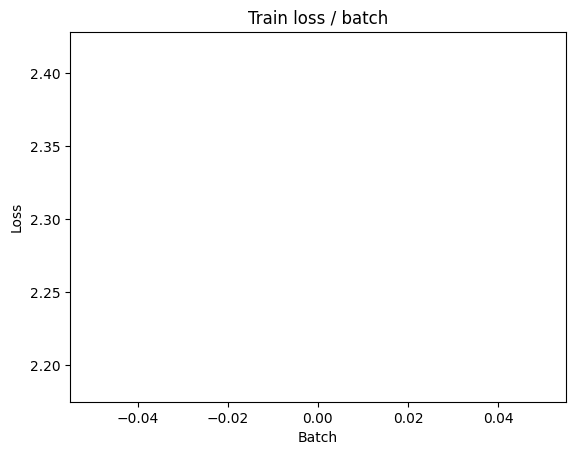

[TRAIN Batch 200/391]	Time 0.012s (0.041s)	Loss 1.6039 (1.6365)	Prec@1  47.7 ( 39.7)	Prec@5  90.6 ( 88.4)


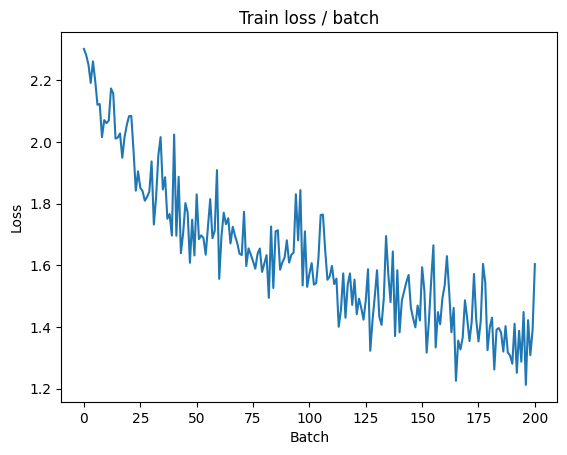


===============> Total time 16s	Avg loss 1.4582	Avg Prec@1 46.83 %	Avg Prec@5 91.39 %

[EVAL Batch 000/079]	Time 0.120s (0.120s)	Loss 1.1738 (1.1738)	Prec@1  63.3 ( 63.3)	Prec@5  94.5 ( 94.5)

===============> Total time 2s	Avg loss 1.1305	Avg Prec@1 59.45 %	Avg Prec@5 95.99 %



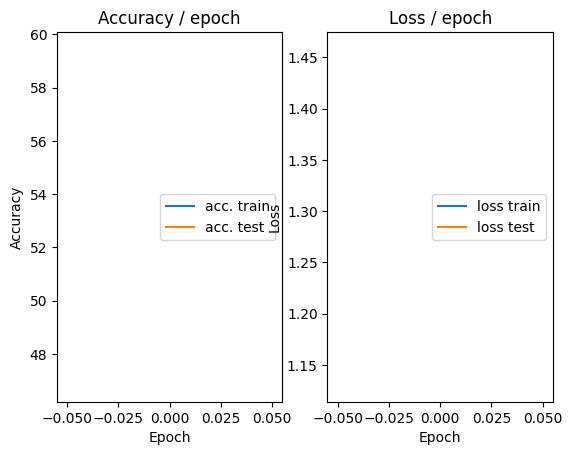

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.169s (0.169s)	Loss 1.2002 (1.2002)	Prec@1  58.6 ( 58.6)	Prec@5  93.8 ( 93.8)


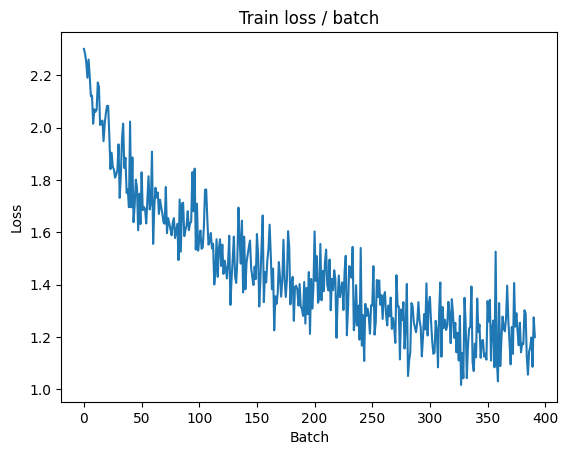

[TRAIN Batch 200/391]	Time 0.008s (0.044s)	Loss 1.0508 (1.0853)	Prec@1  60.2 ( 61.3)	Prec@5  97.7 ( 96.0)


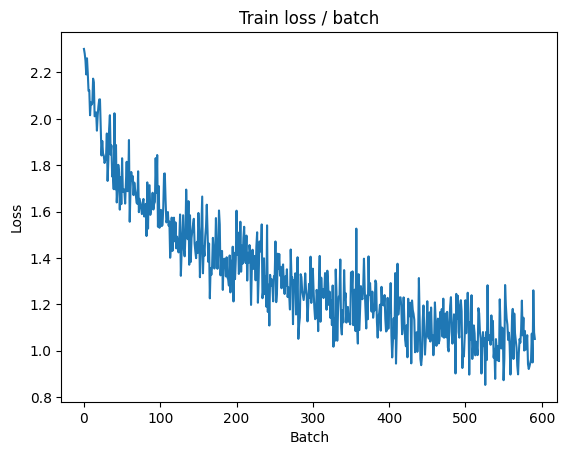


===============> Total time 16s	Avg loss 1.0386	Avg Prec@1 63.05 %	Avg Prec@5 96.45 %

[EVAL Batch 000/079]	Time 0.129s (0.129s)	Loss 0.8729 (0.8729)	Prec@1  74.2 ( 74.2)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.9149	Avg Prec@1 68.00 %	Avg Prec@5 97.49 %



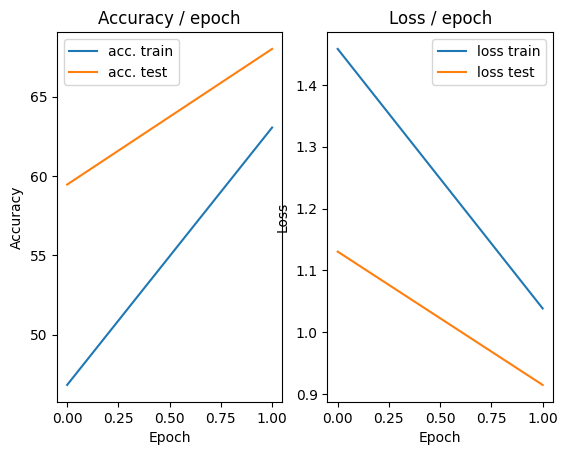

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.158s (0.158s)	Loss 0.8953 (0.8953)	Prec@1  72.7 ( 72.7)	Prec@5  97.7 ( 97.7)


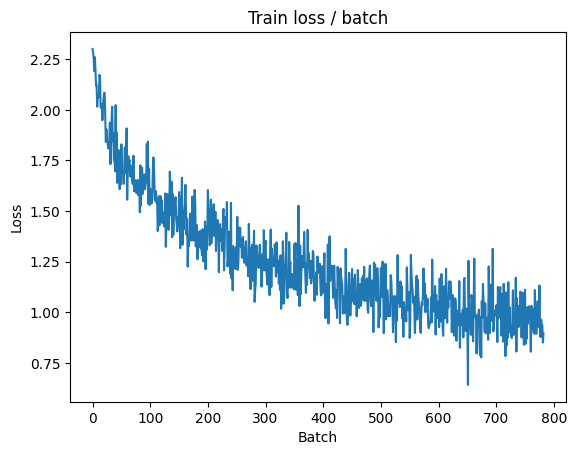

[TRAIN Batch 200/391]	Time 0.014s (0.041s)	Loss 1.1011 (0.8975)	Prec@1  64.8 ( 68.3)	Prec@5  97.7 ( 97.6)


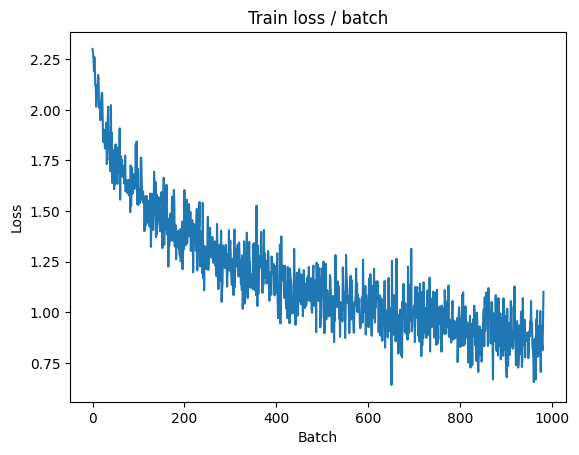


===============> Total time 15s	Avg loss 0.8813	Avg Prec@1 68.98 %	Avg Prec@5 97.63 %

[EVAL Batch 000/079]	Time 0.123s (0.123s)	Loss 0.7776 (0.7776)	Prec@1  72.7 ( 72.7)	Prec@5 100.0 (100.0)

===============> Total time 2s	Avg loss 0.8251	Avg Prec@1 71.06 %	Avg Prec@5 97.69 %



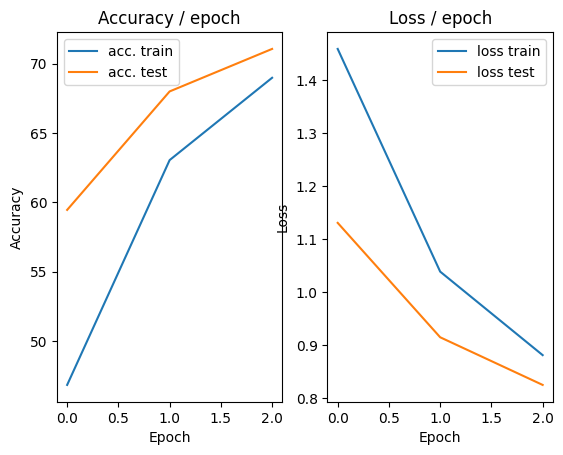

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.170s (0.170s)	Loss 0.7233 (0.7233)	Prec@1  72.7 ( 72.7)	Prec@5  97.7 ( 97.7)


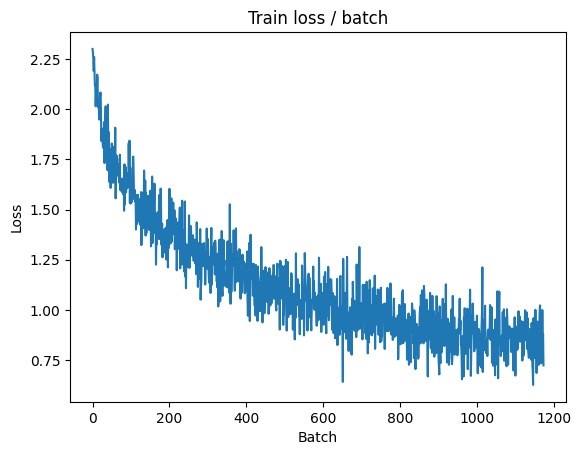

[TRAIN Batch 200/391]	Time 0.054s (0.042s)	Loss 0.6830 (0.8090)	Prec@1  75.8 ( 71.7)	Prec@5  99.2 ( 97.8)


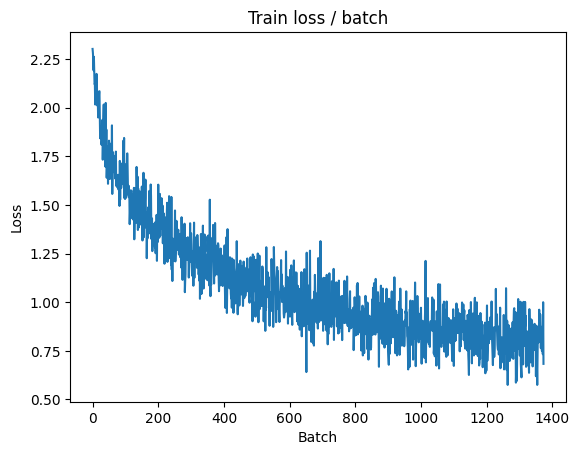


===============> Total time 16s	Avg loss 0.7870	Avg Prec@1 72.31 %	Avg Prec@5 97.94 %

[EVAL Batch 000/079]	Time 0.127s (0.127s)	Loss 0.7024 (0.7024)	Prec@1  75.8 ( 75.8)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.7558	Avg Prec@1 73.23 %	Avg Prec@5 98.35 %



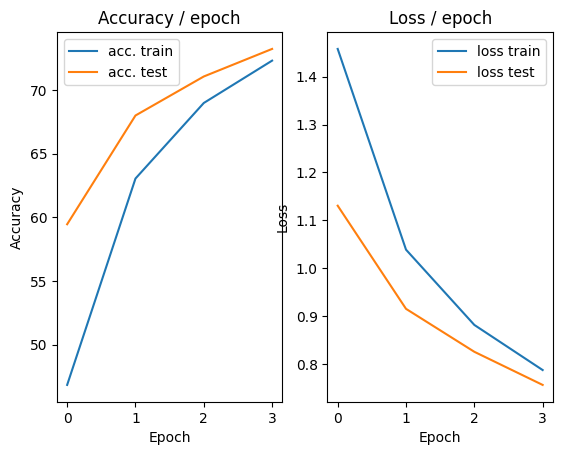

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.155s (0.155s)	Loss 0.6676 (0.6676)	Prec@1  77.3 ( 77.3)	Prec@5  99.2 ( 99.2)


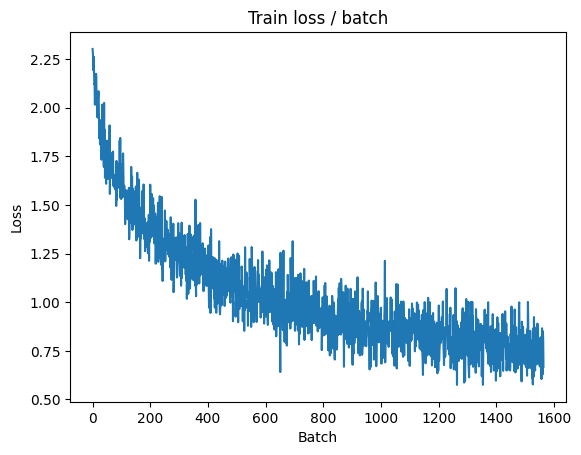

[TRAIN Batch 200/391]	Time 0.103s (0.043s)	Loss 0.7522 (0.7198)	Prec@1  74.2 ( 74.8)	Prec@5  96.1 ( 98.4)


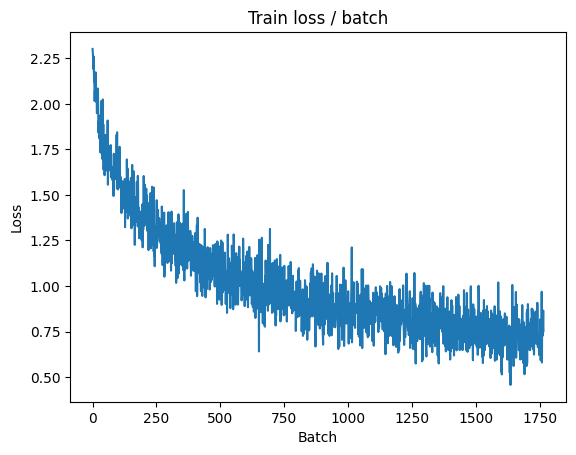


===============> Total time 15s	Avg loss 0.7155	Avg Prec@1 74.83 %	Avg Prec@5 98.45 %

[EVAL Batch 000/079]	Time 0.148s (0.148s)	Loss 0.6490 (0.6490)	Prec@1  81.2 ( 81.2)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.7211	Avg Prec@1 74.73 %	Avg Prec@5 98.40 %



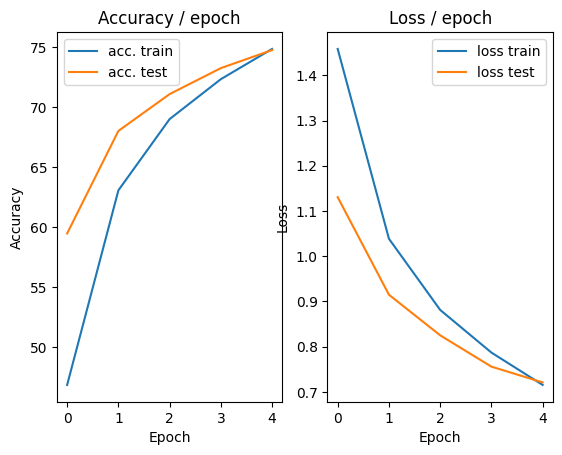

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.159s (0.159s)	Loss 0.6609 (0.6609)	Prec@1  76.6 ( 76.6)	Prec@5  99.2 ( 99.2)


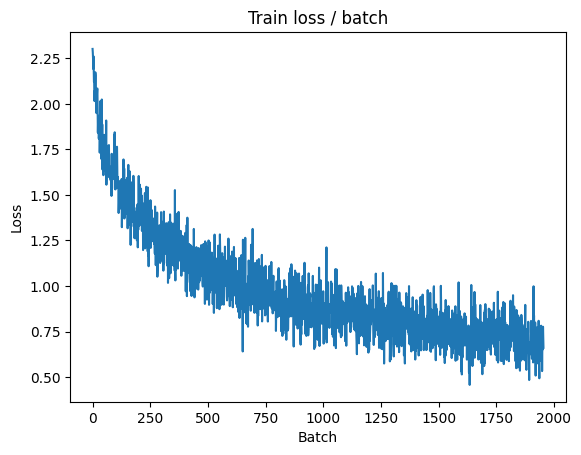

[TRAIN Batch 200/391]	Time 0.070s (0.043s)	Loss 0.5464 (0.6642)	Prec@1  82.0 ( 76.7)	Prec@5 100.0 ( 98.6)


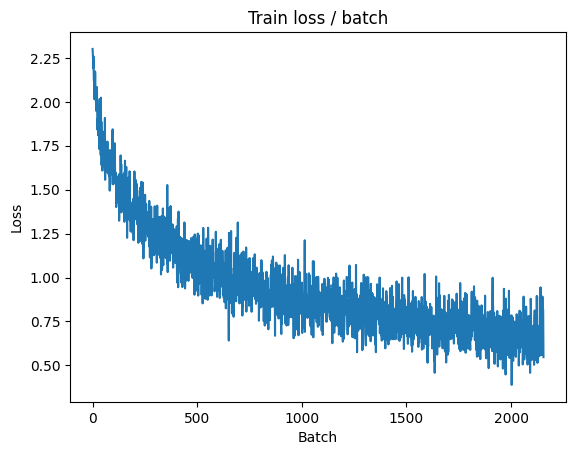


===============> Total time 16s	Avg loss 0.6605	Avg Prec@1 76.95 %	Avg Prec@5 98.60 %

[EVAL Batch 000/079]	Time 0.132s (0.132s)	Loss 0.6840 (0.6840)	Prec@1  79.7 ( 79.7)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.7044	Avg Prec@1 75.48 %	Avg Prec@5 98.46 %



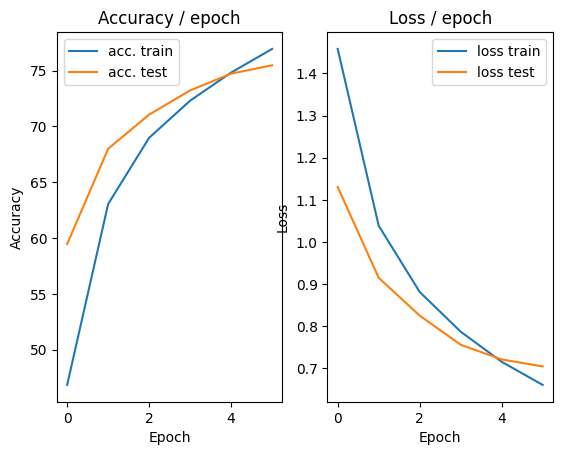

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.161s (0.161s)	Loss 0.6626 (0.6626)	Prec@1  75.8 ( 75.8)	Prec@5  97.7 ( 97.7)


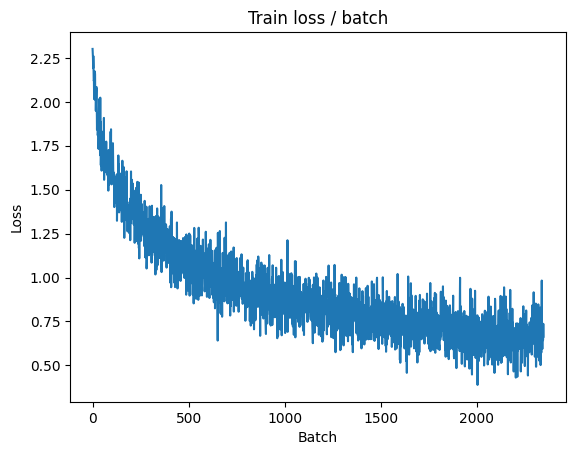

[TRAIN Batch 200/391]	Time 0.064s (0.043s)	Loss 0.6266 (0.6095)	Prec@1  75.0 ( 78.1)	Prec@5  99.2 ( 99.0)


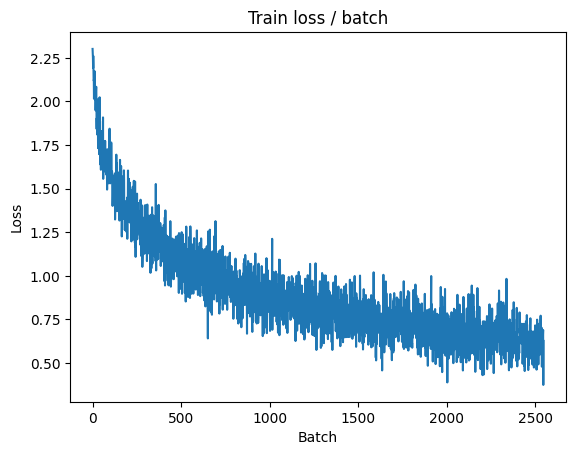


===============> Total time 15s	Avg loss 0.6152	Avg Prec@1 78.08 %	Avg Prec@5 98.88 %

[EVAL Batch 000/079]	Time 0.131s (0.131s)	Loss 0.6379 (0.6379)	Prec@1  78.9 ( 78.9)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.7157	Avg Prec@1 75.12 %	Avg Prec@5 98.58 %



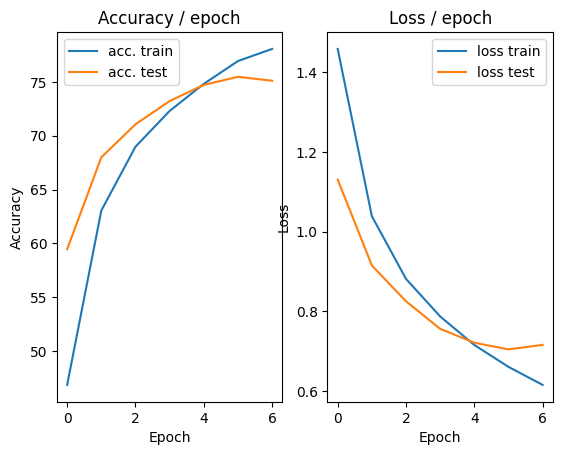

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.212s (0.212s)	Loss 0.6659 (0.6659)	Prec@1  79.7 ( 79.7)	Prec@5  97.7 ( 97.7)


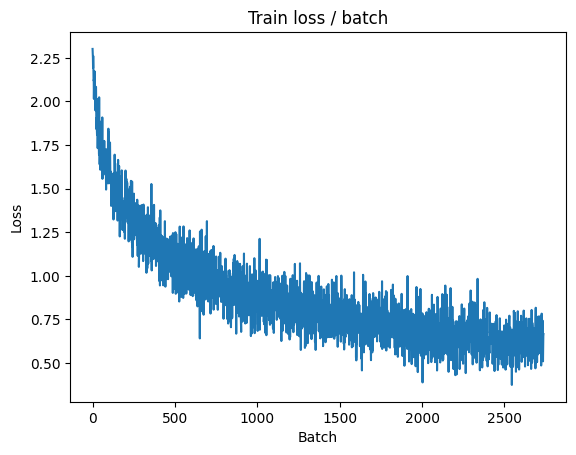

[TRAIN Batch 200/391]	Time 0.057s (0.043s)	Loss 0.4691 (0.5697)	Prec@1  85.9 ( 80.1)	Prec@5 100.0 ( 99.0)


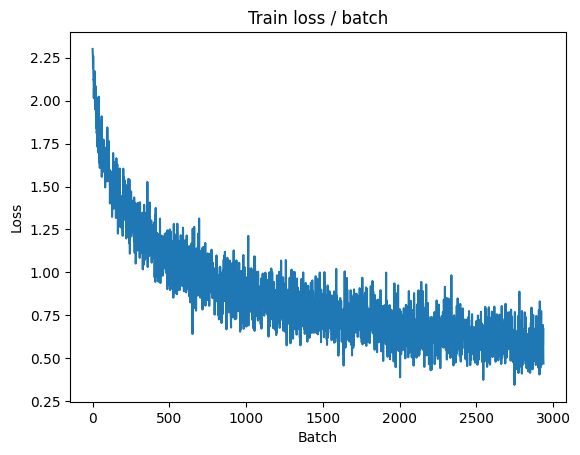


===============> Total time 16s	Avg loss 0.5708	Avg Prec@1 80.09 %	Avg Prec@5 98.94 %

[EVAL Batch 000/079]	Time 0.128s (0.128s)	Loss 0.6353 (0.6353)	Prec@1  82.0 ( 82.0)	Prec@5 100.0 (100.0)

===============> Total time 2s	Avg loss 0.6479	Avg Prec@1 77.87 %	Avg Prec@5 98.68 %



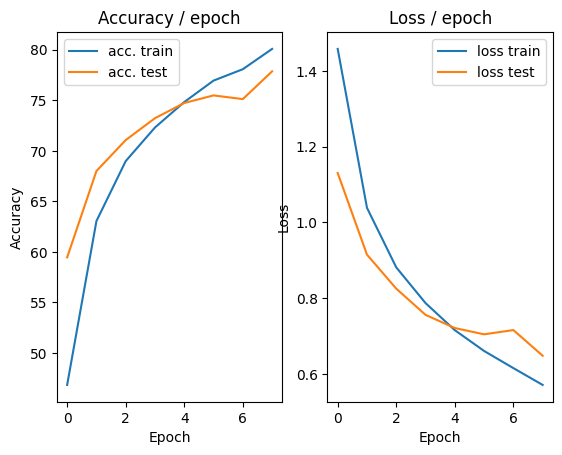

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.166s (0.166s)	Loss 0.4617 (0.4617)	Prec@1  82.8 ( 82.8)	Prec@5  99.2 ( 99.2)


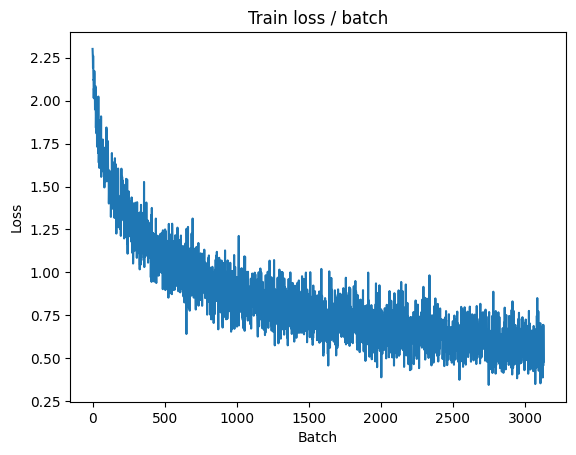

[TRAIN Batch 200/391]	Time 0.016s (0.043s)	Loss 0.5039 (0.5307)	Prec@1  79.7 ( 81.2)	Prec@5  98.4 ( 99.2)


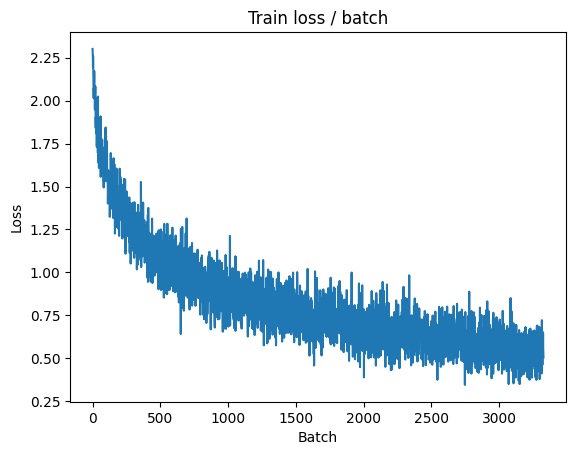


===============> Total time 15s	Avg loss 0.5294	Avg Prec@1 81.27 %	Avg Prec@5 99.18 %

[EVAL Batch 000/079]	Time 0.129s (0.129s)	Loss 0.6389 (0.6389)	Prec@1  83.6 ( 83.6)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.6495	Avg Prec@1 78.33 %	Avg Prec@5 98.69 %



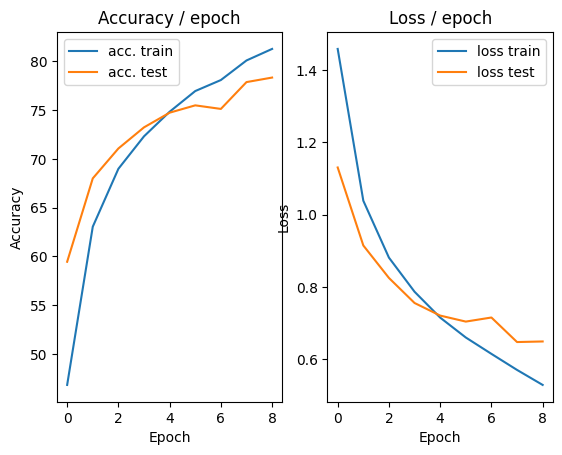

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.186s (0.186s)	Loss 0.4071 (0.4071)	Prec@1  82.8 ( 82.8)	Prec@5 100.0 (100.0)


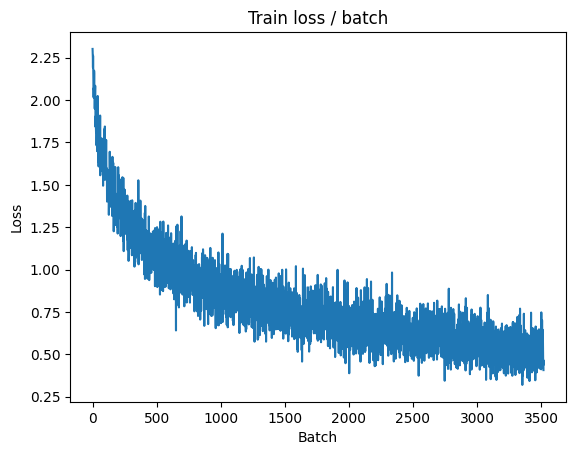

[TRAIN Batch 200/391]	Time 0.082s (0.042s)	Loss 0.3954 (0.4914)	Prec@1  86.7 ( 82.7)	Prec@5  99.2 ( 99.3)


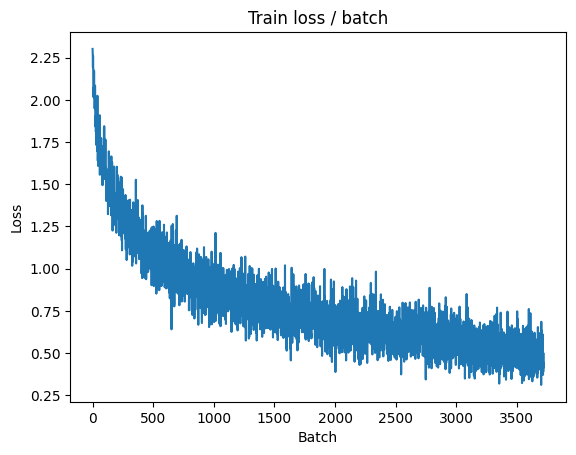


===============> Total time 17s	Avg loss 0.4971	Avg Prec@1 82.55 %	Avg Prec@5 99.26 %

[EVAL Batch 000/079]	Time 0.133s (0.133s)	Loss 0.6069 (0.6069)	Prec@1  84.4 ( 84.4)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.6263	Avg Prec@1 78.71 %	Avg Prec@5 98.70 %



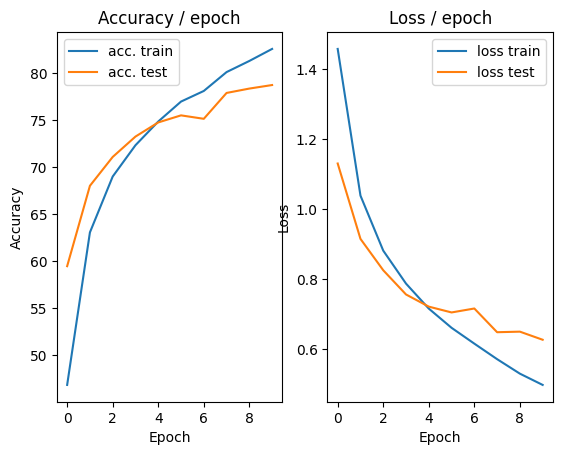

In [ ]:
main(128, 0.001, cuda=True)

In [ ]:
# Other learning rate strategies : ReduceLROnPlateau
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000), # 64 * 4 * 4 = 1024
            nn.ReLU(),
            nn.Linear(1000, 10)
        )

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.RandomCrop(28),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.CenterCrop(28),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader


def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=10, cuda=False):

    # ... (model, criterion setup) ...
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)

        # Test phase
        # We need the average test loss to pass to the scheduler
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)

        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)

        scheduler.step(loss_test.avg)

=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.148s (0.148s)	Loss 2.3072 (2.3072)	Prec@1   7.8 (  7.8)	Prec@5  49.2 ( 49.2)


<Figure size 640x480 with 0 Axes>

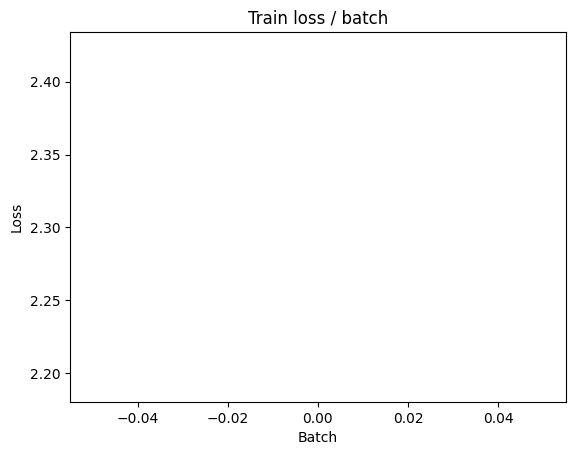

[TRAIN Batch 200/391]	Time 0.049s (0.042s)	Loss 1.8102 (1.9628)	Prec@1  32.0 ( 27.6)	Prec@5  87.5 ( 78.3)


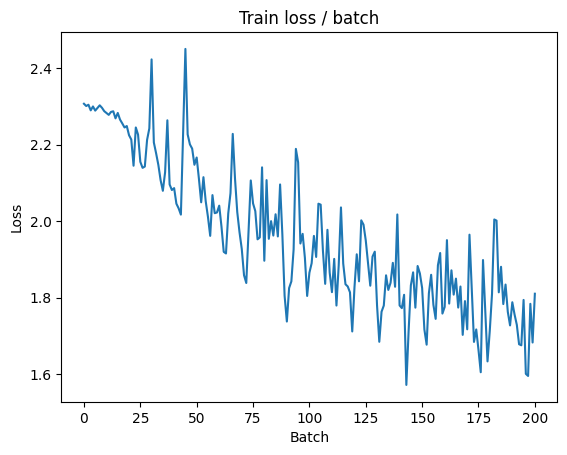


===============> Total time 15s	Avg loss 1.7983	Avg Prec@1 34.29 %	Avg Prec@5 83.75 %

[EVAL Batch 000/079]	Time 0.118s (0.118s)	Loss 1.4703 (1.4703)	Prec@1  51.6 ( 51.6)	Prec@5  90.6 ( 90.6)

===============> Total time 3s	Avg loss 1.4518	Avg Prec@1 46.30 %	Avg Prec@5 92.62 %



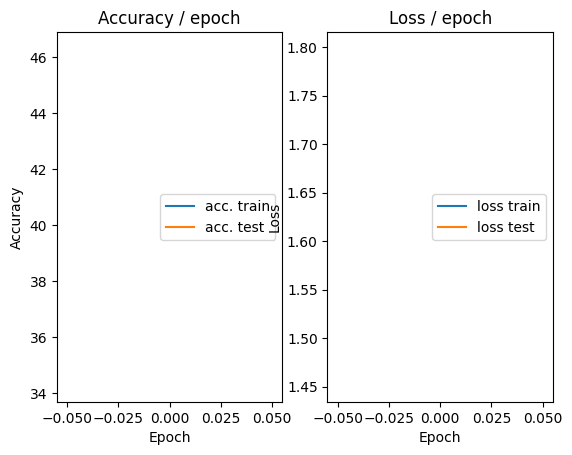

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.156s (0.156s)	Loss 1.6084 (1.6084)	Prec@1  36.7 ( 36.7)	Prec@5  90.6 ( 90.6)


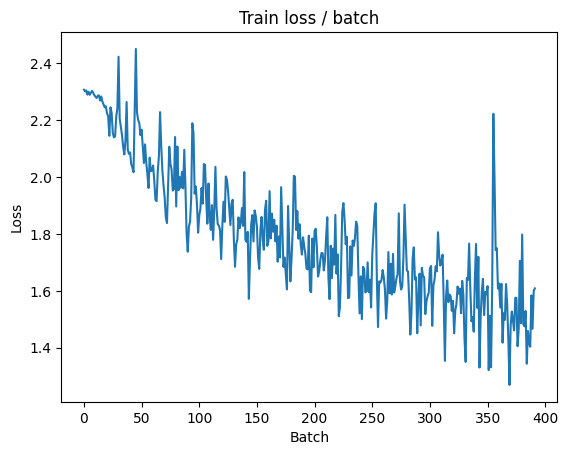

[TRAIN Batch 200/391]	Time 0.012s (0.038s)	Loss 1.2986 (1.4438)	Prec@1  49.2 ( 48.1)	Prec@5  96.9 ( 92.6)


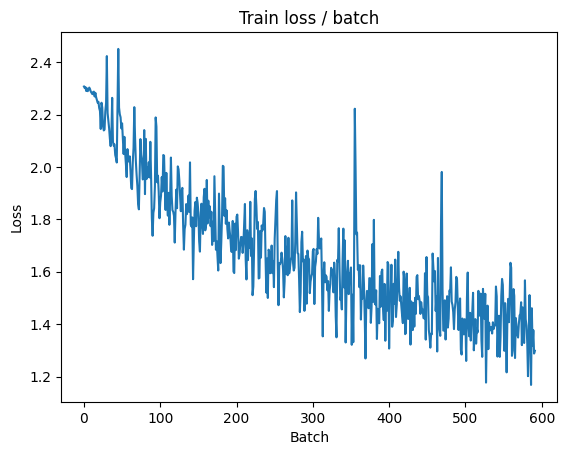


===============> Total time 15s	Avg loss 1.3869	Avg Prec@1 50.25 %	Avg Prec@5 93.25 %

[EVAL Batch 000/079]	Time 0.125s (0.125s)	Loss 1.1402 (1.1402)	Prec@1  64.1 ( 64.1)	Prec@5  95.3 ( 95.3)

===============> Total time 2s	Avg loss 1.1918	Avg Prec@1 57.96 %	Avg Prec@5 95.11 %



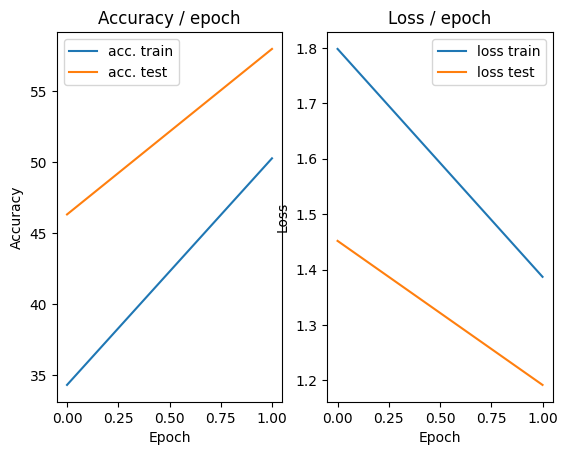

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.164s (0.164s)	Loss 1.1868 (1.1868)	Prec@1  58.6 ( 58.6)	Prec@5  96.1 ( 96.1)


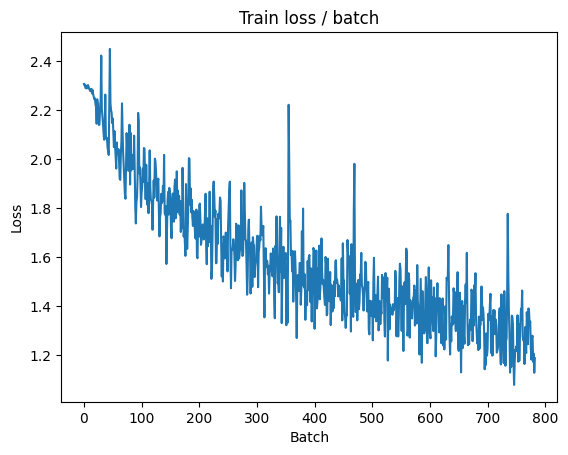

[TRAIN Batch 200/391]	Time 0.016s (0.041s)	Loss 1.2432 (1.2240)	Prec@1  57.8 ( 56.6)	Prec@5  93.0 ( 94.9)


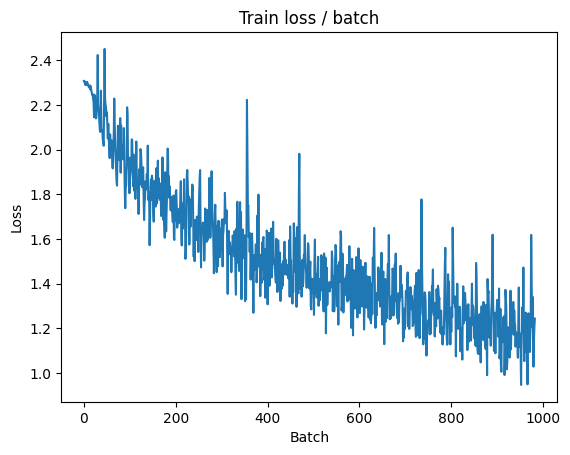


===============> Total time 15s	Avg loss 1.1857	Avg Prec@1 58.20 %	Avg Prec@5 95.23 %

[EVAL Batch 000/079]	Time 0.121s (0.121s)	Loss 1.0732 (1.0732)	Prec@1  64.8 ( 64.8)	Prec@5  95.3 ( 95.3)

===============> Total time 3s	Avg loss 1.1372	Avg Prec@1 60.04 %	Avg Prec@5 96.00 %



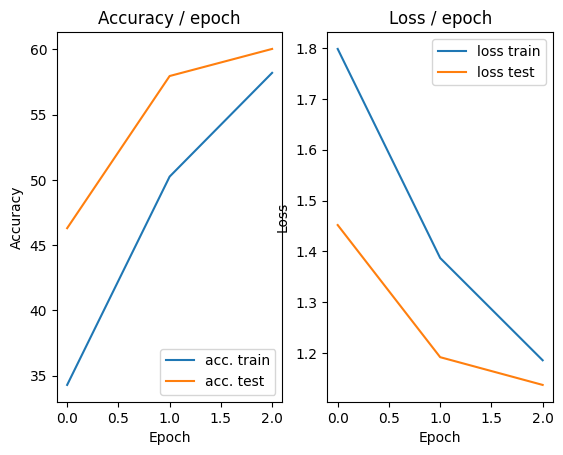

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.170s (0.170s)	Loss 1.1273 (1.1273)	Prec@1  60.9 ( 60.9)	Prec@5  96.9 ( 96.9)


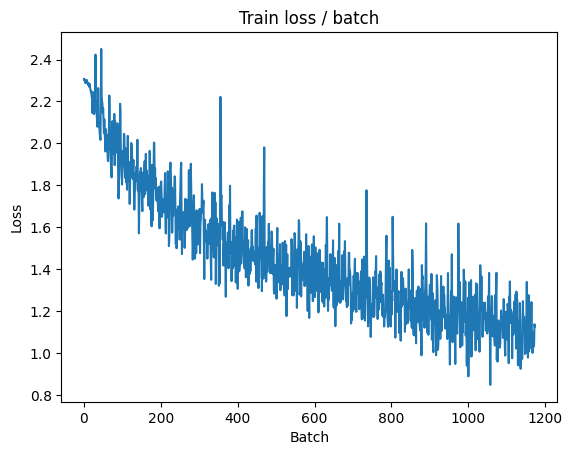

[TRAIN Batch 200/391]	Time 0.063s (0.038s)	Loss 1.1149 (1.0529)	Prec@1  56.2 ( 63.2)	Prec@5  96.1 ( 96.3)


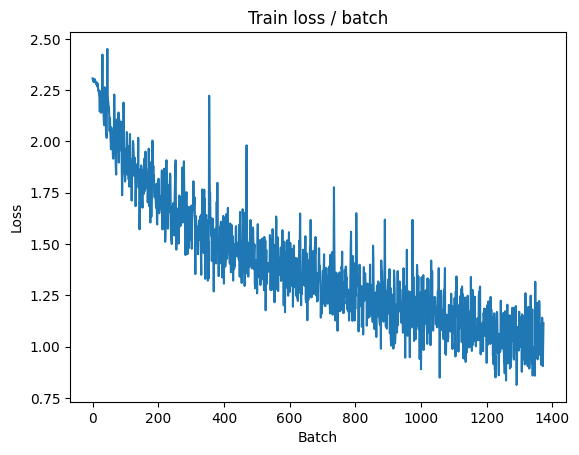


===============> Total time 15s	Avg loss 1.0339	Avg Prec@1 64.01 %	Avg Prec@5 96.42 %

[EVAL Batch 000/079]	Time 0.118s (0.118s)	Loss 0.8856 (0.8856)	Prec@1  73.4 ( 73.4)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.9271	Avg Prec@1 68.09 %	Avg Prec@5 96.75 %



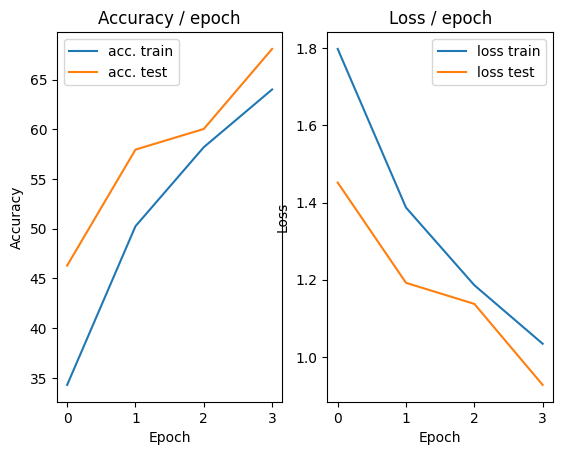

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.563s (0.563s)	Loss 0.8192 (0.8192)	Prec@1  71.9 ( 71.9)	Prec@5  98.4 ( 98.4)


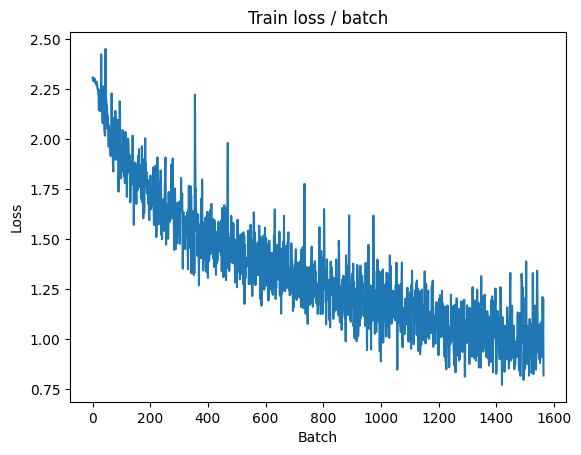

[TRAIN Batch 200/391]	Time 0.022s (0.045s)	Loss 0.9990 (0.9348)	Prec@1  63.3 ( 67.4)	Prec@5  96.9 ( 97.2)


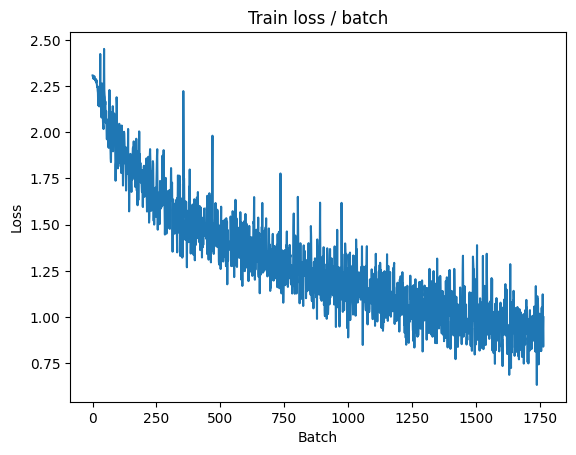


===============> Total time 17s	Avg loss 0.9191	Avg Prec@1 68.13 %	Avg Prec@5 97.29 %

[EVAL Batch 000/079]	Time 0.210s (0.210s)	Loss 0.8006 (0.8006)	Prec@1  74.2 ( 74.2)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.8315	Avg Prec@1 71.07 %	Avg Prec@5 97.72 %



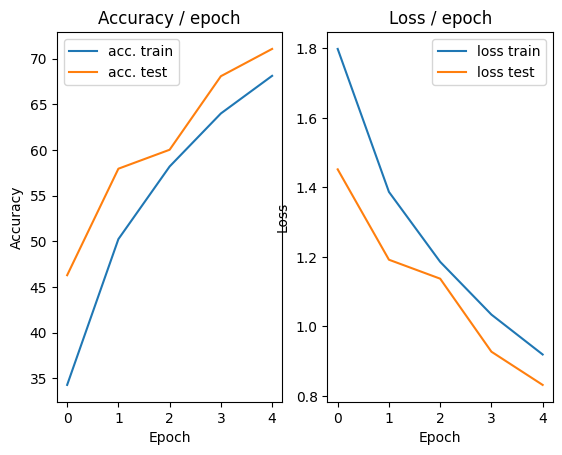

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.169s (0.169s)	Loss 0.6676 (0.6676)	Prec@1  78.9 ( 78.9)	Prec@5  99.2 ( 99.2)


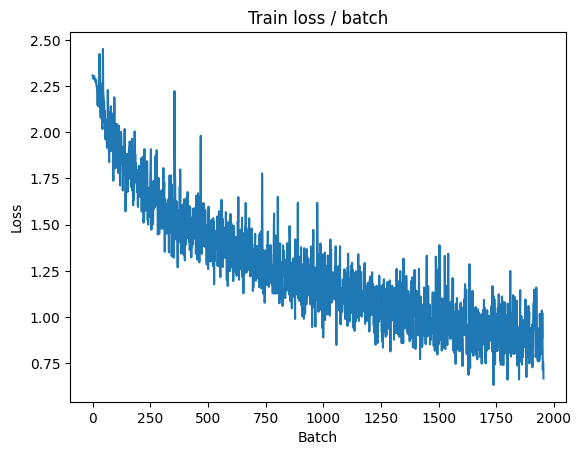

[TRAIN Batch 200/391]	Time 0.055s (0.038s)	Loss 0.9960 (0.8519)	Prec@1  66.4 ( 70.7)	Prec@5  96.1 ( 97.6)


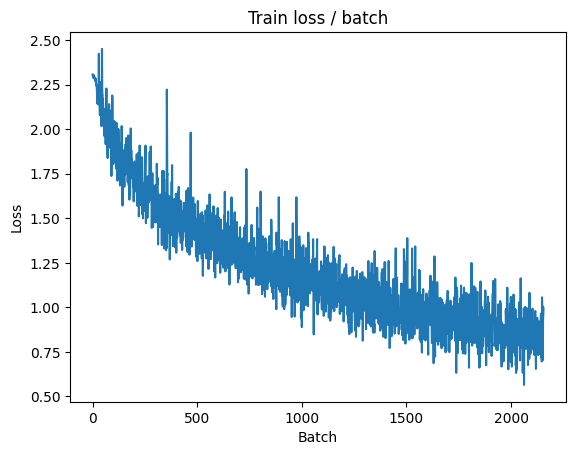


===============> Total time 15s	Avg loss 0.8417	Avg Prec@1 70.82 %	Avg Prec@5 97.63 %

[EVAL Batch 000/079]	Time 0.124s (0.124s)	Loss 0.7433 (0.7433)	Prec@1  76.6 ( 76.6)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.8364	Avg Prec@1 71.03 %	Avg Prec@5 97.84 %



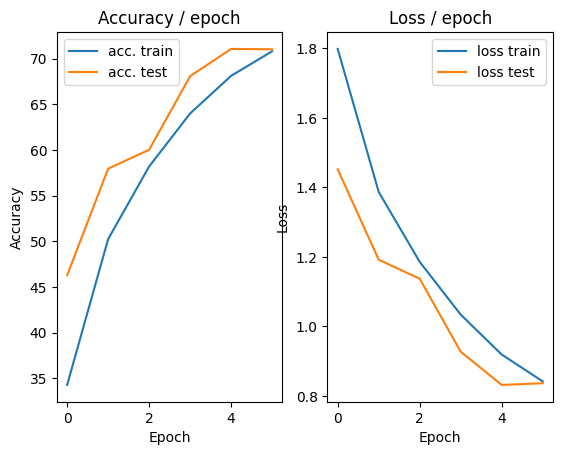

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.161s (0.161s)	Loss 0.7638 (0.7638)	Prec@1  72.7 ( 72.7)	Prec@5  99.2 ( 99.2)


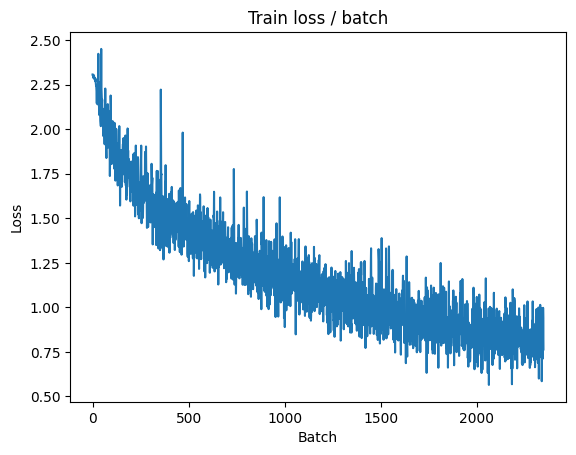

[TRAIN Batch 200/391]	Time 0.013s (0.042s)	Loss 0.6678 (0.7748)	Prec@1  76.6 ( 73.0)	Prec@5 100.0 ( 98.2)


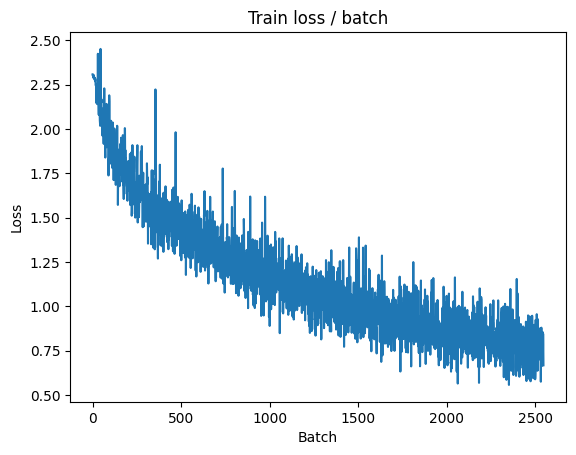


===============> Total time 15s	Avg loss 0.7740	Avg Prec@1 73.12 %	Avg Prec@5 98.10 %

[EVAL Batch 000/079]	Time 0.182s (0.182s)	Loss 0.8906 (0.8906)	Prec@1  71.1 ( 71.1)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 0.8648	Avg Prec@1 71.26 %	Avg Prec@5 97.80 %



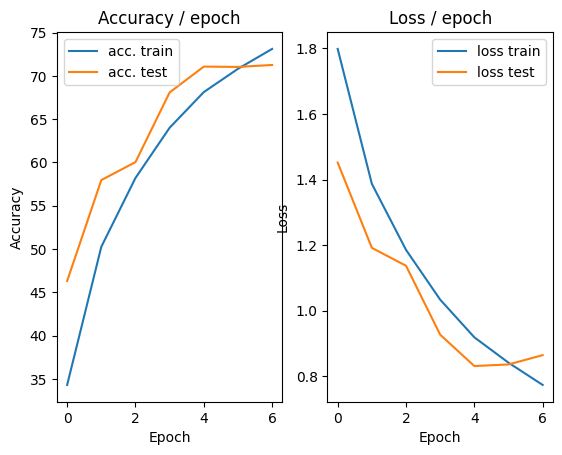

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.166s (0.166s)	Loss 0.7317 (0.7317)	Prec@1  71.9 ( 71.9)	Prec@5  98.4 ( 98.4)


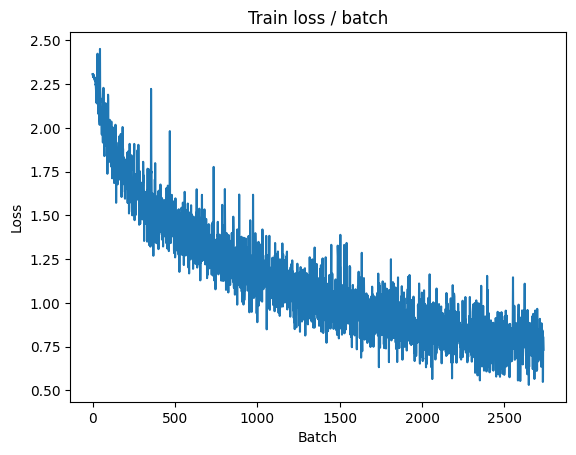

[TRAIN Batch 200/391]	Time 0.066s (0.038s)	Loss 0.5731 (0.7255)	Prec@1  80.5 ( 74.9)	Prec@5  99.2 ( 98.3)


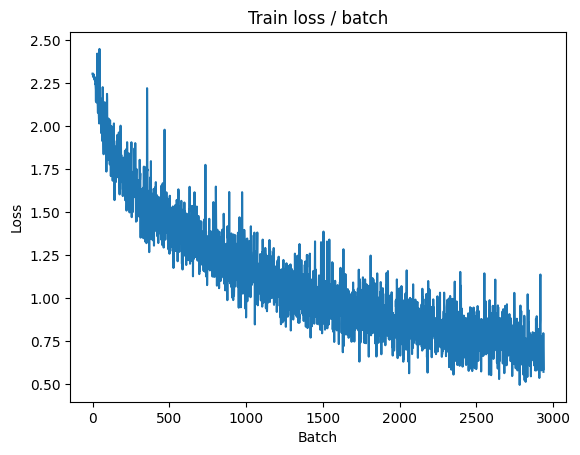


===============> Total time 15s	Avg loss 0.7194	Avg Prec@1 74.93 %	Avg Prec@5 98.31 %

[EVAL Batch 000/079]	Time 0.142s (0.142s)	Loss 0.6700 (0.6700)	Prec@1  75.0 ( 75.0)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.7802	Avg Prec@1 72.88 %	Avg Prec@5 98.02 %



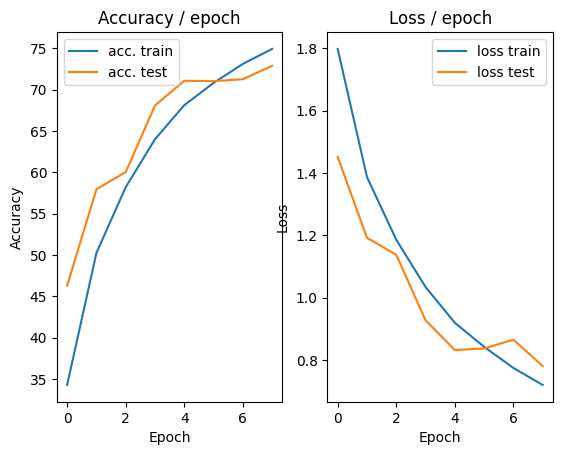

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.172s (0.172s)	Loss 0.5488 (0.5488)	Prec@1  79.7 ( 79.7)	Prec@5 100.0 (100.0)


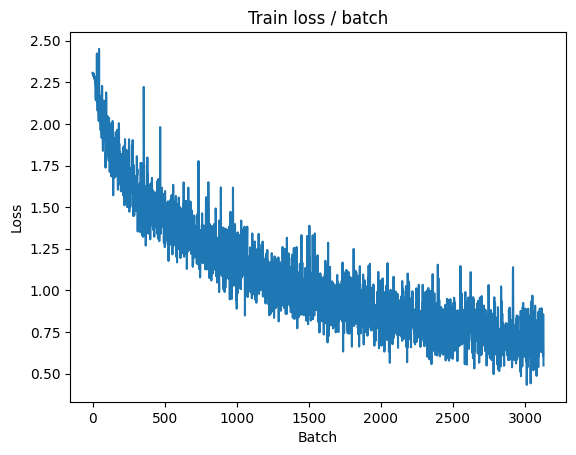

[TRAIN Batch 200/391]	Time 0.010s (0.042s)	Loss 0.6172 (0.6797)	Prec@1  81.2 ( 76.6)	Prec@5  97.7 ( 98.5)


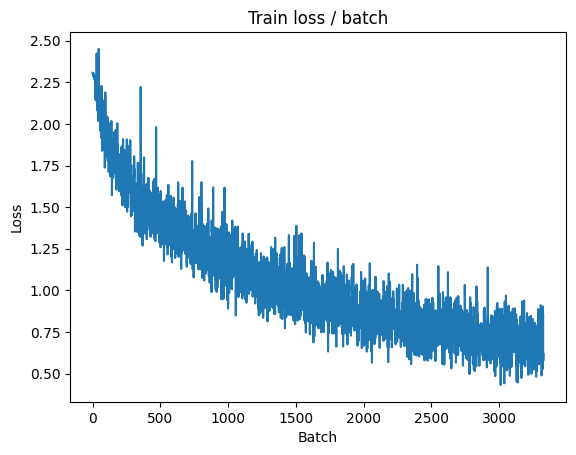


===============> Total time 15s	Avg loss 0.6733	Avg Prec@1 76.75 %	Avg Prec@5 98.54 %

[EVAL Batch 000/079]	Time 0.220s (0.220s)	Loss 0.7424 (0.7424)	Prec@1  75.0 ( 75.0)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.7660	Avg Prec@1 73.94 %	Avg Prec@5 97.93 %



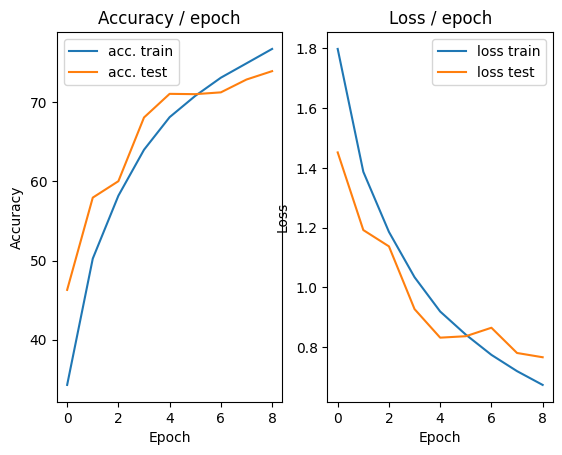

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.167s (0.167s)	Loss 0.8645 (0.8645)	Prec@1  68.8 ( 68.8)	Prec@5  98.4 ( 98.4)


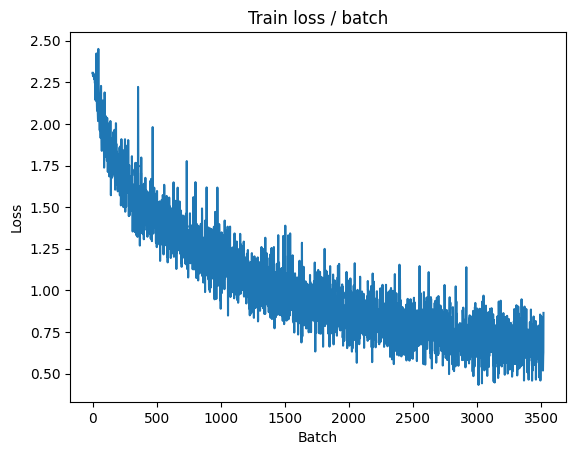

[TRAIN Batch 200/391]	Time 0.010s (0.038s)	Loss 0.7116 (0.6418)	Prec@1  71.9 ( 77.8)	Prec@5 100.0 ( 98.7)


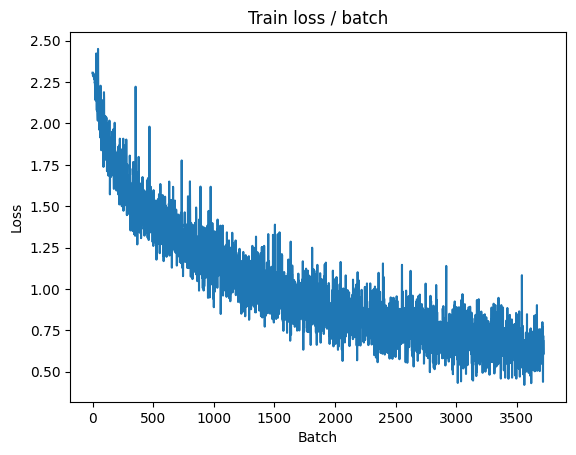


===============> Total time 15s	Avg loss 0.6377	Avg Prec@1 77.86 %	Avg Prec@5 98.75 %

[EVAL Batch 000/079]	Time 0.127s (0.127s)	Loss 0.7522 (0.7522)	Prec@1  75.8 ( 75.8)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.7692	Avg Prec@1 74.17 %	Avg Prec@5 98.12 %



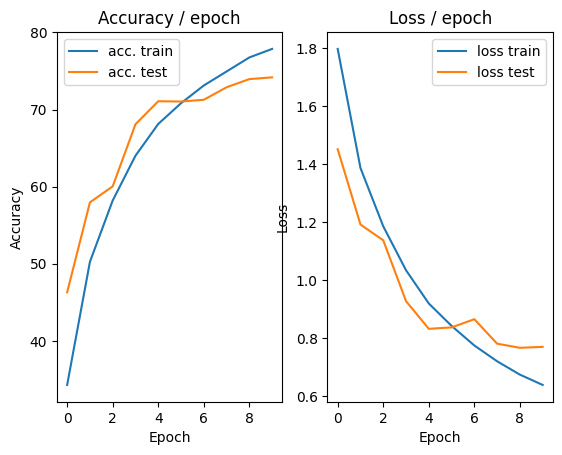

In [ ]:
main(128, 0.1, cuda = True)

In [6]:
# Regularization of the network by Dropout
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),
            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),
            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )


        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000), # fc4
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(1000, 10) # fc5
        )

    # The forward method remains unchanged
    def forward(self, input):
        bsize = input.size(0) # batch size
        output = self.features(input) # output of the conv layers
        output = output.view(bsize, -1) # we flatten the 2D feature maps
        output = self.classifier(output) # we compute the output of the fc layers
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader


def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=10, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)

=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.415s (0.415s)	Loss 2.3052 (2.3052)	Prec@1   9.4 (  9.4)	Prec@5  46.1 ( 46.1)


<Figure size 640x480 with 0 Axes>

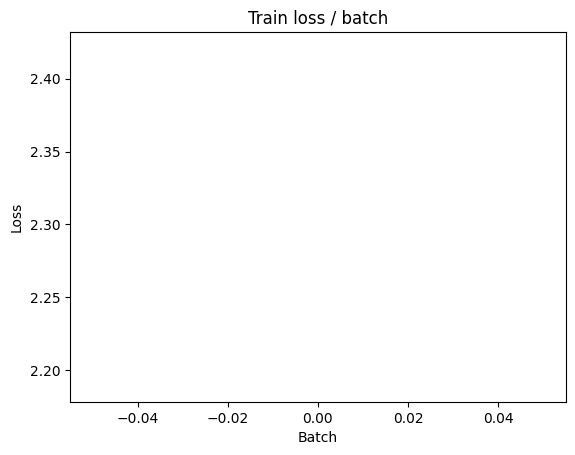

[TRAIN Batch 200/391]	Time 0.014s (0.020s)	Loss 2.1546 (2.2678)	Prec@1  23.4 ( 14.0)	Prec@5  77.3 ( 59.5)


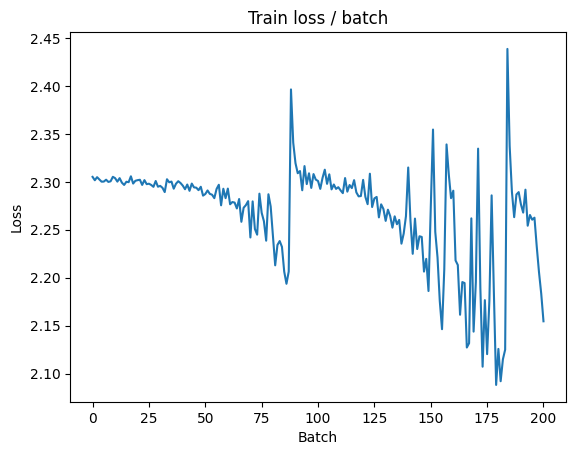


===============> Total time 7s	Avg loss 2.1612	Avg Prec@1 19.74 %	Avg Prec@5 67.51 %

[EVAL Batch 000/079]	Time 0.126s (0.126s)	Loss 1.8266 (1.8266)	Prec@1  40.6 ( 40.6)	Prec@5  84.4 ( 84.4)

===============> Total time 2s	Avg loss 1.8529	Avg Prec@1 33.27 %	Avg Prec@5 83.78 %



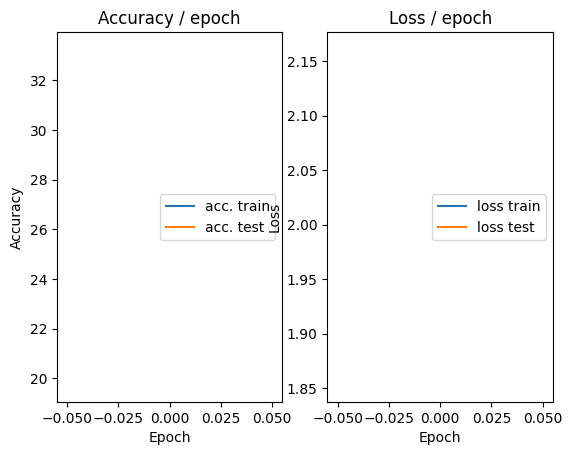

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.106s (0.106s)	Loss 1.8859 (1.8859)	Prec@1  32.0 ( 32.0)	Prec@5  81.2 ( 81.2)


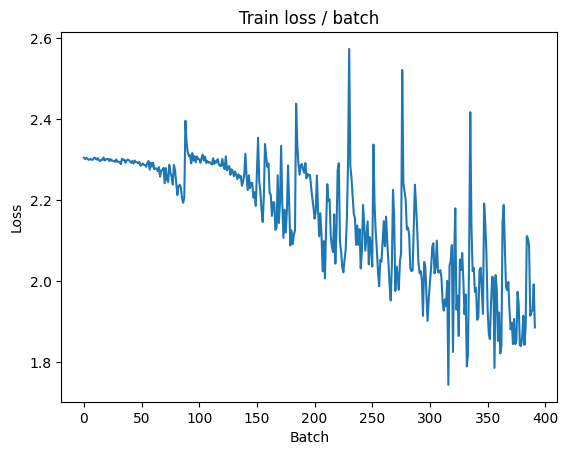

[TRAIN Batch 200/391]	Time 0.008s (0.019s)	Loss 1.6527 (1.8110)	Prec@1  40.6 ( 34.1)	Prec@5  87.5 ( 84.8)


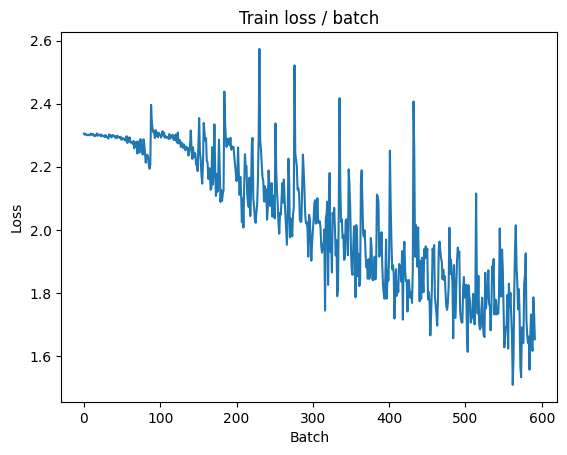


===============> Total time 7s	Avg loss 1.7344	Avg Prec@1 37.06 %	Avg Prec@5 86.77 %

[EVAL Batch 000/079]	Time 0.097s (0.097s)	Loss 1.5552 (1.5552)	Prec@1  49.2 ( 49.2)	Prec@5  88.3 ( 88.3)

===============> Total time 1s	Avg loss 1.5841	Avg Prec@1 42.97 %	Avg Prec@5 90.33 %



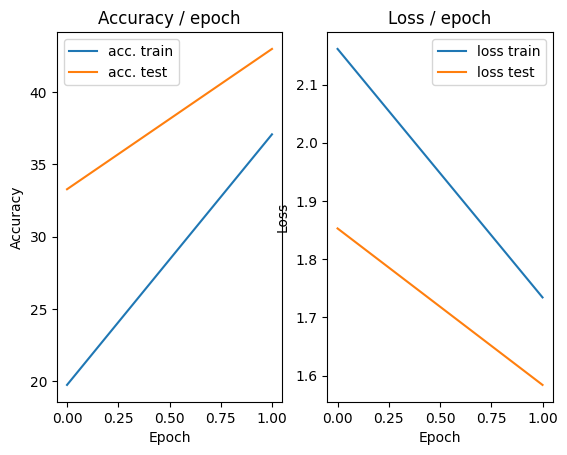

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.114s (0.114s)	Loss 1.6826 (1.6826)	Prec@1  35.2 ( 35.2)	Prec@5  89.8 ( 89.8)


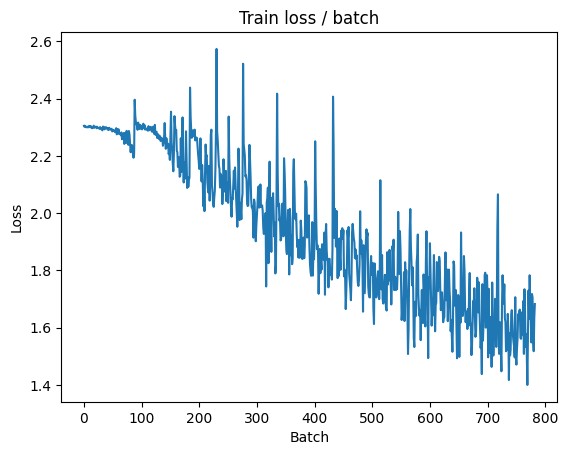

[TRAIN Batch 200/391]	Time 0.022s (0.024s)	Loss 1.6392 (1.5133)	Prec@1  39.8 ( 45.5)	Prec@5  87.5 ( 91.5)


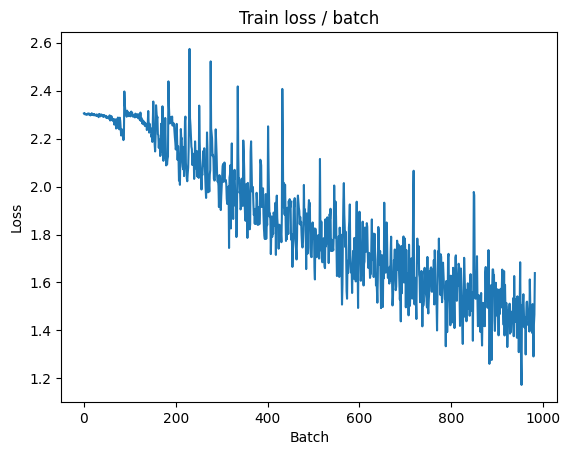


===============> Total time 8s	Avg loss 1.4734	Avg Prec@1 46.91 %	Avg Prec@5 91.92 %

[EVAL Batch 000/079]	Time 0.110s (0.110s)	Loss 1.3054 (1.3054)	Prec@1  53.9 ( 53.9)	Prec@5  95.3 ( 95.3)

===============> Total time 1s	Avg loss 1.4007	Avg Prec@1 50.36 %	Avg Prec@5 92.67 %



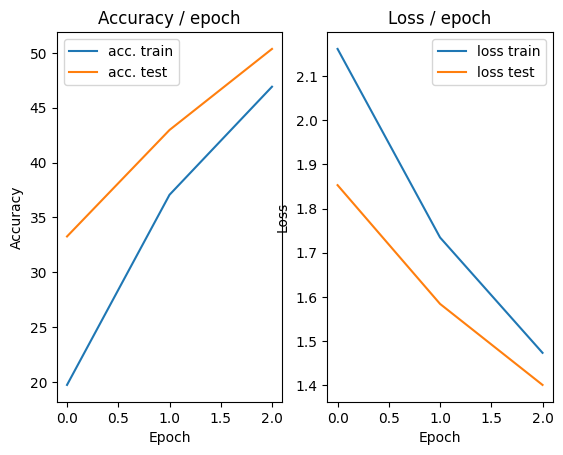

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.121s (0.121s)	Loss 1.3657 (1.3657)	Prec@1  52.3 ( 52.3)	Prec@5  95.3 ( 95.3)


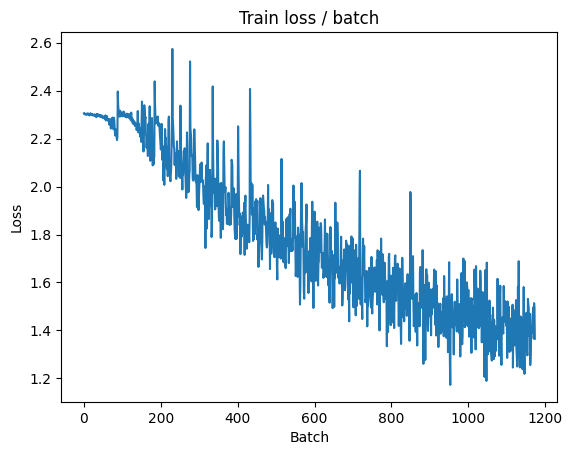

[TRAIN Batch 200/391]	Time 0.007s (0.021s)	Loss 1.6013 (1.3595)	Prec@1  44.5 ( 52.1)	Prec@5  89.8 ( 93.3)


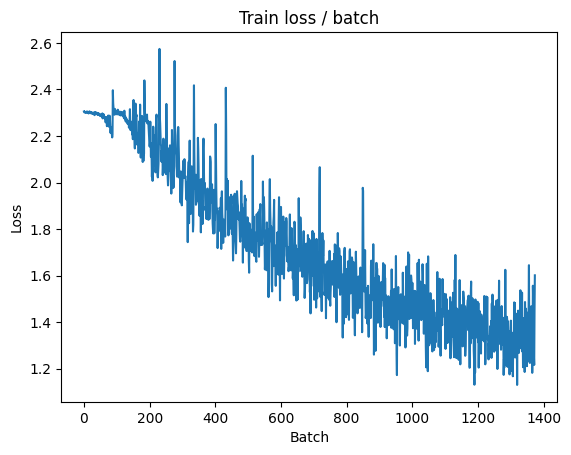


===============> Total time 8s	Avg loss 1.3340	Avg Prec@1 52.59 %	Avg Prec@5 93.80 %

[EVAL Batch 000/079]	Time 0.096s (0.096s)	Loss 1.2225 (1.2225)	Prec@1  56.2 ( 56.2)	Prec@5  96.9 ( 96.9)

===============> Total time 1s	Avg loss 1.3269	Avg Prec@1 52.02 %	Avg Prec@5 93.86 %



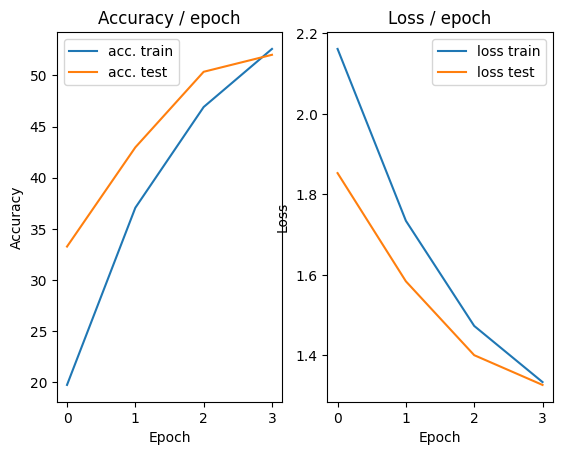

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.112s (0.112s)	Loss 1.2261 (1.2261)	Prec@1  54.7 ( 54.7)	Prec@5  95.3 ( 95.3)


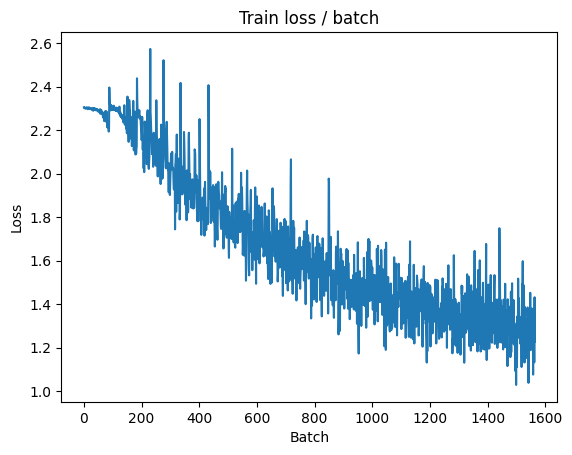

[TRAIN Batch 200/391]	Time 0.020s (0.019s)	Loss 1.1051 (1.2291)	Prec@1  65.6 ( 56.0)	Prec@5  93.8 ( 94.8)


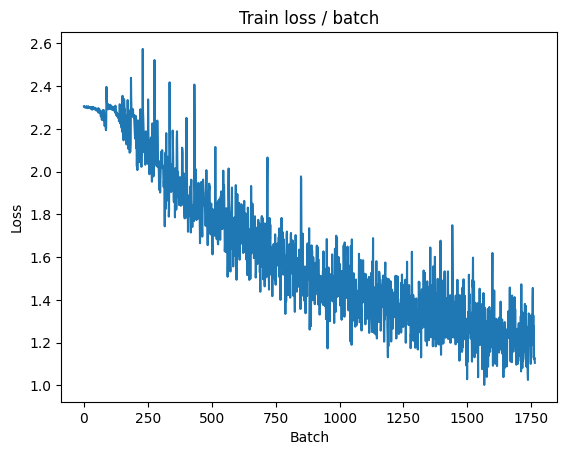


===============> Total time 8s	Avg loss 1.2087	Avg Prec@1 56.69 %	Avg Prec@5 95.09 %

[EVAL Batch 000/079]	Time 0.186s (0.186s)	Loss 0.9865 (0.9865)	Prec@1  65.6 ( 65.6)	Prec@5  93.8 ( 93.8)

===============> Total time 1s	Avg loss 1.1850	Avg Prec@1 56.96 %	Avg Prec@5 95.06 %



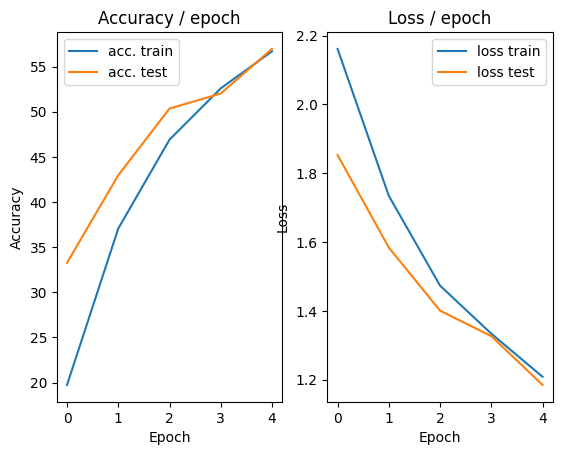

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.118s (0.118s)	Loss 1.0647 (1.0647)	Prec@1  60.9 ( 60.9)	Prec@5  97.7 ( 97.7)


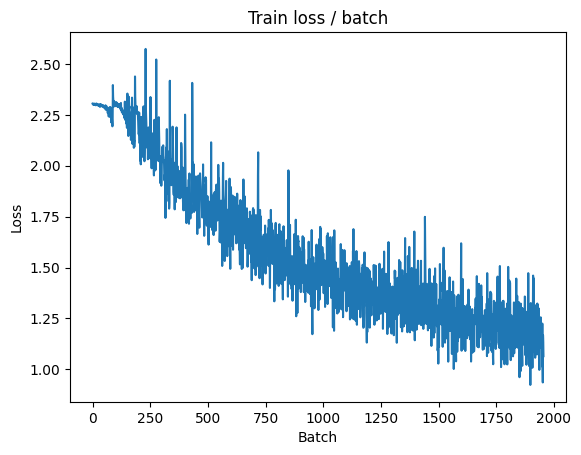

[TRAIN Batch 200/391]	Time 0.010s (0.019s)	Loss 0.9674 (1.1133)	Prec@1  64.1 ( 60.7)	Prec@5  97.7 ( 95.9)


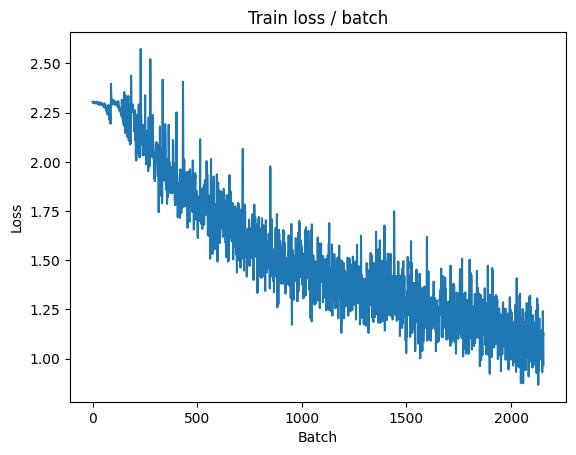


===============> Total time 7s	Avg loss 1.0990	Avg Prec@1 61.22 %	Avg Prec@5 96.01 %

[EVAL Batch 000/079]	Time 0.093s (0.093s)	Loss 1.0398 (1.0398)	Prec@1  63.3 ( 63.3)	Prec@5  96.9 ( 96.9)

===============> Total time 1s	Avg loss 1.1386	Avg Prec@1 60.00 %	Avg Prec@5 95.61 %



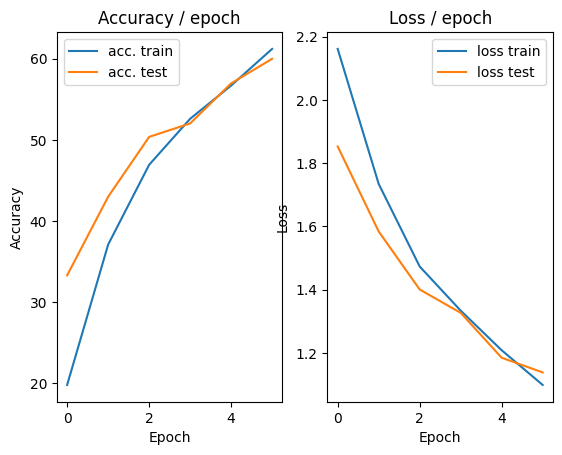

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.146s (0.146s)	Loss 0.9950 (0.9950)	Prec@1  66.4 ( 66.4)	Prec@5  96.9 ( 96.9)


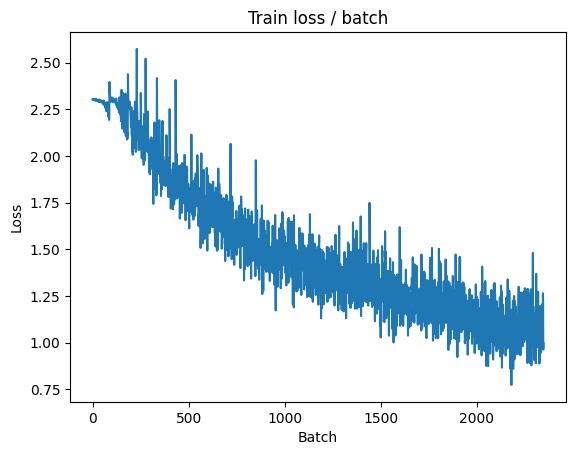

[TRAIN Batch 200/391]	Time 0.009s (0.023s)	Loss 1.0689 (1.0059)	Prec@1  60.2 ( 64.8)	Prec@5  96.1 ( 96.8)


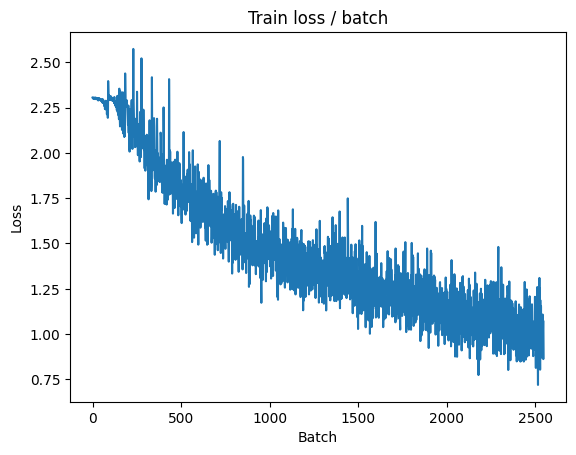


===============> Total time 8s	Avg loss 1.0020	Avg Prec@1 64.85 %	Avg Prec@5 96.81 %

[EVAL Batch 000/079]	Time 0.111s (0.111s)	Loss 0.8873 (0.8873)	Prec@1  73.4 ( 73.4)	Prec@5  97.7 ( 97.7)

===============> Total time 1s	Avg loss 0.9920	Avg Prec@1 65.20 %	Avg Prec@5 96.79 %



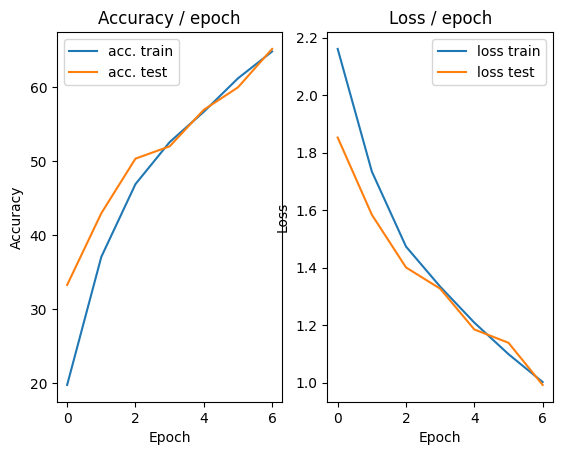

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.127s (0.127s)	Loss 0.8900 (0.8900)	Prec@1  68.0 ( 68.0)	Prec@5  96.9 ( 96.9)


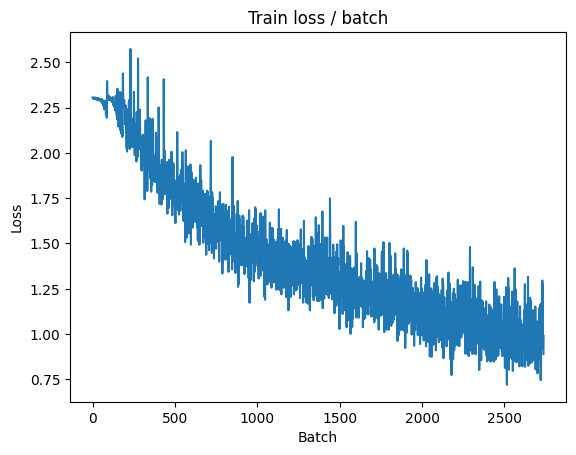

[TRAIN Batch 200/391]	Time 0.010s (0.024s)	Loss 0.9190 (0.9216)	Prec@1  68.0 ( 67.7)	Prec@5 100.0 ( 97.4)


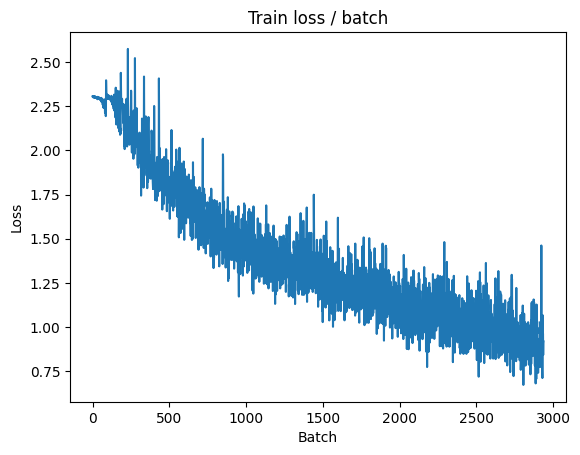


===============> Total time 8s	Avg loss 0.9177	Avg Prec@1 67.82 %	Avg Prec@5 97.34 %

[EVAL Batch 000/079]	Time 0.098s (0.098s)	Loss 0.8957 (0.8957)	Prec@1  68.8 ( 68.8)	Prec@5  99.2 ( 99.2)

===============> Total time 1s	Avg loss 0.9596	Avg Prec@1 66.37 %	Avg Prec@5 96.96 %



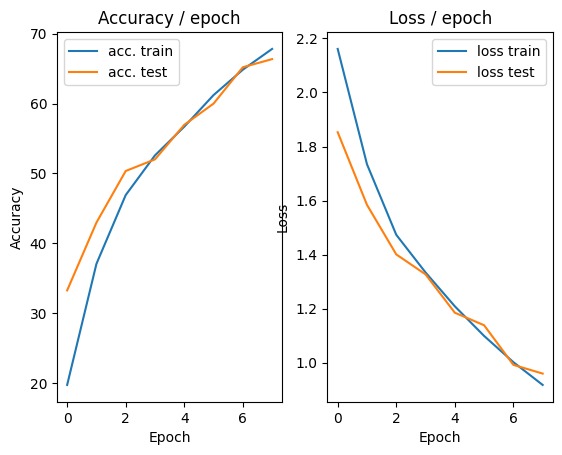

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.126s (0.126s)	Loss 0.9436 (0.9436)	Prec@1  67.2 ( 67.2)	Prec@5  96.1 ( 96.1)


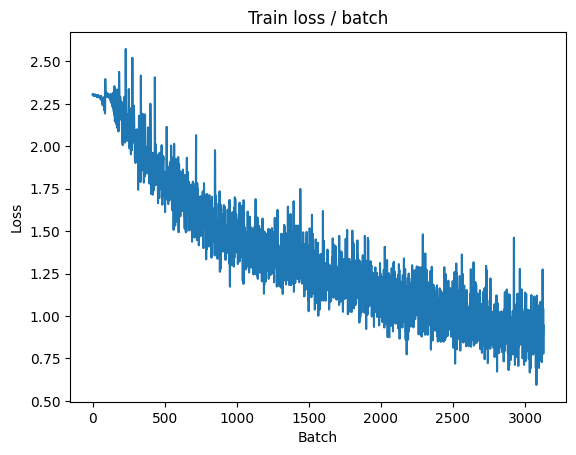

[TRAIN Batch 200/391]	Time 0.016s (0.019s)	Loss 0.9282 (0.8479)	Prec@1  69.5 ( 70.5)	Prec@5  95.3 ( 97.8)


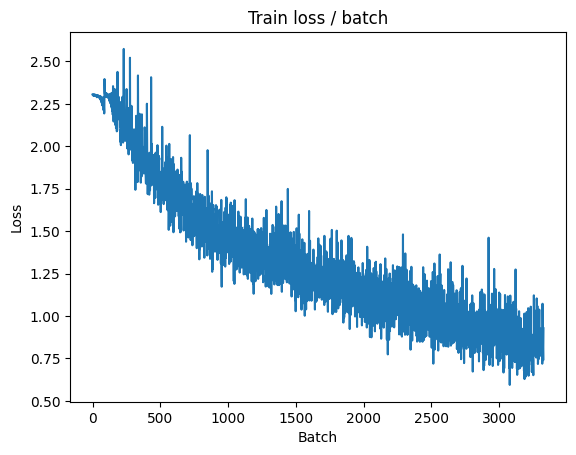


===============> Total time 8s	Avg loss 0.8395	Avg Prec@1 70.67 %	Avg Prec@5 97.86 %

[EVAL Batch 000/079]	Time 0.103s (0.103s)	Loss 0.8006 (0.8006)	Prec@1  73.4 ( 73.4)	Prec@5 100.0 (100.0)

===============> Total time 1s	Avg loss 0.8974	Avg Prec@1 68.89 %	Avg Prec@5 97.35 %



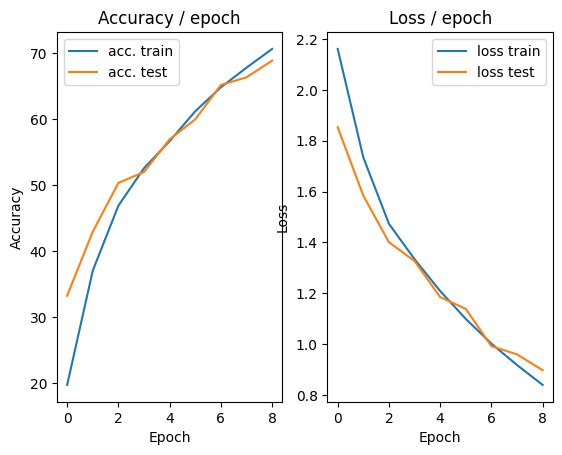

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.120s (0.120s)	Loss 0.8081 (0.8081)	Prec@1  71.9 ( 71.9)	Prec@5  98.4 ( 98.4)


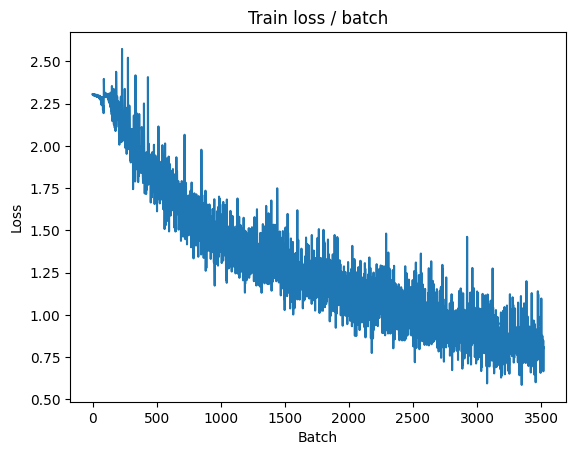

[TRAIN Batch 200/391]	Time 0.009s (0.019s)	Loss 0.6880 (0.7617)	Prec@1  75.8 ( 73.1)	Prec@5  99.2 ( 98.3)


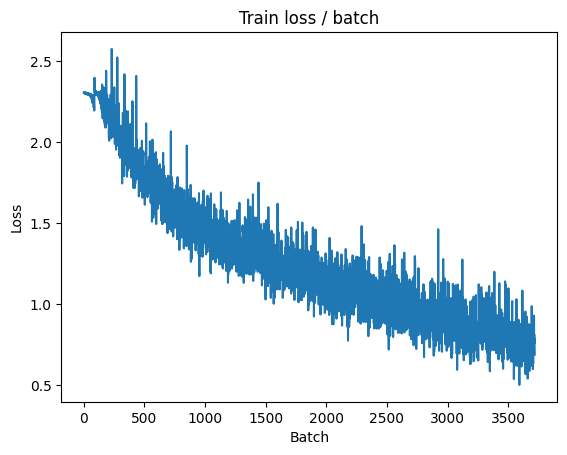


===============> Total time 7s	Avg loss 0.7688	Avg Prec@1 73.12 %	Avg Prec@5 98.18 %

[EVAL Batch 000/079]	Time 0.116s (0.116s)	Loss 0.8643 (0.8643)	Prec@1  69.5 ( 69.5)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.9003	Avg Prec@1 68.82 %	Avg Prec@5 97.21 %



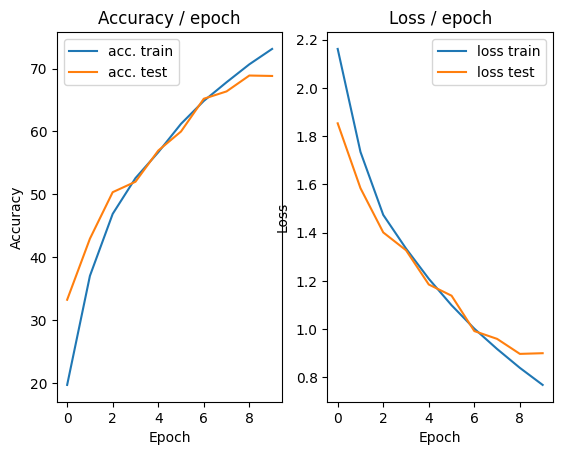

In [7]:
main(128, 0.1, cuda=True)

In [15]:
# Use of batch mormalization
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, (5, 5), stride=1, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            # Block 2
            nn.Conv2d(32, 64, (5, 5), stride=1, padding=2),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),

            # Block 3
            nn.Conv2d(64, 64, (5, 5), stride=1, padding=2),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 1000),
            nn.ReLU(),
            nn.Linear(1000, 10)
        )


    def forward(self, input):
        bsize = input.size(0) # batch size
        output = self.features(input) # output of the conv layers
        output = output.view(bsize, -1) # we flatten the 2D feature maps
        output = self.classifier(output) # we compute the output of the fc layers
        return output


def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """

    mean = [0.491, 0.482, 0.447]
    std = [0.202, 0.199, 0.201]


    # Add data augmentation for the training set
    train_transform = transforms.Compose([
        transforms.RandomCrop(28),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])

    # Add center cropping for the validation/test set
    val_transform = transforms.Compose([
        transforms.CenterCrop(28),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
        ])



    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,transform=train_transform) # Use the new train_transform

    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,transform=val_transform) # Use the new val_transform

    train_loader = torch.utils.data.DataLoader(train_dataset,batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader


def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.03, epochs=15, cuda=False):
    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)

=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.162s (0.162s)	Loss 2.3423 (2.3423)	Prec@1  10.2 ( 10.2)	Prec@5  55.5 ( 55.5)


<Figure size 640x480 with 0 Axes>

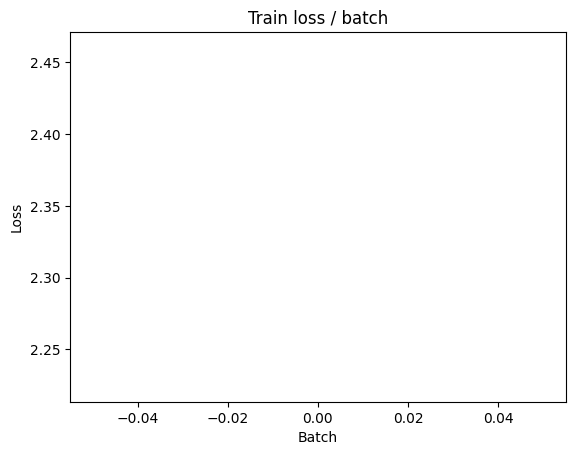

[TRAIN Batch 200/391]	Time 0.019s (0.039s)	Loss 1.3272 (1.6315)	Prec@1  50.8 ( 40.2)	Prec@5  94.5 ( 88.5)


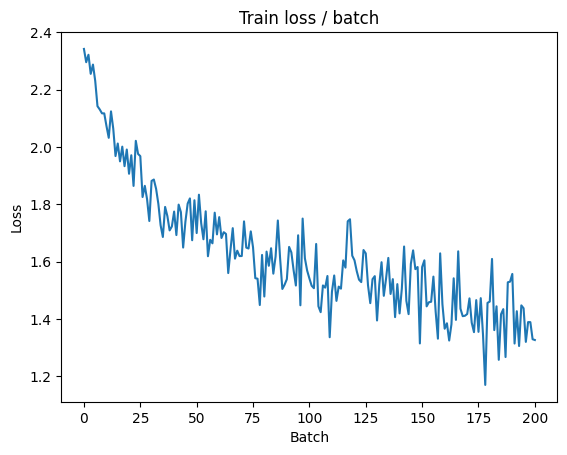


===============> Total time 15s	Avg loss 1.4806	Avg Prec@1 46.23 %	Avg Prec@5 91.18 %

[EVAL Batch 000/079]	Time 0.129s (0.129s)	Loss 1.1569 (1.1569)	Prec@1  59.4 ( 59.4)	Prec@5  91.4 ( 91.4)

===============> Total time 2s	Avg loss 1.2209	Avg Prec@1 56.57 %	Avg Prec@5 94.78 %



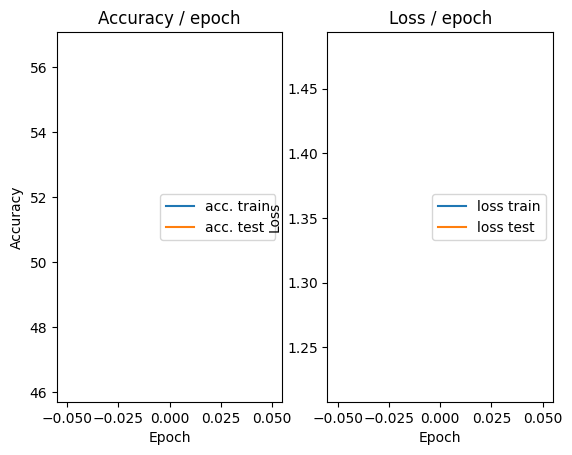

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.160s (0.160s)	Loss 1.2196 (1.2196)	Prec@1  53.1 ( 53.1)	Prec@5  96.1 ( 96.1)


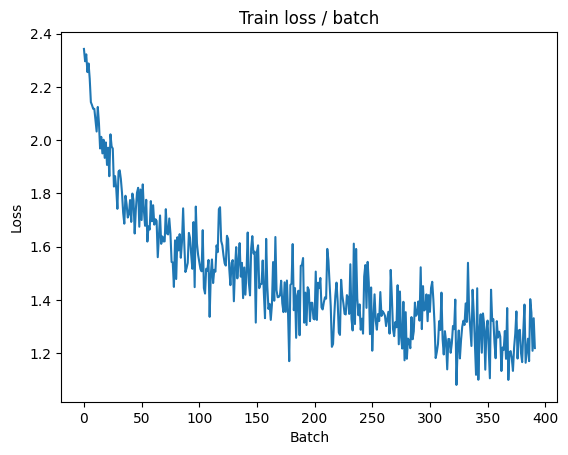

[TRAIN Batch 200/391]	Time 0.049s (0.044s)	Loss 1.0817 (1.1849)	Prec@1  66.4 ( 57.5)	Prec@5  95.3 ( 95.3)


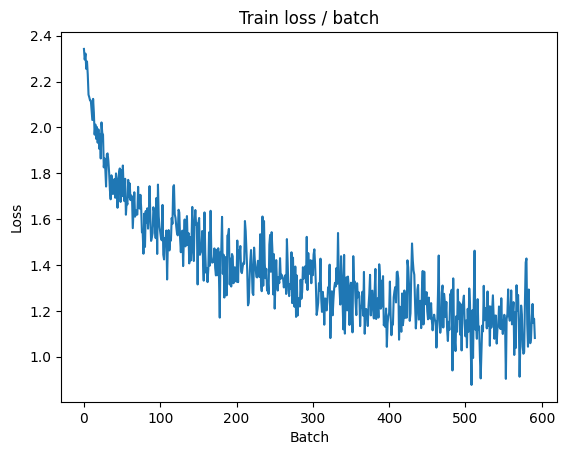


===============> Total time 15s	Avg loss 1.1319	Avg Prec@1 59.58 %	Avg Prec@5 95.72 %

[EVAL Batch 000/079]	Time 0.157s (0.157s)	Loss 1.0211 (1.0211)	Prec@1  64.8 ( 64.8)	Prec@5  93.8 ( 93.8)

===============> Total time 3s	Avg loss 1.0298	Avg Prec@1 63.19 %	Avg Prec@5 96.70 %



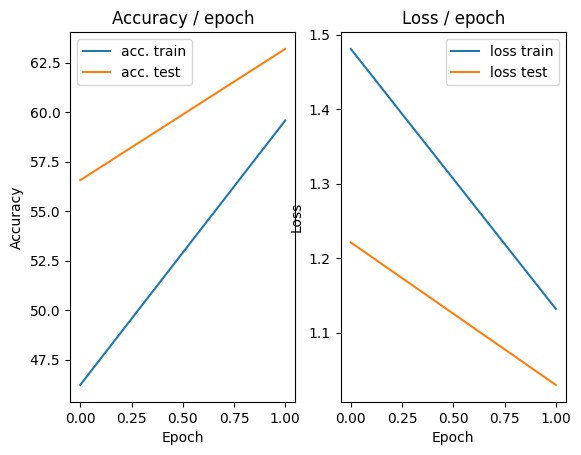

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.152s (0.152s)	Loss 0.9098 (0.9098)	Prec@1  68.8 ( 68.8)	Prec@5  99.2 ( 99.2)


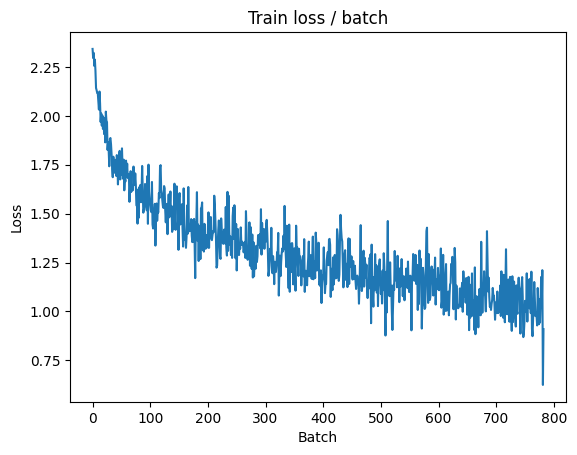

[TRAIN Batch 200/391]	Time 0.057s (0.039s)	Loss 0.9590 (1.0068)	Prec@1  62.5 ( 64.1)	Prec@5  98.4 ( 96.7)


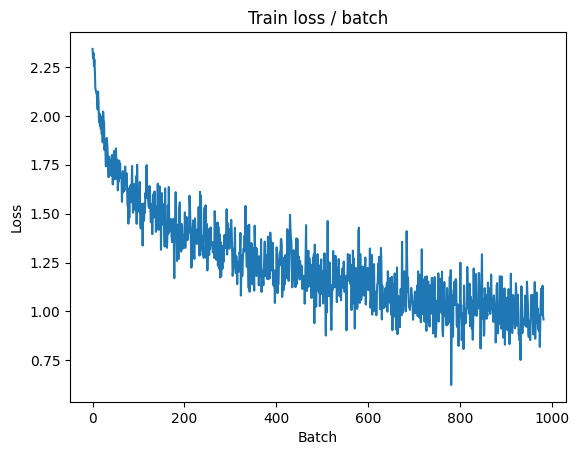


===============> Total time 16s	Avg loss 0.9863	Avg Prec@1 65.17 %	Avg Prec@5 96.81 %

[EVAL Batch 000/079]	Time 0.122s (0.122s)	Loss 0.8981 (0.8981)	Prec@1  69.5 ( 69.5)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.9110	Avg Prec@1 68.33 %	Avg Prec@5 97.36 %



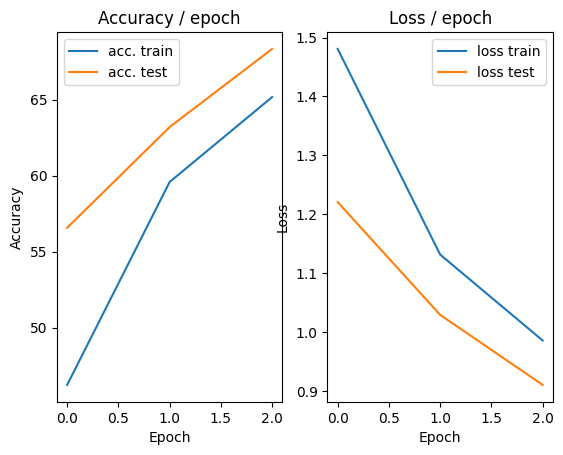

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.161s (0.161s)	Loss 0.7314 (0.7314)	Prec@1  79.7 ( 79.7)	Prec@5  97.7 ( 97.7)


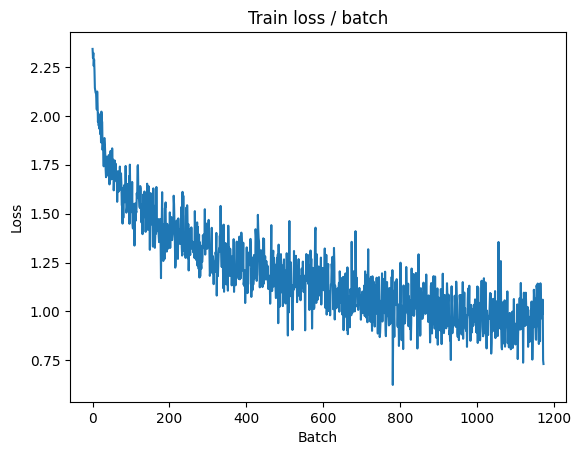

[TRAIN Batch 200/391]	Time 0.057s (0.045s)	Loss 0.9728 (0.9038)	Prec@1  65.6 ( 67.9)	Prec@5  94.5 ( 97.4)


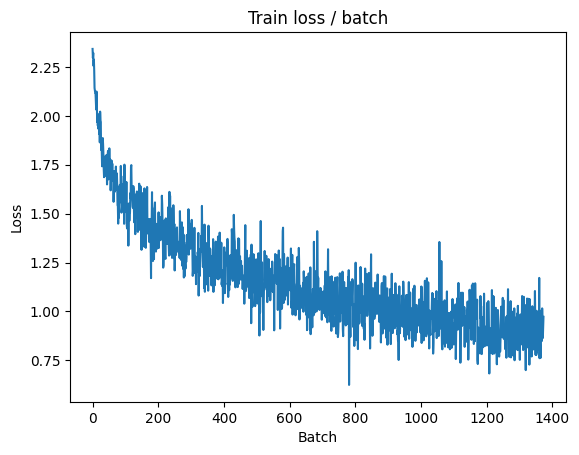


===============> Total time 16s	Avg loss 0.8865	Avg Prec@1 68.50 %	Avg Prec@5 97.47 %

[EVAL Batch 000/079]	Time 0.163s (0.163s)	Loss 0.9466 (0.9466)	Prec@1  66.4 ( 66.4)	Prec@5  96.9 ( 96.9)

===============> Total time 3s	Avg loss 0.9572	Avg Prec@1 67.00 %	Avg Prec@5 97.02 %



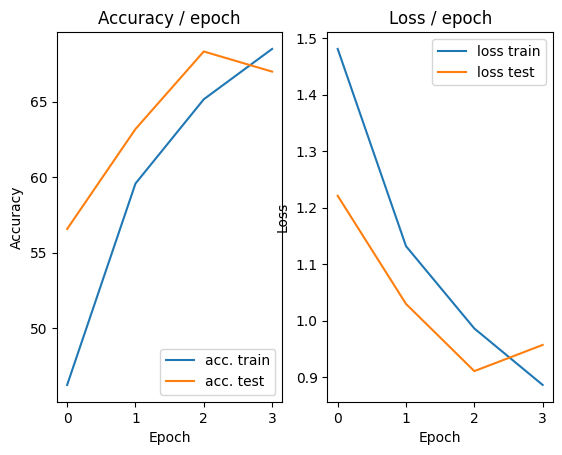

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.168s (0.168s)	Loss 0.8305 (0.8305)	Prec@1  70.3 ( 70.3)	Prec@5  99.2 ( 99.2)


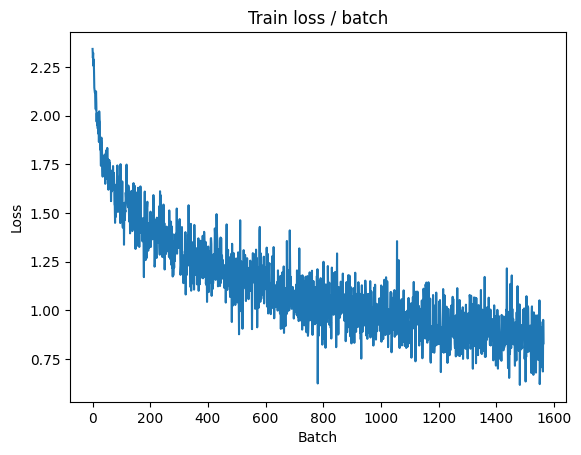

[TRAIN Batch 200/391]	Time 0.054s (0.039s)	Loss 0.7112 (0.8352)	Prec@1  78.1 ( 70.5)	Prec@5  99.2 ( 97.8)


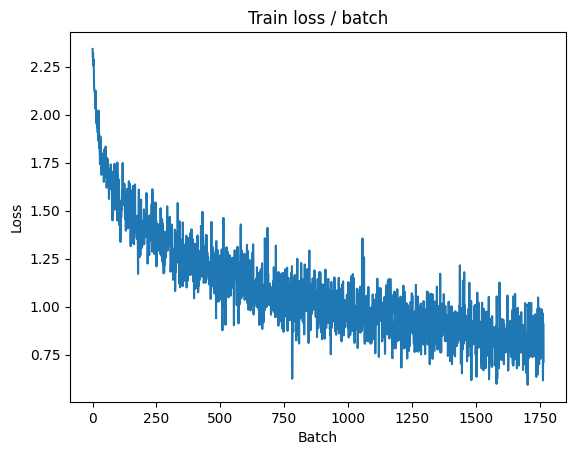


===============> Total time 16s	Avg loss 0.8237	Avg Prec@1 70.92 %	Avg Prec@5 97.80 %

[EVAL Batch 000/079]	Time 0.140s (0.140s)	Loss 0.7916 (0.7916)	Prec@1  76.6 ( 76.6)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 0.8564	Avg Prec@1 69.96 %	Avg Prec@5 97.87 %



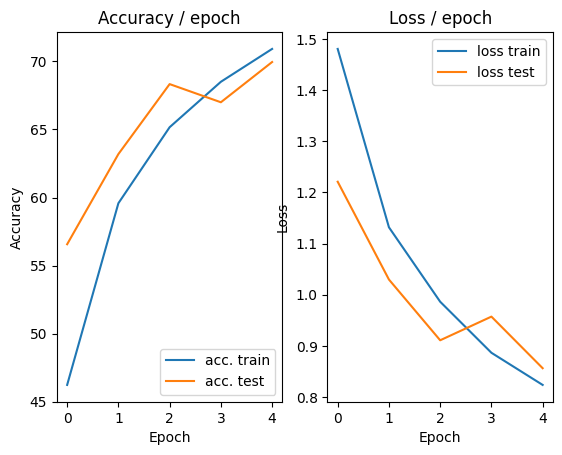

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.173s (0.173s)	Loss 0.6731 (0.6731)	Prec@1  76.6 ( 76.6)	Prec@5  99.2 ( 99.2)


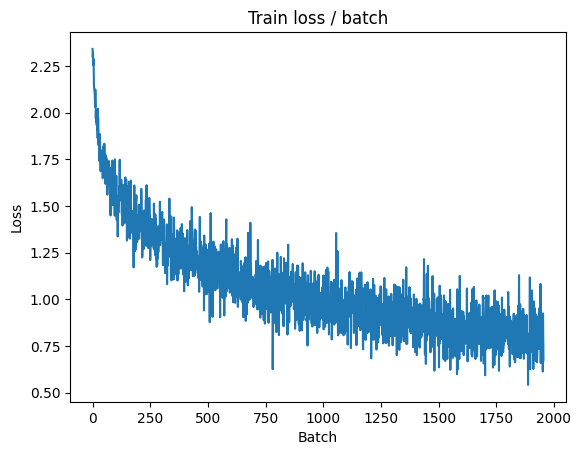

[TRAIN Batch 200/391]	Time 0.011s (0.045s)	Loss 0.8122 (0.7766)	Prec@1  74.2 ( 72.4)	Prec@5  98.4 ( 98.2)


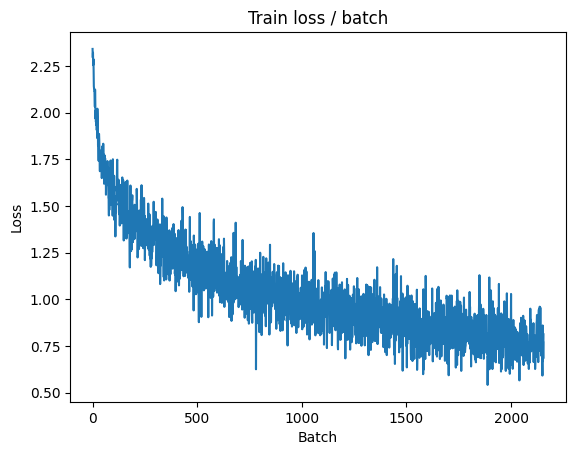


===============> Total time 16s	Avg loss 0.7710	Avg Prec@1 72.85 %	Avg Prec@5 98.15 %

[EVAL Batch 000/079]	Time 0.183s (0.183s)	Loss 0.7425 (0.7425)	Prec@1  78.1 ( 78.1)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.8124	Avg Prec@1 72.07 %	Avg Prec@5 97.74 %



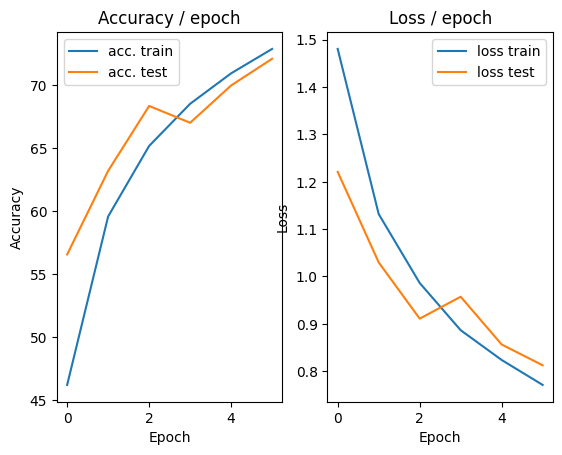

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.169s (0.169s)	Loss 0.6721 (0.6721)	Prec@1  75.8 ( 75.8)	Prec@5 100.0 (100.0)


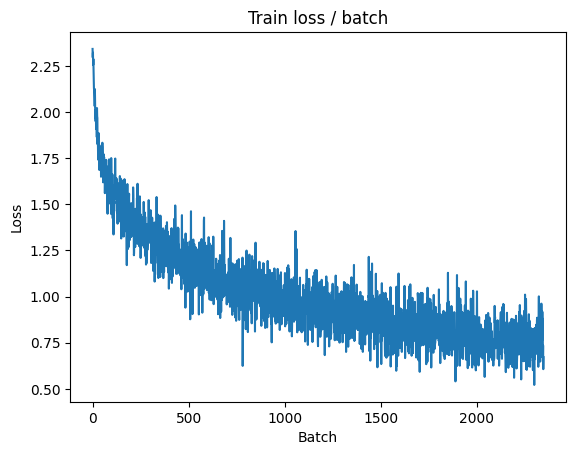

[TRAIN Batch 200/391]	Time 0.065s (0.039s)	Loss 0.8241 (0.7436)	Prec@1  69.5 ( 73.8)	Prec@5  98.4 ( 98.3)


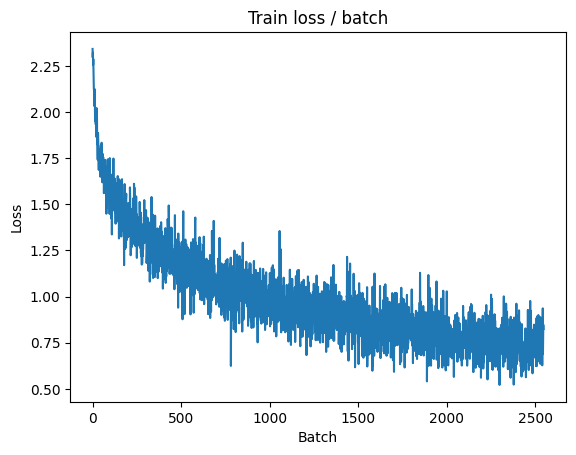


===============> Total time 16s	Avg loss 0.7292	Avg Prec@1 74.42 %	Avg Prec@5 98.36 %

[EVAL Batch 000/079]	Time 0.128s (0.128s)	Loss 0.7883 (0.7883)	Prec@1  75.8 ( 75.8)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.8233	Avg Prec@1 71.03 %	Avg Prec@5 98.08 %



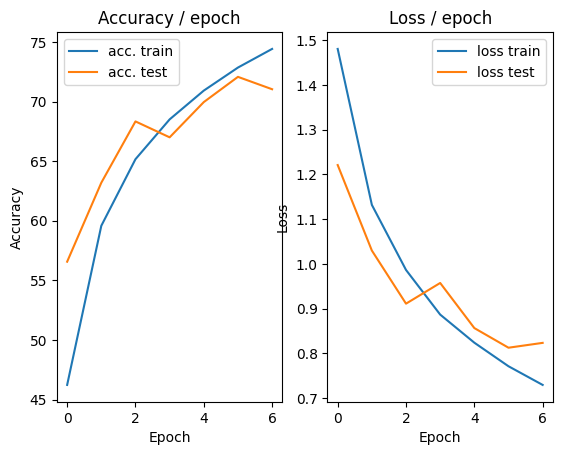

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.163s (0.163s)	Loss 0.6039 (0.6039)	Prec@1  82.0 ( 82.0)	Prec@5  98.4 ( 98.4)


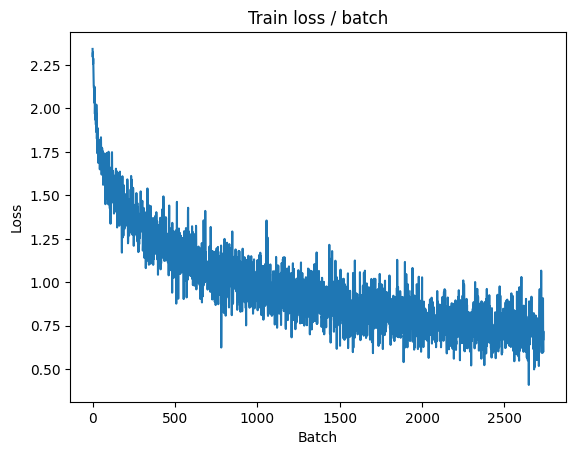

[TRAIN Batch 200/391]	Time 0.067s (0.044s)	Loss 0.7602 (0.6963)	Prec@1  74.2 ( 75.2)	Prec@5  98.4 ( 98.5)


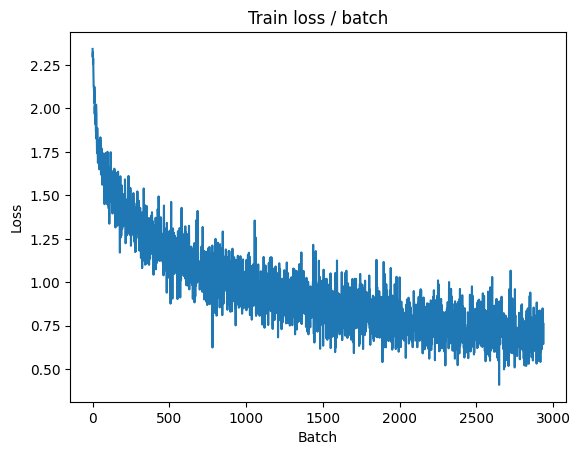


===============> Total time 16s	Avg loss 0.6967	Avg Prec@1 75.39 %	Avg Prec@5 98.50 %

[EVAL Batch 000/079]	Time 0.178s (0.178s)	Loss 0.8044 (0.8044)	Prec@1  71.9 ( 71.9)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.8141	Avg Prec@1 72.18 %	Avg Prec@5 97.91 %



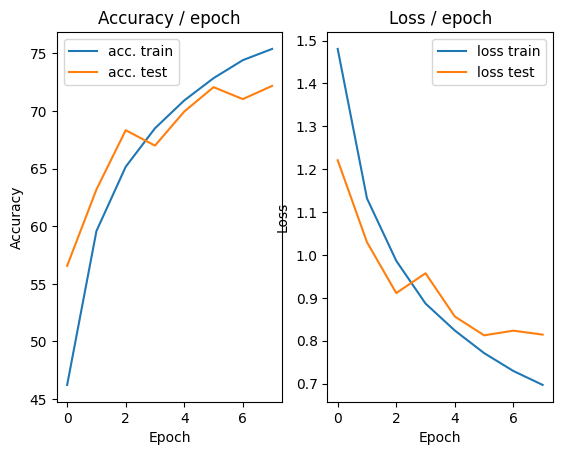

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.172s (0.172s)	Loss 0.7459 (0.7459)	Prec@1  72.7 ( 72.7)	Prec@5  96.9 ( 96.9)


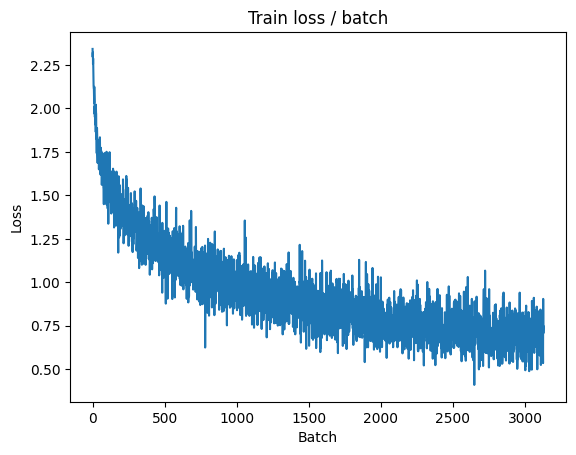

[TRAIN Batch 200/391]	Time 0.014s (0.040s)	Loss 0.6247 (0.6671)	Prec@1  80.5 ( 76.6)	Prec@5 100.0 ( 98.6)


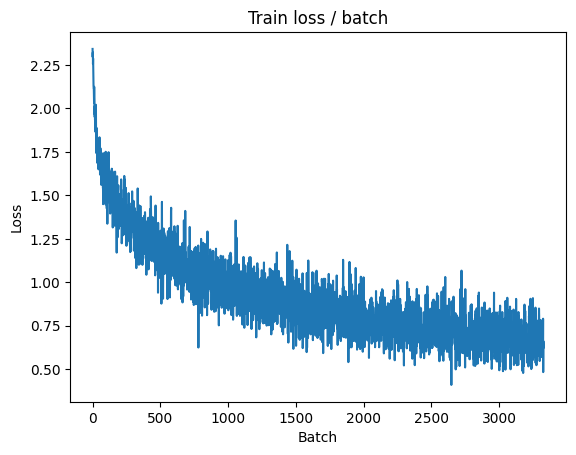


===============> Total time 16s	Avg loss 0.6635	Avg Prec@1 76.69 %	Avg Prec@5 98.61 %

[EVAL Batch 000/079]	Time 0.126s (0.126s)	Loss 0.6862 (0.6862)	Prec@1  75.8 ( 75.8)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.7760	Avg Prec@1 73.41 %	Avg Prec@5 98.04 %



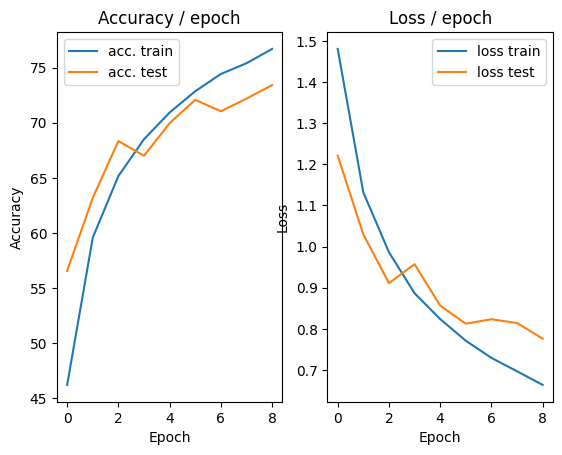

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.164s (0.164s)	Loss 0.7336 (0.7336)	Prec@1  75.0 ( 75.0)	Prec@5  98.4 ( 98.4)


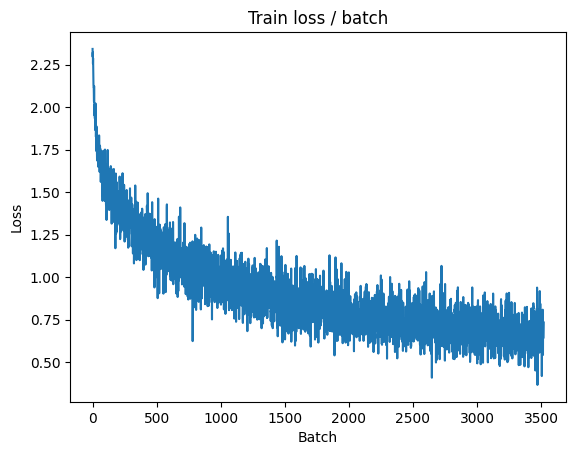

[TRAIN Batch 200/391]	Time 0.066s (0.044s)	Loss 0.6644 (0.6323)	Prec@1  74.2 ( 77.6)	Prec@5  97.7 ( 98.7)


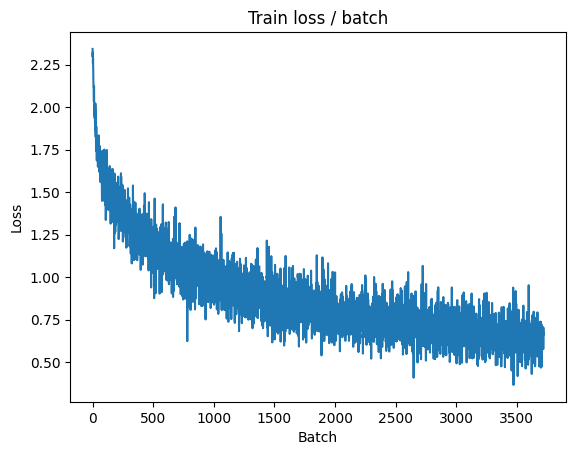


===============> Total time 16s	Avg loss 0.6338	Avg Prec@1 77.85 %	Avg Prec@5 98.70 %

[EVAL Batch 000/079]	Time 0.164s (0.164s)	Loss 0.7230 (0.7230)	Prec@1  75.8 ( 75.8)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.8087	Avg Prec@1 72.48 %	Avg Prec@5 97.85 %



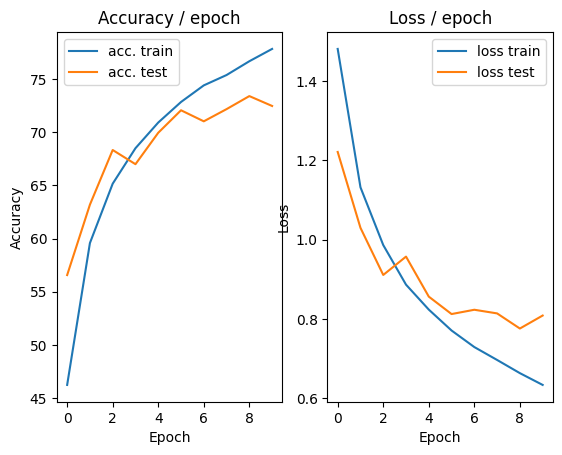

=== EPOCH 11 =====

[TRAIN Batch 000/391]	Time 0.169s (0.169s)	Loss 0.5805 (0.5805)	Prec@1  78.9 ( 78.9)	Prec@5 100.0 (100.0)


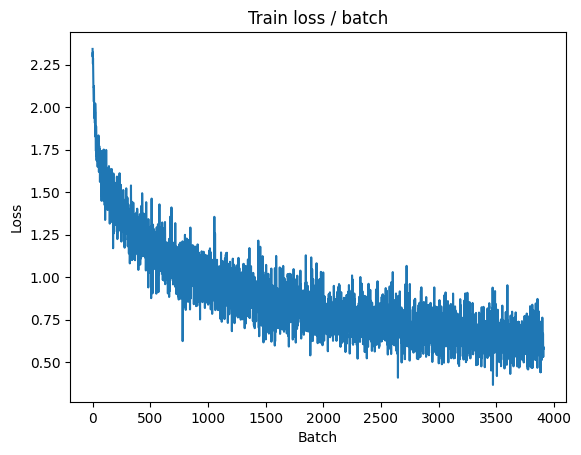

[TRAIN Batch 200/391]	Time 0.046s (0.038s)	Loss 0.8705 (0.6178)	Prec@1  68.8 ( 78.5)	Prec@5  99.2 ( 98.7)


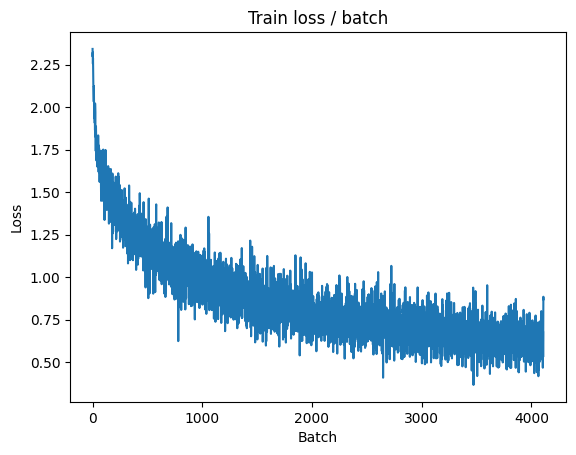


===============> Total time 15s	Avg loss 0.6157	Avg Prec@1 78.46 %	Avg Prec@5 98.82 %

[EVAL Batch 000/079]	Time 0.130s (0.130s)	Loss 0.6548 (0.6548)	Prec@1  75.0 ( 75.0)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.6992	Avg Prec@1 75.24 %	Avg Prec@5 98.75 %



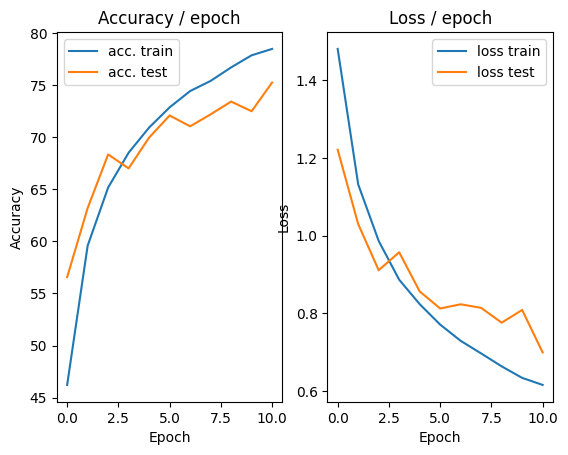

=== EPOCH 12 =====

[TRAIN Batch 000/391]	Time 0.180s (0.180s)	Loss 0.5537 (0.5537)	Prec@1  75.8 ( 75.8)	Prec@5  99.2 ( 99.2)


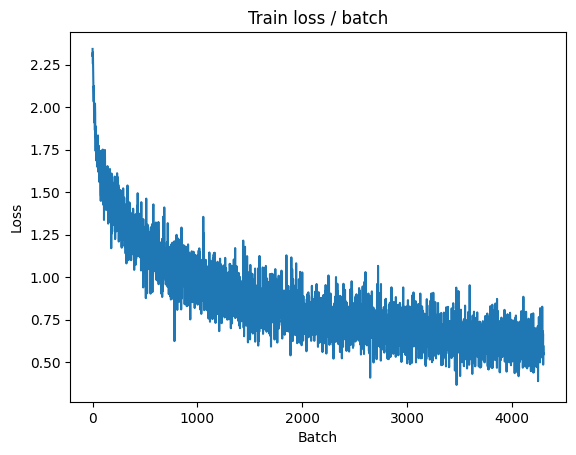

[TRAIN Batch 200/391]	Time 0.007s (0.044s)	Loss 0.6132 (0.5904)	Prec@1  77.3 ( 78.9)	Prec@5  99.2 ( 99.0)


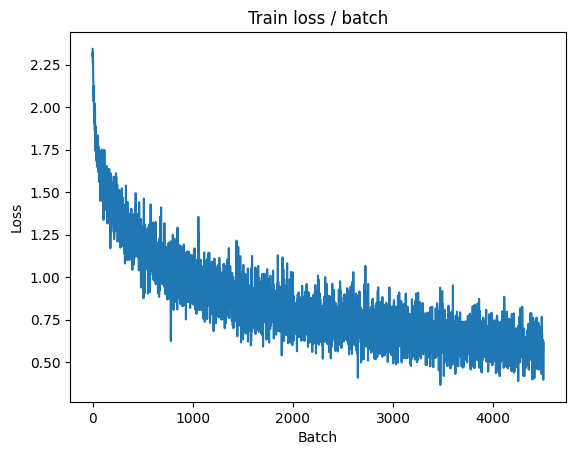


===============> Total time 16s	Avg loss 0.5930	Avg Prec@1 79.00 %	Avg Prec@5 98.87 %

[EVAL Batch 000/079]	Time 0.139s (0.139s)	Loss 0.6011 (0.6011)	Prec@1  82.8 ( 82.8)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.7170	Avg Prec@1 75.38 %	Avg Prec@5 98.49 %



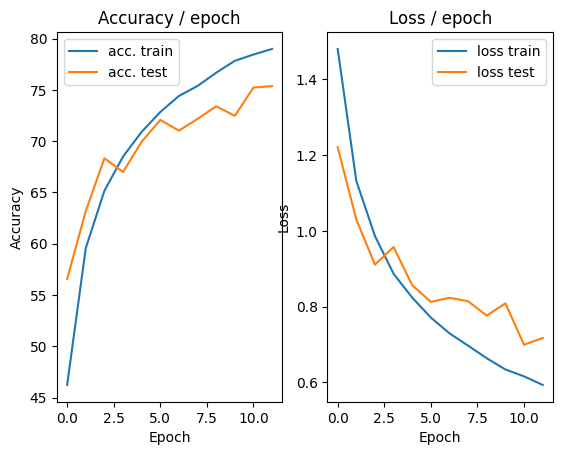

=== EPOCH 13 =====

[TRAIN Batch 000/391]	Time 0.178s (0.178s)	Loss 0.6400 (0.6400)	Prec@1  77.3 ( 77.3)	Prec@5  99.2 ( 99.2)


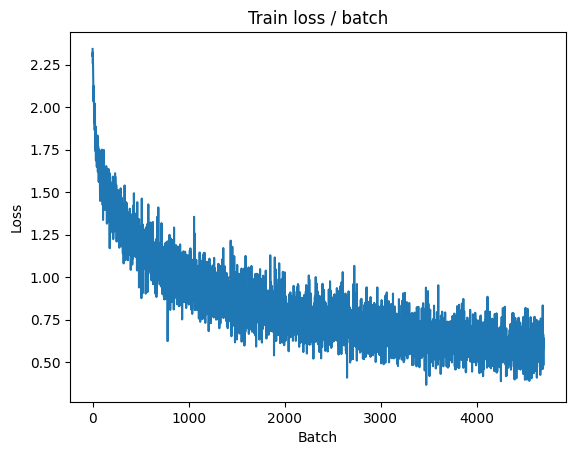

[TRAIN Batch 200/391]	Time 0.107s (0.040s)	Loss 0.4934 (0.5628)	Prec@1  78.1 ( 80.1)	Prec@5  99.2 ( 99.0)


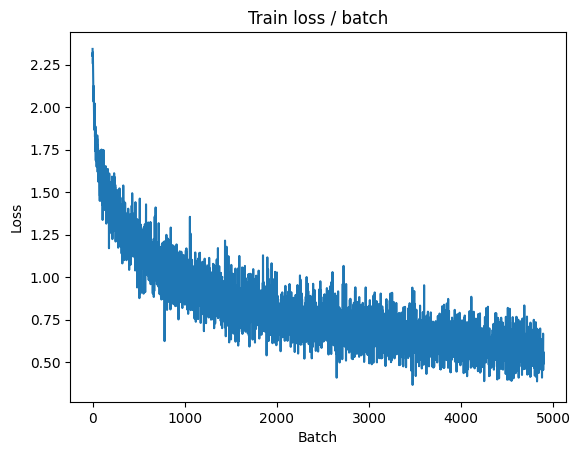


===============> Total time 16s	Avg loss 0.5704	Avg Prec@1 79.87 %	Avg Prec@5 98.99 %

[EVAL Batch 000/079]	Time 0.138s (0.138s)	Loss 0.6057 (0.6057)	Prec@1  82.8 ( 82.8)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.7155	Avg Prec@1 75.63 %	Avg Prec@5 98.54 %



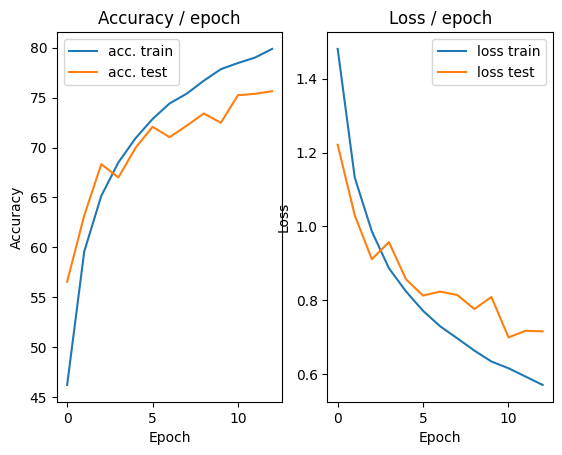

=== EPOCH 14 =====

[TRAIN Batch 000/391]	Time 0.212s (0.212s)	Loss 0.5870 (0.5870)	Prec@1  78.1 ( 78.1)	Prec@5  97.7 ( 97.7)


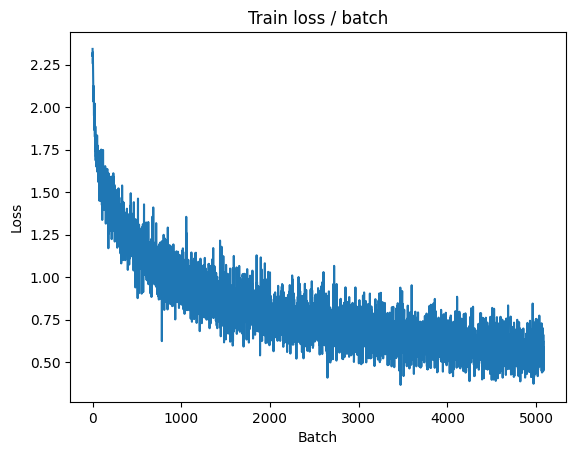

[TRAIN Batch 200/391]	Time 0.067s (0.044s)	Loss 0.6023 (0.5439)	Prec@1  76.6 ( 80.8)	Prec@5 100.0 ( 99.3)


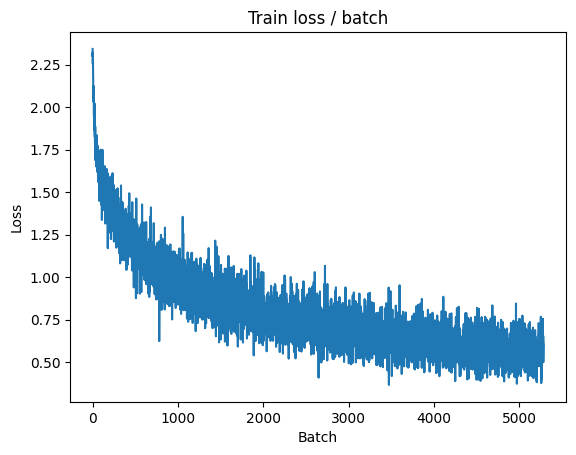


===============> Total time 17s	Avg loss 0.5544	Avg Prec@1 80.52 %	Avg Prec@5 99.15 %

[EVAL Batch 000/079]	Time 0.140s (0.140s)	Loss 0.5148 (0.5148)	Prec@1  84.4 ( 84.4)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.5914	Avg Prec@1 79.27 %	Avg Prec@5 98.97 %



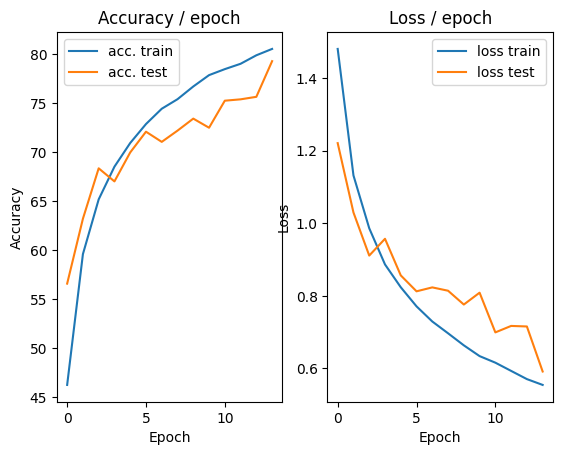

=== EPOCH 15 =====

[TRAIN Batch 000/391]	Time 0.211s (0.211s)	Loss 0.5947 (0.5947)	Prec@1  81.2 ( 81.2)	Prec@5  98.4 ( 98.4)


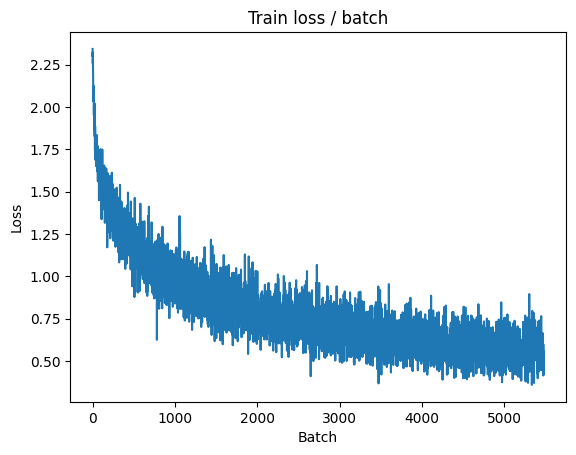

[TRAIN Batch 200/391]	Time 0.056s (0.041s)	Loss 0.4688 (0.5263)	Prec@1  82.0 ( 81.6)	Prec@5  99.2 ( 99.2)


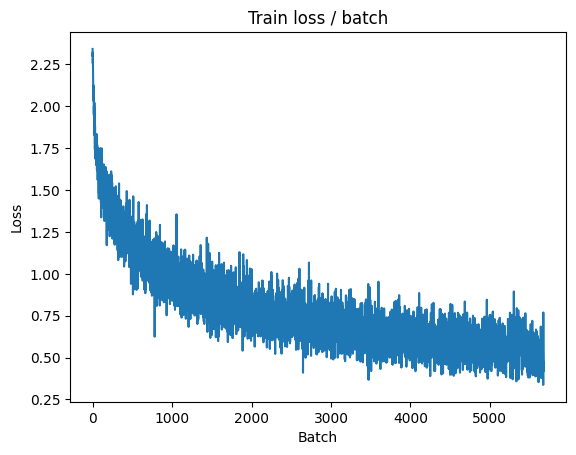


===============> Total time 16s	Avg loss 0.5359	Avg Prec@1 81.38 %	Avg Prec@5 99.11 %

[EVAL Batch 000/079]	Time 0.138s (0.138s)	Loss 0.5786 (0.5786)	Prec@1  83.6 ( 83.6)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.6593	Avg Prec@1 77.69 %	Avg Prec@5 98.67 %



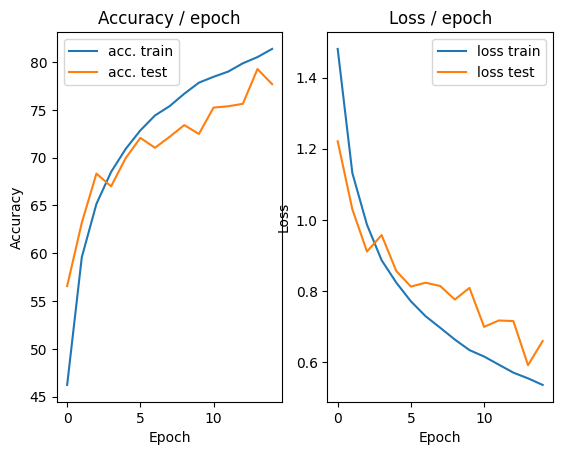

In [16]:
main(128, 0.03, cuda=True)